# Hotel Bookings Project – Full Pipeline
Pandas & Data Manipulation · Albert School × POLIMI Graduate School of Management

This notebook runs the whole project in one go, from the two raw files to the business recommendations.

| Part | Content |
|---|---|
| 1 | PMS data cleaning |
| 2 | CRM data cleaning |
| 3 | PMS & CRM data integration |
| 4 | Business analysis & recommendations |

**How to run:** put `hotel_reservations_pms.xlsx` and `hotel_bookings_crm.csv` in a folder called `data/` next to this notebook, then *Run all*. If the folder is not there, the raw files are read directly from the course repository. Each part saves its result as a CSV that the next part reads.

In [1]:
# Setup: libraries and location of the raw files
import os
import warnings
warnings.filterwarnings("ignore")   # hide library notices about future versions (they do not affect results)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

REPO = "https://raw.githubusercontent.com/Ma7i5ab3/DataManipulation-AlbertSchool/rasd/Project/data/"

def raw_file(name):
    local = os.path.join("data", name)
    return local if os.path.exists(local) else REPO + name

PMS_FILE = raw_file("hotel_reservations_pms.xlsx")
CRM_FILE = raw_file("hotel_bookings_crm.csv")
print("PMS:", PMS_FILE)
print("CRM:", CRM_FILE)

PMS: data/hotel_reservations_pms.xlsx
CRM: data/hotel_bookings_crm.csv


---
# PART 1 – PMS DATA CLEANING

# Hotel Bookings Project - Pandas & Data Manipulation
Albert School × POLIMI Graduate School of Management

PMS — Property Management System



# Project Objective

The objective of this project is to integrate hotel booking
data from two different systems (PMS and CRM), assess data
quality, develop a reproducible cleaning pipeline and
extract meaningful business insights.

This notebook focuses on the initial exploration and data
quality assessment of the PMS dataset, preparing it for
integration with the CRM dataset.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Data Loading

The PMS dataset is provided as an Excel file.
The following section loads the original data
without modifying its content.

In [3]:
# Identify the available Excel sheets

file_path = PMS_FILE
excel_file = pd.ExcelFile(file_path)
excel_file.sheet_names

['info', 'bookings']

In [4]:
# Load dataset documentation
pms_info = pd.read_excel(file_path, sheet_name="info")

# Load the original PMS booking records
pms = pd.read_excel(file_path, sheet_name="bookings")

In [5]:
# Check dataset dimensions

print("Number of rows:", pms.shape[0])
print("Number of columns:", pms.shape[1])

Number of rows: 24480
Number of columns: 20


In [6]:
# Display dataset documentation
display(pms_info)

# Display the first five records
pms.head()

,field,description
0,Source,Two hotels in Portugal (a resort hotel and a c...
1,System,Property Management System (PMS)
2,Export,Reservations export
3,Period,Arrivals from July 2015 to August 2017
4,Rows,"24,480"
5,Data sheet,bookings
6,NaN,NaN
7,Column,Meaning
8,booking_id,Booking identifier
9,hotel,Which hotel


,booking_id,hotel,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,reserved_room_type,assigned_room_type,booking_changes,deposit_type,adr,required_car_parking_spaces,total_of_special_requests,is_canceled,record_updated_at
0,BK313694,Resort Hotel,2016,August,27,1,1,2,0.0,0,BB,A,A,0,No Deposit,122.89,0,0,0,2016-08-28 13:15:00
1,BK313724,Resort Hotel,2015,October,12,1,3,2,0.0,0,FB,A,A,0,Non Refund,109,0,0,0,2015-10-15 23:33:00
2,BK303790,City Hotel,2015,September,18,0,2,2,0.0,0,HB,A,A,0,Non Refund,101.5,0,0,1,2015-07-06 00:43:00
3,BK304010,Resort Hotel,2016,March,18,0,2,2,0.0,0,HB,A,A,0,No Deposit,55,0,0,0,2016-03-18 00:35:00
4,BK324852,City Hotel,2016,December,1,0,3,1,0.0,0,BB,A,A,0,Non Refund,75,0,0,1,2015-10-17 21:21:00


## 3. Initial Data Exploration

The purpose of this section is to understand the structure,
variables, data types and distributions of the PMS dataset.

This preliminary exploration provides the foundation for
the subsequent data quality assessment and integration
with the CRM dataset.

In [7]:
# Display all column names
pms.columns.tolist()

['booking_id',
 'hotel',
 'arrival_date_year',
 'arrival_date_month',
 'arrival_date_day_of_month',
 'stays_in_weekend_nights',
 'stays_in_week_nights',
 'adults',
 'children',
 'babies',
 'meal',
 'reserved_room_type',
 'assigned_room_type',
 'booking_changes',
 'deposit_type',
 'adr',
 'required_car_parking_spaces',
 'total_of_special_requests',
 'is_canceled',
 'record_updated_at']

### 3.1 Dataset Structure and Data Types

Understanding data types is essential to identify potential
formatting issues and ensure that each variable is suitable
for subsequent analysis.

In [8]:
# Display dataset structure and data types
pms.info()

<class 'pandas.DataFrame'>
RangeIndex: 24480 entries, 0 to 24479
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   booking_id                   24480 non-null  str           
 1   hotel                        24480 non-null  str           
 2   arrival_date_year            24480 non-null  int64         
 3   arrival_date_month           24480 non-null  str           
 4   arrival_date_day_of_month    24480 non-null  int64         
 5   stays_in_weekend_nights      24480 non-null  int64         
 6   stays_in_week_nights         24480 non-null  int64         
 7   adults                       24480 non-null  int64         
 8   children                     23665 non-null  float64       
 9   babies                       24480 non-null  int64         
 10  meal                         23990 non-null  str           
 11  reserved_room_type           24480 non-null  str    

### 3.2 Descriptive Statistics

Descriptive statistics are used to understand the central
tendency, variability and range of numerical variables,
as well as to identify potential anomalies.

In [9]:
# Generate descriptive statistics for numerical variables
pms.describe().T

,count,mean,min,25%,50%,75%,max,std
arrival_date_year,24480.0,2016.157925,2015.0,2016.0,2016.0,2017.0,2017.0,0.703282
arrival_date_day_of_month,24480.0,15.890768,1.0,8.0,16.0,24.0,31.0,8.77505
stays_in_weekend_nights,24480.0,0.926716,0.0,0.0,1.0,2.0,13.0,0.979518
stays_in_week_nights,24480.0,2.478268,-1.0,1.0,2.0,3.0,32.0,1.843087
adults,24480.0,1.889175,0.0,2.0,2.0,2.0,55.0,1.281147
children,23665.0,0.10019,0.0,0.0,0.0,0.0,3.0,0.390225
babies,24480.0,0.008088,0.0,0.0,0.0,0.0,2.0,0.09048
booking_changes,24480.0,0.21875,0.0,0.0,0.0,0.0,18.0,0.641753
required_car_parking_spaces,24480.0,0.061724,0.0,0.0,0.0,0.0,2.0,0.240997
total_of_special_requests,24480.0,0.57357,0.0,0.0,0.0,1.0,5.0,0.796903


### 3.3 Categorical Variables

Categorical variables are examined to understand their
distribution and identify potential inconsistencies in
labels and classifications.

In [10]:
# Generate descriptive statistics for categorical variables
pms.describe(include="object").T

,count,unique,top,freq
booking_id,24480,24250,BK304422,2
hotel,24480,10,City Hotel,15295
arrival_date_month,24480,47,August,2555
meal,23990,5,BB,18587
reserved_room_type,24480,10,A,17528
assigned_room_type,24480,11,A,15072
deposit_type,24480,5,No Deposit,20841
adr,24480,4158,62,768
is_canceled,24480,4,0,14579


### 3.4 Cardinality Analysis

The number of distinct values in each column is examined
to understand the characteristics of the variables and
identify potential identifiers and categorical attributes.

In [11]:
# Count distinct values in each column
pms.nunique()

booking_id                     24250
hotel                             10
arrival_date_year                  3
arrival_date_month                47
arrival_date_day_of_month         31
stays_in_weekend_nights           12
stays_in_week_nights              24
adults                            10
children                           4
babies                             3
meal                               5
reserved_room_type                10
assigned_room_type                11
booking_changes                   14
deposit_type                       5
adr                             4158
required_car_parking_spaces        3
total_of_special_requests          6
is_canceled                        4
record_updated_at              23781
dtype: int64

### 3.5 Preliminary Dataset Overview

A summary table is created to consolidate the main
structural characteristics of each variable.

In [12]:
# Create a preliminary overview of all variables

pms_overview = pd.DataFrame({
    "Data Type": pms.dtypes,
    "Non-Null Values": pms.count(),
    "Unique Values": pms.nunique()
})

display(pms_overview)

,Data Type,Non-Null Values,Unique Values
booking_id,str,24480,24250
hotel,str,24480,10
arrival_date_year,int64,24480,3
arrival_date_month,str,24480,47
arrival_date_day_of_month,int64,24480,31
stays_in_weekend_nights,int64,24480,12
stays_in_week_nights,int64,24480,24
adults,int64,24480,10
children,float64,23665,4
babies,int64,24480,3


## 4. Data Quality Assessment

This section evaluates the quality of the original PMS
dataset across five dimensions:

- Completeness
- Uniqueness
- Validity
- Consistency
- Data types and formats

The objective is to identify and quantify data quality
issues before applying any cleaning operations.

In [13]:
# Preserve the original dataset for future comparison
pms_raw = pms.copy()

print("Original number of rows:", len(pms_raw))

Original number of rows: 24480


### 4.1 Completeness — Missing Values

Missing values are identified and quantified to evaluate
the completeness of each variable.

Both absolute counts and percentages are calculated to
assess the severity of missing data.

In [14]:
# Calculate missing values and percentages

missing_values = pd.DataFrame({
    "Missing Values": pms.isna().sum(),
    "Missing Percentage (%)": pms.isna().mean() * 100
})
missing_values = missing_values.sort_values(
    by="Missing Percentage (%)",
    ascending=False
).round(2)

display(missing_values)

,Missing Values,Missing Percentage (%)
children,815,3.33
meal,490,2.00
booking_id,0,0.00
hotel,0,0.00
arrival_date_month,0,0.00
arrival_date_year,0,0.00
arrival_date_day_of_month,0,0.00
stays_in_weekend_nights,0,0.00
adults,0,0.00
stays_in_week_nights,0,0.00


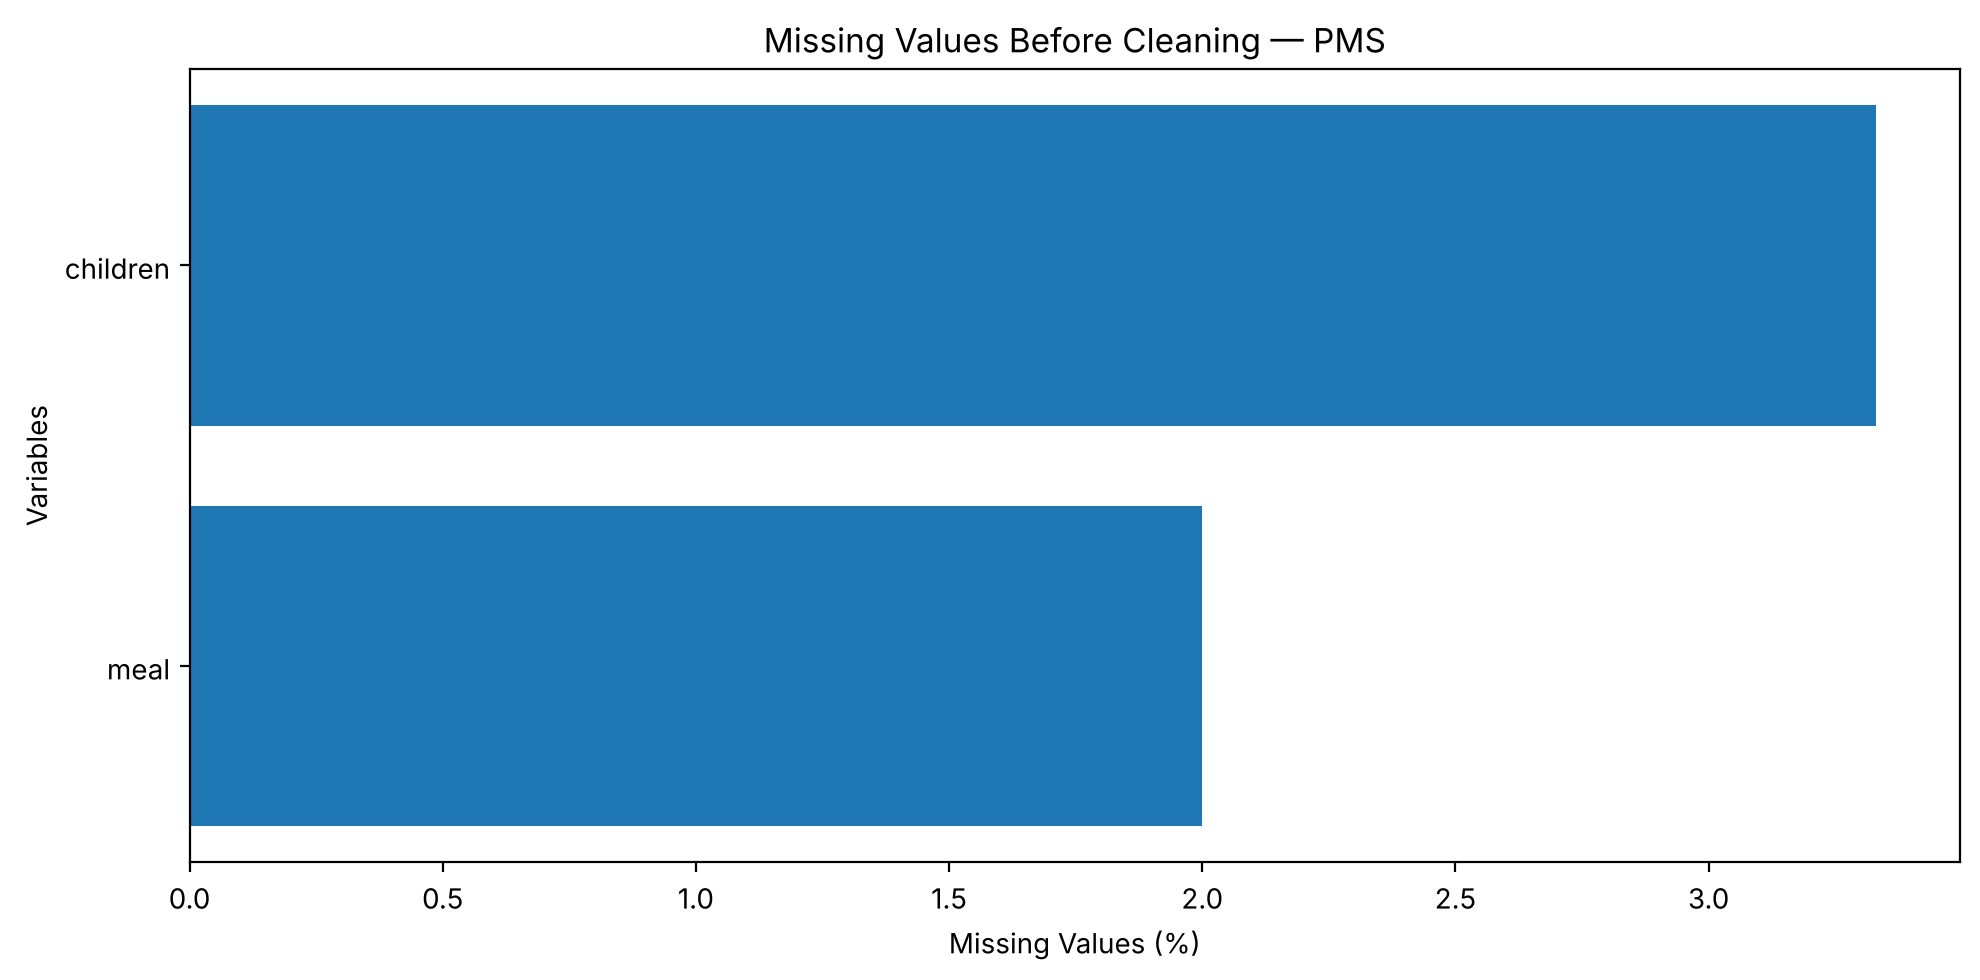

In [15]:
# Select columns containing missing values
missing_columns = missing_values[
    missing_values["Missing Values"] > 0
]

# Visualize missing data
if not missing_columns.empty:

    plt.figure(figsize=(10, 5))

    plt.barh(
        missing_columns.index,
        missing_columns["Missing Percentage (%)"]
    )

    plt.title("Missing Values Before Cleaning — PMS")
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Variables")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

else:
    print("No missing values detected.")

#### Key Findings

- The `children` column contains 815 missing values (3.33%).
- The `meal` column contains 490 missing values (2.00%).
- A total of 1,305 missing cells were identified across
  these two variables.
- No missing values were detected in `booking_id`,
  supporting its potential use as a merge key.

Missing values should not be automatically replaced
or removed, as this could introduce bias or information loss.

Potential recovery from the CRM dataset will be evaluated
before implementing the final missing value treatment.

### 4.2 Uniqueness — Duplicate Records

Duplicate records are investigated at two levels:

- Completely identical records.
- Repeated booking identifiers.

This distinction is essential to prevent data loss and
ensure a reliable integration with the CRM dataset.

In [16]:
# Identify completely identical records

exact_duplicates = pms.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)

print(
    "Exact duplicate percentage:",
    round(exact_duplicates / len(pms) * 100, 2),
    "%"
)

Exact duplicate rows: 150
Exact duplicate percentage: 0.61 %


In [17]:
# Assess booking identifier uniqueness

valid_ids = pms["booking_id"].dropna()

duplicate_ids = valid_ids.duplicated().sum()

print("Total records:", len(pms))
print("Missing booking IDs:", pms["booking_id"].isna().sum())
print("Unique booking IDs:", valid_ids.nunique())
print("Repeated booking IDs:", duplicate_ids)

Total records: 24480
Missing booking IDs: 0
Unique booking IDs: 24250
Repeated booking IDs: 230


In [18]:
# Inspect records sharing the same booking ID

duplicate_bookings = pms[
    pms["booking_id"].notna() &
    pms["booking_id"].duplicated(keep=False)
]

duplicate_bookings.sort_values("booking_id").head(20)

,booking_id,hotel,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,reserved_room_type,assigned_room_type,booking_changes,deposit_type,adr,required_car_parking_spaces,total_of_special_requests,is_canceled,record_updated_at
21344,BK300024,City Hotel,2016,September,7,0,3,2,0.0,0,BB,A,A,0,No Deposit,129.6,0,1,0,2016-08-19 15:33:00
21936,BK300024,City Hotel,2016,September,7,0,3,2,0.0,0,BB,A,A,0,No Deposit,129.6,0,1,0,2016-08-19 15:33:00
14617,BK300145,City Hotel,2016,September,13,0,5,1,0.0,0,BB,A,A,1,No Deposit,93.62,0,0,0,2016-08-14 05:03:00
16909,BK300145,City Hotel,2016,September,13,0,5,1,0.0,0,BB,A,A,2,No Deposit,108,0,0,0,2016-09-03 05:03:00
7174,BK300170,City Hotel,2016,June,26,2,0,2,0.0,0,SC,A,A,0,No Deposit,89.1,0,1,no,2016-06-24 14:21:00
22162,BK300170,City Hotel,2016,June,26,2,0,2,0.0,0,SC,A,A,0,No Deposit,89.1,0,1,no,2016-06-24 14:21:00
16025,BK300249,City Hotel,2016,June,9,0,1,2,0.0,0,BB,A,A,0,No Deposit,120,0,0,1,2016-05-30 08:03:00
769,BK300249,City Hotel,2016,June,9,0,1,2,0.0,0,BB,A,A,0,No Deposit,100.5,0,0,1,2016-05-18 08:03:00
8029,BK300598,City Hotel,2017,May,4,0,3,2,0.0,0,SC,A,A,0,No Deposit,108,0,1,0,2017-04-06 19:14:00
17307,BK300598,City Hotel,2017,May,4,0,3,2,0.0,0,SC,A,A,0,No Deposit,108,0,1,0,2017-04-06 19:14:00


### 4.3 Data Types and Formatting Issues

Data types are inspected to identify variables stored
in inappropriate formats.

Incorrect data types may affect calculations,
aggregations and integration with the CRM dataset.

In [19]:
# Identify columns stored as text

object_columns = pms.select_dtypes(
    include=["object", "string"]
).columns

for column in object_columns:
    print(f"\nColumn: {column}")
    print(pms[column].value_counts(dropna=False).head(10))


Column: booking_id
booking_id
BK304422    2
BK301271    2
BK306301    2
BK316071    2
BK324233    2
BK312328    2
BK308802    2
BK318199    2
BK318578    2
BK317465    2
Name: count, dtype: int64

Column: hotel
hotel
City Hotel       15295
Resort Hotel      7718
city hotel         261
City hotel         244
CITY HOTEL         243
 City Hotel        242
resort hotel       134
 RESORT HOTEL      119
Resort Hotel       115
Resort hotel       109
Name: count, dtype: int64

Column: arrival_date_month
arrival_date_month
August       2555
May          2243
July         2230
October      2036
April        1994
June         1961
September    1915
March        1766
February     1468
December     1194
Name: count, dtype: int64

Column: meal
meal
BB           18587
HB            2882
SC            2117
NaN            490
Undefined      238
FB             166
Name: count, dtype: int64

Column: reserved_room_type
reserved_room_type
A    17528
D     4028
E     1370
F      575
G      429
B      256
C

### 4.4 Validity — Numerical Variables

Numerical variables are inspected to identify potentially
invalid values, unusual ranges and negative observations.

Potential anomalies are flagged for further investigation
rather than automatically removed.

In [20]:
# Select numerical variables

numeric_columns = pms.select_dtypes(
    include="number"
).columns

# Create a numerical validity report

numeric_quality = pd.DataFrame({
    "Minimum": pms[numeric_columns].min(),
    "Maximum": pms[numeric_columns].max(),
    "Negative Values": (pms[numeric_columns] < 0).sum(),
    "Zero Values": (pms[numeric_columns] == 0).sum()
})

display(numeric_quality)

,Minimum,Maximum,Negative Values,Zero Values
arrival_date_year,2015.0,2017.0,0,0
arrival_date_day_of_month,1.0,31.0,0,0
stays_in_weekend_nights,0.0,13.0,0,10625
stays_in_week_nights,-1.0,32.0,35,1557
adults,0.0,55.0,0,76
children,0.0,3.0,0,22016
babies,0.0,2.0,0,24284
booking_changes,0.0,18.0,0,20783
required_car_parking_spaces,0.0,2.0,0,22971
total_of_special_requests,0.0,5.0,0,14430


### 4.5 Consistency — Categorical Variables

Categorical values are examined to identify inconsistent
labels, capitalization differences and unnecessary spaces.

In [21]:
# Inspect text columns with a limited number of categories

for column in object_columns:

    if pms[column].nunique() <= 30:

        print(f"\nColumn: {column}")
        print(pms[column].value_counts(dropna=False))


Column: hotel
hotel
City Hotel       15295
Resort Hotel      7718
city hotel         261
City hotel         244
CITY HOTEL         243
 City Hotel        242
resort hotel       134
 RESORT HOTEL      119
Resort Hotel       115
Resort hotel       109
Name: count, dtype: int64

Column: meal
meal
BB           18587
HB            2882
SC            2117
NaN            490
Undefined      238
FB             166
Name: count, dtype: int64

Column: reserved_room_type
reserved_room_type
A    17528
D     4028
E     1370
F      575
G      429
B      256
C      180
H      112
L        1
P        1
Name: count, dtype: int64

Column: assigned_room_type
assigned_room_type
A    15072
D     5251
E     1649
F      757
G      522
B      487
C      486
H      131
I       73
K       51
P        1
Name: count, dtype: int64

Column: deposit_type
deposit_type
No Deposit     20841
Non Refund      2872
No Deposit       656
Non Refund        78
Refundable        33
Name: count, dtype: int64

Column: is_canceled


### 4.6 Preliminary Data Quality Summary

A preliminary quality report consolidates the main
issues identified in the original PMS dataset.

This report establishes a baseline for the subsequent
cleaning process and before-and-after comparison.

In [22]:
# Create a preliminary data quality report

pms_quality_before = pd.DataFrame({
    "Quality Metric": [
        "Total Records",
        "Total Variables",
        "Missing Cells",
        "Missing Cells (%)",
        "Exact Duplicate Rows",
        "Repeated Booking IDs",
        "Missing Booking IDs"
    ],

    "Before Cleaning": [
        len(pms),
        pms.shape[1],
        pms.isna().sum().sum(),
        round(pms.isna().sum().sum() / pms.size * 100, 2),
        exact_duplicates,
        duplicate_ids,
        pms["booking_id"].isna().sum()
    ]
})

display(pms_quality_before)

,Quality Metric,Before Cleaning
0,Total Records,24480.00
1,Total Variables,20.00
2,Missing Cells,1305.00
3,Missing Cells (%),0.27
4,Exact Duplicate Rows,150.00
5,Repeated Booking IDs,230.00
6,Missing Booking IDs,0.00


#### Key Findings

The initial data quality assessment identified:

- 24,480 records and 20 variables.
- 1,305 missing cells, representing 0.27% of all cells.
- 150 exact duplicate rows.
- 230 repeated booking ID occurrences beyond the first occurrence.
- No missing booking identifiers.

The difference between exact duplicates and repeated booking
IDs indicates that some records share the same identifier
but contain different information.

These records require further investigation before integration
with the CRM dataset to prevent information loss.

## 5. Data Preparation and Cleaning

The objective of this section is to address the data quality
issues identified during the preliminary assessment while
preserving valuable information.

### 5.1 Cleaning Strategy

The following principles guide the cleaning process:

- Preserve the original dataset for comparison.
- Avoid unnecessary data loss.
- Standardize inconsistent formats and categories.
- Investigate invalid and anomalous values.
- Preserve booking identifiers for CRM integration.
- Document every transformation and its justification.
- Defer uncertain corrections until the PMS and CRM
  datasets have been compared.

In [23]:
# Create a working copy for data preparation

pms_clean = pms_raw.copy()

print("Rows before cleaning:", len(pms_clean))
print("Columns before cleaning:", pms_clean.shape[1])

Rows before cleaning: 24480
Columns before cleaning: 20


### 5.2 Duplicate Records Treatment

#### 5.2.1 Exact Duplicate Removal

Completely identical records are removed because they
contain redundant information.

One occurrence of each unique record is preserved.
The number of records before and after this operation
is documented to ensure transparency.

In [24]:
# Remove completely identical records

rows_before = len(pms_clean)

pms_clean = pms_clean.drop_duplicates().copy()

rows_after = len(pms_clean)

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("Rows removed:", rows_before - rows_after)
print("Remaining exact duplicates:", pms_clean.duplicated().sum())

Rows before: 24480
Rows after: 24330
Rows removed: 150


Remaining exact duplicates: 0


#### 5.2.2 Conflicting Booking Identifiers

After removing exact duplicates, repeated booking identifiers
are investigated to identify records containing conflicting
information.

These records are preserved until an appropriate resolution
strategy can be established.

In [25]:
# Identify remaining repeated booking identifiers

remaining_duplicate_ids = pms_clean["booking_id"].duplicated().sum()

conflicting_bookings = pms_clean[
    pms_clean["booking_id"].duplicated(keep=False)
].sort_values("booking_id")

print("Remaining repeated ID occurrences:", remaining_duplicate_ids)

print("Number of distinct conflicting IDs:",
      conflicting_bookings["booking_id"].nunique())

print("Total records involved:", len(conflicting_bookings))

display(conflicting_bookings.head(20))

Remaining repeated ID occurrences: 80
Number of distinct conflicting IDs: 80
Total records involved: 160


,booking_id,hotel,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,reserved_room_type,assigned_room_type,booking_changes,deposit_type,adr,required_car_parking_spaces,total_of_special_requests,is_canceled,record_updated_at
14617,BK300145,City Hotel,2016,September,13,0,5,1,0.0,0,BB,A,A,1,No Deposit,93.62,0,0,0,2016-08-14 05:03:00
16909,BK300145,City Hotel,2016,September,13,0,5,1,0.0,0,BB,A,A,2,No Deposit,108,0,0,0,2016-09-03 05:03:00
16025,BK300249,City Hotel,2016,June,9,0,1,2,0.0,0,BB,A,A,0,No Deposit,120,0,0,1,2016-05-30 08:03:00
769,BK300249,City Hotel,2016,June,9,0,1,2,0.0,0,BB,A,A,0,No Deposit,100.5,0,0,1,2016-05-18 08:03:00
2444,BK300626,CITY HOTEL,2016,September,27,0,1,1,0.0,0,BB,D,D,0,No Deposit,110,0,1,0,2016-09-27 16:49:00
3949,BK300626,City Hotel,2016,September,27,0,1,1,0.0,0,BB,D,D,0,No Deposit,97.51,0,1,0,2016-08-29 16:49:00
16807,BK300718,City Hotel,2016,September,14,0,2,2,0.0,0,BB,D,D,0,No Deposit,124.04,0,1,0,2016-09-15 00:56:00
14580,BK300718,City Hotel,2016,September,14,0,2,2,0.0,0,BB,D,D,0,No Deposit,94.49,0,1,0,2016-09-07 00:56:00
2576,BK300763,City Hotel,2016,May,28,2,4,2,0.0,0,BB,A,A,0,No Deposit,61.79,0,1,0,2016-04-10 07:47:00
13188,BK300763,City Hotel,2016,May,28,2,4,2,0.0,0,BB,A,A,0,No Deposit,75.44,0,1,0,2016-04-17 07:47:00


In [26]:
# Identify variables with conflicting values for the same booking ID

conflict_check = conflicting_bookings.groupby(
    "booking_id"
).nunique(dropna=False)

conflict_summary = (conflict_check > 1).sum()

conflict_summary = conflict_summary[
    conflict_summary > 0
].sort_values(ascending=False)

display(conflict_summary.to_frame("Booking IDs with conflicts"))

,Booking IDs with conflicts
record_updated_at,80
adr,80
booking_changes,12
arrival_date_month,9
hotel,2
deposit_type,2
meal,2
is_canceled,2
children,1


#### 5.2.4 Timestamp Investigation

The conflict analysis reveals that all 80 booking IDs
with conflicting records have different update timestamps.

This suggests that repeated identifiers may represent
different versions of the same booking.

The `record_updated_at` variable is therefore investigated
as a potential criterion for identifying the most recent
booking record.

In [27]:
# Inspect update timestamps for conflicting bookings

print("Original data type:",
      pms_clean["record_updated_at"].dtype)

display(
    conflicting_bookings[
        ["booking_id", "record_updated_at",
         "adr", "booking_changes"]
    ].head(20)
)

Original data type: datetime64[us]


,booking_id,record_updated_at,adr,booking_changes
14617,BK300145,2016-08-14 05:03:00,93.62,1
16909,BK300145,2016-09-03 05:03:00,108,2
16025,BK300249,2016-05-30 08:03:00,120,0
769,BK300249,2016-05-18 08:03:00,100.5,0
2444,BK300626,2016-09-27 16:49:00,110,0
3949,BK300626,2016-08-29 16:49:00,97.51,0
16807,BK300718,2016-09-15 00:56:00,124.04,0
14580,BK300718,2016-09-07 00:56:00,94.49,0
2576,BK300763,2016-04-10 07:47:00,61.79,0
13188,BK300763,2016-04-17 07:47:00,75.44,0


In [28]:
# Convert update timestamps for validation

update_timestamps = pd.to_datetime(
    conflicting_bookings["record_updated_at"],
    errors="coerce",
    format="mixed"
)

print("Missing or invalid timestamps:",
      update_timestamps.isna().sum())

print("Earliest update:", update_timestamps.min())
print("Latest update:", update_timestamps.max())

Missing or invalid timestamps: 0
Earliest update: 2015-03-17 01:25:00
Latest update: 2017-08-18 23:12:00


In [29]:
# Check whether the latest timestamp is unique for each booking

timestamp_check = conflicting_bookings[
    ["booking_id"]
].copy()

timestamp_check["updated_at"] = update_timestamps

latest_timestamps = timestamp_check.groupby(
    "booking_id"
)["updated_at"].transform("max")

latest_records = timestamp_check[
    timestamp_check["updated_at"] == latest_timestamps
]

print("Booking IDs with a valid latest record:",
      latest_records["booking_id"].nunique())

print("Repeated IDs among latest records:",
      latest_records["booking_id"].duplicated().sum())

Booking IDs with a valid latest record: 80
Repeated IDs among latest records: 0


#### 5.2.6 Resolve Conflicting Booking IDs

Repeated booking identifiers are resolved by retaining
the most recently updated record for each booking.

The update timestamp provides an objective selection
criterion, avoiding arbitrary duplicate removal.

Timestamp validity and uniqueness are verified before
applying this transformation.

In [30]:
# Validate timestamps before resolving conflicting records

assert update_timestamps.notna().all()
assert latest_records["booking_id"].nunique() == 80
assert latest_records["booking_id"].is_unique

# Record the initial number of rows

rows_before = len(pms_clean)

# Convert update timestamps

pms_clean["record_updated_at"] = pd.to_datetime(
    pms_clean["record_updated_at"],
    errors="coerce",
    format="mixed"
)

# Keep the most recently updated record for each booking

pms_clean = pms_clean.sort_values(
    "record_updated_at",
    ascending=False
).drop_duplicates(
    subset="booking_id",
    keep="first"
).reset_index(drop=True)

# Document the transformation

rows_after = len(pms_clean)

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("Rows removed:", rows_before - rows_after)
print("Remaining repeated IDs:",
      pms_clean["booking_id"].duplicated().sum())

Rows before: 24330
Rows after: 24250
Rows removed: 80
Remaining repeated IDs: 0


#### 5.2.7 Duplicate Treatment Summary

A before-and-after comparison is performed to evaluate
the effectiveness of the duplicate resolution strategy.

In [31]:
# Compare uniqueness before and after cleaning

duplicate_comparison = pd.DataFrame({
    "Before Cleaning": [
        len(pms_raw),
        pms_raw.duplicated().sum(),
        pms_raw["booking_id"].duplicated().sum()
    ],
    "After Cleaning": [
        len(pms_clean),
        pms_clean.duplicated().sum(),
        pms_clean["booking_id"].duplicated().sum()
    ]
}, index=[
    "Total Records",
    "Exact Duplicate Rows",
    "Repeated Booking IDs"
])

display(duplicate_comparison)

,Before Cleaning,After Cleaning
Total Records,24480,24250
Exact Duplicate Rows,150,0
Repeated Booking IDs,230,0


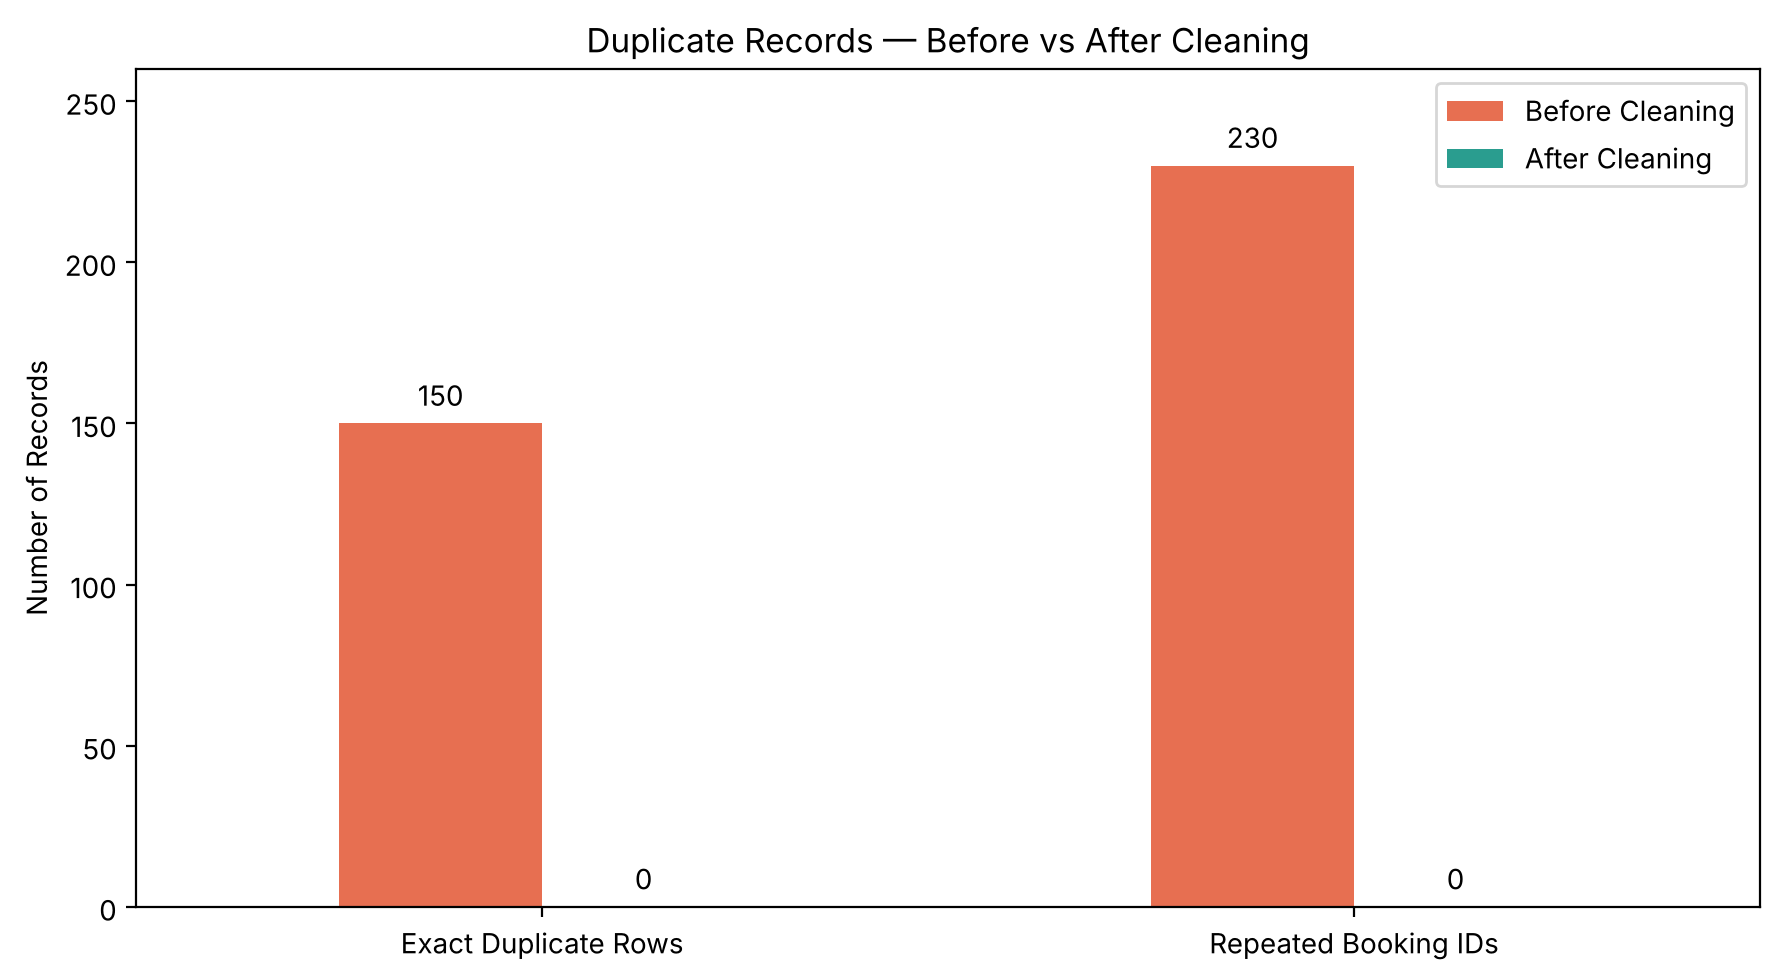

In [32]:
# Visualize duplicate resolution

ax = duplicate_comparison.iloc[1:].plot(
    kind="bar",
    figsize=(9, 5),
    color=["#E76F51", "#2A9D8F"],
    rot=0
)

# Add numerical labels to each bar

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=4)

plt.title("Duplicate Records — Before vs After Cleaning")
plt.ylabel("Number of Records")
plt.xlabel("")
plt.ylim(0, 260)
plt.legend()
plt.tight_layout()
plt.show()

#### Key Findings

The duplicate resolution strategy successfully eliminated
100% of exact duplicate rows and repeated booking ID
occurrences.

The dataset was reduced from 24,480 records to 24,250
unique booking records, retaining the most recently
updated version of each repeated booking.

This improves data uniqueness and prevents unintended
row multiplication during integration with the CRM dataset.

### 5.3 Missing Values Treatment

Following duplicate resolution, missing values are
reassessed to determine their remaining impact on
data completeness.

Missing information is preserved when its true value
cannot be confidently determined.

In [33]:
# Recalculate missing values after duplicate resolution

missing_after_duplicates = pd.DataFrame({
    "Missing Values": pms_clean.isna().sum(),
    "Missing Percentage (%)": pms_clean.isna().mean() * 100
}).round(2)

display(
    missing_after_duplicates[
        missing_after_duplicates["Missing Values"] > 0
    ]
)

,Missing Values,Missing Percentage (%)
children,810,3.34
meal,485,2.00


In [34]:
# Investigate the distribution of children and meal

print("Children distribution:")
print(pms_clean["children"].value_counts(dropna=False))

print("\nMeal distribution:")
print(pms_clean["meal"].value_counts(dropna=False))

Children distribution:
children
0.0    21806
1.0      935
NaN      810
2.0      686
3.0       13
Name: count, dtype: int64

Meal distribution:
meal
BB           18422
HB            2852
SC            2092
NaN            485
Undefined      236
FB             163
Name: count, dtype: int64


#### 5.3.3 Missing Values Treatment Strategy

Missing values in the `children` and `meal` columns
are temporarily preserved.

Replacing missing children values with zero would
incorrectly assume that no children were included
in the booking.

Similarly, replacing missing meal values with the most
frequent category could introduce artificial information.

Potential recovery of missing information from the CRM
dataset will be evaluated after integration.

In [35]:
# Document the missing value treatment decision

rows_before = len(pms_clean)

# Preserve missing values until CRM integration

rows_after = len(pms_clean)

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("Rows removed:", rows_before - rows_after)

print("Missing children values:",
      pms_clean["children"].isna().sum())

print("Missing meal values:",
      pms_clean["meal"].isna().sum())

Rows before: 24250
Rows after: 24250
Rows removed: 0
Missing children values: 810
Missing meal values: 485


### 5.4 Data Type Conversion

Variables are converted to appropriate data types to
ensure reliable calculations, aggregations and integration
with the CRM dataset.

Original values are inspected before conversion to
prevent unintended information loss.

In [36]:
# Preserve data types before conversion

dtypes_before = pms_clean.dtypes.copy()

display(dtypes_before)

booking_id                                str
hotel                                     str
arrival_date_year                       int64
arrival_date_month                        str
arrival_date_day_of_month               int64
stays_in_weekend_nights                 int64
stays_in_week_nights                    int64
adults                                  int64
children                              float64
babies                                  int64
meal                                      str
reserved_room_type                        str
assigned_room_type                        str
booking_changes                         int64
deposit_type                              str
adr                                    object
required_car_parking_spaces             int64
total_of_special_requests               int64
is_canceled                            object
record_updated_at              datetime64[us]
dtype: object

In [37]:
# Identify non-numeric ADR values

adr_numeric = pd.to_numeric(
    pms_clean["adr"],
    errors="coerce"
)

invalid_adr = pms_clean[
    adr_numeric.isna() &
    pms_clean["adr"].notna()
]

print("Non-numeric ADR values:", len(invalid_adr))

display(invalid_adr["adr"].value_counts())

Non-numeric ADR values: 603


adr
n.d.          43
?             41
-             36
90,00          6
75,00          6
              ..
€ 94.50        1
101,50         1
58,95          1
€ 121.50       1
101.50 EUR     1
Name: count, Length: 358, dtype: int64

In [38]:
# Inspect cancellation status values

display(
    pms_clean["is_canceled"].value_counts(dropna=False)
)

print("Current data type:",
      pms_clean["is_canceled"].dtype)

is_canceled
0      14433
1       8605
no       778
yes      434
Name: count, dtype: int64

Current data type: object


In [39]:
# Convert children to nullable integer

rows_before = len(pms_clean)

children_numeric = pd.to_numeric(
    pms_clean["children"],
    errors="raise"
)

pms_clean["children"] = children_numeric.astype("Int64")

rows_after = len(pms_clean)

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("New data type:", pms_clean["children"].dtype)
print("Missing values:", pms_clean["children"].isna().sum())

Rows before: 24250
Rows after: 24250
New data type: Int64
Missing values: 810


In [40]:
# Standardize the booking identifier data type

rows_before = len(pms_clean)

pms_clean["booking_id"] = pms_clean["booking_id"].astype("string")

rows_after = len(pms_clean)

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("New data type:", pms_clean["booking_id"].dtype)
print("Unique booking IDs:", pms_clean["booking_id"].nunique())
print("Repeated booking IDs:",
      pms_clean["booking_id"].duplicated().sum())

Rows before: 24250
Rows after: 24250
New data type: string
Unique booking IDs: 24250
Repeated booking IDs: 0


### 5.5 Categorical Standardization

Categorical variables are standardized to ensure consistency
across labels and classifications.

Differences in capitalization and unnecessary whitespace
may create artificial categories and affect both data
integration and subsequent business analysis.

Standardization is performed while preserving the original
meaning of each category and retaining missing values.

In [41]:
# Identify categorical variables to standardize

categorical_columns = [
    "hotel",
    "arrival_date_month",
    "meal",
    "reserved_room_type",
    "assigned_room_type",
    "deposit_type"
]

# Inspect original categories

for column in categorical_columns:
    print(f"\nColumn: {column}")
    print(pms_clean[column].value_counts(dropna=False))


Column: hotel
hotel
City Hotel       15148
Resort Hotel      7647
city hotel         260
CITY HOTEL         243
City hotel         242
 City Hotel        239
resort hotel       132
 RESORT HOTEL      118
Resort Hotel       115
Resort hotel       106
Name: count, dtype: int64

Column: arrival_date_month
arrival_date_month
August       2533
May          2217
July         2213
October      2014
April        1979
June         1942
September    1895
March        1750
February     1451
December     1185
November     1178
January      1071
7             128
8             118
july          113
4             109
Aug           108
Jul           104
Jun           104
Sep           104
june          101
Oct            95
august         93
april          93
10             92
october        90
september      90
5              84
may            83
9              81
6              80
march          79
3              75
Mar            75
february       69
Apr            67
Feb            66
11        

In [42]:
# Record the number of categories before standardization

categories_before = pms_clean[
    categorical_columns
].nunique()

display(categories_before)

hotel                 10
arrival_date_month    47
meal                   5
reserved_room_type    10
assigned_room_type    11
deposit_type           5
dtype: int64

#### 5.5.4 Standardization Rules

Categorical variables are standardized by removing
unnecessary whitespace and applying consistent capitalization.

Hotel names, arrival months and deposit types use title case,
while meal and room codes use uppercase formatting.

Missing values are preserved throughout the transformation.

In [43]:
# Record the number of rows before standardization

rows_before = len(pms_clean)

# Standardize descriptive categories

title_columns = [
    "hotel",
    "arrival_date_month",
    "deposit_type"
]

for column in title_columns:
    pms_clean[column] = (
        pms_clean[column]
        .astype("string")
        .str.strip()
        .str.title()
    )

# Standardize categorical codes

uppercase_columns = [
    "meal",
    "reserved_room_type",
    "assigned_room_type"
]

for column in uppercase_columns:
    pms_clean[column] = (
        pms_clean[column]
        .astype("string")
        .str.strip()
        .str.upper()
    )

# Document the transformation

rows_after = len(pms_clean)

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("Rows removed:", rows_before - rows_after)

Rows before: 24250
Rows after: 24250
Rows removed: 0


In [44]:
# Record the number of categories after standardization

categories_after = pms_clean[
    categorical_columns
].nunique()

# Compare before and after standardization

category_comparison = pd.DataFrame({
    "Before Standardization": categories_before,
    "After Standardization": categories_after
})

category_comparison["Reduction"] = (
    categories_before - categories_after
)

display(category_comparison)

,Before Standardization,After Standardization,Reduction
hotel,10,2,8
arrival_date_month,47,35,12
meal,5,5,0
reserved_room_type,10,10,0
assigned_room_type,11,11,0
deposit_type,5,3,2


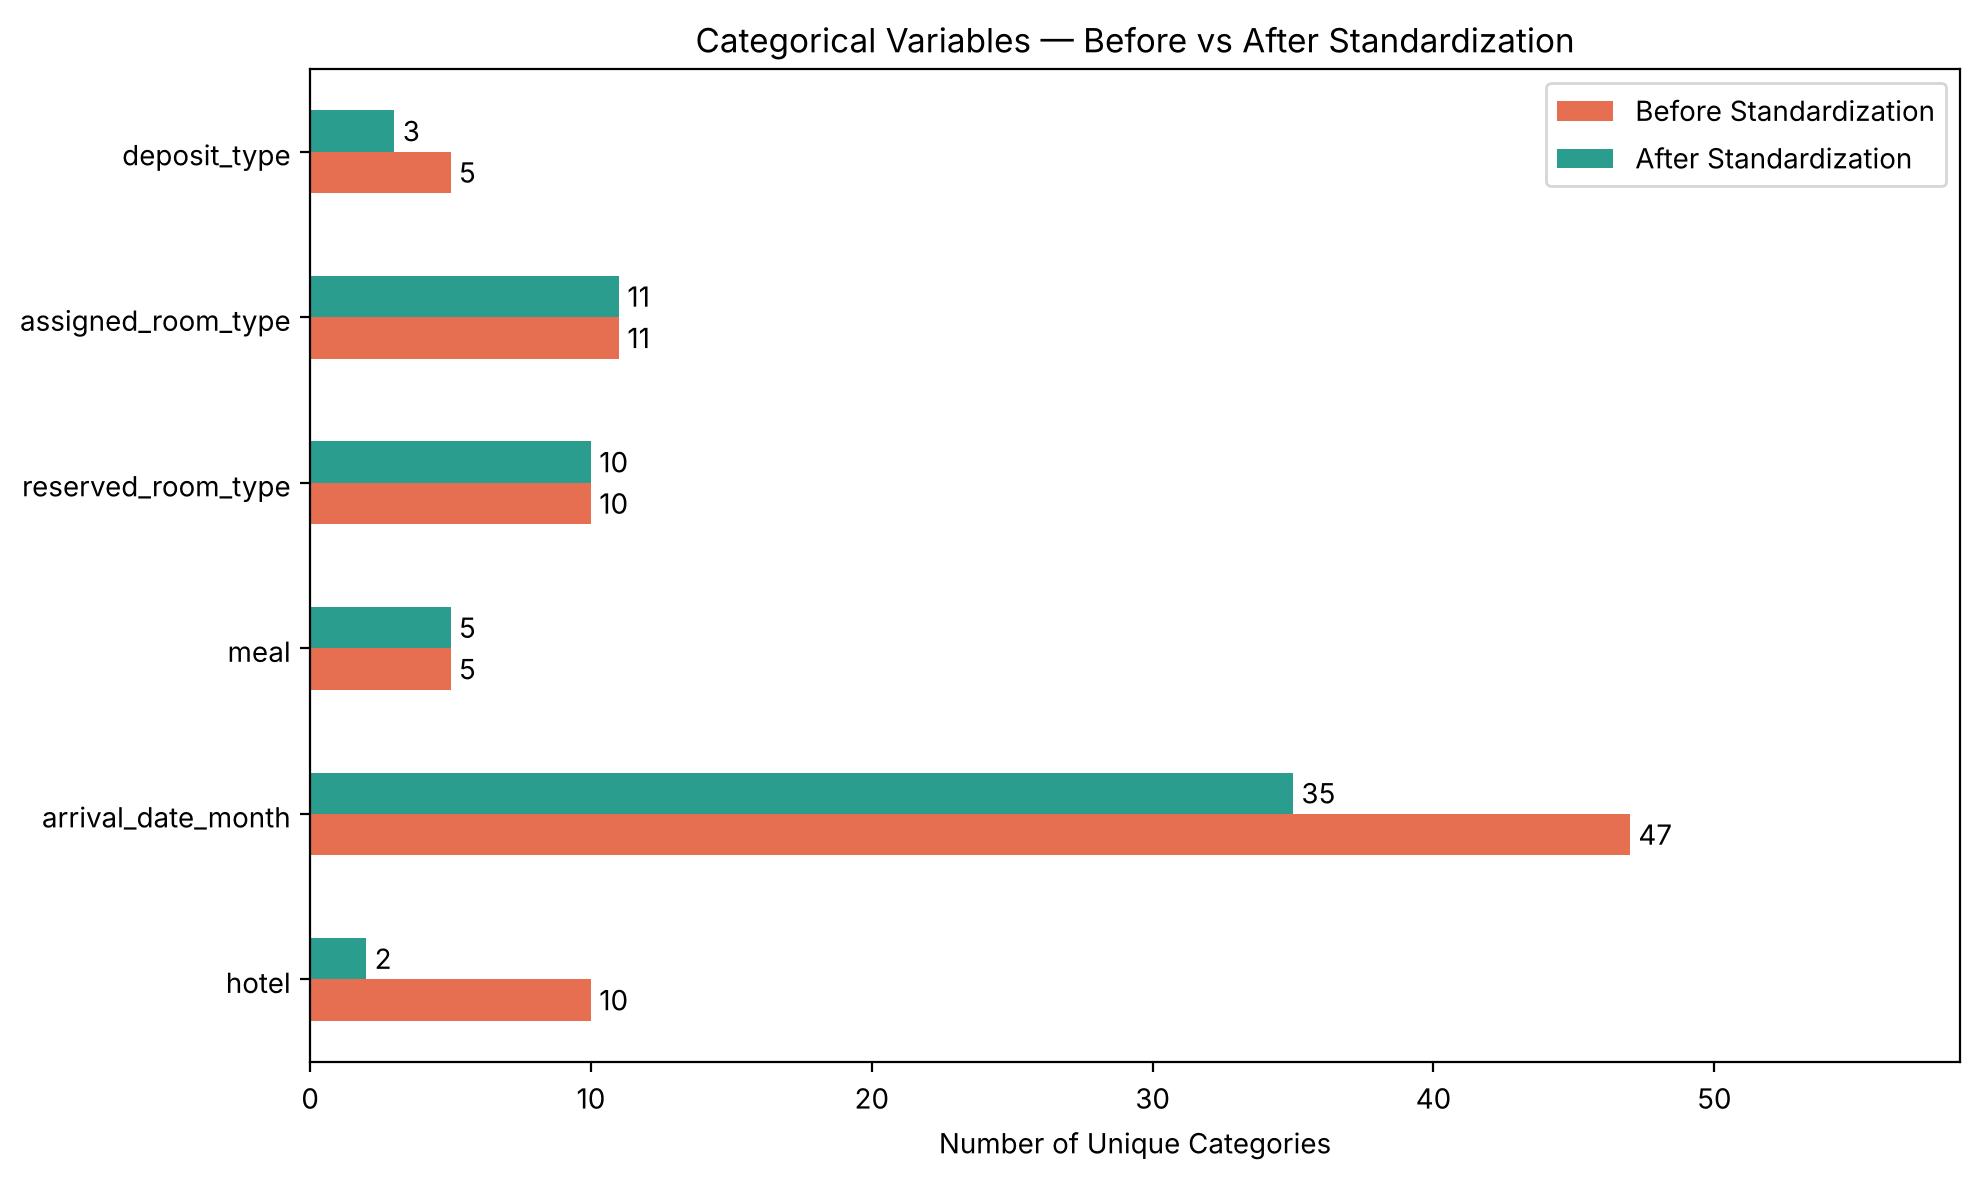

In [45]:
# Visualize categorical standardization

ax = category_comparison[
    ["Before Standardization", "After Standardization"]
].plot(
    kind="barh",
    figsize=(10, 6),
    color=["#E76F51", "#2A9D8F"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.title("Categorical Variables — Before vs After Standardization")
plt.xlabel("Number of Unique Categories")
plt.ylabel("")
plt.xlim(
    0,
    category_comparison["Before Standardization"].max() * 1.25
)
plt.legend()
plt.tight_layout()
plt.show()

In [46]:
# Validate categories after standardization

for column in categorical_columns:
    print(f"\nColumn: {column}")
    print(pms_clean[column].value_counts(dropna=False))


Column: hotel
hotel
City Hotel      16132
Resort Hotel     8118
Name: count, dtype: Int64

Column: arrival_date_month
arrival_date_month
August       2626
July         2326
May          2300
October      2104
April        2072
June         2043
September    1985
March        1829
February     1520
December     1246
November     1232
January      1115
7             128
8             118
4             109
Aug           108
Jul           104
Jun           104
Sep           104
Oct            95
10             92
5              84
9              81
6              80
3              75
Mar            75
Apr            67
Feb            66
11             62
Dec            56
Nov            56
1              51
2              47
Jan            47
12             43
Name: count, dtype: Int64

Column: meal
meal
BB           18422
HB            2852
SC            2092
<NA>           485
UNDEFINED      236
FB             163
Name: count, dtype: Int64

Column: reserved_room_type
reserved_room_type


#### 5.5.8 Month Standardization

The initial categorical standardization reduced the number
of arrival month categories from 47 to 35.

However, the dataset still contains full month names,
abbreviations and numerical representations.

A mapping dictionary is used to standardize all valid
month representations into their full English names.

In [47]:
# Define a mapping dictionary for month standardization

month_mapping = {
    "1": "January", "Jan": "January",
    "2": "February", "Feb": "February",
    "3": "March", "Mar": "March",
    "4": "April", "Apr": "April",
    "5": "May",
    "6": "June", "Jun": "June",
    "7": "July", "Jul": "July",
    "8": "August", "Aug": "August",
    "9": "September", "Sep": "September",
    "10": "October", "Oct": "October",
    "11": "November", "Nov": "November",
    "12": "December", "Dec": "December"
}

# Standardize month representations

pms_clean["arrival_date_month"] = (
    pms_clean["arrival_date_month"].replace(month_mapping)
)

In [48]:
# Validate standardized month categories

valid_months = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

invalid_months = pms_clean[
    ~pms_clean["arrival_date_month"].isin(valid_months)
]

print("Unique months:",
      pms_clean["arrival_date_month"].nunique())

print("Invalid month records:", len(invalid_months))

display(pms_clean["arrival_date_month"].value_counts())

display(invalid_months["arrival_date_month"].value_counts(dropna=False))

Unique months: 12
Invalid month records: 0


arrival_date_month
August       2852
July         2558
May          2384
October      2291
April        2248
June         2227
September    2170
March        1979
February     1633
November     1350
December     1345
January      1213
Name: count, dtype: Int64

Series([], Name: count, dtype: Int64)

In [49]:
# Update the categorical standardization comparison

categories_after = pms_clean[categorical_columns].nunique()

category_comparison["After Standardization"] = categories_after

category_comparison["Reduction"] = (
    categories_before - categories_after
)

display(category_comparison)

,Before Standardization,After Standardization,Reduction
hotel,10,2,8
arrival_date_month,47,12,35
meal,5,5,0
reserved_room_type,10,10,0
assigned_room_type,11,11,0
deposit_type,5,3,2


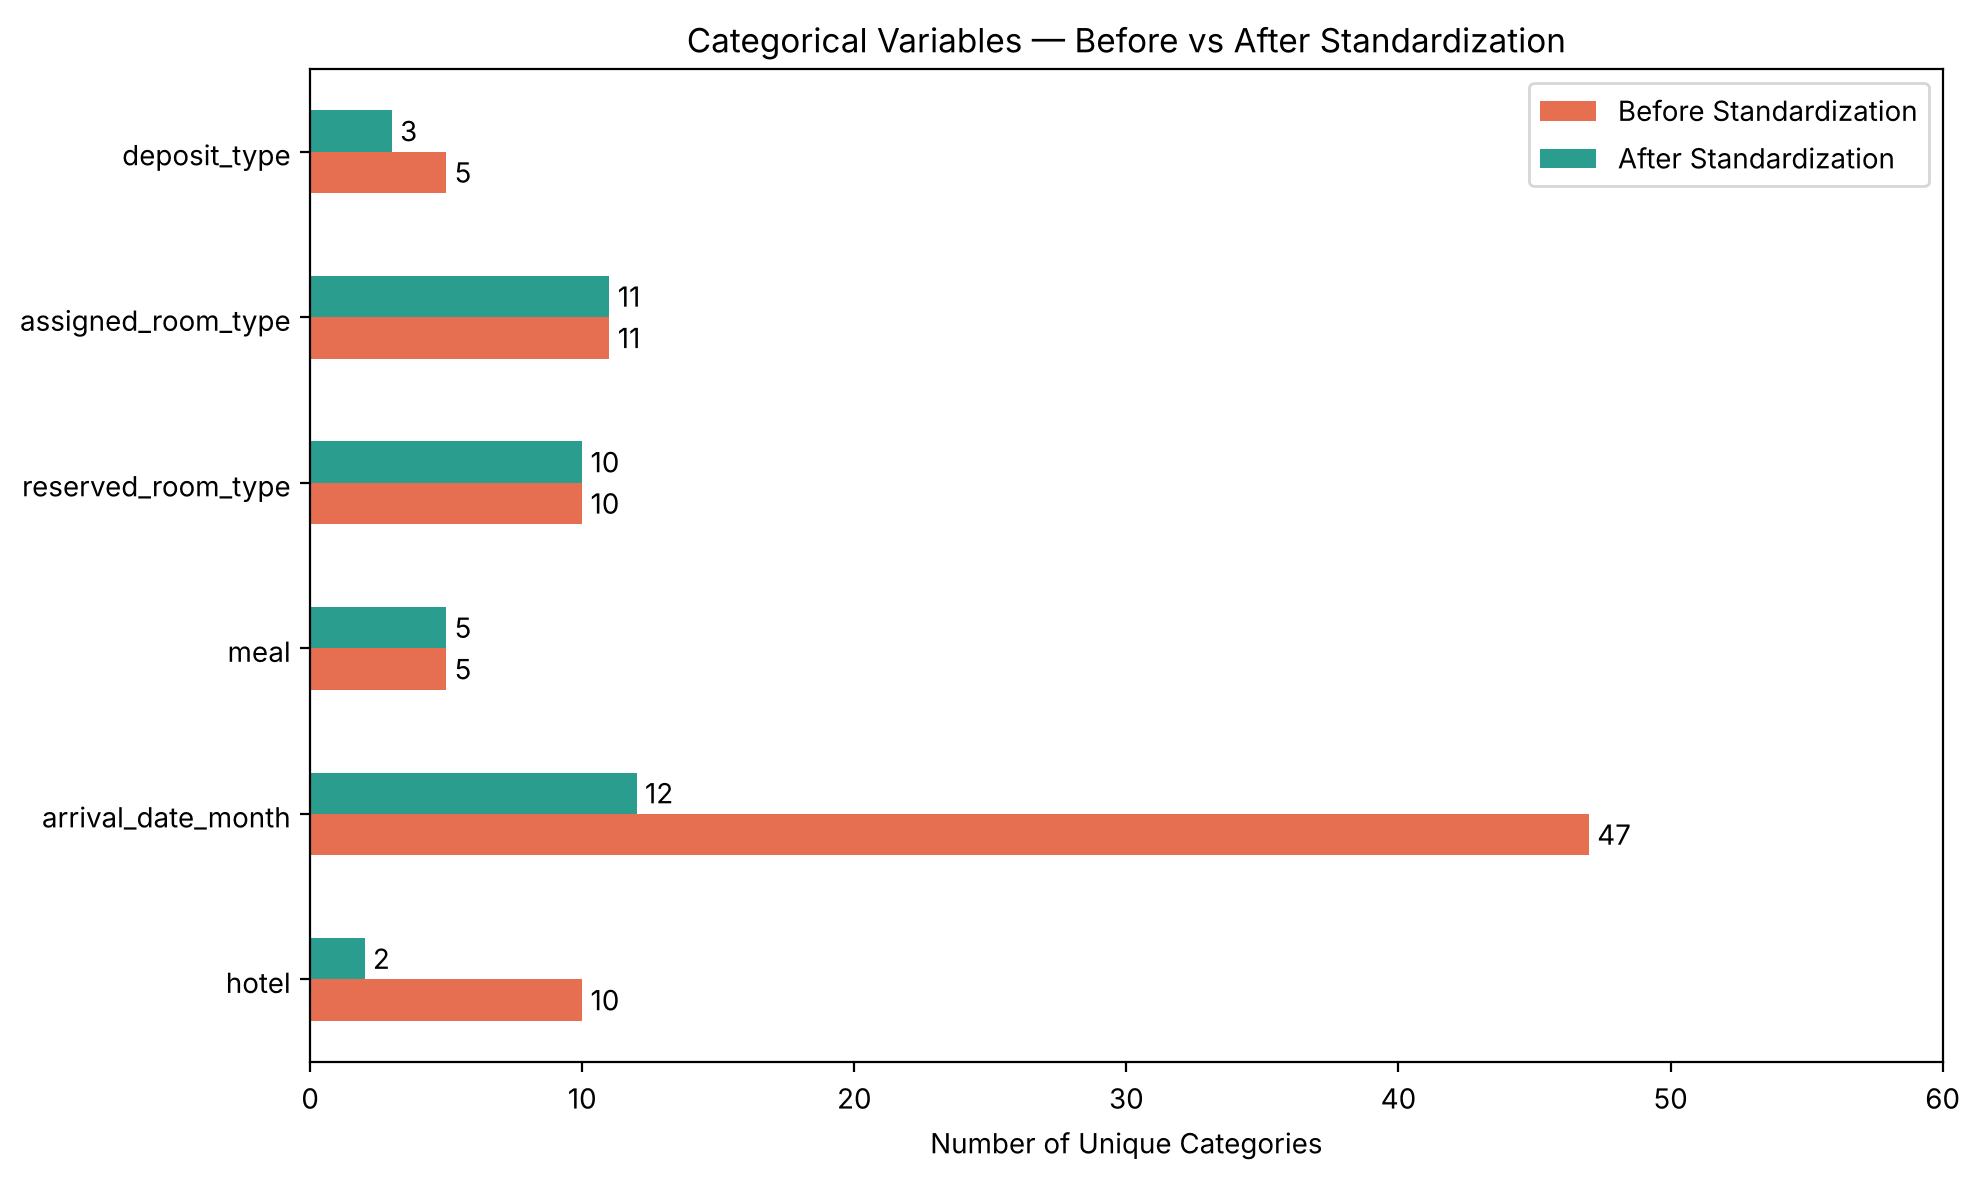

In [50]:
# Visualize final categorical standardization results

ax = category_comparison[
    ["Before Standardization", "After Standardization"]
].plot(
    kind="barh",
    figsize=(10, 6),
    color=["#E76F51", "#2A9D8F"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.title("Categorical Variables — Before vs After Standardization")
plt.xlabel("Number of Unique Categories")
plt.ylabel("")
plt.xlim(0, 60)
plt.legend()
plt.tight_layout()
plt.show()

#### Key Findings

Categorical standardization successfully reduced:

- Hotel categories from 10 to 2 (80% reduction).
- Arrival month categories from 47 to 12 (74.47% reduction).
- Deposit type categories from 5 to 3 (40% reduction).

All arrival months are now represented by their full
English names, with zero invalid month records.

No booking records were removed during this process.

The standardization improves data consistency and
ensures more reliable aggregation and integration.

### 5.6 Invalid Values and Outliers

This section investigates numerical validity and logical
consistency across booking records.

Invalid values are distinguished from statistical outliers,
as extreme observations may represent legitimate bookings.

Potential anomalies are investigated before applying
corrective transformations to avoid unnecessary data loss.

In [51]:
# Inspect remaining numerical conversion issues

adr_test = pd.to_numeric(
    pms_clean["adr"],
    errors="coerce"
)

print("Non-numeric ADR values:")

display(
    pms_clean.loc[
        adr_test.isna() & pms_clean["adr"].notna(),
        "adr"
    ].value_counts()
)

print("\nCancellation status values:")

display(pms_clean["is_canceled"].value_counts(dropna=False))

Non-numeric ADR values:


adr
n.d.          43
?             41
-             36
90,00          6
75,00          6
              ..
€ 94.50        1
101,50         1
58,95          1
€ 121.50       1
101.50 EUR     1
Name: count, Length: 358, dtype: int64


Cancellation status values:


is_canceled
0      14433
1       8605
no       778
yes      434
Name: count, dtype: int64

#### 5.6.3 Negative Values

Variables representing guest counts, stay duration and
booking modifications are checked for negative values.

Negative quantities are inconsistent with their expected
business meaning.

In [52]:
# Identify variables that should contain non-negative values

non_negative_columns = [
    "adults",
    "children",
    "babies",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "booking_changes"
]

# Identify negative values

negative_values = pd.DataFrame({
    "Negative Values": (
        pms_clean[non_negative_columns] < 0
    ).sum()
})

display(negative_values)

,Negative Values
adults,0
children,0
babies,0
stays_in_weekend_nights,0
stays_in_week_nights,35
booking_changes,0


#### 5.6.4 Logical Consistency — Guest Counts

Bookings with no registered guests are identified as
potential logical inconsistencies.

Missing guest information is distinguished from confirmed
zero-guest bookings.

In [53]:
# Calculate the total number of guests for validation

total_guests_check = pms_clean[
    ["adults", "children", "babies"]
].sum(axis=1, min_count=3)

# Identify bookings with zero guests

zero_guest_bookings = pms_clean[
    total_guests_check == 0
]

print("Bookings with zero guests:",
      len(zero_guest_bookings))

print("Bookings with unknown total guests:",
      total_guests_check.isna().sum())

display(zero_guest_bookings.head(10))

Bookings with zero guests: 31
Bookings with unknown total guests: 810


,booking_id,hotel,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,reserved_room_type,assigned_room_type,booking_changes,deposit_type,adr,required_car_parking_spaces,total_of_special_requests,is_canceled,record_updated_at
523,BK322575,City Hotel,2017,July,15,2,5,0,0,0,SC,A,K,1,No Deposit,22.86,0,1,0,2017-07-18 03:55:00
974,BK318307,City Hotel,2017,June,28,0,0,0,0,0,BB,A,A,1,No Deposit,0,0,0,0,2017-06-27 14:11:00
1935,BK324346,City Hotel,2017,July,27,0,2,0,0,0,BB,A,A,0,No Deposit,0,0,0,0,2017-05-20 18:11:00
2192,BK324578,City Hotel,2017,May,14,0,0,0,0,0,BB,A,A,1,No Deposit,0,0,0,0,2017-05-11 22:10:00
2905,BK314777,City Hotel,2017,April,20,2,3,0,0,0,SC,A,K,1,No Deposit,0,0,1,0,2017-04-20 01:08:00
2985,BK308787,City Hotel,2017,April,14,2,3,0,0,0,SC,D,K,1,No Deposit,0,0,1,0,2017-04-17 08:38:00
3205,BK317783,City Hotel,2017,April,10,0,0,0,0,0,SC,P,P,0,No Deposit,0,0,0,1,2017-04-10 00:44:00
3540,BK307830,Resort Hotel,2017,March,30,2,6,0,0,0,SC,A,A,0,No Deposit,0,0,0,0,2017-03-31 17:15:00
3589,BK324945,City Hotel,2017,March,9,8,19,0,0,0,SC,G,K,14,No Deposit,0,0,0,0,2017-03-30 17:18:00
3629,BK322814,Resort Hotel,2017,March,30,2,6,0,0,0,SC,A,A,0,No Deposit,0,0,0,0,2017-03-29 19:47:00


#### 5.6.5 Logical Consistency — Stay Duration

Total stay duration is calculated by combining weekday
and weekend nights.

Zero-night bookings are identified for further investigation,
as they may represent cancellations, special booking
conditions or data quality issues.

In [54]:
# Calculate total stay duration for validation

total_nights_check = (
    pms_clean["stays_in_weekend_nights"] +
    pms_clean["stays_in_week_nights"]
)

# Identify zero-night bookings

zero_night_bookings = pms_clean[
    total_nights_check == 0
]

print("Bookings with zero nights:",
      len(zero_night_bookings))

display(
    zero_night_bookings[
        [
            "booking_id",
            "hotel",
            "is_canceled",
            "adr",
            "stays_in_weekend_nights",
            "stays_in_week_nights"
        ]
    ].head(10)
)

Bookings with zero nights: 159


,booking_id,hotel,is_canceled,adr,stays_in_weekend_nights,stays_in_week_nights
36,BK304166,City Hotel,0,0,0,0
520,BK322265,Resort Hotel,0,0,0,0
943,BK323461,Resort Hotel,0,0,0,0
974,BK318307,City Hotel,0,0,0,0
1408,BK308070,Resort Hotel,0,106,1,-1
1699,BK311303,City Hotel,0,0,0,0
2192,BK324578,City Hotel,0,0,0,0
2299,BK311818,City Hotel,0,0,0,0
2335,BK314800,Resort Hotel,0,0,0,0
2525,BK317237,Resort Hotel,0,0,0,0


#### 5.6.6 Statistical Outlier Detection

The Interquartile Range (IQR) method is used to identify
potential numerical outliers.

Observations outside the lower and upper IQR boundaries
are flagged for investigation rather than automatically
removed.

In [55]:
# Identify numerical outliers using the IQR method

outlier_columns = [
    "adults",
    "children",
    "babies",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "booking_changes"
]

outlier_report = []

for column in outlier_columns:

    q1 = pms_clean[column].quantile(0.25)
    q3 = pms_clean[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (pms_clean[column] < lower_bound) |
        (pms_clean[column] > upper_bound)
    ).sum()

    outlier_report.append({
        "Variable": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": outliers
    })

outlier_summary = pd.DataFrame(outlier_report)

display(outlier_summary.round(2))

,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers
0,adults,2.0,2.0,0.0,2.0,2.0,5994
1,children,0.0,0.0,0.0,0.0,0.0,1634
2,babies,0.0,0.0,0.0,0.0,0.0,194
3,stays_in_weekend_nights,0.0,2.0,2.0,-3.0,5.0,40
4,stays_in_week_nights,1.0,3.0,2.0,-2.0,6.0,637
5,booking_changes,0.0,0.0,0.0,0.0,0.0,3659


#### 5.6.7 ADR Cleaning and Conversion

The Average Daily Rate variable contains inconsistent
numerical formats, currency symbols, decimal separators
and textual placeholders representing unavailable values.

Valid monetary values are standardized and converted
to a numerical format, while unavailable information
is represented as missing rather than artificially imputed.

In [56]:
# Preserve original ADR values

adr_original = pms_clean["adr"].copy()

# Standardize ADR formatting

adr_cleaned = (
    adr_original
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace("EUR", "", regex=False)
    .str.replace("€", "", regex=False)
    .str.strip()
)

# Identify explicit missing value placeholders

missing_tokens = ["N.D.", "?", "-", ""]

adr_cleaned = adr_cleaned.replace(missing_tokens, pd.NA)

# Standardize decimal commas when no decimal point is present

comma_decimal = adr_cleaned.str.fullmatch(
    r"-?\d+,\d{1,2}", na=False
)

adr_cleaned.loc[comma_decimal] = (
    adr_cleaned.loc[comma_decimal]
    .str.replace(",", ".", regex=False)
)

# Convert ADR to numerical format

adr_numeric = pd.to_numeric(
    adr_cleaned,
    errors="coerce"
)

# Check remaining unrecognized formats

unresolved_adr = adr_cleaned[
    adr_cleaned.notna() & adr_numeric.isna()
]

print("Unresolved ADR values:", len(unresolved_adr))

display(unresolved_adr.value_counts())

Unresolved ADR values: 0


Series([], Name: count, dtype: Int64)

In [57]:
# Apply validated numerical conversion

assert unresolved_adr.empty

pms_clean["adr"] = adr_numeric.astype("float64")

print("ADR data type:", pms_clean["adr"].dtype)

print("Missing ADR values:",
      pms_clean["adr"].isna().sum())

print("Negative ADR values:",
      (pms_clean["adr"] < 0).sum())

display(pms_clean["adr"].describe())

ADR data type: float64
Missing ADR values: 120
Negative ADR values: 40


count    24130.000000
mean       113.756313
std        372.059202
min       -200.000000
25%         69.000000
50%         94.670000
75%        126.000000
max      17910.000000
Name: adr, dtype: float64

#### 5.6.8 Cancellation Status Standardization

Cancellation status is represented using both numerical
and textual labels.

These representations are standardized into a binary
variable, where 0 indicates a non-canceled booking
and 1 indicates a canceled booking.

In [58]:
# Define cancellation status mapping

cancellation_mapping = {
    "0": 0,
    "1": 1,
    "no": 0,
    "yes": 1
}

# Standardize cancellation status

cancellation_cleaned = (
    pms_clean["is_canceled"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Validate mapping before applying it

assert cancellation_cleaned.isin(cancellation_mapping).all()

pms_clean["is_canceled"] = (
    cancellation_cleaned
    .map(cancellation_mapping)
    .astype("Int64")
)

# Validate results

display(pms_clean["is_canceled"].value_counts())

print("Unique values:",
      pms_clean["is_canceled"].nunique())

print("Missing values:",
      pms_clean["is_canceled"].isna().sum())

is_canceled
0    15211
1     9039
Name: count, dtype: Int64

Unique values: 2
Missing values: 0


#### 5.6.9 Negative Stay Duration Treatment

The data quality assessment identified 35 records
containing negative weekday stay durations.

Negative nights are inconsistent with the business
definition of stay duration.

Affected records are investigated before treatment,
preserving booking information wherever possible.

In [59]:
# Investigate negative weekday stay durations

negative_nights = pms_clean[
    pms_clean["stays_in_week_nights"] < 0
].copy()

display(
    negative_nights["stays_in_week_nights"]
    .value_counts()
    .sort_index()
)

display(
    negative_nights[
        [
            "booking_id",
            "hotel",
            "stays_in_weekend_nights",
            "stays_in_week_nights",
            "is_canceled",
            "adr"
        ]
    ].head(10)
)

stays_in_week_nights
-1    35
Name: count, dtype: int64

,booking_id,hotel,stays_in_weekend_nights,stays_in_week_nights,is_canceled,adr
1408,BK308070,Resort Hotel,1,-1,0,106.00
2303,BK302948,City Hotel,0,-1,1,125.00
2405,BK311375,Resort Hotel,4,-1,1,180.50
4362,BK308107,Resort Hotel,1,-1,0,67.00
5562,BK311529,City Hotel,2,-1,1,126.00
6013,BK307465,Resort Hotel,0,-1,1,76.00
7618,BK311909,City Hotel,0,-1,0,79.00
7710,BK319532,City Hotel,0,-1,0,65.00
8418,BK300863,City Hotel,0,-1,0,0.00
9173,BK318594,City Hotel,1,-1,0,69.53


#### 5.6.10 Outlier Interpretation and Treatment Strategy

The IQR method identified several potential numerical
outliers across the dataset.

However, adults, children, babies and booking changes
have an interquartile range equal to zero.

In these cases, the IQR method flags observations that
may represent entirely legitimate booking behavior,
such as solo travelers or families with children.

Statistical outliers are therefore not automatically
removed. Business validity rules and additional
investigation are prioritized over purely statistical
thresholds.

Confirmed invalid values are treated separately.

#### 5.6.11 Correct Negative Stay Duration

All 35 negative weekday stay durations are represented
by the value -1.

Since the actual number of nights cannot be reliably
reconstructed, these invalid values are replaced with
missing values.

The affected booking records are retained to preserve
information for subsequent integration and analysis.

In [60]:
# Identify invalid weekday stay durations

negative_nights_mask = (
    pms_clean["stays_in_week_nights"] < 0
)

print("Invalid values before cleaning:",
      negative_nights_mask.sum())

# Convert to nullable integer

pms_clean["stays_in_week_nights"] = (
    pms_clean["stays_in_week_nights"].astype("Int64")
)

# Replace invalid negative values with missing values

pms_clean.loc[
    negative_nights_mask,
    "stays_in_week_nights"
] = pd.NA

# Validate the transformation

print("Negative values after cleaning:",
      (pms_clean["stays_in_week_nights"] < 0).sum())

print("Missing weekday nights:",
      pms_clean["stays_in_week_nights"].isna().sum())

print("Total records:", len(pms_clean))

Invalid values before cleaning: 35
Negative values after cleaning: 0
Missing weekday nights: 35
Total records: 24250


#### 5.6.12 Negative ADR Investigation

The numerical conversion of ADR revealed 40 negative
monetary values.

These observations require further investigation,
as negative rates may represent data errors or
financial adjustments.

Their distribution and booking characteristics are
examined before determining the appropriate treatment.

In [61]:
# Identify negative ADR records

negative_adr = pms_clean[
    pms_clean["adr"] < 0
].copy()

print("Negative ADR records:", len(negative_adr))

# Inspect negative ADR distribution

display(
    negative_adr["adr"]
    .value_counts()
    .sort_index()
)

# Compare cancellation status

display(
    negative_adr["is_canceled"].value_counts()
)

# Inspect affected bookings

display(
    negative_adr[
        [
            "booking_id",
            "hotel",
            "adr",
            "is_canceled",
            "booking_changes"
        ]
    ].head(10)
)

Negative ADR records: 40


adr
-200.00    1
-193.00    1
-191.00    1
-190.19    1
-170.00    1
-163.62    1
-149.00    1
-141.30    1
-135.00    1
-133.80    1
-133.00    1
-129.00    1
-121.75    1
-121.37    1
-118.40    1
-112.20    1
-100.00    1
-92.00     2
-85.00     2
-80.80     1
-79.00     1
-77.60     1
-72.90     1
-72.00     1
-71.00     1
-65.00     1
-64.00     2
-63.40     1
-62.00     2
-58.00     1
-50.68     1
-45.90     1
-45.00     1
-44.66     1
-37.00     1
-36.00     1
Name: count, dtype: int64

is_canceled
0    23
1    17
Name: count, dtype: Int64

,booking_id,hotel,adr,is_canceled,booking_changes
809,BK307096,Resort Hotel,-92.00,0,0
825,BK322441,City Hotel,-129.00,1,0
1149,BK312403,City Hotel,-200.00,0,0
1738,BK319887,Resort Hotel,-193.00,0,2
2713,BK313397,City Hotel,-135.00,0,0
3269,BK316389,Resort Hotel,-118.40,1,3
3404,BK318873,City Hotel,-85.00,0,0
6284,BK300468,Resort Hotel,-44.66,0,0
6971,BK313270,Resort Hotel,-64.00,1,0
7450,BK319497,City Hotel,-85.00,1,0


#### 5.6.13 ADR Outlier Detection

The ADR distribution contains extreme monetary values
that may significantly influence descriptive statistics.

The IQR method is applied to non-negative ADR values
to identify unusually high rates.

Statistical outliers are investigated before any
corrective action is taken.

In [62]:
# Select non-negative ADR values for outlier analysis

adr_valid = pms_clean.loc[
    pms_clean["adr"] >= 0,
    "adr"
]

# Calculate IQR boundaries

adr_q1 = adr_valid.quantile(0.25)
adr_q3 = adr_valid.quantile(0.75)

adr_iqr = adr_q3 - adr_q1

adr_lower = adr_q1 - 1.5 * adr_iqr
adr_upper = adr_q3 + 1.5 * adr_iqr

# Identify high ADR outliers

adr_outliers = pms_clean[
    pms_clean["adr"] > adr_upper
]

print("Q1:", adr_q1)
print("Q3:", adr_q3)
print("IQR:", adr_iqr)

print("Lower bound:", adr_lower)
print("Upper bound:", adr_upper)

print("High ADR outliers:", len(adr_outliers))

# Inspect the 15 highest ADR values

display(
    pms_clean.nlargest(15, "adr")[
        [
            "booking_id",
            "hotel",
            "adr",
            "reserved_room_type",
            "is_canceled"
        ]
    ]
)

Q1: 69.35249999999999
Q3: 126.0
IQR: 56.64750000000001
Lower bound: -15.61875000000002
Upper bound: 210.97125
High ADR outliers: 772


,booking_id,hotel,adr,reserved_room_type,is_canceled
22866,BK320907,Resort Hotel,17910.0,G,0
9944,BK320225,City Hotel,16020.0,D,0
5455,BK310324,City Hotel,15000.0,A,0
14229,BK304344,City Hotel,14850.0,D,0
18241,BK313399,Resort Hotel,13500.0,G,0
21894,BK316762,City Hotel,13475.0,A,0
15232,BK321100,City Hotel,13000.0,A,1
12543,BK301650,City Hotel,12780.0,A,1
3671,BK322247,Resort Hotel,12775.0,F,0
9640,BK308989,City Hotel,12000.0,A,1


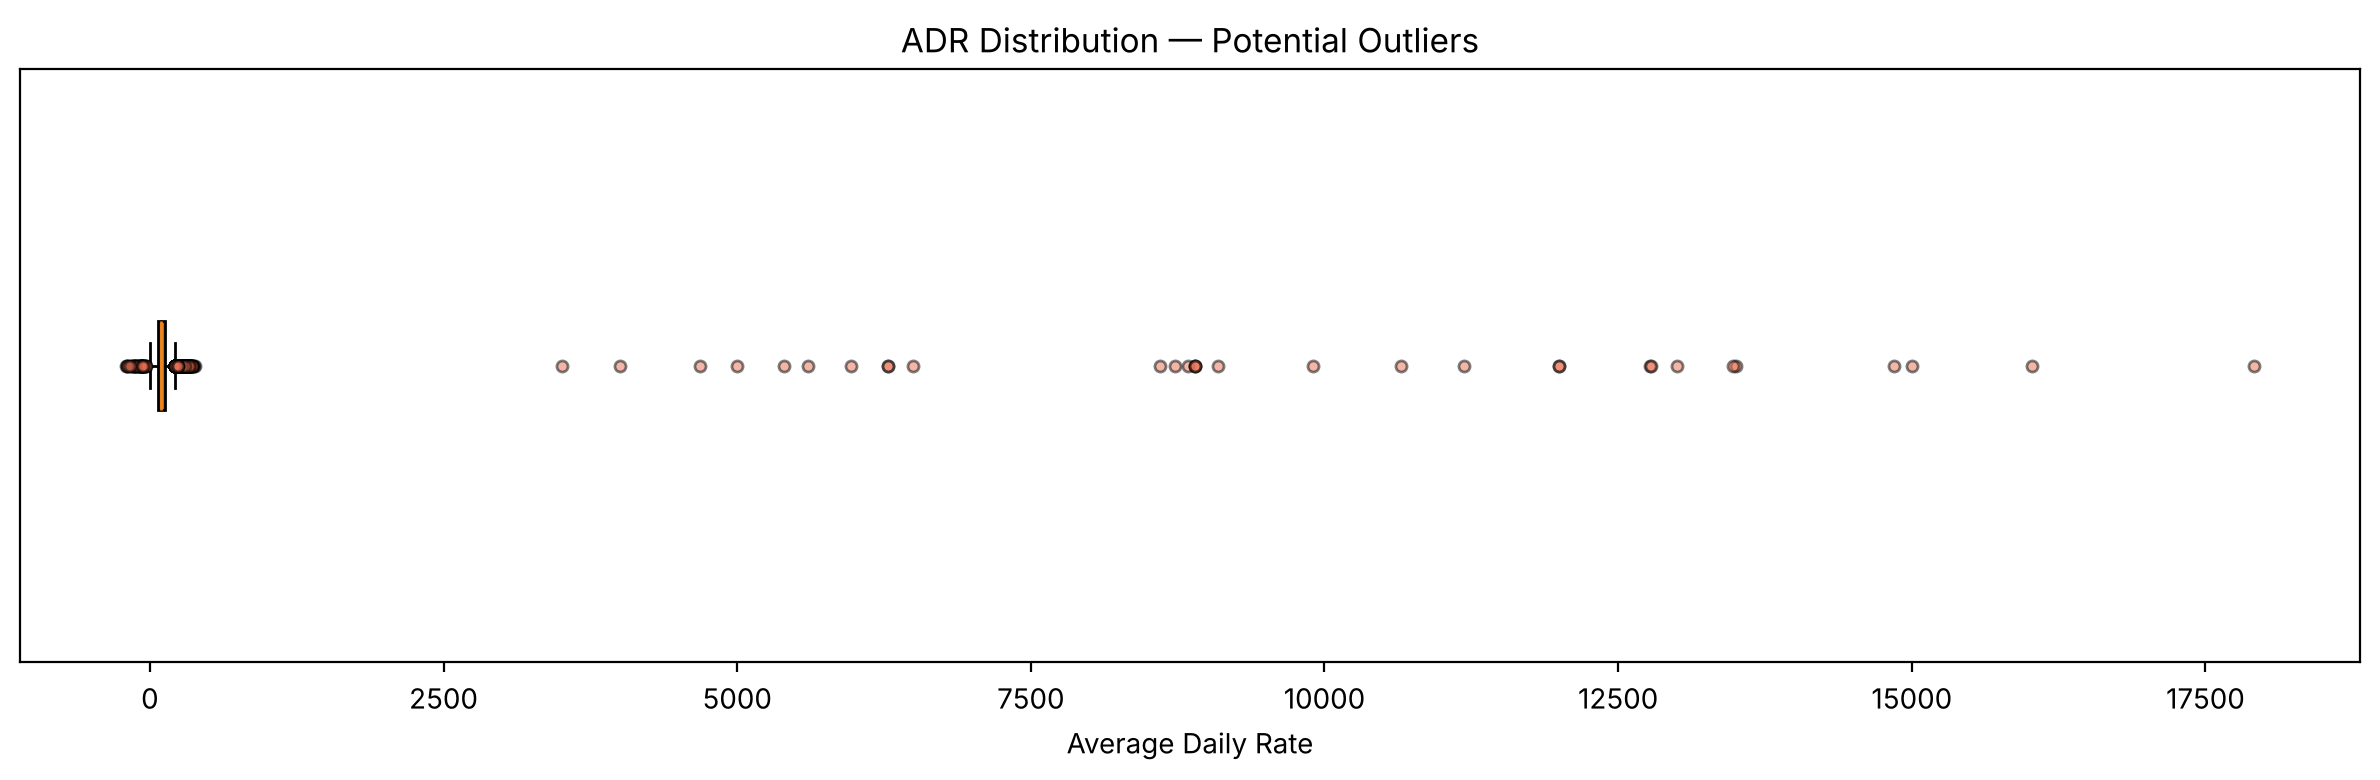

In [63]:
# Visualize ADR distribution and extreme values

plt.figure(figsize=(12, 4))

plt.boxplot(
    pms_clean["adr"].dropna(),
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="#2A9D8F"),
    flierprops=dict(
        marker="o",
        markerfacecolor="#E76F51",
        markersize=4,
        alpha=0.5
    )
)

plt.title("ADR Distribution — Potential Outliers")
plt.xlabel("Average Daily Rate")
plt.yticks([])
plt.tight_layout()
plt.show()

#### 5.6.15 Reassessment of Logical Consistency

Logical consistency checks are repeated after invalid
stay durations have been treated.

This prevents invalid negative values from producing
misleading zero-night booking classifications.

Zero-guest and zero-night bookings are retained for
further investigation and potential reconciliation
during CRM integration.

In [64]:
# Recalculate total nights after cleaning

total_nights_check = pms_clean[
    [
        "stays_in_weekend_nights",
        "stays_in_week_nights"
    ]
].sum(axis=1, min_count=2)

# Recalculate total guests

total_guests_check = pms_clean[
    ["adults", "children", "babies"]
].sum(axis=1, min_count=3)

# Create a logical consistency report

logical_consistency = pd.DataFrame({
    "Quality Check": [
        "Zero-night bookings",
        "Unknown stay duration",
        "Zero-guest bookings",
        "Unknown guest count"
    ],
    "Affected Records": [
        (total_nights_check == 0).sum(),
        total_nights_check.isna().sum(),
        (total_guests_check == 0).sum(),
        total_guests_check.isna().sum()
    ]
})

display(logical_consistency)

,Quality Check,Affected Records
0,Zero-night bookings,147
1,Unknown stay duration,35
2,Zero-guest bookings,31
3,Unknown guest count,810


#### 5.6.16 Extreme ADR Investigation

The ADR distribution reveals a separate group of
extremely high monetary values.

These observations may indicate a unit-of-measure
inconsistency, where some rates were recorded in
cents rather than euros.

A potential rescaling by a factor of 100 is investigated
before applying any transformation to the original values.

In [65]:
# Investigate the upper tail of the ADR distribution

display(
    pms_clean["adr"].quantile(
        [0.90, 0.95, 0.98, 0.99, 0.995, 0.999, 1.0]
    )
)

# Count observations above different thresholds

for threshold in [300, 500, 1000, 2000, 3000]:
    print(
        f"ADR above {threshold}:",
        (pms_clean["adr"] > threshold).sum()
    )

# Investigate a possible unit-of-measure inconsistency

extreme_adr = pms_clean.loc[
    pms_clean["adr"] > 1000,
    ["booking_id", "hotel", "adr", "reserved_room_type"]
].copy()

extreme_adr["Potential Corrected ADR"] = (
    extreme_adr["adr"] / 100
)

display(
    extreme_adr.sort_values("adr", ascending=False)
)

display(
    extreme_adr["Potential Corrected ADR"].describe()
)

0.900      165.00000
0.950      192.88200
0.980      229.58300
0.990      251.81360
0.995      286.37425
0.999     5924.01200
1.000    17910.00000
Name: adr, dtype: float64

ADR above 300: 86
ADR above 500: 31
ADR above 1000: 31
ADR above 2000: 31
ADR above 3000: 31


,booking_id,hotel,adr,reserved_room_type,Potential Corrected ADR
22866,BK320907,Resort Hotel,17910.0,G,179.10
9944,BK320225,City Hotel,16020.0,D,160.20
5455,BK310324,City Hotel,15000.0,A,150.00
14229,BK304344,City Hotel,14850.0,D,148.50
18241,BK313399,Resort Hotel,13500.0,G,135.00
21894,BK316762,City Hotel,13475.0,A,134.75
15232,BK321100,City Hotel,13000.0,A,130.00
12543,BK301650,City Hotel,12780.0,A,127.80
3671,BK322247,Resort Hotel,12775.0,F,127.75
18002,BK305075,City Hotel,12000.0,A,120.00


count     31.000000
mean      96.849355
std       38.309867
min       35.110000
25%       62.800000
50%       89.000000
75%      127.775000
max      179.100000
Name: Potential Corrected ADR, dtype: float64

#### 5.6.17 ADR Correction and Treatment

The investigation identified 31 extreme ADR values
above 3,000, with no observations in the interval
(500, 3,000].

Rescaling these observations by a factor of 100
produces rates consistent with the main ADR distribution.

Based on this evidence, a potential unit-of-measure
inconsistency is addressed through an inferred correction.

Negative ADR values are treated as missing for rate
analysis because their actual meaning cannot be verified.

Other statistical outliers are retained, as unusually
high rates do not necessarily represent data errors.

Original numerical values and correction flags are
preserved to ensure transparency and traceability.

The rescaling assumption requires validation against
the original source system.

In [66]:
# Preserve ADR values before correction

pms_clean["adr_before_correction"] = pms_clean["adr"].copy()

# Identify suspected unit-of-measure inconsistencies

pms_clean["adr_scale_corrected"] = (
    pms_clean["adr"] > 3000
)

# Identify negative ADR values

pms_clean["adr_negative_flag"] = (
    pms_clean["adr"] < 0
)

# Correct suspected unit-of-measure inconsistencies

pms_clean.loc[
    pms_clean["adr_scale_corrected"],
    "adr"
] = pms_clean.loc[
    pms_clean["adr_scale_corrected"],
    "adr"
] / 100

# Replace negative ADR values with missing values

pms_clean.loc[
    pms_clean["adr_negative_flag"],
    "adr"
] = np.nan

# Validate the treatment

print("Rescaled ADR values:",
      pms_clean["adr_scale_corrected"].sum())

print("Negative ADR values treated:",
      pms_clean["adr_negative_flag"].sum())

print("Remaining negative ADR values:",
      (pms_clean["adr"] < 0).sum())

print("Remaining ADR values above 3000:",
      (pms_clean["adr"] > 3000).sum())

print("Missing ADR values:",
      pms_clean["adr"].isna().sum())

print("Total records:", len(pms_clean))

Rescaled ADR values: 31
Negative ADR values treated: 40
Remaining negative ADR values: 0
Remaining ADR values above 3000: 0
Missing ADR values: 160
Total records: 24250


#### 5.6.18 ADR Before vs After Cleaning

Descriptive statistics are compared before and after
ADR treatment to evaluate the impact of the cleaning
process on the monetary distribution.

Particular attention is given to the mean, median,
standard deviation and extreme values.

In [67]:
# Compare descriptive statistics before and after treatment

adr_comparison = pd.DataFrame({
    "Before Cleaning":
        pms_clean["adr_before_correction"].describe(),

    "After Cleaning":
        pms_clean["adr"].describe()
})

display(adr_comparison.round(2))

,Before Cleaning,After Cleaning
count,24130.00,24090.00
mean,113.76,101.77
std,372.06,47.64
min,-200.00,0.00
25%,69.00,69.06
50%,94.67,94.69
75%,126.00,126.00
max,17910.00,387.00


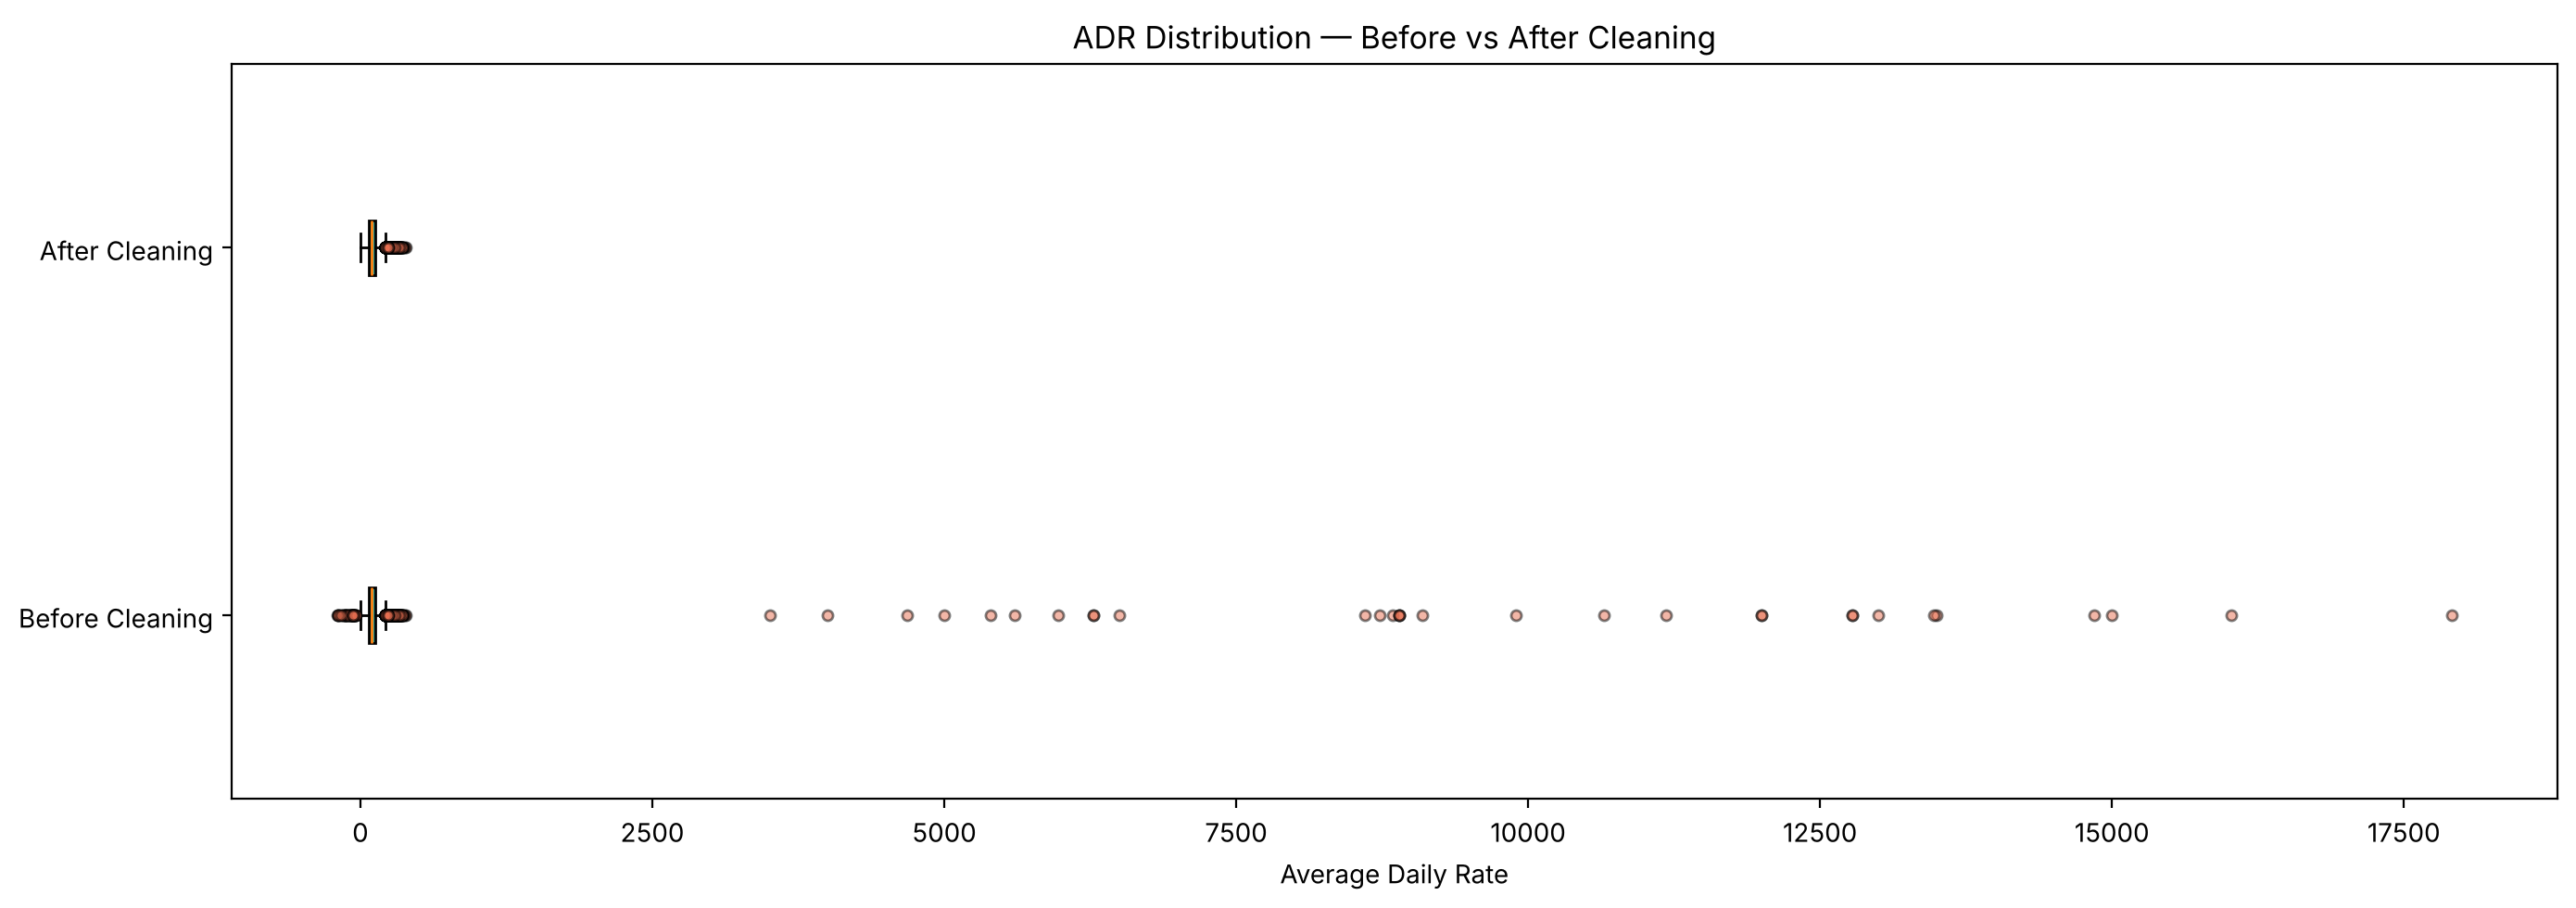

In [68]:
# Compare ADR distributions before and after treatment

plt.figure(figsize=(14, 5))

plt.boxplot(
    [
        pms_clean["adr_before_correction"].dropna(),
        pms_clean["adr"].dropna()
    ],
    vert=False,
    tick_labels=["Before Cleaning", "After Cleaning"],
    patch_artist=True,
    boxprops=dict(facecolor="#2A9D8F"),
    flierprops=dict(
        marker="o",
        markerfacecolor="#E76F51",
        markersize=4,
        alpha=0.5
    )
)

plt.title("ADR Distribution — Before vs After Cleaning")
plt.xlabel("Average Daily Rate")

plt.tight_layout()
plt.show()

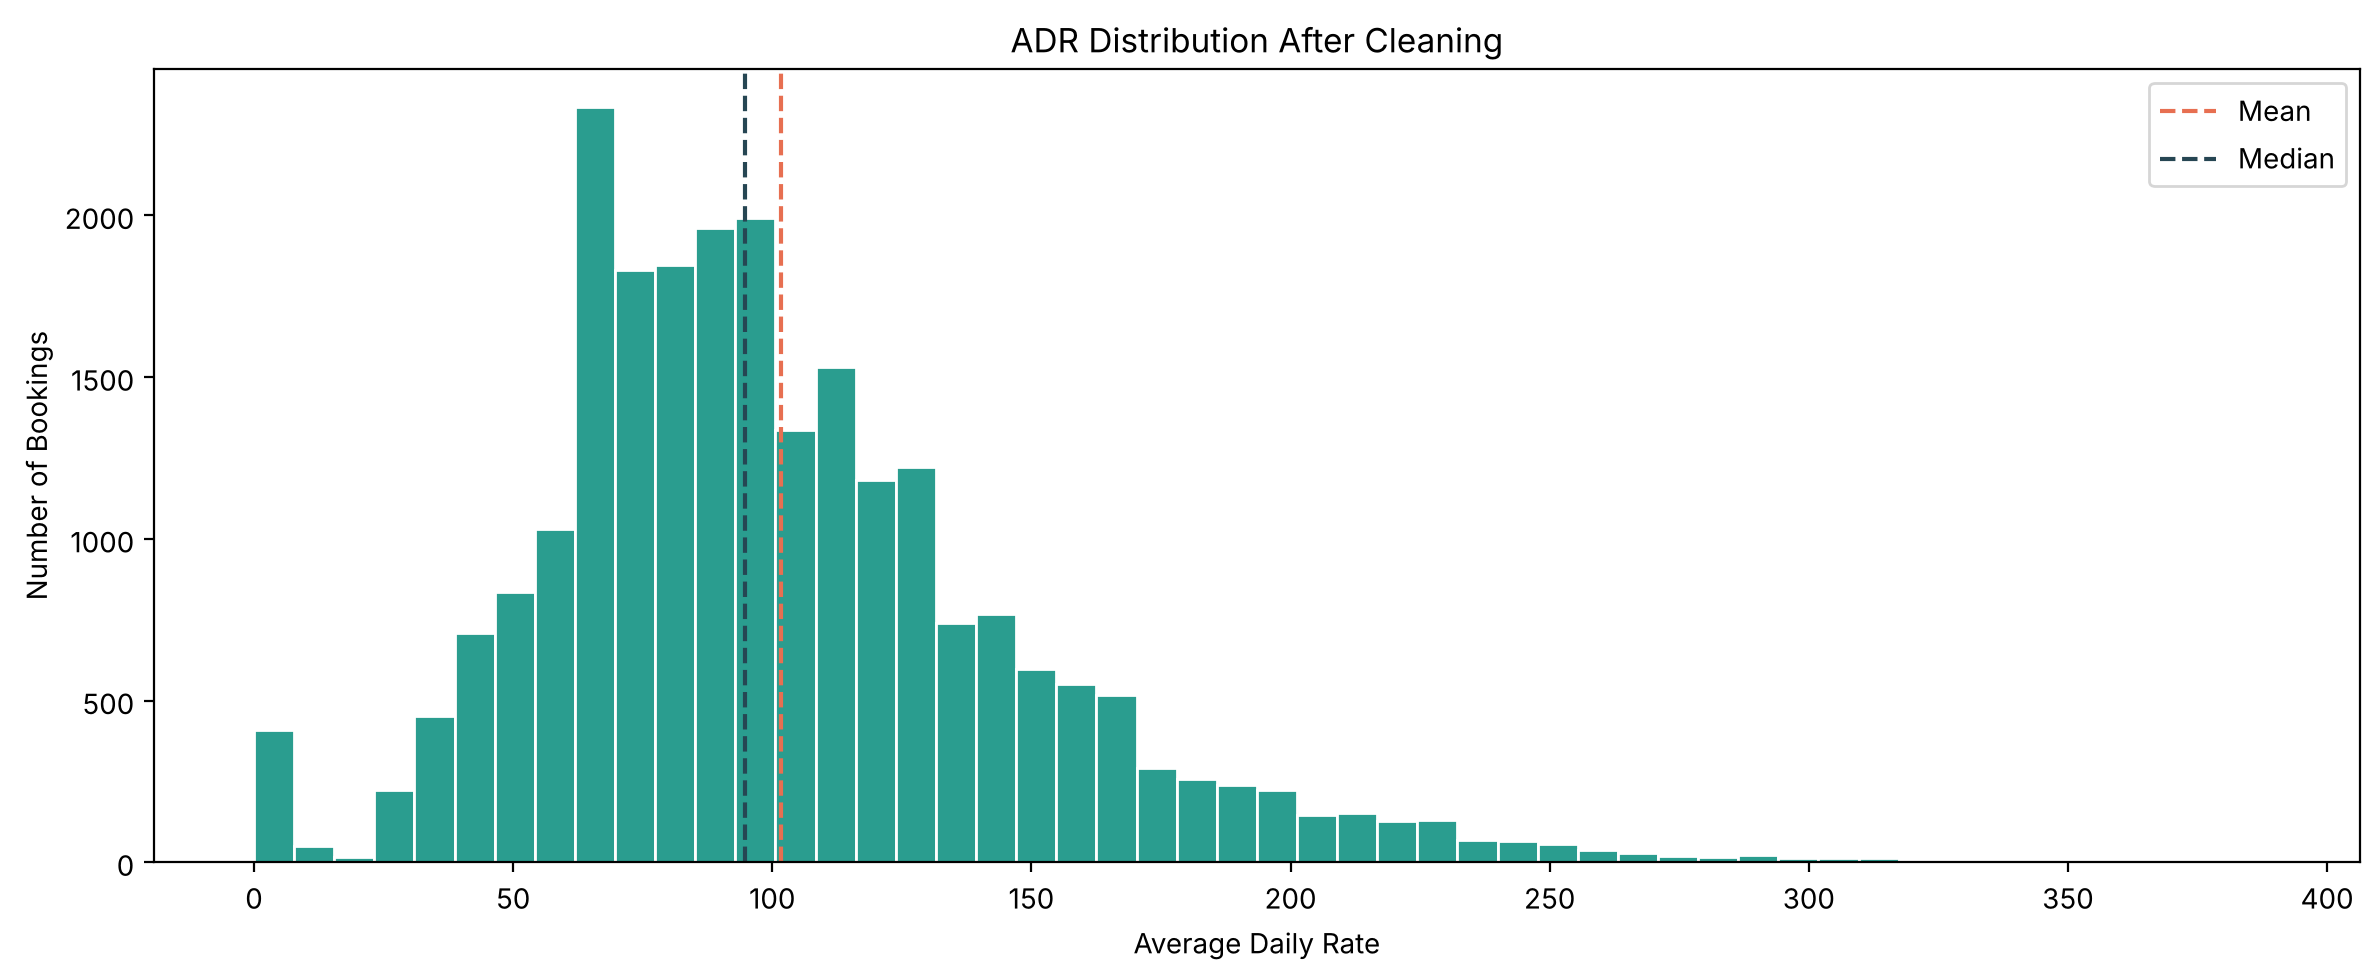

In [69]:
# Visualize the cleaned ADR distribution

plt.figure(figsize=(12, 5))

plt.hist(
    pms_clean["adr"].dropna(),
    bins=50,
    color="#2A9D8F",
    edgecolor="white"
)

plt.axvline(
    pms_clean["adr"].mean(),
    color="#E76F51",
    linestyle="--",
    label="Mean"
)

plt.axvline(
    pms_clean["adr"].median(),
    color="#264653",
    linestyle="--",
    label="Median"
)

plt.title("ADR Distribution After Cleaning")
plt.xlabel("Average Daily Rate")
plt.ylabel("Number of Bookings")
plt.legend()

plt.tight_layout()
plt.show()

#### 5.6.21 Final Observations and Cleaning Decisions

The treatment of invalid values and outliers improved
the statistical consistency of the PMS dataset while
preserving all 24,250 booking records.

Key findings:

- 35 negative weekday stay durations were identified
  and treated as missing values.

- The cancellation status was successfully standardized
  into a binary variable (0 and 1), with no missing values.

- 31 extreme ADR observations were rescaled based on
  strong evidence of a potential unit-of-measure error.

- 40 negative ADR values were treated as missing,
  resulting in 160 missing ADR observations.

- The maximum ADR decreased from 17,910 to 387.

- The ADR mean decreased from 113.76 to 101.77.

- The standard deviation decreased by approximately
  87.2%, while the median remained almost unchanged
  (94.67 before and 94.69 after cleaning).

The stability of the median and quartiles suggests
that the cleaning process reduced extreme-value
distortion without substantially altering the central
distribution.

Valid statistical outliers were not automatically
removed, as unusual observations may contain valuable
business information.

The ADR rescaling remains an inferred correction
that requires validation against the original PMS
source system.

### 5.7 Date Standardization

The arrival date is currently stored across three separate
variables: year, month and day of the month.

To support time-series analysis, seasonality assessment
and chronological comparisons, these variables will be
combined into a single standardized datetime column.

The date standardization process includes:

- Inspection of the original date components.
- Conversion of month names into numerical values.
- Construction of a unified arrival date.
- Identification of invalid calendar dates.
- Validation of the resulting datetime variable.

The original date components will be preserved to maintain
data traceability and support future analysis.

#### 5.7.2 Inspection of Date Components

Before constructing the unified arrival date, the original
date components are inspected to identify missing values,
invalid ranges and potential inconsistencies.

In [70]:
# Inspect original date components

date_columns = [
    "arrival_date_year",
    "arrival_date_month",
    "arrival_date_day_of_month"
]

display(pms_clean[date_columns].head(10))

print("Data types:")
display(pms_clean[date_columns].dtypes)

print("Missing values:")
display(pms_clean[date_columns].isna().sum())

print("Arrival years:")
display(pms_clean["arrival_date_year"].value_counts().sort_index())

print("Arrival days:")
display(pms_clean["arrival_date_day_of_month"].describe())

,arrival_date_year,arrival_date_month,arrival_date_day_of_month
0,2017,August,31
1,2017,August,29
2,2017,August,28
3,2017,August,31
4,2017,August,31
5,2017,August,31
6,2017,August,27
7,2017,August,31
8,2017,August,31
9,2017,August,28


Data types:


arrival_date_year             int64
arrival_date_month           string
arrival_date_day_of_month     int64
dtype: object

Missing values:


arrival_date_year            0
arrival_date_month           0
arrival_date_day_of_month    0
dtype: int64

Arrival years:


arrival_date_year
2015     4390
2016    11638
2017     8222
Name: count, dtype: int64

Arrival days:


count    24250.000000
mean        15.885072
std          8.772313
min          1.000000
25%          8.000000
50%         16.000000
75%         24.000000
max         31.000000
Name: arrival_date_day_of_month, dtype: float64

#### 5.7.3 Month Name Conversion

Standardized month names are mapped to their corresponding
numerical representations to enable datetime construction.

In [71]:
# Map month names to numerical values

month_mapping = {
    "January": 1,
    "February": 2,
    "March": 3,
    "April": 4,
    "May": 5,
    "June": 6,
    "July": 7,
    "August": 8,
    "September": 9,
    "October": 10,
    "November": 11,
    "December": 12
}

arrival_month_numeric = pms_clean["arrival_date_month"].map(
    month_mapping
)

print("Missing numerical months:",
      arrival_month_numeric.isna().sum())

display(arrival_month_numeric.value_counts().sort_index())

Missing numerical months: 0


arrival_date_month
1     1213
2     1633
3     1979
4     2248
5     2384
6     2227
7     2558
8     2852
9     2170
10    2291
11    1350
12    1345
Name: count, dtype: int64

#### 5.7.4 Arrival Date Construction

The year, numerical month and day components are combined
into a single datetime variable.

Invalid calendar dates are converted into missing datetime
values (NaT) to prevent incorrect date representations.

In [72]:
# Construct a unified arrival date

pms_clean["arrival_date"] = pd.to_datetime(
    pd.DataFrame({
        "year": pms_clean["arrival_date_year"],
        "month": arrival_month_numeric,
        "day": pms_clean["arrival_date_day_of_month"]
    }),
    errors="coerce"
)

display(
    pms_clean[date_columns + ["arrival_date"]].head(10)
)

,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date
0,2017,August,31,2017-08-31
1,2017,August,29,2017-08-29
2,2017,August,28,2017-08-28
3,2017,August,31,2017-08-31
4,2017,August,31,2017-08-31
5,2017,August,31,2017-08-31
6,2017,August,27,2017-08-27
7,2017,August,31,2017-08-31
8,2017,August,31,2017-08-31
9,2017,August,28,2017-08-28


#### 5.7.5 Date Validity Assessment

The constructed arrival dates are validated by checking
their data type, missing values and chronological range.

Invalid or incomplete dates are inspected before any
additional cleaning decisions are made.

In [73]:
# Validate constructed arrival dates

invalid_dates = pms_clean[
    pms_clean["arrival_date"].isna()
]

print("Arrival date data type:",
      pms_clean["arrival_date"].dtype)

print("Missing or invalid arrival dates:",
      len(invalid_dates))

print("Earliest arrival date:",
      pms_clean["arrival_date"].min())

print("Latest arrival date:",
      pms_clean["arrival_date"].max())

print("Total records:", len(pms_clean))

display(
    invalid_dates[
        ["booking_id"] + date_columns
    ].head(20)
)

Arrival date data type: datetime64[us]
Missing or invalid arrival dates: 0
Earliest arrival date: 2015-07-01 00:00:00
Latest arrival date: 2017-08-31 00:00:00
Total records: 24250


,booking_id,arrival_date_year,arrival_date_month,arrival_date_day_of_month


#### 5.7.6 Arrival Date Distribution

The distribution of bookings by arrival month is visualized
to assess chronological coverage and identify potential
temporal anomalies.

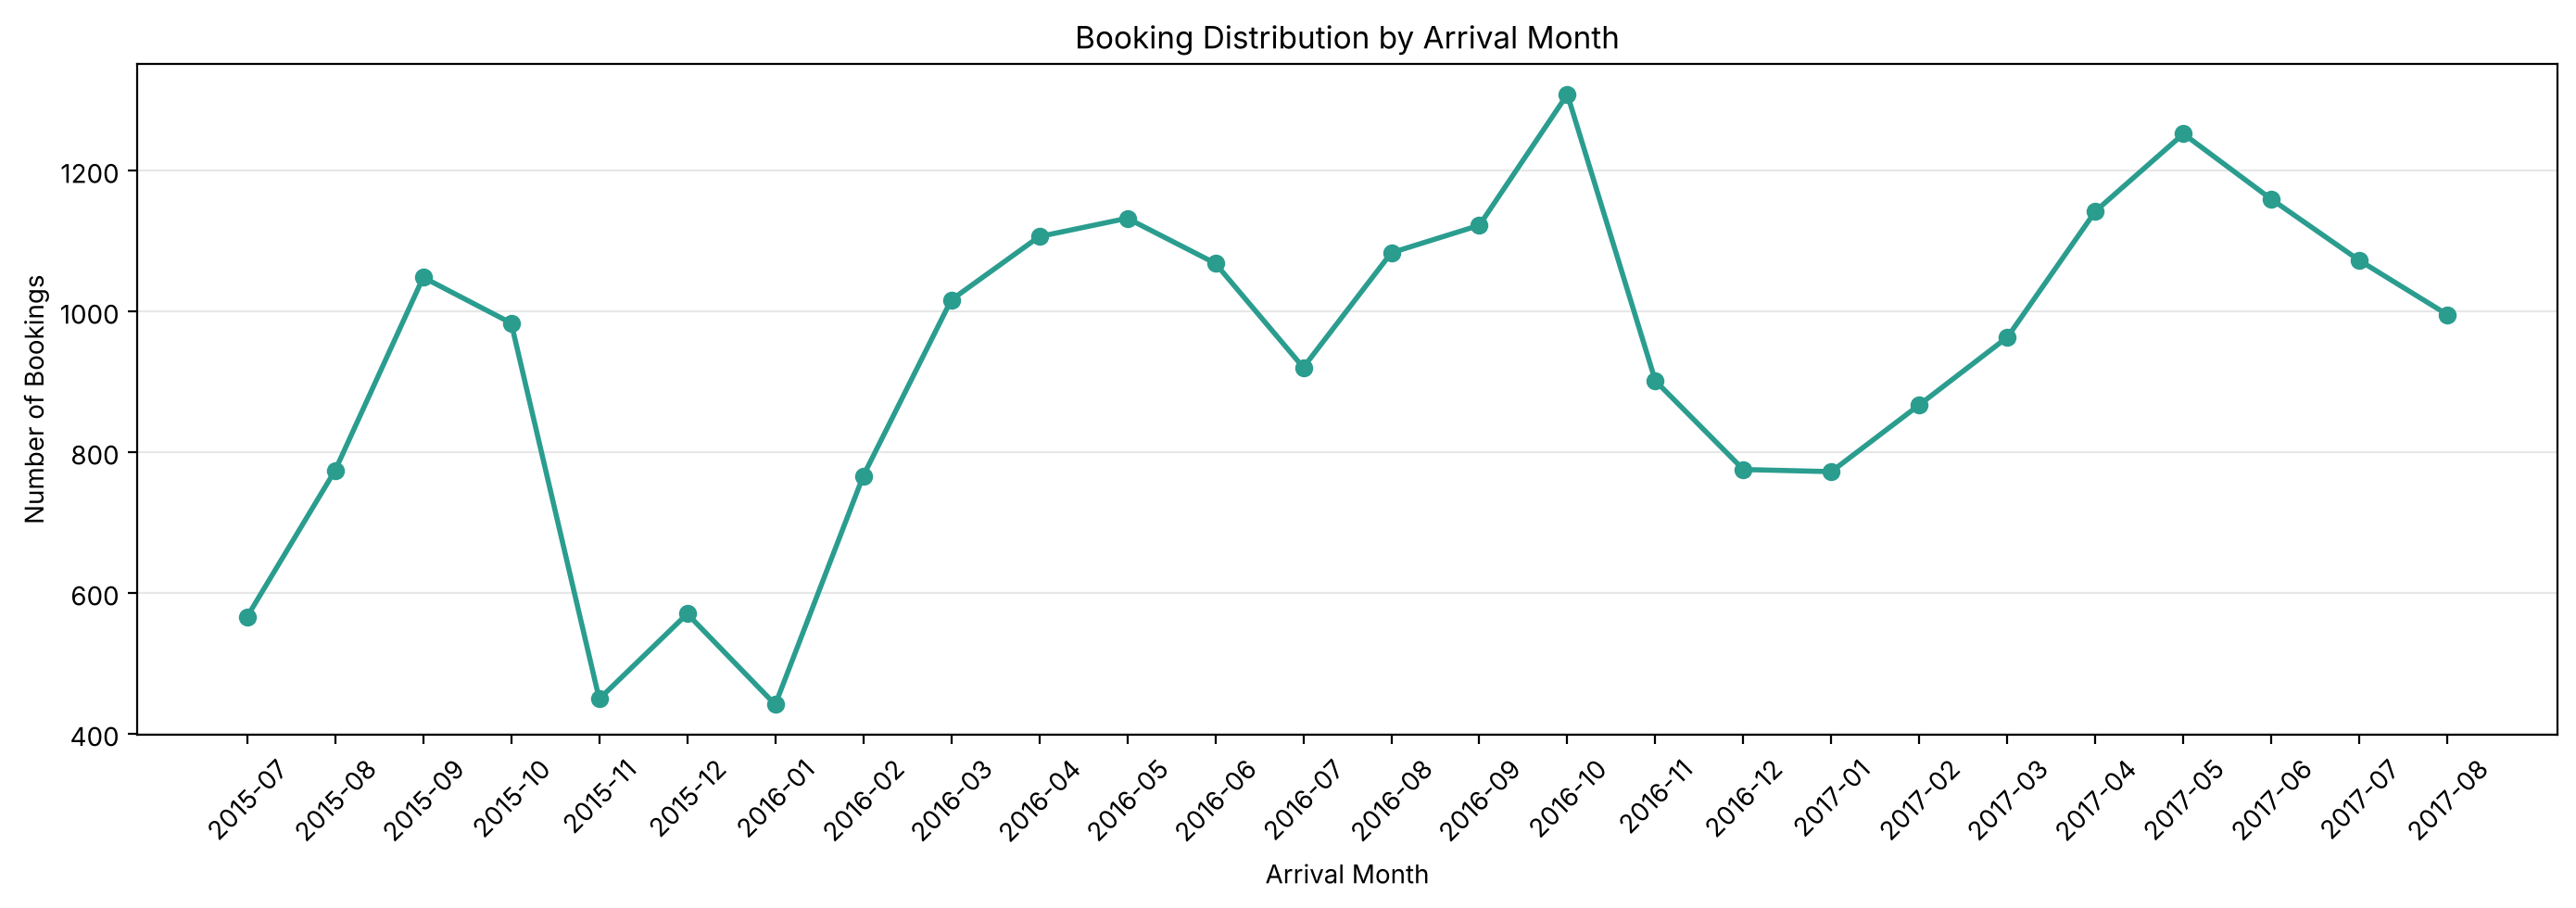

In [74]:
# Calculate monthly booking counts

monthly_bookings = (
    pms_clean.groupby(
        pms_clean["arrival_date"].dt.to_period("M")
    )
    .size()
    .sort_index()
)

# Visualize monthly booking distribution

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_bookings.index.astype(str),
    monthly_bookings.values,
    color="#2A9D8F",
    marker="o",
    linewidth=2
)

plt.title("Booking Distribution by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### 5.7.7 Final Observations

The date standardization process was successfully completed,
combining the original year, month and day components into
a single datetime variable.

Key findings:

- All 24,250 booking records were successfully converted
  into valid arrival dates.

- No missing or invalid calendar dates were identified.

- The dataset covers 26 consecutive months, from
  July 1, 2015, to August 31, 2017.

- No booking records were removed during date
  standardization.

- The original date components were preserved to
  maintain data traceability.

The monthly booking distribution shows continuous
temporal coverage and potential seasonal patterns,
with the highest booking volume observed in October 2016.

The standardized arrival_date variable provides a reliable
foundation for time-series analysis, seasonality assessment
and monthly performance comparisons.

However, booking volumes include both canceled and
non-canceled reservations and should not be interpreted
as actual hotel occupancy.

## 6. Before & After Comparison

### 6.1 Comparison Objectives

This section evaluates the overall effectiveness of the
data cleaning process by comparing the original PMS dataset
with the cleaned version.

The comparison focuses on the following data quality dimensions:

- Completeness: missing values and information availability.
- Uniqueness: duplicate records and repeated booking identifiers.
- Validity: compliance with expected data formats and values.
- Consistency: standardized categories and logical relationships.
- Data retention: preservation of valuable booking records.

The objective is to quantify the improvements achieved
during data preparation while identifying any remaining
limitations.

An increase in missing values does not necessarily indicate
a deterioration in data quality, as invalid or unreliable
observations may have been explicitly converted into
missing values during the cleaning process.

#### 6.2.1 Data Quality Metrics

A comparative summary of key data quality indicators
is constructed to evaluate the overall impact of the
cleaning process on the PMS dataset.

In [75]:
# Calculate overall data quality metrics

quality_comparison = pd.DataFrame({
    "Quality Metric": [
        "Total Records",
        "Total Variables",
        "Missing Cells",
        "Missing Cells (%)",
        "Exact Duplicate Rows",
        "Repeated Booking IDs",
        "Missing Booking IDs"
    ],

    "Before Cleaning": [
        len(pms),
        pms.shape[1],
        pms.isna().sum().sum(),
        round(pms.isna().sum().sum() / pms.size * 100, 2),
        pms.duplicated().sum(),
        pms["booking_id"].duplicated().sum(),
        pms["booking_id"].isna().sum()
    ],

    "After Cleaning": [
        len(pms_clean),
        pms_clean.shape[1],
        pms_clean.isna().sum().sum(),
        round(pms_clean.isna().sum().sum() / pms_clean.size * 100, 2),
        pms_clean.duplicated().sum(),
        pms_clean["booking_id"].duplicated().sum(),
        pms_clean["booking_id"].isna().sum()
    ]
})

display(quality_comparison)

,Quality Metric,Before Cleaning,After Cleaning
0,Total Records,24480.00,24250.00
1,Total Variables,20.00,24.00
2,Missing Cells,1305.00,1610.00
3,Missing Cells (%),0.27,0.28
4,Exact Duplicate Rows,150.00,0.00
5,Repeated Booking IDs,230.00,0.00
6,Missing Booking IDs,0.00,0.00


#### 6.2.2 Absolute and Percentage Changes

Absolute and relative changes are calculated to quantify
the impact of the cleaning process on each quality metric.

Percentage changes are reported only when the original
value is greater than zero.


In [76]:
# Calculate absolute changes

quality_comparison["Absolute Change"] = (
    quality_comparison["After Cleaning"]
    - quality_comparison["Before Cleaning"]
)

# Calculate relative percentage changes

quality_comparison["Change (%)"] = (
    quality_comparison["Absolute Change"]
    / quality_comparison["Before Cleaning"].replace(0, float("nan"))
    * 100
).round(2)

display(quality_comparison)

,Quality Metric,Before Cleaning,After Cleaning,Absolute Change,Change (%)
0,Total Records,24480.00,24250.00,-230.00,-0.94
1,Total Variables,20.00,24.00,4.00,20.00
2,Missing Cells,1305.00,1610.00,305.00,23.37
3,Missing Cells (%),0.27,0.28,0.01,3.70
4,Exact Duplicate Rows,150.00,0.00,-150.00,-100.00
5,Repeated Booking IDs,230.00,0.00,-230.00,-100.00
6,Missing Booking IDs,0.00,0.00,0.00,NaN


### 6.3 Record Retention Analysis

Record retention is evaluated to determine whether the
cleaning process preserved valuable booking information.

Only redundant records were removed during duplicate
treatment, while subsequent cleaning operations focused
on standardization, correction and explicit identification
of unreliable values rather than record deletion.

In [77]:
# Calculate record retention metrics

original_records = len(pms)
cleaned_records = len(pms_clean)

removed_records = original_records - cleaned_records

retention_rate = cleaned_records / original_records * 100

removal_rate = removed_records / original_records * 100

record_retention = pd.DataFrame({
    "Metric": [
        "Original Records",
        "Retained Records",
        "Removed Records",
        "Record Retention (%)",
        "Record Removal (%)"
    ],
    "Value": [
        original_records,
        cleaned_records,
        removed_records,
        round(retention_rate, 2),
        round(removal_rate, 2)
    ]
})

display(record_retention)

,Metric,Value
0,Original Records,24480.00
1,Retained Records,24250.00
2,Removed Records,230.00
3,Record Retention (%),99.06
4,Record Removal (%),0.94


#### 6.3.2 Record Retention Visualization

The proportion of retained and removed records is
visualized to demonstrate the limited impact of data
cleaning on the original dataset size.

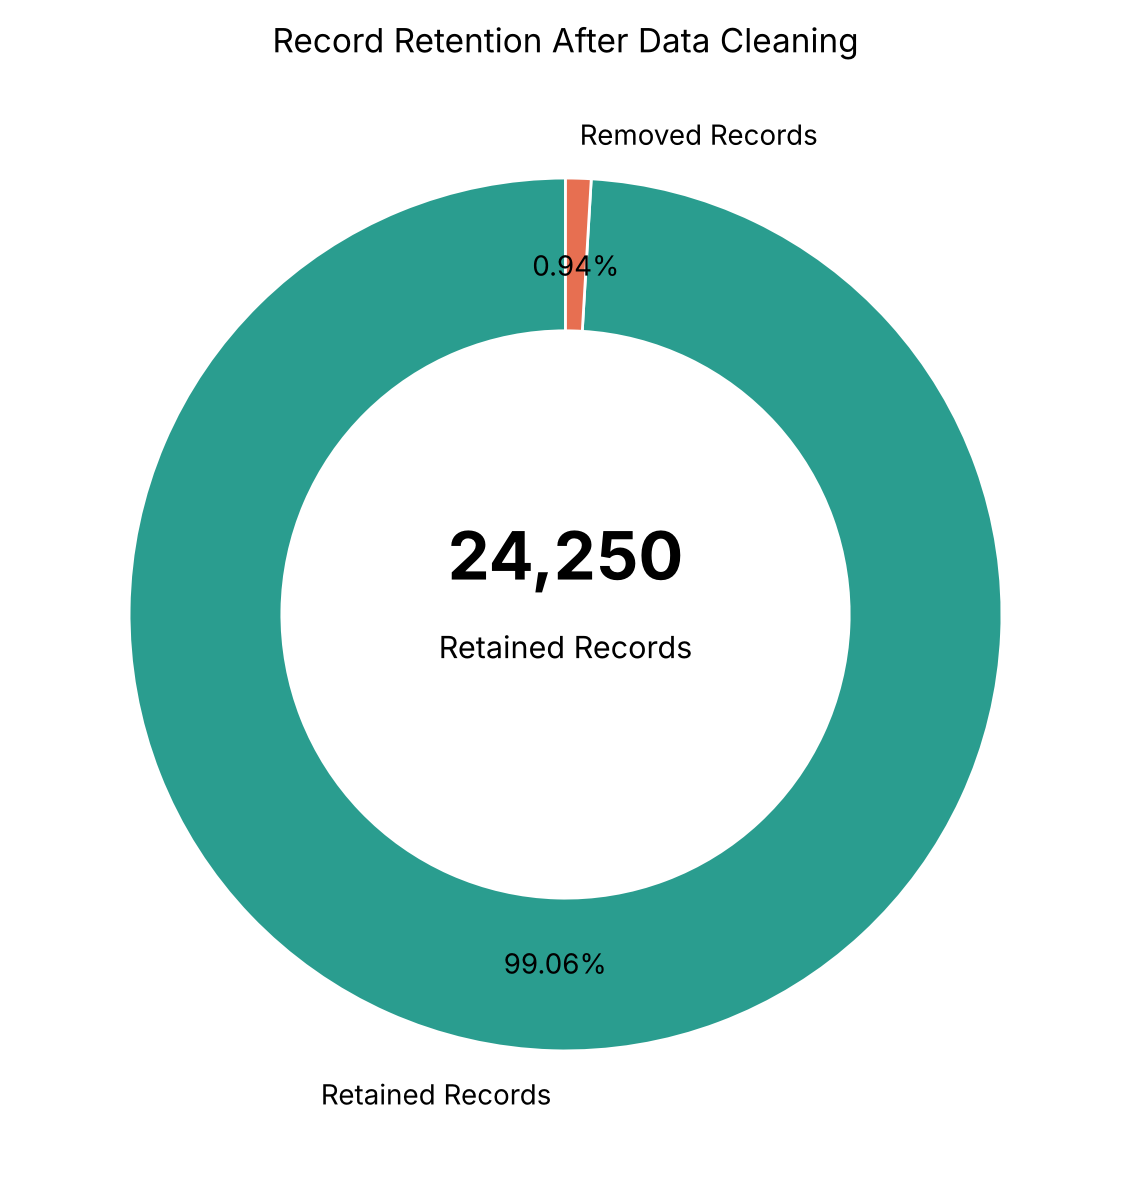

In [78]:
# Visualize record retention

plt.figure(figsize=(8, 6))

plt.pie(
    [cleaned_records, removed_records],
    labels=["Retained Records", "Removed Records"],
    colors=["#2A9D8F", "#E76F51"],
    autopct="%1.2f%%",
    startangle=90,
    pctdistance=0.80,
    wedgeprops={
        "width": 0.35,
        "edgecolor": "white"
    }
)

plt.text(
    0, 0.08,
    f"{cleaned_records:,}",
    ha="center",
    fontsize=24,
    fontweight="bold"
)

plt.text(
    0, -0.10,
    "Retained Records",
    ha="center",
    fontsize=11
)

plt.title("Record Retention After Data Cleaning")

plt.tight_layout()
plt.show()

### 6.4 Missing Values Comparison

#### 6.4.1 Missing Values Comparison by Variable

Missing values are compared before and after data cleaning
to evaluate changes in data completeness.

To ensure comparability, the analysis focuses exclusively
on variables available in both the original and cleaned
PMS datasets.

An increase in missing values may reflect an improvement
in data validity, as unreliable observations and invalid
placeholders were explicitly converted into missing values
rather than retained as misleading information.


In [79]:
# Identify common columns

common_columns = [
    col for col in pms.columns
    if col in pms_clean.columns
]

# Compare missing values before and after cleaning

missing_comparison = pd.DataFrame({
    "Before Cleaning": pms[common_columns].isna().sum(),
    "After Cleaning": pms_clean[common_columns].isna().sum()
})

# Calculate missing value percentages

missing_comparison["Before (%)"] = (
    missing_comparison["Before Cleaning"] / len(pms) * 100
)

missing_comparison["After (%)"] = (
    missing_comparison["After Cleaning"] / len(pms_clean) * 100
)

# Calculate changes

missing_comparison["Absolute Change"] = (
    missing_comparison["After Cleaning"]
    - missing_comparison["Before Cleaning"]
)

missing_comparison["Change (pp)"] = (
    missing_comparison["After (%)"]
    - missing_comparison["Before (%)"]
)

# Keep variables affected by missing values

missing_comparison = missing_comparison[
    (missing_comparison["Before Cleaning"] > 0) |
    (missing_comparison["After Cleaning"] > 0)
].sort_values("After Cleaning", ascending=False)

display(missing_comparison.round(2))

,Before Cleaning,After Cleaning,Before (%),After (%),Absolute Change,Change (pp)
children,815,810,3.33,3.34,-5,0.01
meal,490,485,2.00,2.00,-5,-0.00
adr,0,160,0.00,0.66,160,0.66
stays_in_week_nights,0,35,0.00,0.14,35,0.14


#### 6.4.2 Overall Completeness Comparison

Overall completeness is measured as the proportion of
non-missing cells across comparable variables.

This metric provides a quantitative overview of information
availability before and after data cleaning.

Completeness must be interpreted alongside validity, since
a populated but incorrect value does not represent reliable
information.

In [80]:
# Calculate missing cells across comparable variables

missing_before = pms[common_columns].isna().sum().sum()

missing_after = pms_clean[common_columns].isna().sum().sum()

# Calculate total comparable cells

cells_before = pms[common_columns].size
cells_after = pms_clean[common_columns].size

# Calculate completeness rates

completeness_before = (
    1 - missing_before / cells_before
) * 100

completeness_after = (
    1 - missing_after / cells_after
) * 100

# Create summary table

completeness_comparison = pd.DataFrame({
    "Metric": [
        "Comparable Variables",
        "Total Cells",
        "Missing Cells",
        "Missing Cells (%)",
        "Completeness (%)"
    ],
    "Before Cleaning": [
        len(common_columns),
        cells_before,
        missing_before,
        missing_before / cells_before * 100,
        completeness_before
    ],
    "After Cleaning": [
        len(common_columns),
        cells_after,
        missing_after,
        missing_after / cells_after * 100,
        completeness_after
    ]
})

display(completeness_comparison.round(2))

,Metric,Before Cleaning,After Cleaning
0,Comparable Variables,20.00,20.00
1,Total Cells,489600.00,485000.00
2,Missing Cells,1305.00,1490.00
3,Missing Cells (%),0.27,0.31
4,Completeness (%),99.73,99.69


#### 6.4.3 Missing Values Visualization

A comparative bar chart illustrates the percentage of
missing values for each affected variable before and
after data cleaning.

The visualization highlights changes in information
availability and variables requiring particular attention
during subsequent analytical activities.

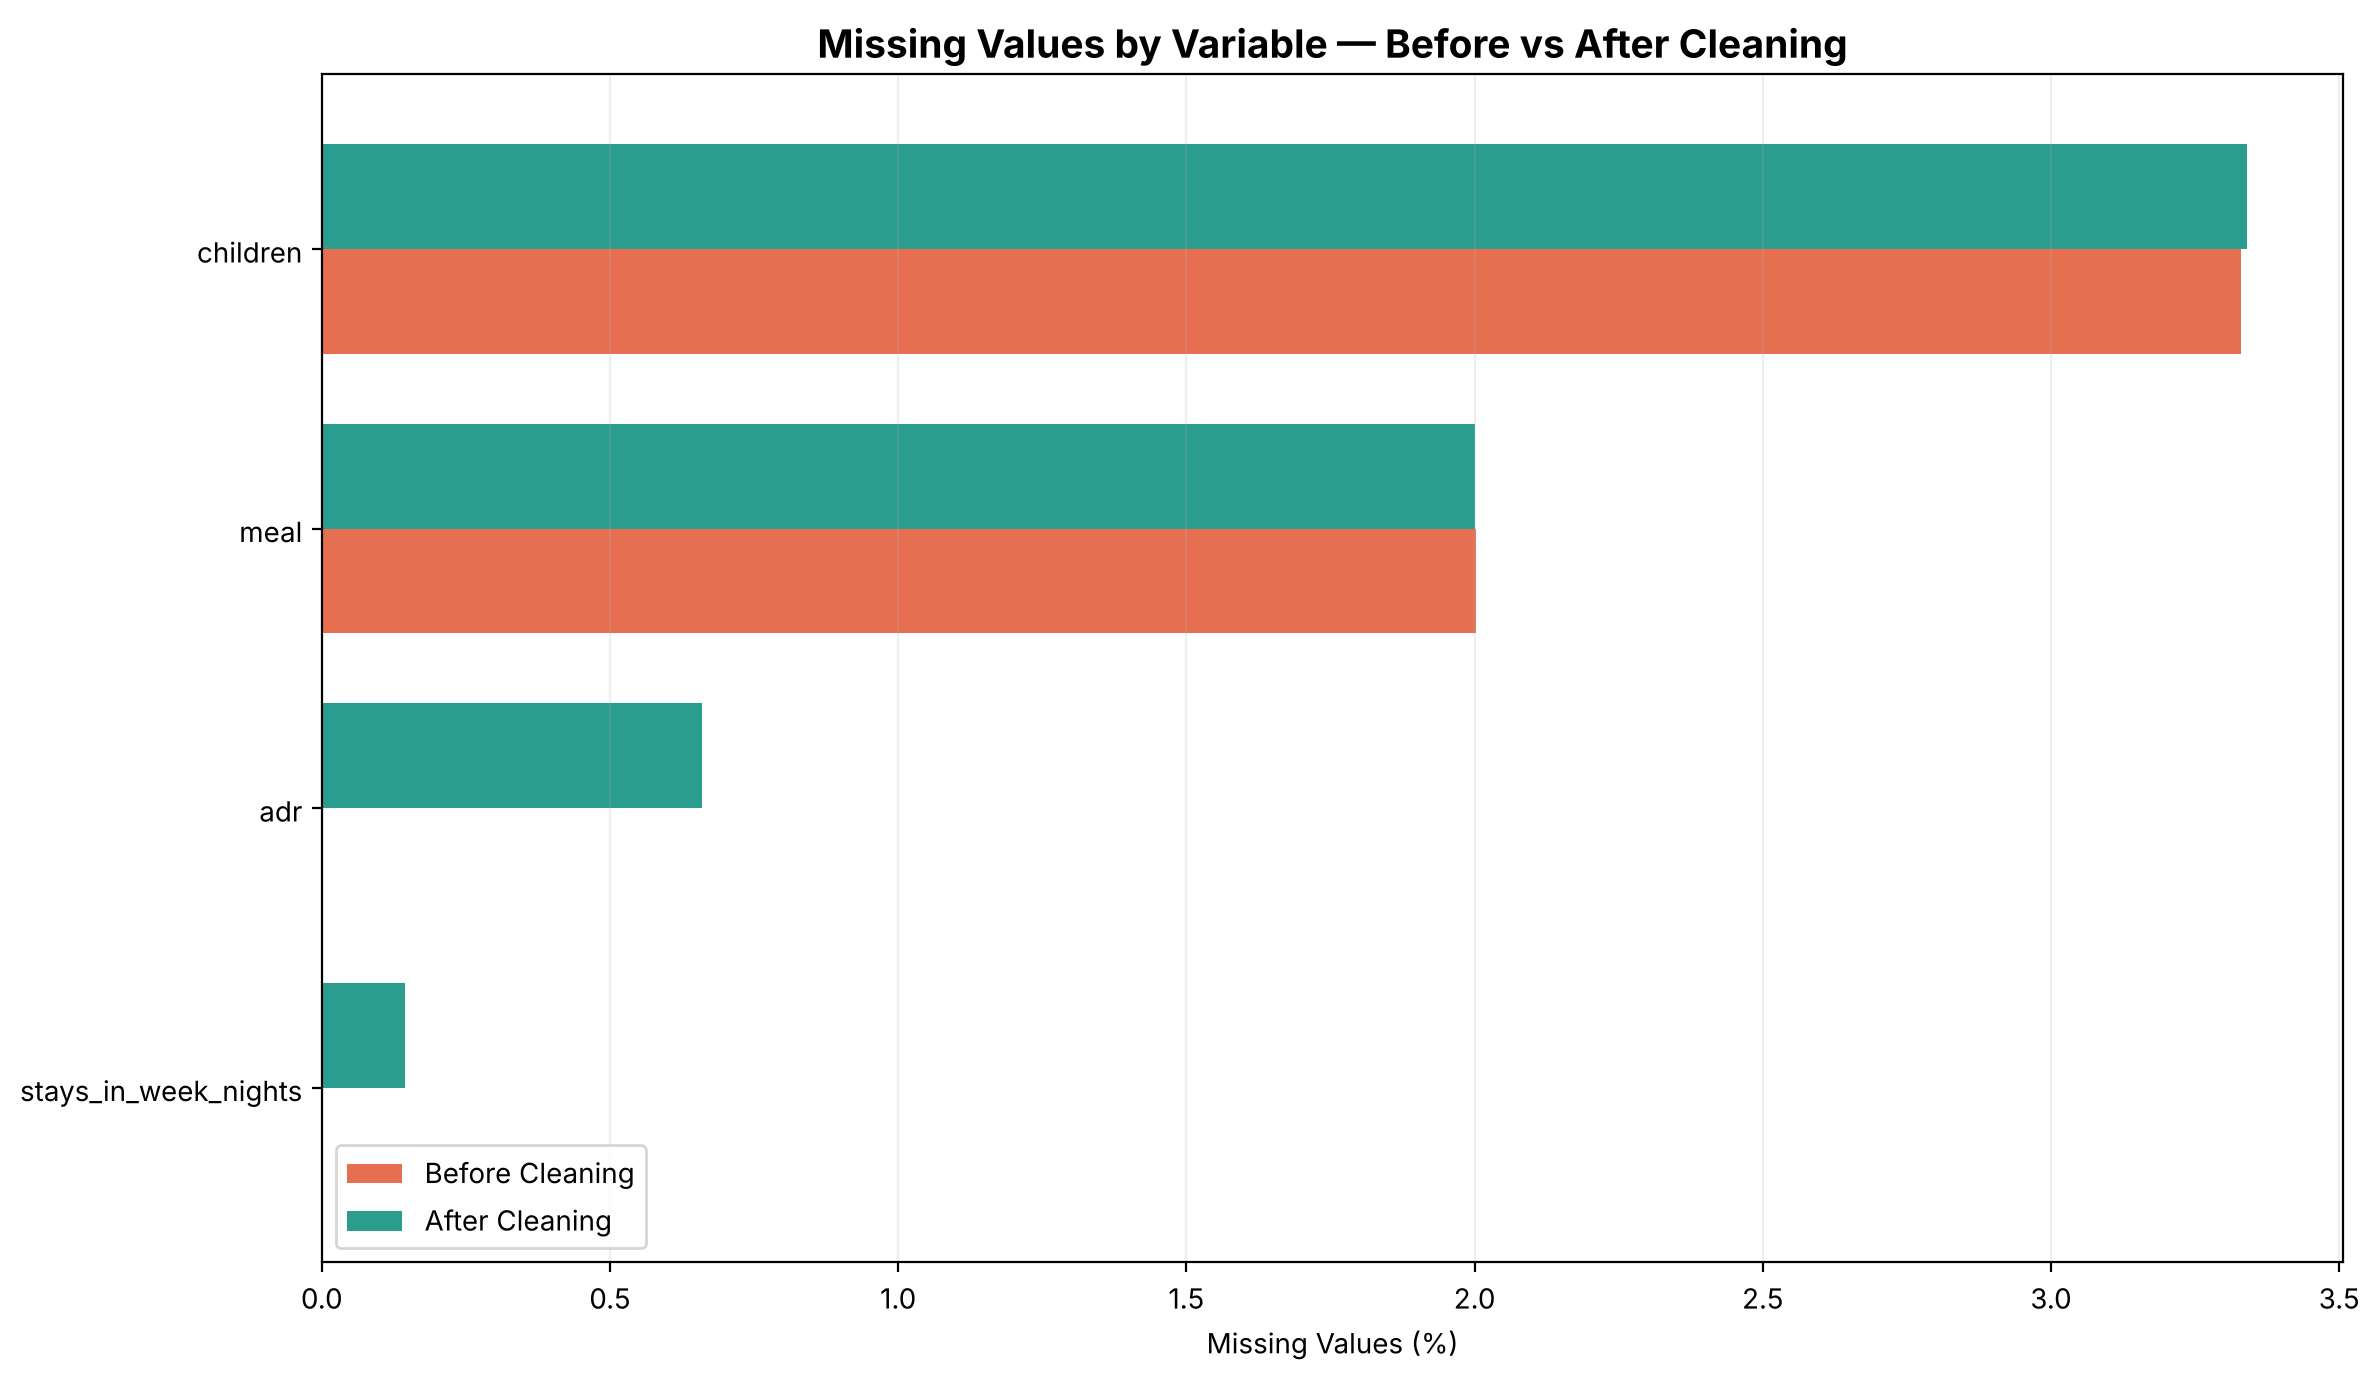

In [81]:
# Visualize missing value percentages

missing_plot = missing_comparison[
    ["Before (%)", "After (%)"]
].sort_values("After (%)")

ax = missing_plot.plot(
    kind="barh",
    figsize=(12, 7),
    color=["#E76F51", "#2A9D8F"],
    width=0.75
)

plt.title(
    "Missing Values by Variable — Before vs After Cleaning",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Missing Values (%)")
plt.ylabel("")

plt.legend(["Before Cleaning", "After Cleaning"])

plt.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

6.4.4 Interpretation of Results

The comparison reveals that overall data completeness remained exceptionally high following the cleaning process, decreasing only marginally from 99.73% to 99.69%.

The total number of missing values increased from 1,305 to 1,490 across the 20 comparable variables. This increase of 185 missing cells primarily reflects deliberate data quality improvements rather than a deterioration in information availability.

Variable-level findings:

* Children: Missing values decreased from 815 to 810 following duplicate removal. The missing rate remained substantially stable, increasing slightly from 3.33% to 3.34% due to the reduction in the total number of records.
* Meal: Missing values decreased from 490 to 485, while the missing rate remained stable at approximately 2.00%.
* ADR: A total of 160 missing values were explicitly recognized, including 120 invalid placeholders and 40 negative ADR observations. This treatment prevents unreliable pricing information from distorting financial and revenue-related analyses.
* Weeknight stays: The 35 negative stay-duration values were converted into missing values, representing only 0.14% of the cleaned dataset. This prevents invalid observations from affecting length-of-stay calculations.

Methodological considerations

The cleaning strategy deliberately prioritized data validity and reliability over artificial completeness. Missing information was not arbitrarily imputed when the original values could not be reliably reconstructed.

Although the measured completeness decreased by approximately 0.04 percentage points, the dataset now provides a more transparent representation of actual information availability.

The comparison is based on the 20 variables shared by both datasets. However, the removal of duplicate records and the initial presence of unrecognized missing-value placeholders should be considered when interpreting the results.

Business implications

The remaining missing values should be managed according to the specific requirements of subsequent analyses. Missing ADR observations may affect pricing and revenue calculations, while incomplete guest counts and stay durations may influence customer segmentation and occupancy-related metrics.

Overall, the cleaning process maintained a high level of completeness while improving the validity, transparency and analytical reliability of the PMS dataset.

### 6.5 Data Validity and Consistency Comparison

This section evaluates the effectiveness of the data cleaning
process in improving categorical validity, numerical validity
and logical consistency.

Unlike completeness, validity assesses whether recorded values
conform to expected formats, domains and business rules.

The comparison distinguishes corrected inconsistencies from
remaining uncertainties that cannot be resolved reliably
without additional information.

#### 6.5.1 Categorical Validity Comparison

Categorical variables are compared before and after cleaning
to evaluate the effectiveness of label standardization and
the consolidation of inconsistent category representations.

In [82]:
# Select comparable categorical variables

categorical_columns = [
    "hotel",
    "arrival_date_month",
    "meal",
    "reserved_room_type",
    "assigned_room_type",
    "deposit_type",
    "is_canceled"
]

# Compare unique categories before and after cleaning

categorical_validity = pd.DataFrame({
    "Before Cleaning": pms[categorical_columns].nunique(),
    "After Cleaning": pms_clean[categorical_columns].nunique()
})

# Calculate the reduction in distinct values

categorical_validity["Reduction"] = (
    categorical_validity["Before Cleaning"]
    - categorical_validity["After Cleaning"]
)

categorical_validity["Reduction (%)"] = (
    categorical_validity["Reduction"]
    / categorical_validity["Before Cleaning"] * 100
)

display(categorical_validity.round(2))

,Before Cleaning,After Cleaning,Reduction,Reduction (%)
hotel,10,2,8,80.00
arrival_date_month,47,12,35,74.47
meal,5,5,0,0.00
reserved_room_type,10,10,0,0.00
assigned_room_type,11,11,0,0.00
deposit_type,5,3,2,40.00
is_canceled,4,2,2,50.00


#### 6.5.2 Numerical Validity Comparison

Numerical validity is evaluated by comparing observations
that violate the defined numerical constraints before and
after data cleaning.

Negative guest counts, negative stay durations and negative
booking changes are incompatible with their expected meaning.

Negative ADR values and extreme pricing observations are also
evaluated according to the treatment rules established during
the data cleaning process.

In [83]:
# Define variables expected to be non-negative

non_negative_columns = [
    "adults",
    "children",
    "babies",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "booking_changes"
]

# Convert original values for numerical comparison

numeric_before = pms[non_negative_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

numeric_after = pms_clean[non_negative_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

# Compare negative values

numerical_validity = pd.DataFrame({
    "Before Cleaning": (numeric_before < 0).sum(),
    "After Cleaning": (numeric_after < 0).sum()
})

numerical_validity["Reduction"] = (
    numerical_validity["Before Cleaning"]
    - numerical_validity["After Cleaning"]
)

display(numerical_validity)

,Before Cleaning,After Cleaning,Reduction
adults,0,0,0
children,0,0,0
babies,0,0,0
stays_in_weekend_nights,0,0,0
stays_in_week_nights,35,0,35
booking_changes,0,0,0


In [84]:
# Compare ADR anomalies before and after their treatment

adr_validity = pd.DataFrame({
    "Quality Check": [
        "Negative ADR values",
        "Extreme ADR values above 3000"
    ],
    "Before Treatment": [
        40,
        31
    ],
    "After Treatment": [
        (pms_clean["adr"] < 0).sum(),
        (pms_clean["adr"] > 3000).sum()
    ]
})

adr_validity["Reduction"] = (
    adr_validity["Before Treatment"]
    - adr_validity["After Treatment"]
)

display(adr_validity)

,Quality Check,Before Treatment,After Treatment,Reduction
0,Negative ADR values,40,0,40
1,Extreme ADR values above 3000,31,0,31


#### 6.5.3 Logical Consistency Comparison

Logical consistency evaluates whether relationships between
variables are compatible with the expected business context.

The analysis focuses on bookings with zero or unknown stay
duration and bookings with zero or unknown guest counts.

These observations are not automatically removed, since some
may represent legitimate operational scenarios or incomplete
information requiring further investigation.

Unknown values are explicitly distinguished from confirmed
zero values to avoid misleading analytical conclusions.

In [85]:
# Define variables required for logical consistency checks

stay_columns = [
    "stays_in_weekend_nights",
    "stays_in_week_nights"
]

guest_columns = [
    "adults",
    "children",
    "babies"
]

# Calculate original stay duration

total_nights_before = pms[stay_columns].apply(
    pd.to_numeric,
    errors="coerce"
).sum(axis=1, min_count=2)

# Calculate cleaned stay duration

total_nights_after = pms_clean[stay_columns].sum(
    axis=1,
    min_count=2
)

# Calculate original guest count

total_guests_before = pms[guest_columns].apply(
    pd.to_numeric,
    errors="coerce"
).sum(axis=1, min_count=3)

# Calculate cleaned guest count

total_guests_after = pms_clean[guest_columns].sum(
    axis=1,
    min_count=3
)

# Compare logical consistency checks

logical_comparison = pd.DataFrame({
    "Quality Check": [
        "Zero-night bookings",
        "Unknown stay duration",
        "Zero-guest bookings",
        "Unknown guest count"
    ],
    "Before Cleaning": [
        (total_nights_before == 0).sum(),
        total_nights_before.isna().sum(),
        (total_guests_before == 0).sum(),
        total_guests_before.isna().sum()
    ],
    "After Cleaning": [
        (total_nights_after == 0).sum(),
        total_nights_after.isna().sum(),
        (total_guests_after == 0).sum(),
        total_guests_after.isna().sum()
    ]
})

logical_comparison["Change"] = (
    logical_comparison["After Cleaning"]
    - logical_comparison["Before Cleaning"]
)

logical_comparison["Before (%)"] = (
    logical_comparison["Before Cleaning"] / len(pms) * 100
)

logical_comparison["After (%)"] = (
    logical_comparison["After Cleaning"] / len(pms_clean) * 100
)

display(logical_comparison.round(2))

,Quality Check,Before Cleaning,After Cleaning,Change,Before (%),After (%)
0,Zero-night bookings,159,147,-12,0.65,0.61
1,Unknown stay duration,0,35,35,0.00,0.14
2,Zero-guest bookings,31,31,0,0.13,0.13
3,Unknown guest count,815,810,-5,3.33,3.34


#### 6.5.4 Validity Improvement Summary

A consolidated summary presents the main validity improvements
achieved during data cleaning.

The evaluation focuses on measurable inconsistencies addressed
through categorical standardization, numerical correction
and explicit treatment of invalid observations.

Remaining business ambiguities are evaluated separately
and are not automatically classified as data errors.

In [86]:
# Consolidate main validity improvements

validity_summary = pd.DataFrame({
    "Quality Issue": [
        "Excess hotel categories",
        "Excess arrival month categories",
        "Excess deposit type categories",
        "Excess cancellation categories",
        "Negative weeknight stays",
        "Negative ADR values",
        "Extreme ADR values above 3000"
    ],
    "Before": [
        max(pms["hotel"].nunique() - 2, 0),
        max(pms["arrival_date_month"].nunique() - 12, 0),
        max(pms["deposit_type"].nunique() - 3, 0),
        max(pms["is_canceled"].nunique() - 2, 0),
        numerical_validity.loc[
            "stays_in_week_nights", "Before Cleaning"
        ],
        adr_validity.loc[0, "Before Treatment"],
        adr_validity.loc[1, "Before Treatment"]
    ],
    "After": [
        max(pms_clean["hotel"].nunique() - 2, 0),
        max(pms_clean["arrival_date_month"].nunique() - 12, 0),
        max(pms_clean["deposit_type"].nunique() - 3, 0),
        max(pms_clean["is_canceled"].nunique() - 2, 0),
        numerical_validity.loc[
            "stays_in_week_nights", "After Cleaning"
        ],
        adr_validity.loc[0, "After Treatment"],
        adr_validity.loc[1, "After Treatment"]
    ]
})

# Calculate improvement percentage

validity_summary["Reduction (%)"] = (
    (validity_summary["Before"] - validity_summary["After"])
    / validity_summary["Before"].replace(0, np.nan) * 100
)

display(validity_summary.round(2))

,Quality Issue,Before,After,Reduction (%)
0,Excess hotel categories,8,0,100.0
1,Excess arrival month categories,35,0,100.0
2,Excess deposit type categories,2,0,100.0
3,Excess cancellation categories,2,0,100.0
4,Negative weeknight stays,35,0,100.0
5,Negative ADR values,40,0,100.0
6,Extreme ADR values above 3000,31,0,100.0


### 6.6 Data Quality Improvements Visualization

This section provides a visual synthesis of the main
improvements achieved throughout the data cleaning process.

The visualizations focus on record preservation, categorical
standardization and numerical validity, highlighting the
effectiveness of the cleaning strategy.

#### 6.6.1 Record Retention Visualization

The record retention analysis illustrates the proportion
of original bookings preserved after data cleaning.

Preserving valid observations while removing redundant
records helps maintain the analytical value of the dataset.

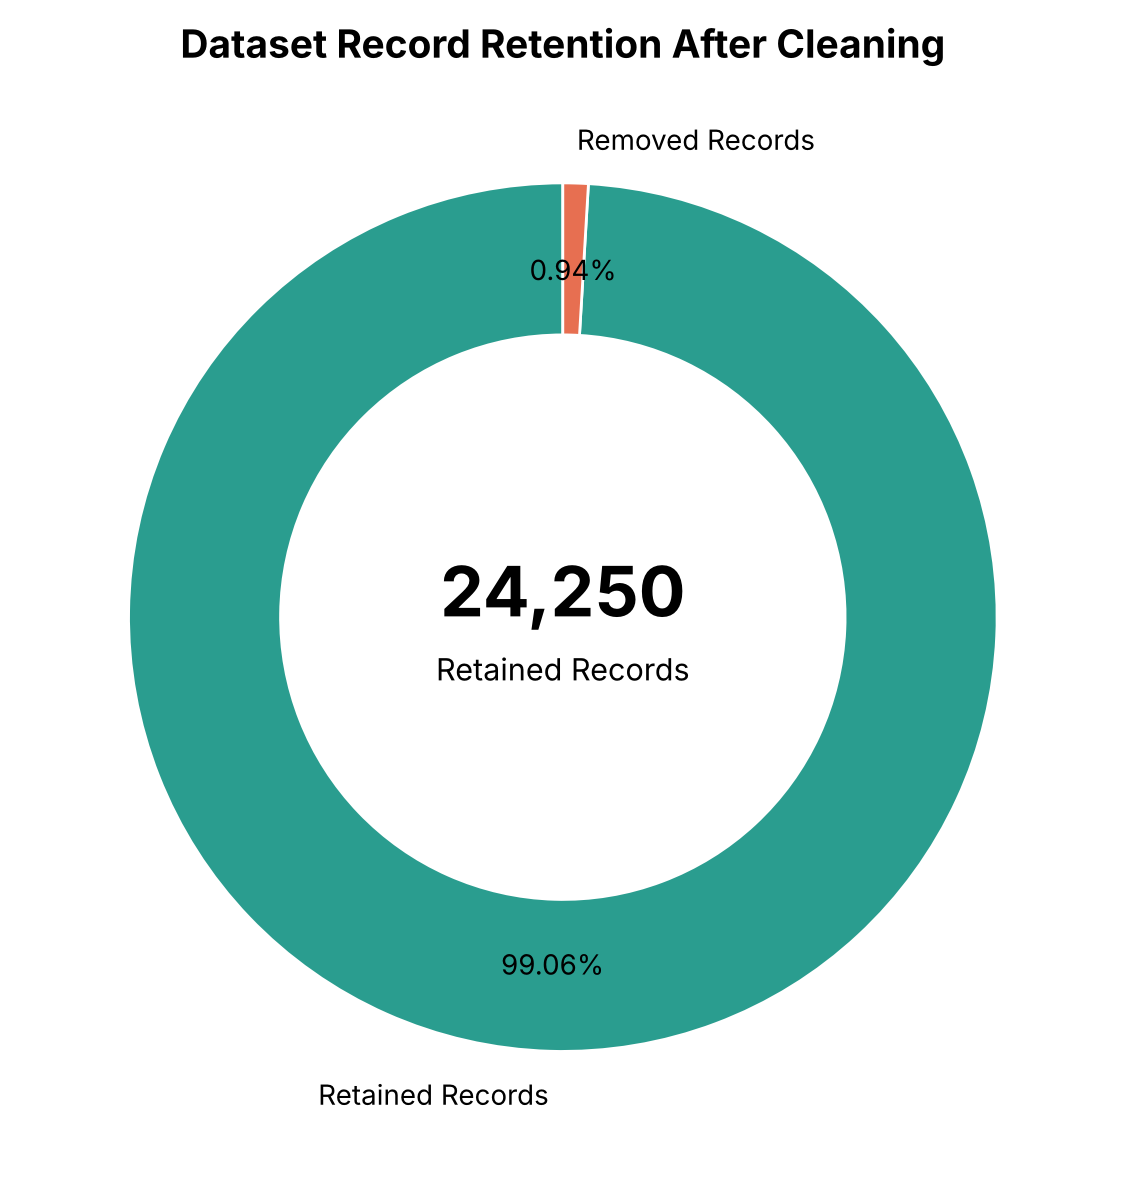

Original records: 24,480
Retained records: 24,250
Removed records: 230
Retention rate: 99.06%


In [87]:
# Calculate retained and removed records

original_records = len(pms)
retained_records = len(pms_clean)
removed_records = original_records - retained_records

retention_rate = retained_records / original_records * 100

# Create record retention visualization

fig, ax = plt.subplots(figsize=(8, 6))

ax.pie(
    [retained_records, removed_records],
    labels=["Retained Records", "Removed Records"],
    colors=["#2A9D8F", "#E76F51"],
    autopct="%1.2f%%",
    startangle=90,
    pctdistance=0.80,
    wedgeprops={
        "width": 0.35,
        "edgecolor": "white"
    }
)

# Add retained records at the center

ax.text(
    0, 0.06,
    f"{retained_records:,}",
    ha="center",
    va="center",
    fontsize=25,
    fontweight="bold"
)

ax.text(
    0, -0.12,
    "Retained Records",
    ha="center",
    va="center",
    fontsize=11
)

plt.title(
    "Dataset Record Retention After Cleaning",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print(f"Original records: {original_records:,}")
print(f"Retained records: {retained_records:,}")
print(f"Removed records: {removed_records:,}")
print(f"Retention rate: {retention_rate:.2f}%")

#### 6.6.2 Categorical Standardization Improvements

Categorical standardization reduced inconsistent
representations of equivalent business categories.

The visualization focuses on the number of excess
category labels eliminated, highlighting the
variables most affected by formatting inconsistencies.

This improvement supports more reliable grouping,
filtering and aggregation in subsequent analyses.

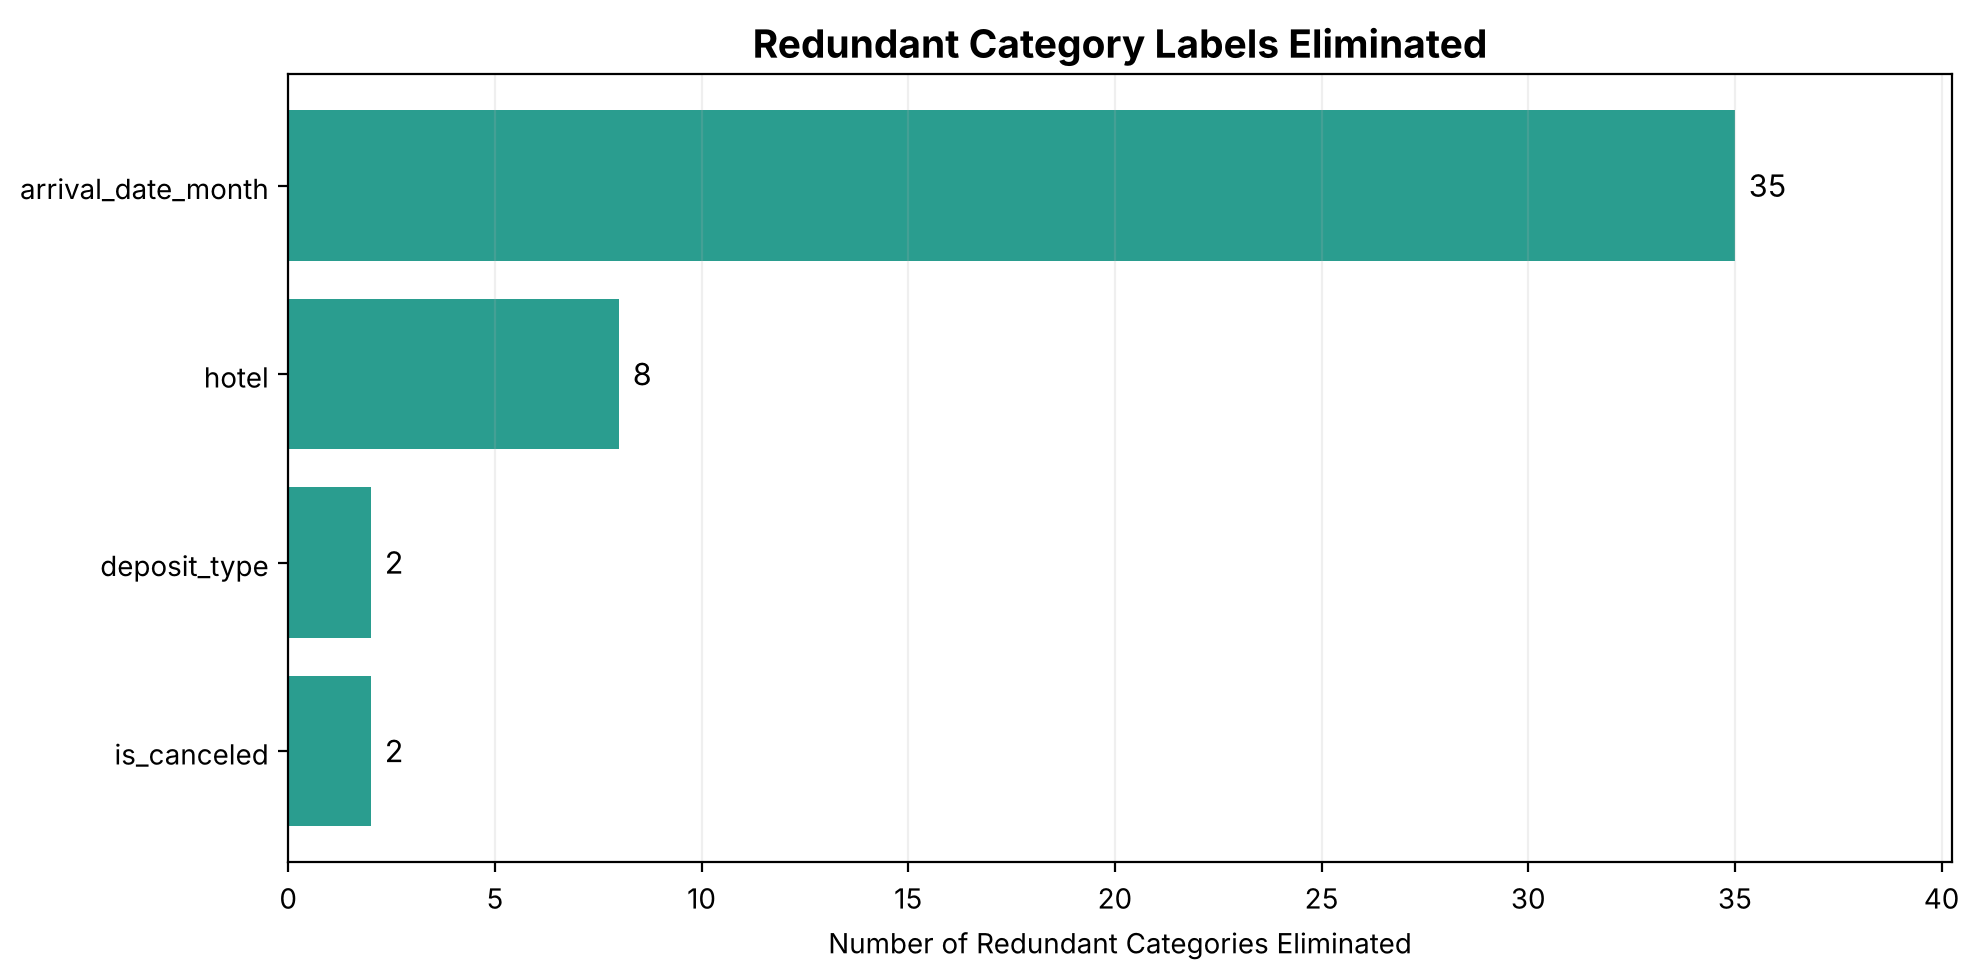

In [88]:
# Select variables affected by categorical standardization

categorical_improvements = categorical_validity[
    categorical_validity["Reduction"] > 0
]["Reduction"].sort_values()

# Create horizontal bar chart

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    categorical_improvements.index,
    categorical_improvements.values,
    color="#2A9D8F"
)

# Add value labels

ax.bar_label(
    bars,
    padding=5,
    fontsize=11
)

plt.title(
    "Redundant Category Labels Eliminated",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Redundant Categories Eliminated")
plt.ylabel("")

plt.xlim(0, categorical_improvements.max() * 1.15)

plt.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

#### 6.6.3 Numerical Validity Improvements

Numerical validity improvements are visualized
to demonstrate the treatment of invalid placeholders,
negative observations and extreme pricing anomalies.

The comparison highlights the number of affected
observations before and after the relevant treatments.

Invalid values that could not be reliably reconstructed
were converted into explicit missing values, while
extreme ADR observations were rescaled based on the
identified pattern of potential decimal-place errors.

In [89]:
# Create numerical quality improvement summary

numerical_improvements = pd.DataFrame({
    "Quality Issue": [
        "Invalid ADR placeholders",
        "Negative ADR values",
        "Negative weeknight stays",
        "Extreme ADR values (>3000)"
    ],
    "Before Treatment": [
        120,
        40,
        35,
        31
    ],
    "After Treatment": [
        0,
        (pms_clean["adr"] < 0).sum(),
        (pms_clean["stays_in_week_nights"] < 0).sum(),
        (pms_clean["adr"] > 3000).sum()
    ]
})

display(numerical_improvements)

,Quality Issue,Before Treatment,After Treatment
0,Invalid ADR placeholders,120,0
1,Negative ADR values,40,0
2,Negative weeknight stays,35,0
3,Extreme ADR values (>3000),31,0


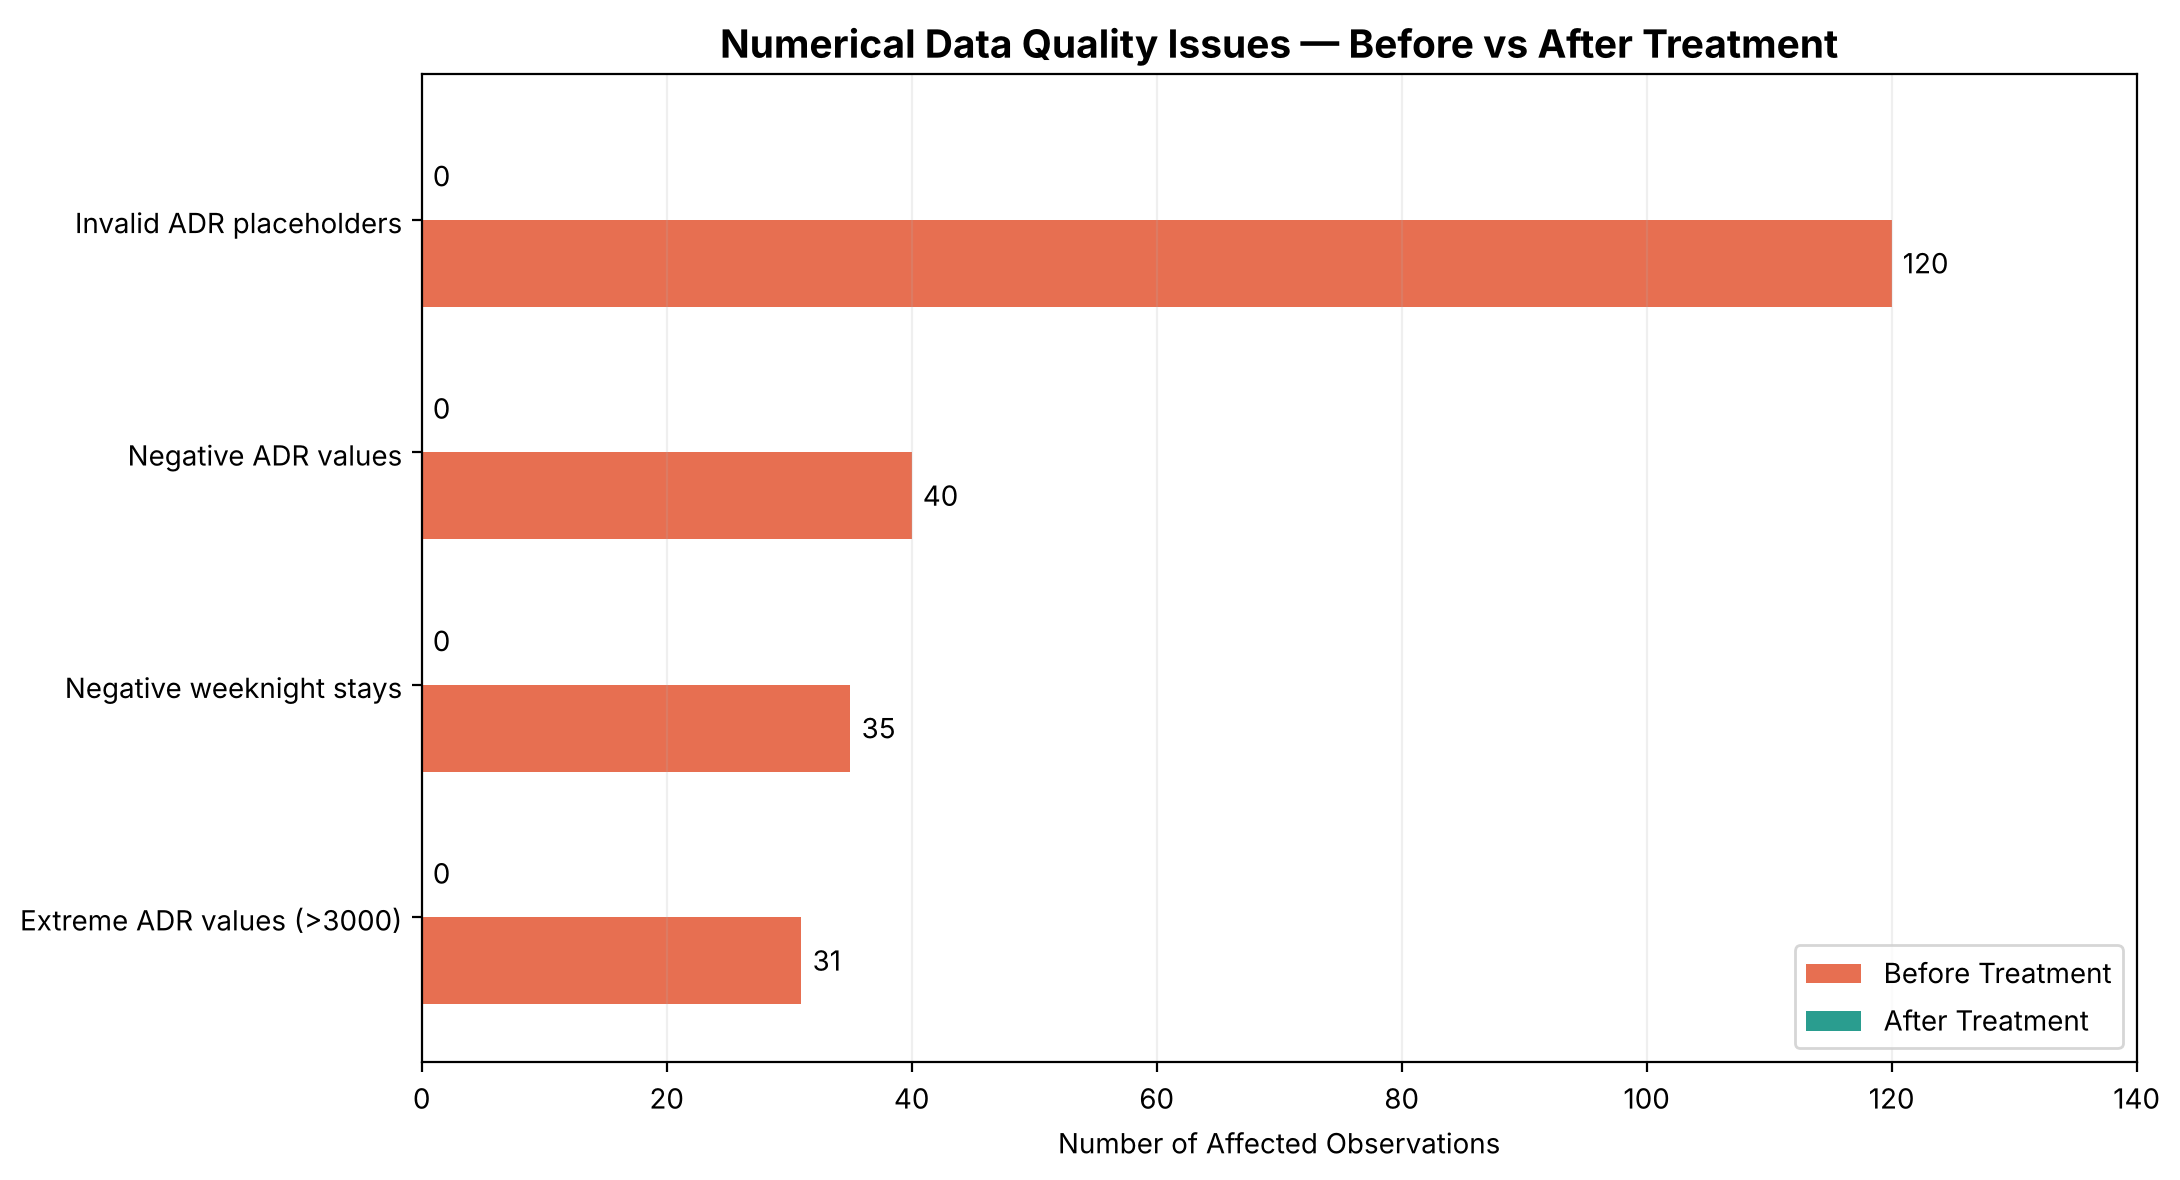

In [90]:
# Prepare data for visualization

numerical_plot = numerical_improvements.set_index(
    "Quality Issue"
).sort_values("Before Treatment")

# Create comparative horizontal bar chart

ax = numerical_plot.plot(
    kind="barh",
    figsize=(11, 6),
    color=["#E76F51", "#2A9D8F"],
    width=0.75
)

# Add value labels

for container in ax.containers:
    ax.bar_label(container, padding=4)

plt.title(
    "Numerical Data Quality Issues — Before vs After Treatment",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Affected Observations")
plt.ylabel("")

plt.xlim(0, 140)

plt.legend(
    ["Before Treatment", "After Treatment"],
    loc="lower right"
)

plt.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

6.6.4 Interpretation of Results

The visual analysis highlights three major achievements of the data cleaning process: record preservation, categorical standardization and numerical validity improvement.

Record preservation

The cleaning process retained 24,250 out of 24,480 original records, corresponding to a retention rate of 99.06%. Only 0.94% of the original records were removed through duplicate treatment, preserving the analytical value of the dataset.

Categorical standardization

A total of 47 redundant category representations were eliminated across four categorical variables. The most substantial improvement occurred in the arrival month variable, where 47 distinct representations were standardized into the 12 expected calendar months.

These improvements reduce artificial fragmentation and support more reliable aggregation, segmentation and temporal analysis.

Numerical validity

A total of 226 affected numerical cells were addressed through targeted cleaning interventions. Among these, 195 invalid or unreliable values were converted into explicit missing values, while 31 extreme ADR observations were rescaled based on a plausible decimal-place error pattern.

Following treatment, no negative ADR values, negative weeknight stays or ADR observations above 3,000 remained in the cleaned dataset.

Overall assessment

The visual evidence demonstrates that substantial improvements in data consistency and numerical validity were achieved while preserving 99.06% of the original records and maintaining an overall completeness rate of 99.69%.

The cleaning strategy therefore prioritized analytical reliability, information preservation and methodological transparency rather than indiscriminate record removal or arbitrary imputation.

Nevertheless, the inferred ADR corrections and remaining missing information should be acknowledged when interpreting subsequent business analyses.

### 6.7 Remaining Data Quality Limitations

Despite the substantial improvements achieved during
the cleaning process, several data quality limitations
remain in the dataset.

These limitations are explicitly documented to ensure
methodological transparency and responsible interpretation
of subsequent business analyses.

#### 6.7.1 Remaining Missing Values

Missing values remain in selected variables because
the available information does not support reliable
reconstruction.

Rather than introducing potentially misleading values
through arbitrary imputation, missing observations
were preserved and documented.

In [91]:
# Identify remaining missing values

remaining_missing = pd.DataFrame({
    "Missing Values": pms_clean.isna().sum(),
    "Missing (%)": pms_clean.isna().mean() * 100
})

# Select affected variables

remaining_missing = remaining_missing[
    remaining_missing["Missing Values"] > 0
].sort_values("Missing Values", ascending=False)

# Identify available observations

remaining_missing["Available Records"] = (
    len(pms_clean) - remaining_missing["Missing Values"]
)

remaining_missing["Completeness (%)"] = (
    100 - remaining_missing["Missing (%)"]
)

display(remaining_missing.round(2))

,Missing Values,Missing (%),Available Records,Completeness (%)
children,810,3.34,23440,96.66
meal,485,2.00,23765,98.00
adr,160,0.66,24090,99.34
adr_before_correction,120,0.49,24130,99.51
stays_in_week_nights,35,0.14,24215,99.86


The remaining missing values in the operational variables
are concentrated in four columns: children, meal, ADR
and weekday stay duration.

The children variable presents the highest missing rate
(3.34%), followed by meal (2.00%), ADR (0.66%) and
weekday stay duration (0.14%).

The auxiliary variable adr_before_correction contains
120 missing values (0.49%). This variable was retained
for auditing and traceability purposes and is not intended
for subsequent business calculations.

Although overall dataset completeness remains high,
the analytical impact of missing information depends
on the specific business question being investigated.

Missing values should therefore be handled according
to the requirements of each subsequent analysis,
rather than through a uniform imputation strategy.

#### 6.7.2 Remaining Logical Inconsistencies

Certain potentially inconsistent booking characteristics
remain in the cleaned dataset.

These observations were retained because their underlying
business context could not be reliably established from
the available information.

The following assessment distinguishes between unusual
booking characteristics and incomplete information
concerning stay duration and guest composition.


In [92]:
# Calculate total stay duration

total_nights_check = (
    pms_clean["stays_in_weekend_nights"] +
    pms_clean["stays_in_week_nights"]
)

# Calculate total guest count

total_guests_check = (
    pms_clean["adults"] +
    pms_clean["children"] +
    pms_clean["babies"]
)

# Summarize remaining logical consistency issues

remaining_logical_issues = pd.DataFrame({
    "Quality Issue": [
        "Zero-night bookings",
        "Unknown stay duration",
        "Zero-guest bookings",
        "Unknown guest count"
    ],
    "Affected Records": [
        (total_nights_check == 0).sum(),
        total_nights_check.isna().sum(),
        (total_guests_check == 0).sum(),
        total_guests_check.isna().sum()
    ]
})

# Calculate percentage of affected records

remaining_logical_issues["Affected Records (%)"] = (
    remaining_logical_issues["Affected Records"] /
    len(pms_clean) * 100
)

display(remaining_logical_issues.round(2))

,Quality Issue,Affected Records,Affected Records (%)
0,Zero-night bookings,147,0.61
1,Unknown stay duration,35,0.14
2,Zero-guest bookings,31,0.13
3,Unknown guest count,810,3.34


A limited number of bookings present unusual or incomplete
stay duration and guest composition characteristics.

Zero-night bookings may represent day-use reservations,
administrative records or other operational exceptions.

Similarly, zero-guest bookings may reflect administrative
reservations or incomplete booking information.

However, these explanations cannot be confirmed using
the available dataset alone.

Unknown stay durations and guest counts result from
missing information in their underlying variables.

These observations were retained to preserve information
and avoid introducing unsupported assumptions.

Their inclusion in subsequent analyses should depend
on the specific business question and the validity
requirements of each KPI.

#### 6.7.3 Assumptions and Uncertainty in ADR Corrections

The correction of extreme ADR values was based on
an evidence-supported assumption of a decimal scaling
error.

The identification of 31 observations above 3,000,
combined with a substantial discontinuity in the ADR
distribution, suggested a potential factor-of-100
inconsistency.

Dividing these observations by 100 produced values
consistent with the broader pricing distribution.

However, without access to the original PMS transaction
records or confirmation from the data provider, the
true intended values cannot be independently verified.

The correction should therefore be considered a
plausible and documented reconstruction rather than
a confirmed recovery of the original values.

In [93]:
# Identify rescaled ADR observations

rescaled_mask = pms_clean["adr_before_correction"] > 3000

rescaled_count = rescaled_mask.sum()

# Summarize the impact of the ADR rescaling

adr_correction_audit = pd.DataFrame({
    "Metric": [
        "Total booking records",
        "Rescaled ADR observations",
        "Affected records (%)",
        "Mean ADR before rescaling",
        "Mean ADR after rescaling",
        "Minimum rescaled ADR",
        "Maximum rescaled ADR"
    ],
    "Value": [
        len(pms_clean),
        rescaled_count,
        rescaled_count / len(pms_clean) * 100,
        pms_clean.loc[
            rescaled_mask, "adr_before_correction"
        ].mean(),
        pms_clean.loc[
            rescaled_mask, "adr"
        ].mean(),
        pms_clean.loc[
            rescaled_mask, "adr"
        ].min(),
        pms_clean.loc[
            rescaled_mask, "adr"
        ].max()
    ]
})

display(adr_correction_audit.round(2))

,Metric,Value
0,Total booking records,24250.00
1,Rescaled ADR observations,31.00
2,Affected records (%),0.13
3,Mean ADR before rescaling,9684.94
4,Mean ADR after rescaling,96.85
5,Minimum rescaled ADR,35.11
6,Maximum rescaled ADR,179.10


In [94]:
# Compare alternative ADR treatment scenarios

adr_sensitivity = pd.DataFrame({
    "Before Treatment":
        pms_clean["adr_before_correction"].describe(),

    "After Treatment":
        pms_clean["adr"].describe(),

    "Excluding Rescaled Records":
        pms_clean.loc[~rescaled_mask, "adr"].describe()
})

display(adr_sensitivity.round(2))

,Before Treatment,After Treatment,Excluding Rescaled Records
count,24130.00,24090.00,24059.00
mean,113.76,101.77,101.78
std,372.06,47.64,47.65
min,-200.00,0.00,0.00
25%,69.00,69.06,69.12
50%,94.67,94.69,94.78
75%,126.00,126.00,126.00
max,17910.00,387.00,387.00


The original numerical ADR values were preserved in a dedicated audit variable to ensure traceability and support subsequent verification.

The rescaling procedure affected 31 observations, representing only 0.13% of the cleaned dataset. The corrected values ranged between 35.11 and 179.10, with a mean of 96.85, consistent with the broader ADR distribution.

A sensitivity analysis was conducted to evaluate the influence of the rescaled observations on aggregate ADR statistics.

When the rescaled observations were excluded, the mean ADR increased marginally from 101.77 to 101.78, while the standard deviation changed from 47.64 to 47.65. The median also remained broadly stable, increasing from 94.69 to 94.78.

These results indicate that the aggregate ADR statistics are highly robust to the inclusion or exclusion of the rescaled observations.

Nevertheless, independent validation from the original PMS provider would be required to confirm the assumed scaling error. Until such validation is available, the corrected observations should be treated as plausible but not independently verified values.

The selected treatment therefore balances data preservation, statistical reliability and methodological transparency.

### 6.7.4 Business Implications and Recommendations

Business Implications

The data quality assessment revealed several issues that could influence the reliability of business analytics and operational decision-making within the hotel management system.

* Revenue Management and Pricing: Extreme and negative ADR values can distort average room rates, pricing benchmarks and revenue estimates. The cleaning procedure reduced the mean recorded ADR from 113.76 to 101.77 and the standard deviation from 372.06 to 47.64, providing a more plausible representation of room pricing.
* Customer Segmentation: Missing information regarding children affects 3.34% of bookings. This limitation may influence family segmentation, guest composition analysis and the development of targeted marketing strategies.
* Food and Beverage Planning: Missing meal information affects 2.00% of bookings, potentially limiting the accuracy of meal demand forecasts, catering requirements and food inventory planning.
* Occupancy and Capacity Planning: The presence of 147 zero-night bookings, 35 bookings with unknown stay duration and 31 zero-guest bookings may affect occupancy calculations, length-of-stay analysis and resource allocation.
* Reporting and Performance Monitoring: Inconsistent categorical labels and duplicate records can produce misleading booking counts, fragmented customer segments and inaccurate comparisons across hotels and time periods.

The cleaning process substantially improved data validity and consistency while preserving 99.06% of the original booking records. However, the remaining limitations should be considered when interpreting business KPIs and developing analytical models.

Business Recommendations

To improve the long-term reliability of the Property Management System (PMS), the following measures are recommended:

* ADR Management: Implement automated validation rules to identify negative prices, invalid placeholders and abnormal monetary values. Standardizing monetary units across systems would improve the reliability of pricing analysis and revenue estimates.
* Customer Information: Improve the collection of guest composition data and clearly distinguish missing information from confirmed zero values. This would support more accurate customer segmentation and targeted marketing strategies.
* Meal Information: Standardize meal categories and distinguish missing information from bookings without meal packages. These measures would improve food demand forecasting, inventory management and operational planning.
* Booking Consistency: Introduce cross-variable validation checks for guest counts and stay duration, while allowing documented operational exceptions. This would improve the reliability of occupancy calculations and capacity planning.
* Categorical Consistency: Implement predefined categories and controlled input fields to prevent inconsistent labels. This would ensure more consistent reporting and improve comparability across hotels and time periods.
* Record Uniqueness: Introduce automated duplicate detection mechanisms and booking identifier validation to prevent double counting and inaccurate business KPIs.
* Data Quality Monitoring: Establish periodic data quality audits and automated alerts to identify emerging anomalies. This would enable earlier detection of data quality issues and reduce the need for manual cleaning.
* Data Governance: Maintain detailed correction logs, document transformation assumptions and validate uncertain corrections with the original PMS provider. These practices would improve traceability, accountability and analytical reliability.

Data quality management should be treated as a continuous organizational process rather than a one-time technical intervention. Implementing preventive controls at the data collection stage can reduce future cleaning requirements, strengthen confidence in business analytics and improve the reliability of both strategic and operational decisions.

Fitness for Purpose

Despite the remaining limitations, the cleaned dataset provides a suitable foundation for exploratory data analysis and many business intelligence applications.

However, data suitability should be evaluated according to the specific analytical objective. Revenue-related analyses should account for missing and rescaled ADR values, customer segmentation should consider incomplete guest information, and occupancy analyses should explicitly address unusual or incomplete stay durations.

The principle of fitness for purpose emphasizes that data quality should not be evaluated exclusively through technical metrics, but also through the reliability of the business decisions that the data is intended to support.

## 6.8 Final Data Cleaning Evaluation

### 6.8.1 Final Data Quality Scorecard

The following scorecard summarizes the main quantitative outcomes of the data cleaning process, providing an integrated overview of data retention, completeness, numerical validity, categorical consistency and temporal reliability.

In [95]:
# Create the final data quality scorecard

final_quality_scorecard = pd.DataFrame({
    "Quality Dimension": [
        "Data Retention",
        "Data Retention",
        "Completeness",
        "Numerical Validity",
        "Numerical Validity",
        "Numerical Validity",
        "Numerical Validity",
        "Categorical Consistency",
        "Temporal Validity",
        "ADR Reliability",
        "ADR Reliability"
    ],

    "Indicator": [
        "Total booking records",
        "Record retention rate (%)",
        "Overall completeness (%)",
        "Invalid ADR placeholders",
        "Negative ADR values",
        "Negative weeknight stays",
        "Extreme ADR values (>3000)",
        "Redundant category labels",
        "Missing or invalid arrival dates",
        "Mean ADR",
        "ADR standard deviation"
    ],

    "Before Cleaning": [
        24480,
        100,
        99.73,
        120,
        40,
        35,
        31,
        47,
        np.nan,
        113.76,
        372.06
    ],

    "After Cleaning": [
        24250,
        99.06,
        99.69,
        0,
        0,
        0,
        0,
        0,
        0,
        101.77,
        47.64
    ],

    "Final Assessment": [
        "High retention",
        "High retention",
        "High completeness",
        "Resolved",
        "Resolved",
        "Resolved",
        "Treated - validation pending",
        "Standardized",
        "Validated",
        "Improved plausibility",
        "Reduced distortion"
    ]
})

display(final_quality_scorecard)

,Quality Dimension,Indicator,Before Cleaning,After Cleaning,Final Assessment
0,Data Retention,Total booking records,24480.00,24250.00,High retention
1,Data Retention,Record retention rate (%),100.00,99.06,High retention
2,Completeness,Overall completeness (%),99.73,99.69,High completeness
3,Numerical Validity,Invalid ADR placeholders,120.00,0.00,Resolved
4,Numerical Validity,Negative ADR values,40.00,0.00,Resolved
5,Numerical Validity,Negative weeknight stays,35.00,0.00,Resolved
6,Numerical Validity,Extreme ADR values (>3000),31.00,0.00,Treated - validation pending
7,Categorical Consistency,Redundant category labels,47.00,0.00,Standardized
8,Temporal Validity,Missing or invalid arrival dates,NaN,0.00,Validated
9,ADR Reliability,Mean ADR,113.76,101.77,Improved plausibility


The final data quality scorecard demonstrates substantial improvements across multiple quality dimensions.

The cleaning procedure retained 24,250 out of 24,480 original booking records, corresponding to a retention rate of 99.06%. This indicates that the selected cleaning strategy preserved most of the original information.

Overall completeness remained high at 99.69%, despite a marginal decrease from the initial 99.73%. This reduction reflects the decision to represent invalid and unreliable observations as missing values rather than introduce unsupported replacements.

All targeted numerical validity issues were addressed, including 120 invalid ADR placeholders, 40 negative ADR values, 35 negative weekday stay durations and 31 extreme ADR observations.

Categorical standardization eliminated 47 redundant category labels, improving consistency and comparability across booking records.

Temporal validation confirmed that all retained bookings could be associated with valid arrival dates.

Furthermore, the reduction in ADR standard deviation from 372.06 to 47.64 demonstrates a substantial decrease in the influence of extreme numerical observations.

Overall, the cleaning procedure achieved significant improvements in data validity and consistency while maintaining high levels of data retention and completeness. Nevertheless, the assumptions underlying ADR rescaling and the remaining missing information should be considered in subsequent analyses.

### 6.8.2 Overall Cleaning Effectiveness

The overall effectiveness of the data cleaning process is evaluated through quantitative indicators measuring data preservation, numerical validity, completeness and the reduction of statistical distortion.

In [96]:
# Evaluate the overall effectiveness of data cleaning

cleaning_effectiveness = pd.DataFrame({
    "Performance Indicator": [
        "Record retention rate (%)",
        "Record removal rate (%)",
        "Targeted numerical anomaly reduction (%)",
        "ADR mean reduction (%)",
        "ADR standard deviation reduction (%)",
        "Completeness change (percentage points)"
    ],

    "Result": [
        (24250 / 24480) * 100,
        ((24480 - 24250) / 24480) * 100,
        ((226 - 0) / 226) * 100,
        ((113.76 - 101.77) / 113.76) * 100,
        ((372.06 - 47.64) / 372.06) * 100,
        (1490 / 485000 - 1305 / 489600) * -100
    ]
})

display(cleaning_effectiveness.round(2))

,Performance Indicator,Result
0,Record retention rate (%),99.06
1,Record removal rate (%),0.94
2,Targeted numerical anomaly reduction (%),100.00
3,ADR mean reduction (%),10.54
4,ADR standard deviation reduction (%),87.20
5,Completeness change (percentage points),-0.04


The quantitative evaluation demonstrates that the data cleaning process achieved substantial improvements while preserving the vast majority of the original dataset.

The record retention rate of 99.06% indicates that the cleaning strategy was minimally destructive, with only 0.94% of the original records being removed.

All 226 targeted numerical anomaly occurrences were addressed, resulting in a 100% reduction in the selected anomaly indicators. However, this result does not imply that all data quality limitations have been eliminated.

The mean ADR decreased by 10.54%, while its standard deviation decreased by 87.19%, demonstrating a substantial reduction in statistical distortion associated with extreme numerical values.

Overall completeness decreased by only 0.04 percentage points. This marginal reduction reflects a conservative cleaning approach that prioritizes data validity over artificial completeness.

The selected methodology therefore achieved an effective balance between information preservation, numerical plausibility, consistency and methodological transparency.

Nevertheless, remaining missing values, logical inconsistencies and unverified ADR rescaling assumptions should be considered when conducting subsequent business analyses.

### 6.8.3 Final Dataset Readiness

The final stage of the data cleaning evaluation assesses
the suitability of the cleaned dataset for subsequent
exploratory data analysis, business intelligence and
operational decision-making.

Final Dataset Readiness Assessment

Following the data cleaning and validation procedures, the suitability of the dataset was evaluated across several potential business applications.

* Exploratory Data Analysis — Ready: The dataset retains 99.06% of the original booking records and provides a reliable foundation for exploring booking patterns, customer characteristics and hotel performance, subject to the documented limitations.
* Booking and Cancellation Analysis — Ready: The standardization of categorical variables and cancellation indicators supports consistent comparisons of booking volumes and cancellation patterns.
* Temporal and Seasonal Analysis — Ready: All retained booking records have valid arrival dates, enabling chronological analysis, monthly comparisons and the identification of potential seasonal patterns.
* Revenue and Pricing Analysis — Ready with limitations: The ADR cleaning procedure substantially reduced statistical distortion. However, the 160 missing ADR values and 31 rescaled observations should be considered when conducting financial analyses. The rescaling assumption requires independent validation.
* Customer Segmentation — Ready with limitations: Missing information regarding children affects 3.34% of booking records and may influence guest composition analysis and family segmentation.
* Food and Beverage Analysis — Ready with limitations: Missing meal information affects 2.00% of bookings and should be accounted for when estimating meal demand and planning operational resources.
* Occupancy and Capacity Analysis — Ready with limitations: Zero-night bookings, zero-guest bookings and incomplete stay durations require additional consideration before calculating occupancy-related performance indicators.
* Predictive Analytics and Machine Learning — Additional preparation required: Although data cleaning provides an essential foundation, further preprocessing, feature engineering, missing-value treatment and model-specific validation may be required depending on the selected predictive objective.

The readiness of the dataset should therefore be evaluated according to the intended analytical application rather than through a single universal quality judgment.

Final Data Cleaning Conclusion

The data cleaning process successfully transformed the original PMS dataset into a more consistent, structured and analytically reliable data source.

The main achievements of the cleaning procedure include:

* Retention of 24,250 out of 24,480 original booking records, corresponding to a 99.06% retention rate.
* Maintenance of high overall completeness at 99.69% across the 20 comparable variables.
* A 100% reduction in the 226 targeted numerical anomaly occurrences.
* Elimination of 47 redundant categorical labels.
* Successful validation of arrival dates for all retained booking records.
* A 10.54% reduction in mean ADR following the treatment of unreliable numerical values.
* An 87.20% reduction in ADR standard deviation.
* Confirmation through sensitivity analysis that aggregate ADR statistics remain substantially unchanged when the 31 rescaled observations are excluded.

Rather than maximizing completeness through unsupported imputation or systematically removing unusual observations, the adopted methodology prioritized data validity, information preservation and methodological transparency.

Remaining missing values, potential logical inconsistencies and assumptions requiring external validation were explicitly documented to ensure that subsequent analyses can be conducted with an appropriate understanding of the dataset’s limitations.

Overall, the cleaned PMS dataset provides a suitable foundation for subsequent exploratory data analysis and business intelligence applications, provided that the remaining limitations are appropriately addressed according to the specific analytical objective.

Data quality should ultimately be understood as fitness for purpose rather than the complete absence of imperfections.

7. Final Validation & Export

Following the data quality assessment, cleaning procedures and comparative evaluation, the final stage focuses on validating the integrity and analytical suitability of the cleaned PMS dataset.

7.1 Validation Objectives

The purpose of the final validation is to ensure that the cleaned dataset satisfies the structural, numerical, categorical and temporal requirements necessary for subsequent analytical activities.

The main objectives of this stage are to:

* Verify the final dataset structure and variable data types.
* Confirm record uniqueness and booking identifier integrity.
* Validate the absence of previously targeted invalid numerical values.
* Confirm categorical standardization and temporal consistency.
* Document remaining data quality limitations.
* Preserve the traceability of data cleaning decisions.
* Export the cleaned dataset in a reusable format.
* Verify the integrity of the exported file.
* Prepare the dataset for subsequent integration with the CRM data source.

The final validation does not aim to eliminate every remaining uncertainty, but to ensure that the dataset is sufficiently reliable, transparent and suitable for its intended analytical purpose.

7.2 Final Dataset Structure

The structure of the cleaned PMS dataset is examined to verify its readiness for subsequent analytical activities and data integration.

This assessment focuses on the final number of observations and variables, the consistency of data types, the availability of information and the presence of additional variables introduced during the cleaning and transformation process.

Particular attention is given to ensuring that numerical, categorical and temporal variables are represented using appropriate data types and that the original booking identifier remains available for subsequent integration with the CRM dataset.

In [97]:
# Compare the original and cleaned dataset structure

final_structure = pd.DataFrame({
    "Metric": [
        "Number of records",
        "Number of variables",
        "Total cells"
    ],
    "Before Cleaning": [
        pms.shape[0],
        pms.shape[1],
        pms.size
    ],
    "After Cleaning": [
        pms_clean.shape[0],
        pms_clean.shape[1],
        pms_clean.size
    ]
})

final_structure["Change"] = (
    final_structure["After Cleaning"] -
    final_structure["Before Cleaning"]
)

display(final_structure)

,Metric,Before Cleaning,After Cleaning,Change
0,Number of records,24480,24250,-230
1,Number of variables,20,24,4
2,Total cells,489600,582000,92400


In [98]:
# Examine the structure of each variable in the cleaned dataset

final_variable_structure = pd.DataFrame({
    "Data Type": pms_clean.dtypes.astype(str),
    "Unique Values": pms_clean.nunique(),
    "Non-Missing Values": pms_clean.notna().sum(),
    "Missing Values": pms_clean.isna().sum(),
    "Completeness (%)": pms_clean.notna().mean() * 100
})

final_variable_structure.index.name = "Variable"

display(final_variable_structure.round(2))

,Data Type,Unique Values,Non-Missing Values,Missing Values,Completeness (%)
Variable,,,,,
booking_id,string,24250,24250,0,100.00
hotel,string,2,24250,0,100.00
arrival_date_year,int64,3,24250,0,100.00
arrival_date_month,string,12,24250,0,100.00
arrival_date_day_of_month,int64,31,24250,0,100.00
stays_in_weekend_nights,int64,12,24250,0,100.00
stays_in_week_nights,Int64,23,24215,35,99.86
adults,int64,10,24250,0,100.00
children,Int64,4,23440,810,96.66


In [99]:
# Identify variables introduced during data transformation

new_variables = [
    col for col in pms_clean.columns
    if col not in pms.columns
]

removed_variables = [
    col for col in pms.columns
    if col not in pms_clean.columns
]

print("New variables created:", len(new_variables))

for col in new_variables:
    print("-", col)

print("\nOriginal variables removed:", len(removed_variables))

for col in removed_variables:
    print("-", col)

New variables created: 4
- adr_before_correction
- adr_scale_corrected
- adr_negative_flag
- arrival_date

Original variables removed: 0


The final cleaned PMS dataset contains 24,250 booking records and 24 variables, compared with the original 24,480 records and 20 variables.

The cleaning process achieved a record retention rate of 99.06%, while preserving all original variables and introducing four additional variables to improve analytical usability and transformation traceability.

The variables adr_before_correction, adr_scale_corrected and adr_negative_flag support the documentation and auditing of ADR-related transformations. The newly constructed arrival_date variable facilitates temporal analysis, seasonality assessment and chronological aggregation.

The booking identifier remains fully complete and unique across all 24,250 observations, providing a reliable primary key for subsequent integration with the CRM dataset, subject to validation of the corresponding CRM identifiers.

The final variable structure also demonstrates appropriate data types for the verified numerical and categorical information. Nullable integer data types preserve the distinction between missing information and actual numerical values.

Overall, the cleaned dataset maintains its original informational structure while improving consistency, numerical validity, traceability and analytical usability. Remaining missing values and unresolved operational exceptions are documented and should be considered according to the specific analytical objectives.

The dataset is therefore structurally suitable for subsequent analytical activities, subject to final integrity checks and the limitations previously identified.

7.3 Final Integrity and Quality Checks

Before exporting the cleaned PMS dataset, a final series of integrity and quality checks is performed to verify the effectiveness of the cleaning and transformation process.

These checks focus on record uniqueness, identifier completeness, numerical validity, categorical consistency, temporal validity and transformation traceability.

The objective is to ensure that the final dataset satisfies the established data quality requirements while preserving relevant business information and maintaining transparency regarding remaining limitations.

Unresolved operational exceptions and missing information are retained where reliable corrections cannot be established, rather than introducing unsupported assumptions.

In [100]:
# Perform final integrity and quality checks

final_integrity_checks = pd.DataFrame({
    "Validation Check": [
        "Expected number of records",
        "Expected number of variables",
        "Missing booking IDs",
        "Duplicate booking IDs",
        "Exact duplicate records",
        "Missing or invalid arrival dates",
        "Negative ADR values",
        "Extreme ADR values (>3000)",
        "Negative weekday stays",
        "Negative weekend stays",
        "Unexpected hotel categories",
        "ADR rescaling flags",
        "Negative ADR flags"
    ],

    "Expected Result": [
        24250,
        24,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        31,
        40
    ],

    "Actual Result": [
        len(pms_clean),
        pms_clean.shape[1],
        pms_clean["booking_id"].isna().sum(),
        pms_clean["booking_id"].duplicated().sum(),
        pms_clean.duplicated().sum(),
        pms_clean["arrival_date"].isna().sum(),
        (pms_clean["adr"] < 0).sum(),
        (pms_clean["adr"] > 3000).sum(),
        (pms_clean["stays_in_week_nights"] < 0).sum(),
        (pms_clean["stays_in_weekend_nights"] < 0).sum(),
        (~pms_clean["hotel"].isin(
            ["City Hotel", "Resort Hotel"]
        )).sum(),
        pms_clean["adr_scale_corrected"].sum(),
        pms_clean["adr_negative_flag"].sum()
    ]
})

final_integrity_checks["Status"] = np.where(
    final_integrity_checks["Actual Result"] ==
    final_integrity_checks["Expected Result"],
    "PASS",
    "FAIL"
)

display(final_integrity_checks)

,Validation Check,Expected Result,Actual Result,Status
0,Expected number of records,24250,24250,PASS
1,Expected number of variables,24,24,PASS
2,Missing booking IDs,0,0,PASS
3,Duplicate booking IDs,0,0,PASS
4,Exact duplicate records,0,0,PASS
5,Missing or invalid arrival dates,0,0,PASS
6,Negative ADR values,0,0,PASS
7,Extreme ADR values (>3000),0,0,PASS
8,Negative weekday stays,0,0,PASS
9,Negative weekend stays,0,0,PASS


In [101]:
# Summarize final validation results

total_checks = len(final_integrity_checks)

passed_checks = (
    final_integrity_checks["Status"] == "PASS"
).sum()

failed_checks = (
    final_integrity_checks["Status"] == "FAIL"
).sum()

validation_pass_rate = (
    passed_checks / total_checks
) * 100

print("Total validation checks:", total_checks)
print("Passed checks:", passed_checks)
print("Failed checks:", failed_checks)
print(f"Validation pass rate: {validation_pass_rate:.2f}%")

if failed_checks == 0:
    print("\nAll final integrity checks successfully passed.")
else:
    print("\nFurther investigation is required.")

    display(
        final_integrity_checks[
            final_integrity_checks["Status"] == "FAIL"
        ]
    )

Total validation checks: 13
Passed checks: 13
Failed checks: 0
Validation pass rate: 100.00%

All final integrity checks successfully passed.


In [102]:
# Validate key variable data types

from pandas.api.types import (
    is_datetime64_any_dtype,
    is_numeric_dtype,
    is_integer_dtype,
    is_string_dtype,
    is_bool_dtype
)

final_dtype_checks = pd.DataFrame({
    "Variable": [
        "booking_id",
        "hotel",
        "arrival_date",
        "adr",
        "children",
        "stays_in_week_nights",
        "adr_scale_corrected",
        "adr_negative_flag"
    ],

    "Expected Type": [
        "String",
        "String",
        "Datetime",
        "Numeric",
        "Integer",
        "Integer",
        "Boolean",
        "Boolean"
    ],

    "Validation": [
        is_string_dtype(pms_clean["booking_id"]),
        is_string_dtype(pms_clean["hotel"]),
        is_datetime64_any_dtype(pms_clean["arrival_date"]),
        is_numeric_dtype(pms_clean["adr"]),
        is_integer_dtype(pms_clean["children"]),
        is_integer_dtype(pms_clean["stays_in_week_nights"]),
        is_bool_dtype(pms_clean["adr_scale_corrected"]),
        is_bool_dtype(pms_clean["adr_negative_flag"])
    ]
})

final_dtype_checks["Actual Type"] = [
    str(pms_clean[col].dtype)
    for col in final_dtype_checks["Variable"]
]

final_dtype_checks["Status"] = np.where(
    final_dtype_checks["Validation"],
    "PASS",
    "FAIL"
)

display(final_dtype_checks.drop(columns="Validation"))

,Variable,Expected Type,Actual Type,Status
0,booking_id,String,string,PASS
1,hotel,String,string,PASS
2,arrival_date,Datetime,datetime64[us],PASS
3,adr,Numeric,float64,PASS
4,children,Integer,Int64,PASS
5,stays_in_week_nights,Integer,Int64,PASS
6,adr_scale_corrected,Boolean,bool,PASS
7,adr_negative_flag,Boolean,bool,PASS


All established integrity and data type validation checks were successfully completed, achieving a validation pass rate of 100% for the final integrity checks.

The cleaned PMS dataset contains unique and complete booking identifiers, appropriately formatted variables, valid constructed arrival dates and no remaining numerical anomalies among the targeted validation rules.

The transformation flags also preserve the traceability of the ADR corrections, supporting transparency and reproducibility.

However, successful validation does not imply the complete absence of data quality limitations. Remaining missing values, unusual booking configurations and the assumptions underlying ADR rescaling must still be considered when interpreting subsequent analytical results.

Overall, the cleaned PMS dataset satisfies the established structural and technical quality requirements and is suitable for export and subsequent CRM integration, subject to the documented limitations.

7.4 Export of the Cleaned PMS Dataset

Following the successful completion of the cleaning, transformation and final integrity validation procedures, the cleaned PMS dataset is exported as a separate CSV file.

The original dataset remains unchanged to preserve the source information and ensure reproducibility.

The exported dataset includes all original variables, standardized data values, additional audit variables and the unified arrival date.

This final version represents the prepared PMS dataset for subsequent data integration, exploratory analysis and business intelligence activities, subject to the documented data quality limitations.

In [103]:
# Export the final cleaned PMS dataset

output_filename = "pms_cleaned.csv"

pms_clean.to_csv(
    output_filename,
    index=False,
    encoding="utf-8",
    date_format="%Y-%m-%d"
)

print("Dataset successfully exported.")
print("File name:", output_filename)
print("Exported records:", pms_clean.shape[0])
print("Exported variables:", pms_clean.shape[1])

Dataset successfully exported.
File name: pms_cleaned.csv
Exported records: 24250
Exported variables: 24


In [104]:
# Reload and verify the exported dataset

pms_export_check = pd.read_csv(
    output_filename,
    dtype={"booking_id": "string"},
    parse_dates=["arrival_date"]
)

export_verification = pd.DataFrame({
    "Verification Check": [
        "Number of records",
        "Number of variables",
        "Column names preserved",
        "Booking IDs preserved",
        "Missing values preserved",
        "Arrival dates preserved"
    ],

    "Status": [
        len(pms_export_check) == len(pms_clean),

        pms_export_check.shape[1] == pms_clean.shape[1],

        pms_export_check.columns.equals(pms_clean.columns),

        pms_export_check["booking_id"].reset_index(drop=True).equals(
            pms_clean["booking_id"].reset_index(drop=True)
        ),

        pms_export_check.isna().sum().equals(
            pms_clean.isna().sum()
        ),

        pms_export_check["arrival_date"].reset_index(drop=True).equals(
            pms_clean["arrival_date"].reset_index(drop=True)
        )
    ]
})

export_verification["Status"] = export_verification["Status"].map({
    True: "PASS",
    False: "FAIL"
})

display(export_verification)

,Verification Check,Status
0,Number of records,PASS
1,Number of variables,PASS
2,Column names preserved,PASS
3,Booking IDs preserved,PASS
4,Missing values preserved,PASS
5,Arrival dates preserved,PASS


7.5 Final Conclusion

The objective of this project was to assess, improve and validate the quality of the Property Management System (PMS) dataset, transforming the original data into a more reliable, consistent and analytically usable resource.

The initial data quality assessment identified several issues affecting record uniqueness, completeness, categorical consistency, numerical validity and logical coherence. Particular attention was given to ADR anomalies, inconsistent categorical representations, invalid stay duration values and incomplete customer information.

Through a structured data cleaning and transformation process, substantial improvements were achieved while minimizing information loss.

The original dataset contained 24,480 records and 20 variables. Following the cleaning process, the final dataset contains 24,250 records and 24 variables, achieving a record retention rate of 99.06%. All original variables were preserved, and four additional variables were introduced to support analytical usability and transformation traceability.

The main quantitative achievements include:

* A 100% reduction in targeted numerical anomalies.
* The standardization of 47 redundant categorical labels.
* An overall completeness of 99.69% across the 20 comparable original variables.
* A reduction in mean ADR from 113.76 to 101.77.
* An 87.20% reduction in ADR standard deviation, from 372.06 to 47.64.
* Complete and unique booking identifiers across all 24,250 retained records.
* No missing or invalid constructed arrival dates.
* A 100% pass rate across the established final integrity checks.

An important methodological principle throughout the project was to prioritize data reliability over artificial completeness. Missing information was preserved when reliable reconstruction was not possible, and invalid numerical values were converted into missing values rather than replaced with unsupported estimates.

This approach explains the marginal reduction in overall completeness from 99.73% to 99.69%, representing a decrease of only 0.04 percentage points. Although completeness decreased slightly, numerical validity and analytical plausibility improved substantially.

The treatment of extreme ADR observations was supported by distributional analysis and sensitivity testing. The sensitivity analysis demonstrated that excluding the 31 rescaled observations would result in a mean ADR of 101.78, compared with 101.77 when retaining them after correction. This negligible difference indicates that the aggregate ADR results are robust to the selected treatment strategy. Nevertheless, the underlying rescaling assumption should be validated with the original PMS provider.

Remaining limitations include incomplete information regarding children, meal preferences, ADR and weekday stay duration, as well as a limited number of zero-night and zero-guest bookings. These observations have been retained and documented to avoid unnecessary information loss or unsupported corrections.

From a business perspective, the cleaned dataset provides a more reliable foundation for pricing analysis, revenue estimation, customer segmentation, seasonality assessment and operational planning. Its standardized structure and unique booking identifiers also support subsequent integration with the Customer Relationship Management (CRM) dataset.

The final cleaned PMS dataset was successfully exported and verified to support reproducibility and future analytical activities.

Ultimately, the project demonstrates that effective data quality management is not simply about eliminating anomalies or maximizing completeness. It requires balancing validity, consistency, information preservation, transparency and business relevance.

The resulting dataset represents a validated and documented analytical foundation for subsequent business intelligence activities, subject to the identified limitations and transformation assumptions.

Data quality should therefore be considered an ongoing component of organizational data governance rather than a one-time cleaning exercise.

---
# PART 2 – CRM DATA CLEANING

## CRM part
Pandas & Data Manipulation, Albert School x POLIMI GSOM

In this notebook we work on the CRM export (the file coming from the booking system).
The PMS file was handled in Part 1. Here we look at the CRM data, see what
is wrong with it, clean it and save a version that is ready to be merged with the PMS.

We tried to follow a few simple rules throughout: we never touch the original file,
we print how many rows we have before and after every step, and when we can't be sure
what the right value is we leave it empty (or flag it) instead of guessing.
Some problems can only be solved once we have the PMS data next to it, so we leave
those for the merge.

In [105]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)


def log_rows(step, before, after):
    print(f"{step}\n  Rows before: {before}\n  Rows after:  {after}\n  Rows removed: {before - after}")

## 2. Loading the data

Opening the CSV in a text editor we immediately noticed that it's not a "normal" CSV:
the columns are separated by `;` and the decimals use a comma (like `242,25`), which is
the European way of writing numbers. Also, the booking references look like `BK310511`,
so they have to stay as text.

For this reason we decided to load everything as text first (`dtype=str`). This way
pandas doesn't convert anything on its own, and we convert each column ourselves later,
knowing exactly what happens to it.

In [106]:
crm = pd.read_csv(CRM_FILE, sep=";", dtype=str)

print("Number of rows:", crm.shape[0])
print("Number of columns:", crm.shape[1])
crm.head()

Number of rows: 24608
Number of columns: 18


,BookingRef,property,checkin_date,n_adults,lead_time_days,guest_country,market_segment,distribution_channel,customer_type,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,agent_id,company_id,days_in_waiting_list,reservation_status,reservation_status_date,total_price
0,BK310511,City Hotel,2016-12-03,2,73,USA,Online TA,TA/TO,Transient,0,0,0,7,NaN,0,Check-Out,2016-12-04,NaN
1,BK300310,City Hotel,2016-05-29,2,106 days,DEU,Offline TA/TO,TA/TO,Transient-Party,0,0,0,27,NaN,0,Check-Out,2016-06-01,"242,25"
2,BK302934,City Hotel,2017-07-13,3,356,NOR,Online TA,TA/TO,Transient,0,0,0,9,NaN,0,Canceled,2016-08-29,"529,2"
3,BK320441,Resort Hotel,2016-10-30,2,14,FRA,Online TA,TA/TO,Transient,0,0,0,241,NaN,0,Check-Out,2016-11-14,"799,8"
4,BK316173,City Hotel,2016-04-29,3,27,ITA,Online TA,TA/TO,Transient,0,0,0,9,NaN,0,Canceled,2016-04-04,"531,0"


## 3. First look at the data

In [107]:
crm.info()

<class 'pandas.DataFrame'>
RangeIndex: 24608 entries, 0 to 24607
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   BookingRef                      24600 non-null  str  
 1   property                        24600 non-null  str  
 2   checkin_date                    24600 non-null  str  
 3   n_adults                        24354 non-null  str  
 4   lead_time_days                  24600 non-null  str  
 5   guest_country                   24600 non-null  str  
 6   market_segment                  24600 non-null  str  
 7   distribution_channel            24600 non-null  str  
 8   customer_type                   24600 non-null  str  
 9   is_repeated_guest               24600 non-null  str  
 10  previous_cancellations          24600 non-null  str  
 11  previous_bookings_not_canceled  24600 non-null  str  
 12  agent_id                        21280 non-null  str  
 13  company_id  

In [108]:
# number of different values in each column
crm.nunique().sort_values()

is_repeated_guest                     2
customer_type                         4
distribution_channel                  5
n_adults                              7
property                             10
reservation_status                   11
previous_cancellations               14
market_segment                       22
previous_bookings_not_canceled       39
days_in_waiting_list                101
guest_country                       168
company_id                          216
agent_id                            259
lead_time_days                      751
reservation_status_date             879
checkin_date                       2101
total_price                        5546
BookingRef                        24500
dtype: int64

## 4. Data quality

Before changing anything we keep a copy of the original data, so at the end we can
compare before and after.

In [109]:
crm_raw = crm.copy()

### 4.1 Missing values

In [110]:
missing_values = pd.DataFrame({
    "Missing Values": crm.isna().sum(),
    "Missing Percentage (%)": (crm.isna().mean() * 100).round(2)
}).sort_values("Missing Values", ascending=False)

display(missing_values[missing_values["Missing Values"] > 0])

,Missing Values,Missing Percentage (%)
company_id,23226,94.38
agent_id,3328,13.52
total_price,502,2.04
n_adults,254,1.03
property,8,0.03
BookingRef,8,0.03
market_segment,8,0.03
checkin_date,8,0.03
lead_time_days,8,0.03
guest_country,8,0.03


In [111]:
# almost every column has exactly 8 missing values, we suspect it's always the same rows
fully_empty = crm.isna().all(axis=1)
print("Fully empty rows:", fully_empty.sum())

Fully empty rows: 8


Our suspicion was right: there are 8 rows where every single cell is empty. They don't
even have a booking reference, so there is nothing we can do with them.

The other big numbers are `company_id` (empty in about 94% of the rows) and `agent_id`
(about 14%). At first this looked bad, but it actually makes sense: most people don't book
through a company or a travel agent, so the field is simply empty. We don't treat these as
errors. The real missing values are in `n_adults` (254) and `total_price` (502).

### 4.2 Duplicates

In [112]:
print("Exact duplicate rows:", crm.duplicated().sum())
print("Repeated BookingRef (excluding empty rows):",
      crm["BookingRef"].dropna().duplicated().sum())

Exact duplicate rows: 107
Repeated BookingRef (excluding empty rows): 100


The two numbers don't match (107 vs 100) and it took us a moment to understand why.
The difference comes from the 8 empty rows: since they are all identical, 7 of them count
as duplicates of the first one. So the real number of bookings exported twice is 100.

Good news compared to the PMS file: here every repeated booking is an exact copy, so we
don't have to choose between different versions of the same booking.

### 4.3 Formats and data types

In [113]:
# values in lead_time_days that are not just a number
print("lead_time_days not purely numeric:")
print(crm.loc[~crm["lead_time_days"].fillna("0").str.fullmatch(r"\d+"), "lead_time_days"]
      .value_counts().head())

print("\ntotal_price examples:", crm["total_price"].dropna().head(5).tolist())

lead_time_days not purely numeric:
lead_time_days
0 days     49
1 days     30
3 days     18
2 days     12
20 days    11
Name: count, dtype: int64

total_price examples: ['242,25', '529,2', '799,8', '531,0', '350,21']


In [114]:
# to see which date formats are used, we replace every digit with 9 and every month name with "Mon"
formats = crm["checkin_date"].str.strip().str.replace(r"\d", "9", regex=True)
formats = formats.str.replace(r"[A-Za-z]{3}", "Mon", regex=True)
display(formats.value_counts())

checkin_date
9999-99-99     19867
99/99/9999      3687
99 Mon 9999     1046
Name: count, dtype: int64

Three things to fix here. In `lead_time_days` someone sometimes wrote the unit too
("106 days" instead of 106). `total_price` uses the decimal comma, so for pandas it is
just text. And the check-in date is written in three different ways: `2016-12-03`,
`16/10/2016` and `13 Apr 2017`.

### 4.4 Categories

In [115]:
categorical_columns = ["property", "market_segment", "distribution_channel",
                       "customer_type", "reservation_status"]

for column in categorical_columns:
    print(f"\nColumn: {column}")
    print(crm[column].value_counts(dropna=False))


Column: property
property
City Hotel        15692
Resort Hotel       7924
City Hotel          173
CITY HOTEL          166
 City Hotel         163
city hotel          148
Resort Hotel         87
resort hotel         86
 Resort Hotel        82
RESORT HOTEL         79
NaN                   8
Name: count, dtype: int64

Column: market_segment
market_segment
Online TA        11592
Offline TA/TO     4846
Groups            4040
Direct            2484
Corporate         1080
Complementary      140
Online T.A.         81
Onlne TA            57
online ta           49
Aviation            47
Offline TA-TO       31
Ofline TA/TO        24
offline ta/to       24
Groups              23
Direct              18
direct              15
Group               15
groups              13
Corporte             9
NaN                  8
corporate            7
complementary        3
Undefined            2
Name: count, dtype: int64

Column: distribution_channel
distribution_channel
TA/TO        20217
Direct        2923


In [116]:
# country codes should all have 3 letters (PRT, FRA, ...)
country_length = crm["guest_country"].str.len()
display(crm.loc[country_length != 3, "guest_country"].value_counts(dropna=False))

guest_country
CN          227
unknown      63
-            54
PT           23
Portugal     23
 PRT         14
NaN           8
cn            4
Name: count, dtype: int64

This is where the file is messiest. There are only two hotels, but they are written in
10 different ways (uppercase, lowercase, with a space at the beginning...). The market
segment has typos like "Onlne TA" or "Corporte", and the reservation status has 11
versions of what are really just 3 values (checked out, canceled, no-show).

Countries are mostly 3-letter codes, but we also found "PT" and "Portugal" (both mean
PRT) and placeholders like "unknown" or "-". The strange one is "CN", which appears about
228 times (counting the lowercase "cn" too). It is probably China, but "CHN" also exists in
the data, so we can't be sure. We decided to leave it as it is and ask about it.

### 4.5 Numbers that don't make sense

In [117]:
numeric_check = crm[["n_adults", "lead_time_days", "days_in_waiting_list",
                     "previous_cancellations", "previous_bookings_not_canceled"]].apply(
    lambda s: pd.to_numeric(s.str.replace(" days", "", regex=False), errors="coerce"))
display(numeric_check.describe().T)

print("n_adults distribution:")
print(crm["n_adults"].value_counts(dropna=False))

,count,mean,std,min,25%,50%,75%,max
n_adults,24354.0,1.858339,0.615145,0.0,2.0,2.0,2.0,55.0
lead_time_days,24600.0,113.781138,332.652035,0.0,18.0,70.0,160.0,9999.0
days_in_waiting_list,24600.0,2.261789,17.405523,0.0,0.0,0.0,0.0,391.0
previous_cancellations,24600.0,0.087317,0.868023,0.0,0.0,0.0,0.0,26.0
previous_bookings_not_canceled,24600.0,0.132520,1.497969,0.0,0.0,0.0,0.0,70.0


n_adults distribution:
n_adults
2      18312
1       4672
3       1275
NaN      254
0         79
4         14
26         1
55         1
Name: count, dtype: int64


Two things stand out. There is one booking with 26 adults and one with 55, which is not
realistic for a hotel room, and 79 bookings with 0 adults. Then the lead time has a max of
9999 days, which would mean booking 27 years in advance. Looking closer, 25 bookings have
exactly 9999 while the next highest value is 737, so it's clearly a placeholder someone
used when the real value was unknown.

### 4.6 Summary of the problems

In [118]:
crm_quality_before = pd.DataFrame({
    "Quality Metric": ["Total Records", "Fully Empty Rows", "Exact Duplicate Rows",
                       "Property spellings", "Market segment spellings",
                       "Reservation status spellings", "Impossible n_adults (>10)",
                       "Placeholder lead time (9999)"],
    "Before Cleaning": [len(crm), fully_empty.sum(), crm.duplicated().sum(),
                        crm["property"].nunique(), crm["market_segment"].nunique(),
                        crm["reservation_status"].nunique(),
                        (pd.to_numeric(crm["n_adults"]) > 10).sum(),
                        (numeric_check["lead_time_days"] == 9999).sum()]
})
display(crm_quality_before)

,Quality Metric,Before Cleaning
0,Total Records,24608
1,Fully Empty Rows,8
2,Exact Duplicate Rows,107
3,Property spellings,10
4,Market segment spellings,22
5,Reservation status spellings,11
6,Impossible n_adults (>10),2
7,Placeholder lead time (9999),25


## 5. Cleaning

We work on a copy and go through the problems in the same order we found them.

In [119]:
crm_clean = crm_raw.copy()

### 5.1 Empty rows
The 8 empty rows go, there is nothing in them to save.

In [120]:
rows_before = len(crm_clean)
crm_clean = crm_clean.dropna(how="all")
log_rows("Remove fully empty rows", rows_before, len(crm_clean))

Remove fully empty rows
  Rows before: 24608
  Rows after:  24600
  Rows removed: 8


### 5.2 Duplicates
For the 100 bookings that appear twice we keep one copy.

In [121]:
rows_before = len(crm_clean)
crm_clean = crm_clean.drop_duplicates()
log_rows("Remove exact duplicate rows", rows_before, len(crm_clean))

# after this, every booking reference should appear only once (we need it for the merge)
crm_clean["BookingRef"] = crm_clean["BookingRef"].str.strip().str.upper()
assert crm_clean["BookingRef"].is_unique
assert crm_clean["BookingRef"].str.fullmatch(r"BK\d{6}").all()

Remove exact duplicate rows
  Rows before: 24600
  Rows after:  24500
  Rows removed: 100


### 5.3 Converting the columns to the right type
From here on we don't remove any row, we only fix values.

#### Dates
We could have let pandas guess the format, but with a date like 03/04/2016 it might
read it as March 4th instead of April 3rd. So we try the three formats one at a time.

In [122]:
checkin_text = crm_clean["checkin_date"].str.strip()

crm_clean["checkin_date"] = (
    pd.to_datetime(checkin_text, format="%Y-%m-%d", errors="coerce")
    .fillna(pd.to_datetime(checkin_text, format="%d/%m/%Y", errors="coerce"))
    .fillna(pd.to_datetime(checkin_text, format="%d %b %Y", errors="coerce"))
)
crm_clean["reservation_status_date"] = pd.to_datetime(
    crm_clean["reservation_status_date"], format="%Y-%m-%d")

print("Unparsed check-in dates:", crm_clean["checkin_date"].isna().sum())
print("Check-in range:", crm_clean["checkin_date"].min().date(), "to",
      crm_clean["checkin_date"].max().date())
assert crm_clean["checkin_date"].notna().all()

Unparsed check-in dates: 0
Check-in range: 2015-07-01 to 2017-08-31


Every date was recognised, and they go from July 2015 to August 2017, which matches the
period written in the PMS file.

#### Lead time
We remove the word "days" and convert to a number. The 9999 values become empty,
because we have no way of knowing the real lead time for those bookings.

In [123]:
crm_clean["lead_time_days"] = pd.to_numeric(
    crm_clean["lead_time_days"].str.replace("days", "", regex=False).str.strip()
).astype("Int64")

placeholder = crm_clean["lead_time_days"] == 9999
print("Placeholder 9999 values set to missing:", placeholder.sum())
crm_clean.loc[placeholder, "lead_time_days"] = pd.NA
print("Lead time range:", crm_clean["lead_time_days"].min(), "-", crm_clean["lead_time_days"].max())

Placeholder 9999 values set to missing: 25
Lead time range: 0 - 737


#### Total price
We replace the comma with a dot and convert. We don't fill the missing prices here:
once we merge with the PMS we'll have the daily rate and the number of nights, so we can
calculate them instead of making them up.

In [124]:
crm_clean["total_price"] = pd.to_numeric(
    crm_clean["total_price"].str.replace(",", ".", regex=False))

print("Missing total_price:", crm_clean["total_price"].isna().sum())
print("Negative total_price:", (crm_clean["total_price"] < 0).sum())
display(crm_clean["total_price"].describe().round(2))

Missing total_price: 490
Negative total_price: 0


count    24010.00
mean       359.16
std        336.73
min          0.00
25%        148.98
50%        270.00
75%        450.00
max       5400.00
Name: total_price, dtype: float64

#### Whole numbers and IDs
Counts like number of adults or previous cancellations become integers. We use `Int64`
(with the capital I) because it allows empty values, while normal `int` doesn't.
`agent_id` and `company_id` stay as text: they are codes, it wouldn't make sense to
calculate an average agent.

In [125]:
integer_columns = ["n_adults", "is_repeated_guest", "previous_cancellations",
                   "previous_bookings_not_canceled", "days_in_waiting_list"]
for column in integer_columns:
    crm_clean[column] = pd.to_numeric(crm_clean[column], errors="raise").astype("Int64")

display(crm_clean.dtypes)

BookingRef                                   str
property                                     str
checkin_date                      datetime64[us]
n_adults                                   Int64
lead_time_days                             Int64
guest_country                                str
market_segment                               str
distribution_channel                         str
customer_type                                str
is_repeated_guest                          Int64
previous_cancellations                     Int64
previous_bookings_not_canceled             Int64
agent_id                                     str
company_id                                   str
days_in_waiting_list                       Int64
reservation_status                           str
reservation_status_date           datetime64[us]
total_price                              float64
dtype: object

### 5.4 Fixing the categories

In [126]:
categories_before = crm_clean[categorical_columns + ["guest_country"]].nunique()

In [127]:
# hotel name: remove spaces and use the same capitalisation everywhere
crm_clean["property"] = crm_clean["property"].str.strip().str.title()

# market segment: we wrote down every spelling we found and what it should be
segment_mapping = {
    "online ta": "Online TA", "online t.a.": "Online TA", "onlne ta": "Online TA",
    "offline ta/to": "Offline TA/TO", "offline ta-to": "Offline TA/TO", "ofline ta/to": "Offline TA/TO",
    "groups": "Groups", "group": "Groups",
    "direct": "Direct",
    "corporate": "Corporate", "corporte": "Corporate",
    "complementary": "Complementary",
    "aviation": "Aviation",
    "undefined": "Undefined",
}
segment_text = crm_clean["market_segment"].str.strip().str.lower()
assert segment_text.isin(segment_mapping).all(), "there is a segment we didn't map"
crm_clean["market_segment"] = segment_text.map(segment_mapping)

# reservation status: from 11 versions to 3
status_mapping = {
    "check-out": "Check-Out", "checkout": "Check-Out", "check out": "Check-Out",
    "canceled": "Canceled", "cancelled": "Canceled",
    "no-show": "No-Show", "no show": "No-Show",
}
status_text = crm_clean["reservation_status"].str.strip().str.lower()
assert status_text.isin(status_mapping).all(), "there is a status we didn't map"
crm_clean["reservation_status"] = status_text.map(status_mapping)

# these two were already fine, we just remove extra spaces to be safe
for column in ["distribution_channel", "customer_type"]:
    crm_clean[column] = crm_clean[column].str.strip()

We used a dictionary for every spelling instead of a generic rule (like just lowercasing)
because typos like "Onlne" or "Corporte" would never be caught that way. The `assert`
lines stop the notebook if a new spelling we haven't seen shows up.

In [128]:
# countries: PT and Portugal become PRT, the placeholders become empty, CN stays as it is
country_mapping = {"PT": "PRT", "PORTUGAL": "PRT", "UNKNOWN": pd.NA, "-": pd.NA}
crm_clean["guest_country"] = (crm_clean["guest_country"].str.strip().str.upper()
                              .replace(country_mapping))

print("Country codes not 3 letters:")
display(crm_clean.loc[crm_clean["guest_country"].str.len() != 3, "guest_country"]
        .value_counts(dropna=False))

Country codes not 3 letters:


guest_country
CN     228
NaN    114
Name: count, dtype: int64

In [129]:
categories_after = crm_clean[categorical_columns + ["guest_country"]].nunique()
category_comparison = pd.DataFrame({"Before": categories_before,
                                    "After": categories_after})
category_comparison["Reduction"] = categories_before - categories_after
display(category_comparison)

,Before,After,Reduction
property,10,2,8
market_segment,22,8,14
distribution_channel,5,5,0
customer_type,4,4,0
reservation_status,11,3,8
guest_country,168,125,43


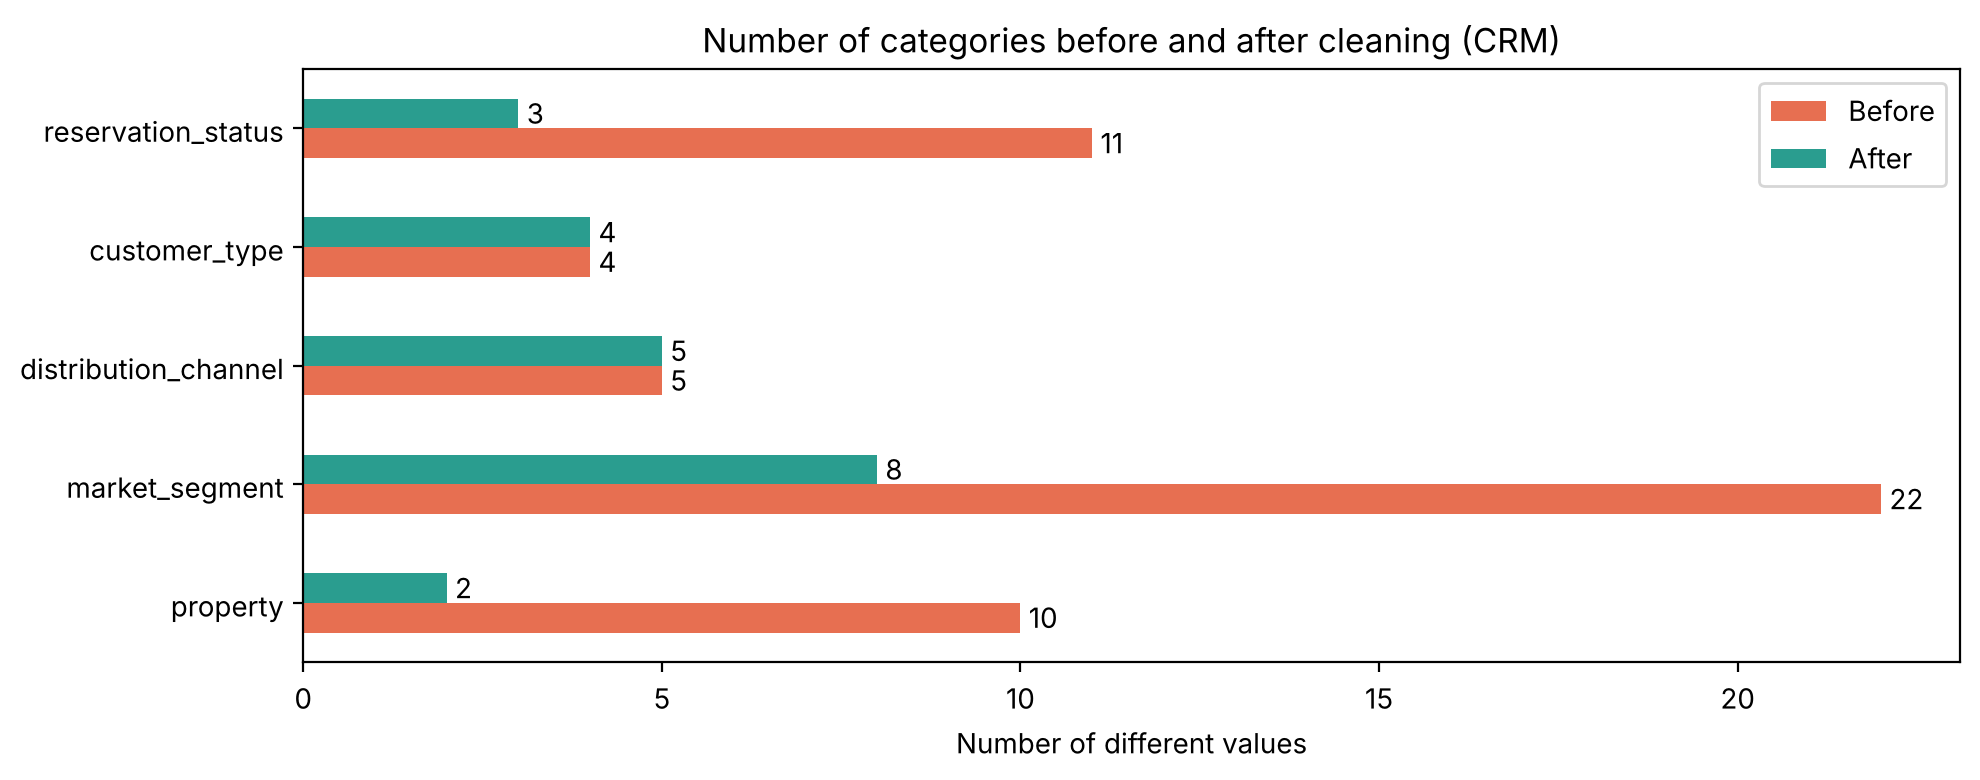

In [130]:
ax = category_comparison[["Before", "After"]].drop("guest_country").plot(
    kind="barh", figsize=(10, 4), color=["#E76F51", "#2A9D8F"])
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)
plt.title("Number of categories before and after cleaning (CRM)")
plt.xlabel("Number of different values")
plt.tight_layout()
plt.show()

### 5.5 Values that don't make sense

#### Number of adults
26 and 55 adults in one booking can't be right, so we empty them. After the merge we can
take the number from the PMS for the same booking.

For the 79 bookings with 0 adults we were less sure. It could be an error, but it could
also be a booking for children only, and the CRM file has no column for children. So we
don't change them, we just mark them and check again once we have the PMS data.

In [131]:
impossible_adults = crm_clean["n_adults"] > 10
print("Impossible n_adults set to missing:", impossible_adults.sum())
crm_clean.loc[impossible_adults, "n_adults"] = pd.NA

crm_clean["zero_adults_flag"] = crm_clean["n_adults"] == 0
print("Bookings flagged with 0 adults:", crm_clean["zero_adults_flag"].sum())

Impossible n_adults set to missing: 2
Bookings flagged with 0 adults: 79


#### Bookings with price 0
There are 381 bookings with a total price of 0. We checked which segment they belong
to, and about a third are "Complementary", meaning free stays offered by the hotel, so a
price of 0 is correct there. We keep all of them and add a flag, so in the analysis we can
decide whether to include them or not.

In [132]:
crm_clean["zero_price_flag"] = crm_clean["total_price"] == 0
display(crm_clean.loc[crm_clean["zero_price_flag"], "market_segment"].value_counts())

market_segment
Complementary    121
Online TA         80
Offline TA/TO     73
Groups            50
Direct            45
Corporate         10
Aviation           2
Name: count, dtype: int64

#### Status date vs check-in date
This one came from a simple reasoning: if a guest checked out, the check-out date must be
after the check-in. If a booking was canceled, it must have been canceled before the
guest was supposed to arrive. We checked both.

In [133]:
days_from_checkin = (crm_clean["reservation_status_date"] - crm_clean["checkin_date"]).dt.days

crm_clean["status_date_flag"] = (
    ((crm_clean["reservation_status"] == "Check-Out") & (days_from_checkin < 0)) |
    ((crm_clean["reservation_status"] == "Canceled") & (days_from_checkin > 0))
)
print("Check-out before check-in:",
      ((crm_clean["reservation_status"] == "Check-Out") & (days_from_checkin < 0)).sum())
print("Cancellation after check-in:",
      ((crm_clean["reservation_status"] == "Canceled") & (days_from_checkin > 0)).sum())

Check-out before check-in: 37
Cancellation after check-in: 50


87 bookings break this rule. We can't tell which of the two dates is wrong, so we don't
fix anything here. We flag them, and after the merge we'll compare them with the arrival
date in the PMS.

## 6. Before and after

In [134]:
crm_quality_after = [len(crm_clean), crm_clean.isna().all(axis=1).sum(), crm_clean.duplicated().sum(),
                     crm_clean["property"].nunique(), crm_clean["market_segment"].nunique(),
                     crm_clean["reservation_status"].nunique(),
                     (crm_clean["n_adults"] > 10).sum(),
                     (crm_clean["lead_time_days"] == 9999).sum()]
crm_quality_before["After Cleaning"] = crm_quality_after
display(crm_quality_before)

,Quality Metric,Before Cleaning,After Cleaning
0,Total Records,24608,24500
1,Fully Empty Rows,8,0
2,Exact Duplicate Rows,107,0
3,Property spellings,10,2
4,Market segment spellings,22,8
5,Reservation status spellings,11,3
6,Impossible n_adults (>10),2,0
7,Placeholder lead time (9999),25,0


The same comparison as a chart, without the first row (total records) because it is much
bigger than the others and would hide them.

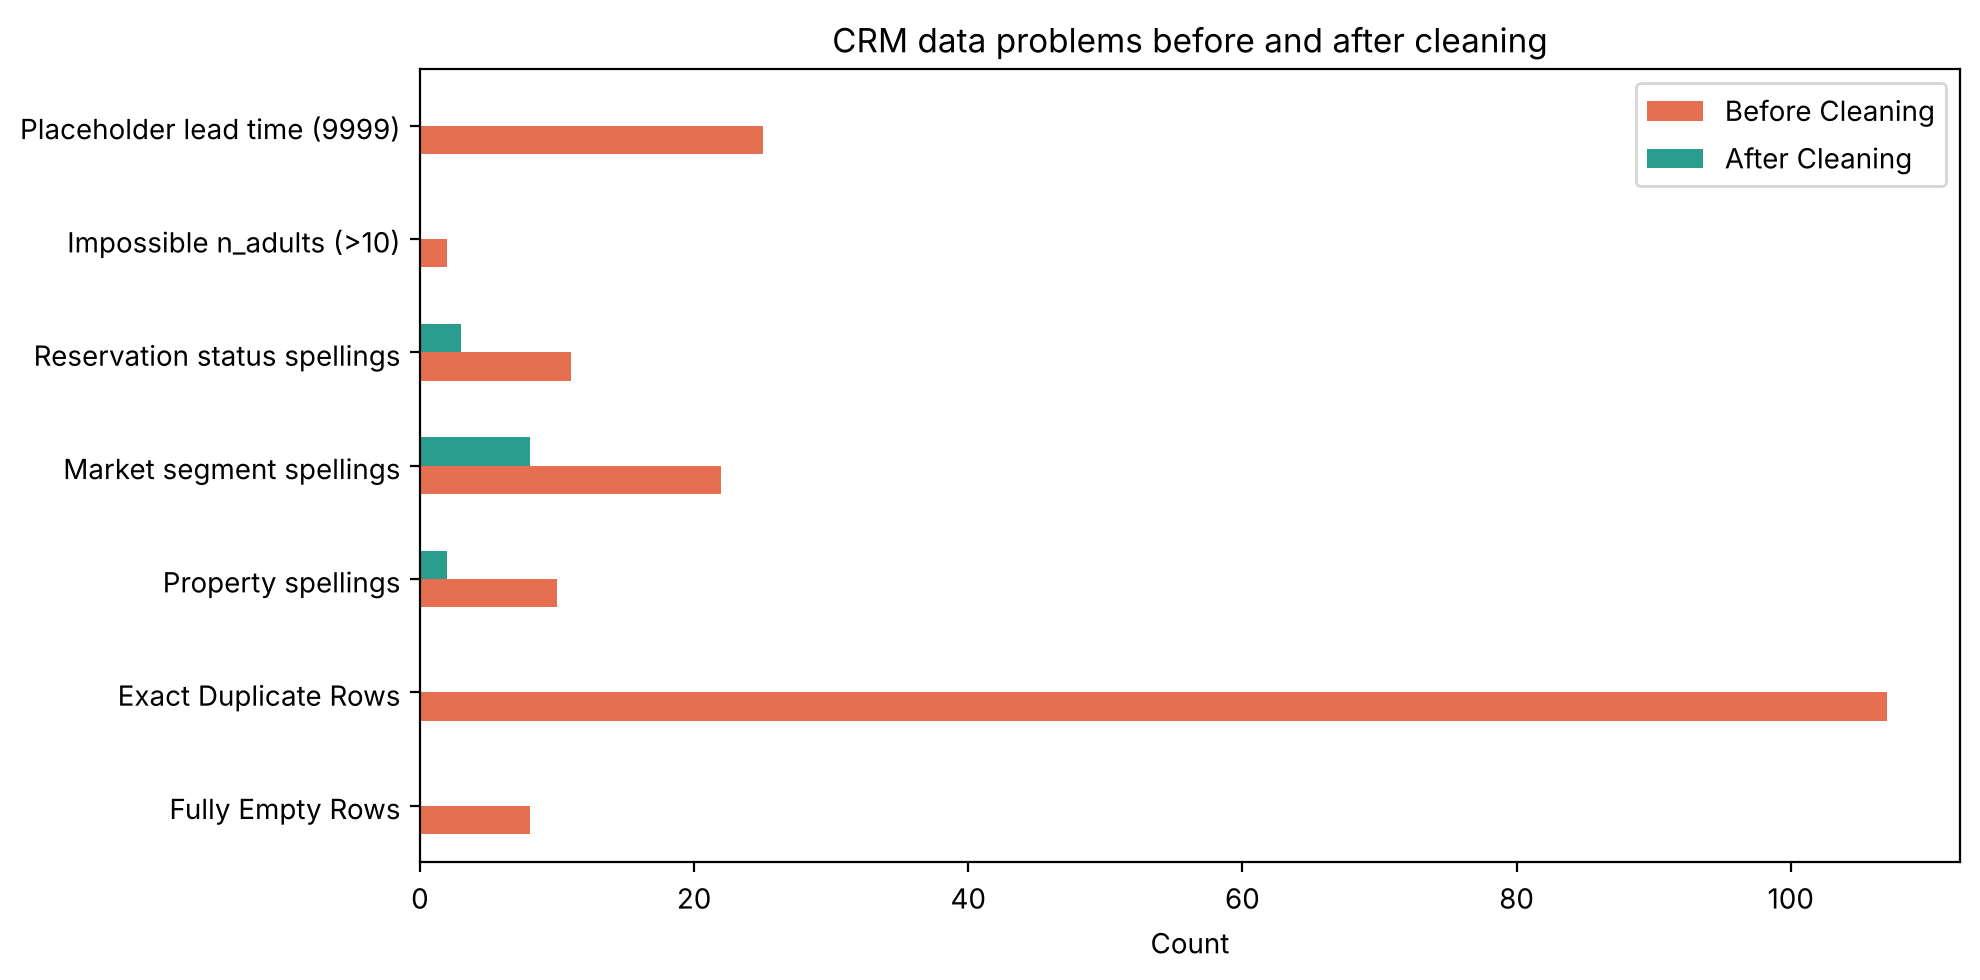

In [135]:
problems = crm_quality_before.set_index("Quality Metric").drop("Total Records")

ax = problems.plot(kind="barh", figsize=(10, 5), color=["#E76F51", "#2A9D8F"])
ax.set_title("CRM data problems before and after cleaning")
ax.set_xlabel("Count")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

And how many rows we kept at each step. Only two steps remove rows: the empty rows and the
duplicates. Everything else fixes values without deleting anything.

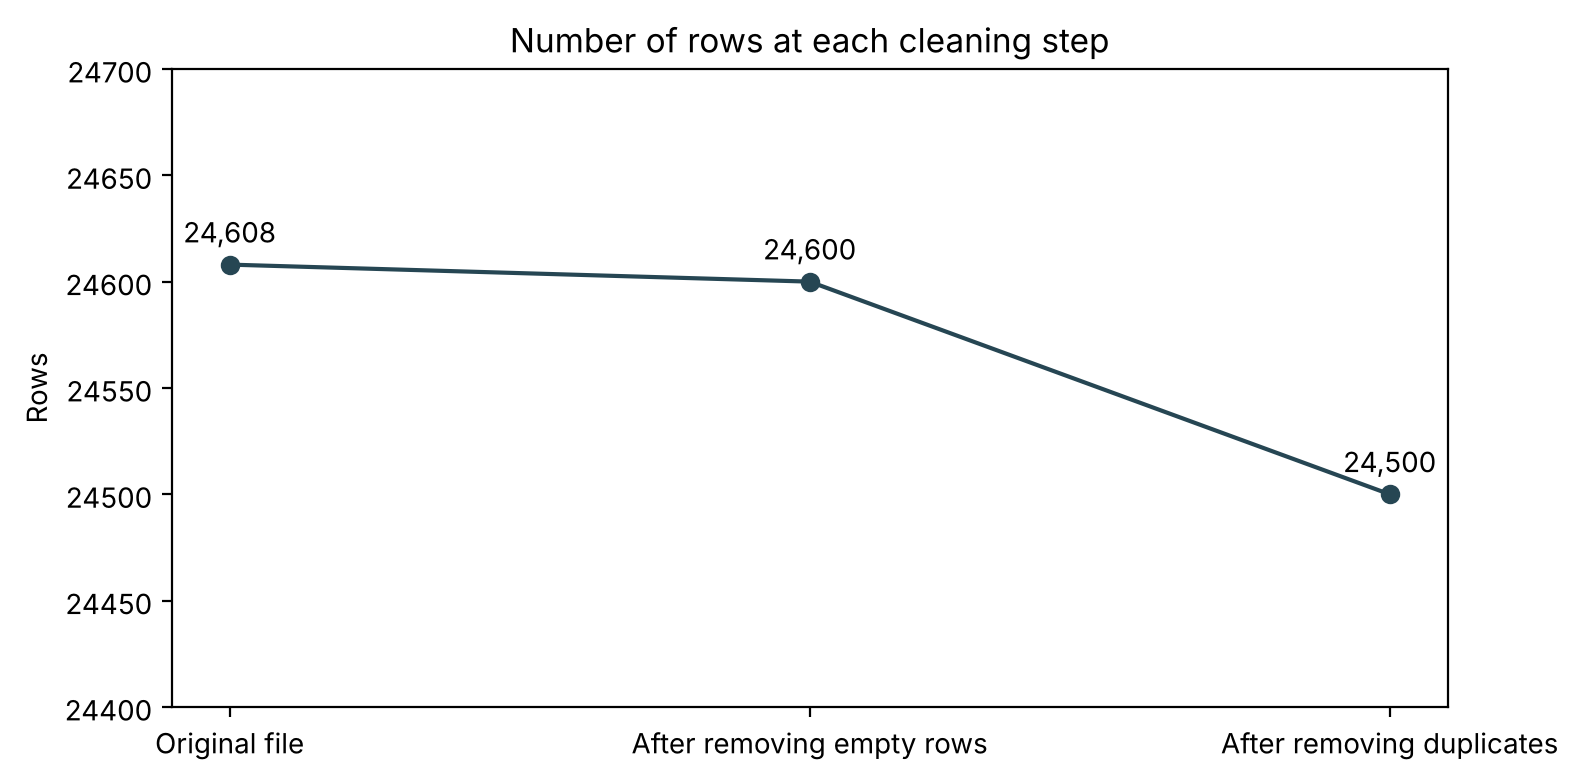

In [136]:
rows_per_step = pd.Series({
    "Original file": len(crm_raw),
    "After removing empty rows": len(crm_raw.dropna(how="all")),
    "After removing duplicates": len(crm_clean),
})

ax = rows_per_step.plot(marker="o", figsize=(8, 4), color="#264653")
for i, value in enumerate(rows_per_step):
    ax.annotate(f"{value:,}", (i, value), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_xticks(range(len(rows_per_step)), rows_per_step.index)
ax.set_title("Number of rows at each cleaning step")
ax.set_ylabel("Rows")
ax.set_ylim(24400, 24700)
plt.tight_layout()
plt.show()

In [137]:
missing_comparison = pd.DataFrame({
    "Before Cleaning": crm_raw.isna().sum(),
    "After Cleaning": crm_clean[crm_raw.columns].isna().sum()
})
display(missing_comparison[missing_comparison.sum(axis=1) > 0])

,Before Cleaning,After Cleaning
BookingRef,8,0
property,8,0
checkin_date,8,0
n_adults,254,246
lead_time_days,8,25
guest_country,8,114
market_segment,8,0
distribution_channel,8,0
customer_type,8,0
is_repeated_guest,8,0


Some columns now have more missing values than before, and that's on purpose: values like
9999 or "unknown" looked filled in, but they weren't real information. `company_id` and
`agent_id` stay empty because there was simply no company or agent. Missing prices and
adults will be filled from the PMS after the merge.

## 7. Final checks and export

In [138]:
final_checks = pd.DataFrame({
    "Check": [
        "No fully empty rows", "No exact duplicates", "BookingRef unique",
        "All check-in dates parsed", "2 hotel categories", "3 reservation statuses",
        "No impossible n_adults", "No lead time placeholder", "No negative total_price"],
    "Result": [
        crm_clean.isna().all(axis=1).sum() == 0,
        crm_clean.duplicated().sum() == 0,
        crm_clean["BookingRef"].is_unique,
        crm_clean["checkin_date"].notna().all(),
        crm_clean["property"].nunique() == 2,
        crm_clean["reservation_status"].nunique() == 3,
        (crm_clean["n_adults"].dropna() <= 10).all(),
        (crm_clean["lead_time_days"].dropna() != 9999).all(),
        (crm_clean["total_price"].dropna() >= 0).all()],
})
final_checks["Status"] = np.where(final_checks["Result"], "PASS", "FAIL")
display(final_checks)
assert final_checks["Result"].all()

,Check,Result,Status
0,No fully empty rows,True,PASS
1,No exact duplicates,True,PASS
2,BookingRef unique,True,PASS
3,All check-in dates parsed,True,PASS
4,2 hotel categories,True,PASS
5,3 reservation statuses,True,PASS
6,No impossible n_adults,True,PASS
7,No lead time placeholder,True,PASS
8,No negative total_price,True,PASS


In [139]:
output_filename = "crm_cleaned.csv"
crm_clean.to_csv(output_filename, index=False, date_format="%Y-%m-%d")

# we reload the file to make sure nothing changed on the way (for example the IDs)
crm_check = pd.read_csv(output_filename, dtype={"BookingRef": str, "agent_id": str, "company_id": str})
assert crm_check.shape == crm_clean.shape
assert crm_check["BookingRef"].equals(crm_clean["BookingRef"].reset_index(drop=True))
print("Exported:", output_filename, crm_check.shape)

Exported: crm_cleaned.csv (24500, 21)


## 8. What we did

We started from 24,608 rows and ended with 24,500: we only removed the 8 empty rows and
the 100 bookings that were there twice, so we kept 99.6% of the data.

Most of the work was about formats and labels. We fixed the separator, the decimal commas,
the "days" written next to the lead time and the three date formats. The hotel names went
from 10 to 2, the market segments from 22 to 8 and the reservation statuses from 11 to 3.

A few values were clearly wrong (two impossible adult counts and 25 lead times of 9999)
and we emptied them. Others were suspicious but not necessarily wrong, so we flagged them
to check after the merge: 79 bookings with 0 adults, 381 with price 0 and 87 where the
status date doesn't match the check-in.

The one question we couldn't answer ourselves is what "CN" means in the country column.

The file `crm_cleaned.csv` is ready to be merged with the PMS on `BookingRef` / `booking_id`.

---
# PART 3 – PMS & CRM DATA INTEGRATION

#Hotel Bookings Project – Pandas & Data Manipulation

Albert School × POLIMI Graduate School of Management

PMS & CRM Data Integration and Data Quality Assessment

Property Management System (PMS) & Customer Relationship Management (CRM)

⸻

#1. Introduction & Project Objectives

1.1 Project Background

The hospitality industry relies on multiple information systems to manage hotel operations, customer relationships and commercial activities. Although these systems serve different business purposes, they frequently contain complementary and partially overlapping information about the same bookings.

This project focuses on the integration of two hotel booking datasets originating from different information systems:

* Property Management System (PMS): primarily focused on operational information, including arrival dates, guest composition, stay duration, room characteristics, pricing and booking cancellations.
* Customer Relationship Management (CRM): primarily focused on customer and commercial information, including country of origin, market segmentation, booking characteristics, reservation status and booking value.

The original PMS dataset contains 24,480 records and 20 variables, while the original CRM dataset contains 24,608 records.

The preceding notebooks independently evaluated and cleaned both data sources, addressing structural inconsistencies, numerical anomalies, categorical inconsistencies and missing information while preserving the original datasets.

However, independent data cleaning does not guarantee consistency between the two systems. Differences in booking coverage, variable definitions, missing information and conflicting values may still affect the reliability of the integrated data.

This notebook therefore focuses on identifying compatible booking identifiers, evaluating integration coverage, comparing shared information, resolving discrepancies where justified and developing a documented and reproducible integrated dataset.

The integration process aims to establish a reliable booking-level analytical foundation that combines operational and commercial information, supporting subsequent business analysis and evidence-based decision-making in the hospitality industry.

1.2 Data Integration Objectives

The primary objective of this notebook is to develop a reliable, consistent and analytically usable integrated dataset by combining operational information from the Property Management System (PMS) with customer and commercial information from the Customer Relationship Management (CRM) system.

The integration process is structured around six main objectives:

1. Data Integration

Combine the two data sources into a unified booking-level dataset, ensuring that each identifiable booking is represented by a single record and that the integration process does not introduce artificial duplication or unnecessary information loss.

2. Integration Coverage Assessment

Evaluate the compatibility of booking identifiers and quantify the number of matched and unmatched records. This assessment provides insights into the degree of overlap between the two information systems and their respective data coverage.

3. Cross-Dataset Consistency Assessment

Identify variables representing equivalent or comparable business information and evaluate their consistency across the two systems. Particular attention will be given to discrepancies in hotel information, arrival dates, guest composition, reservation status and financial information.

4. Data Reconciliation and Missing Value Recovery

Investigate conflicting observations and recover missing information where reliable and equivalent data are available from the alternative source. Reconciliation decisions will be based on documented business logic, source reliability and empirical evidence rather than unsupported assumptions.

5. Integrated Data Quality Improvement

Evaluate the quality of the integrated dataset across multiple dimensions, including completeness, uniqueness, consistency, validity, coverage and traceability. The effectiveness of the integration and reconciliation procedures will be assessed through quantitative comparisons and appropriate visualizations.

6. Analytical Readiness

Develop relevant analytical variables, perform final integrity checks and produce a documented integrated dataset suitable for subsequent business analysis. The final output will support the investigation of hotel performance, pricing strategies, customer characteristics, booking behavior and operational trends.

Throughout the integration process, particular emphasis will be placed on reproducibility, transparency and information preservation.

The objective is not to achieve artificial completeness or eliminate every discrepancy, but to establish a reliable analytical foundation while explicitly documenting unresolved issues, methodological assumptions and remaining limitations.

1.3 Methodological Approach

The integration process follows a structured, evidence-based and reproducible methodology designed to maximize data reliability while preserving relevant business information.

The methodology builds upon the data quality assessment and cleaning procedures previously performed on the PMS and CRM datasets. The original data sources and preceding cleaning notebooks are retained to support end-to-end reproducibility and transparency.

The integration methodology consists of eight main stages:

1. Source Preparation

Load the cleaned PMS and CRM datasets, verify their structural characteristics and review the cleaning decisions, transformation assumptions and remaining limitations documented in the preceding notebooks.

2. Pre-Merge Assessment

Evaluate the completeness, uniqueness, formatting and compatibility of the booking identifiers. Identify overlapping and unmatched records, assess integration coverage and determine which variables represent shared or complementary business information.

3. Data Integration

Combine the two datasets using an appropriate merge strategy. An initial full outer join will be considered following merge key validation to preserve identifiable bookings from both sources and provide visibility into matched and unmatched records.

Merge cardinality and record-level integrity will be explicitly validated to prevent artificial duplication and unintended information loss.

4. Cross-Dataset Consistency Assessment

Compare equivalent or comparable information across matched bookings to identify agreements, discrepancies and missing values. Consistency rates and conflict distributions will be calculated using clearly defined and appropriate denominators.

5. Data Reconciliation and Missing Value Recovery

Investigate identified discrepancies and recover missing information where reliable and semantically equivalent values are available from the alternative source.

Reconciliation decisions will be supported by empirical evidence, variable-specific source reliability and documented business logic. Unresolved discrepancies will be retained and flagged rather than corrected through unsupported assumptions.

6. Feature Engineering

Develop additional analytical variables related to stay duration, guest composition, financial indicators, temporal characteristics, booking behavior and data quality.

Derived variables will be validated to ensure that their calculation does not introduce misleading information or additional inconsistencies.

7. Integrated Data Quality Evaluation

Assess the effectiveness of the integration and reconciliation process across the dimensions of completeness, uniqueness, consistency, validity, coverage and traceability.

Quantitative indicators, before-and-after comparisons and appropriate visualizations will be used to evaluate the improvements achieved and identify remaining limitations.

Comparisons will be based on equivalent variables and comparable observation populations to avoid misleading conclusions.

8. Final Validation, Documentation and Export

Perform final structural, numerical, categorical and logical integrity checks. Document variable definitions, data sources, transformation rules, analytical restrictions and unresolved limitations.

The final integrated dataset will be exported and verified, together with a comprehensive data dictionary supporting subsequent business analysis.

Guiding Methodological Principles

Throughout the integration process, the following principles will guide all methodological decisions:

* Information preservation: avoid unnecessary record removal and maintain relevant information from both data sources.
* Reliability over artificial completeness: preserve missing values when reliable recovery is not possible.
* Evidence-based reconciliation: resolve discrepancies only when supported by appropriate evidence and business logic.
* Traceability: preserve the provenance of information, document transformations and identify recovered or conflicting values.
* Reproducibility: ensure that the complete workflow can be reproduced programmatically from the original data sources without undocumented manual interventions.

This methodology recognizes that data integration is not merely a technical merging operation, but a broader process involving semantic understanding, quality evaluation, critical assessment and documented decision-making.

The resulting integrated dataset is intended to provide a reliable and transparent analytical foundation for subsequent business analysis, subject to its documented limitations.

1.4 Expected Business Value

The integration of operational and commercial hotel booking data is expected to generate business value beyond the technical consolidation of multiple data sources.

By establishing a unified and reliable booking-level dataset, the integration process aims to provide a more comprehensive understanding of hotel performance, customer characteristics and reservation behavior.

The expected business value can be identified across several key areas:

1. Hotel Performance Monitoring

An integrated dataset can support comparative assessments of hotel performance by combining operational and commercial indicators within a consistent analytical framework.

2. Revenue Management and Pricing Strategy

Combining pricing, booking value and stay duration information can support the identification of revenue opportunities, pricing patterns and differences across customer segments, hotels and time periods.

Financial indicators will be interpreted according to their definitions and availability, distinguishing estimated booking values from actual realized revenue.

3. Customer Understanding and Market Segmentation

The integration of guest characteristics and commercial information can provide insights into customer profiles, geographical markets and booking preferences.

These insights may support more effective marketing strategies, customer targeting and market positioning.

4. Booking Behavior and Cancellation Analysis

Combining operational and commercial variables can support the investigation of booking patterns, reservation status, cancellation behavior and potential factors associated with cancellations.

5. Operational Planning and Seasonality

Information related to arrival dates, stay duration and guest composition can support the identification of seasonal demand patterns and inform operational planning and resource allocation.

6. Data Quality and Data Governance

The integration process can reveal inconsistencies between information systems that may remain undetected when each dataset is analyzed independently.

Identifying conflicting information, missing values and coverage differences can support improvements in data collection, validation procedures and information management practices.

7. Evidence-Based Decision-Making

A validated, documented and traceable integrated dataset can reduce uncertainty associated with fragmented information and provide a more reliable foundation for strategic and operational decision-making.

Ultimately, the expected value of this integration lies not only in increasing the amount of available information, but also in improving its reliability, consistency, interpretability and analytical usability.

The integrated dataset will serve as the foundation for the subsequent business analysis, translating data quality improvements and integrated information into actionable business insights.

These benefits represent expected analytical opportunities rather than confirmed business outcomes and will be evaluated through subsequent empirical analysis.

# 2. Data Loading & Preliminary Assessment

This section focuses on loading the previously cleaned PMS and CRM datasets and verifying their structural characteristics before proceeding with the integration process.

2.1 Import Libraries

The following Python libraries are imported to support data manipulation, numerical operations, statistical analysis and data visualization throughout the integration process.

In [140]:
# Import libraries for data manipulation and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display settings

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

2.2 Load Cleaned Datasets

The cleaned PMS and CRM datasets generated during the preceding data cleaning phases are imported into the integration environment.

These datasets represent the starting point for the integration process. Previously performed cleaning operations are not repeated in this notebook.

The imported datasets will undergo preliminary structural validation to ensure that they correspond to the expected outputs of the preceding cleaning notebooks.

In [141]:
# Load the cleaned PMS dataset

pms = pd.read_csv("pms_cleaned.csv")

# Load the cleaned CRM dataset

crm = pd.read_csv("crm_cleaned.csv")

# Confirm successful data loading

print("PMS dataset successfully loaded.")
print("CRM dataset successfully loaded.")

PMS dataset successfully loaded.
CRM dataset successfully loaded.


In [142]:
# Display the first five rows of each dataset

print("PMS Dataset:")
display(pms.head())

print("\nCRM Dataset:")
display(crm.head())

PMS Dataset:


,booking_id,hotel,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,reserved_room_type,assigned_room_type,booking_changes,deposit_type,adr,required_car_parking_spaces,total_of_special_requests,is_canceled,record_updated_at,adr_before_correction,adr_scale_corrected,adr_negative_flag,arrival_date
0,BK317616,City Hotel,2017,August,31,0,3.0,2,0.0,0,BB,A,A,0,No Deposit,119.40,0,0,0,2017-09-02,119.40,False,False,2017-08-31
1,BK314798,Resort Hotel,2017,August,29,2,5.0,2,0.0,0,BB,A,A,0,No Deposit,130.23,0,1,0,2017-09-02,130.23,False,False,2017-08-29
2,BK304643,City Hotel,2017,August,28,1,5.0,2,2.0,0,BB,F,F,1,No Deposit,194.13,0,1,0,2017-09-02,194.13,False,False,2017-08-28
3,BK305980,Resort Hotel,2017,August,31,2,3.0,2,0.0,0,HB,A,A,0,No Deposit,149.45,0,1,0,2017-09-02,149.45,False,False,2017-08-31
4,BK303821,City Hotel,2017,August,31,2,5.0,3,0.0,0,BB,E,E,0,No Deposit,225.43,0,2,0,2017-09-02,225.43,False,False,2017-08-31



CRM Dataset:


,BookingRef,property,checkin_date,n_adults,lead_time_days,guest_country,market_segment,distribution_channel,customer_type,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,agent_id,company_id,days_in_waiting_list,reservation_status,reservation_status_date,total_price,zero_adults_flag,zero_price_flag,status_date_flag
0,BK310511,City Hotel,2016-12-03,2.0,73.0,USA,Online TA,TA/TO,Transient,0,0,0,7.0,NaN,0,Check-Out,2016-12-04,NaN,False,False,False
1,BK300310,City Hotel,2016-05-29,2.0,106.0,DEU,Offline TA/TO,TA/TO,Transient-Party,0,0,0,27.0,NaN,0,Check-Out,2016-06-01,242.25,False,False,False
2,BK302934,City Hotel,2017-07-13,3.0,356.0,NOR,Online TA,TA/TO,Transient,0,0,0,9.0,NaN,0,Canceled,2016-08-29,529.20,False,False,False
3,BK320441,Resort Hotel,2016-10-30,2.0,14.0,FRA,Online TA,TA/TO,Transient,0,0,0,241.0,NaN,0,Check-Out,2016-11-14,799.80,False,False,False
4,BK316173,City Hotel,2016-04-29,3.0,27.0,ITA,Online TA,TA/TO,Transient,0,0,0,9.0,NaN,0,Canceled,2016-04-04,531.00,False,False,False


2.3 Dataset Dimensions

Before proceeding with the integration process, the dimensions of both cleaned datasets are evaluated and compared with the expected outputs of the preceding data cleaning notebooks.

This preliminary structural validation aims to ensure that:

* Both datasets contain the expected number of records and variables.
* No unintended record loss occurred during the export and import processes.
* No unexpected variables were added or removed.
* The correct versions of the cleaned datasets have been imported.

Based on the preceding cleaning procedures, the expected dimensions are:

* PMS dataset: 24,250 records and 24 variables.
* CRM dataset: 24,500 records and 21 variables.

The actual dimensions are compared against these expected values to establish a preliminary structural integrity checkpoint before data integration.

In [143]:
# Display the dimensions of both datasets

print("PMS Dataset Dimensions:")
print(f"Number of records: {pms.shape[0]:,}")
print(f"Number of variables: {pms.shape[1]}")

print("\nCRM Dataset Dimensions:")
print(f"Number of records: {crm.shape[0]:,}")
print(f"Number of variables: {crm.shape[1]}")

PMS Dataset Dimensions:
Number of records: 24,250
Number of variables: 24

CRM Dataset Dimensions:
Number of records: 24,500
Number of variables: 21


In [144]:
# Define expected dataset dimensions

expected_pms_shape = (24250, 24)
expected_crm_shape = (24500, 21)

# Create a structural validation summary

dimensions_summary = pd.DataFrame({
    "Dataset": ["PMS", "CRM"],
    "Expected Records": [24250, 24500],
    "Actual Records": [pms.shape[0], crm.shape[0]],
    "Expected Variables": [24, 21],
    "Actual Variables": [pms.shape[1], crm.shape[1]],
    "Validation Status": [
        "PASS" if pms.shape == expected_pms_shape else "FAIL",
        "PASS" if crm.shape == expected_crm_shape else "FAIL"
    ]
})

# Display the structural validation results

display(dimensions_summary)

,Dataset,Expected Records,Actual Records,Expected Variables,Actual Variables,Validation Status
0,PMS,24250,24250,24,24,PASS
1,CRM,24500,24500,21,21,PASS


Results & Interpretation

Both datasets successfully passed the preliminary dimensional validation.

The PMS dataset contains 24,250 records and 24 variables, while the CRM dataset contains 24,500 records and 21 variables. Both dimensions exactly match the expected outputs of the preceding data cleaning notebooks.

Key findings:

* Both datasets passed the dimensional validation checks.
* No unexpected changes in the number of records or variables were detected.
* The CRM dataset contains 250 more records than the PMS dataset.
* The PMS dataset contains three more variables than the CRM dataset.

The difference in record counts suggests that the two systems may have different booking coverage. However, this difference alone does not determine the actual number of unmatched bookings, which will be investigated during the pre-merge assessment.

Although dimensional validation confirms structural compatibility with the expected outputs, it does not independently guarantee record-level integrity or cross-dataset consistency.

Both datasets are therefore ready to proceed to the next stage of preliminary assessment.

2.4 Variable Structure and Data Types

Following the successful dimensional validation, the variable structure and data types of both datasets are examined.

Although the PMS and CRM datasets have already undergone independent cleaning procedures, exporting and re-importing data in CSV format may result in the loss of previously assigned data types.

This assessment aims to:

* Identify the complete set of variables available in each dataset.
* Examine the data types assigned during the CSV import process.
* Identify potential data type inconsistencies.
* Restore appropriate data types where necessary.
* Ensure compatibility between variables representing equivalent business information.
* Prepare booking identifiers, date variables and numerical features for subsequent integration and analysis.

Particular attention is given to booking identifiers, datetime variables, categorical information, nullable integers and financial variables.

Any necessary data type restoration will be performed programmatically and validated to avoid unintended information loss or the introduction of additional missing values.

In [145]:
# Display all variable names in the PMS dataset

print("PMS Dataset Variables:")
print(pms.columns.tolist())

# Display all variable names in the CRM dataset

print("\nCRM Dataset Variables:")
print(crm.columns.tolist())

PMS Dataset Variables:
['booking_id', 'hotel', 'arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'is_canceled', 'record_updated_at', 'adr_before_correction', 'adr_scale_corrected', 'adr_negative_flag', 'arrival_date']

CRM Dataset Variables:
['BookingRef', 'property', 'checkin_date', 'n_adults', 'lead_time_days', 'guest_country', 'market_segment', 'distribution_channel', 'customer_type', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'agent_id', 'company_id', 'days_in_waiting_list', 'reservation_status', 'reservation_status_date', 'total_price', 'zero_adults_flag', 'zero_price_flag', 'status_date_flag']


In [146]:
# Inspect the PMS dataset structure

print("PMS Dataset Structure:")
pms.info()

# Inspect the CRM dataset structure

print("\nCRM Dataset Structure:")
crm.info()

PMS Dataset Structure:


<class 'pandas.DataFrame'>
RangeIndex: 24250 entries, 0 to 24249
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   booking_id                   24250 non-null  str    
 1   hotel                        24250 non-null  str    
 2   arrival_date_year            24250 non-null  int64  
 3   arrival_date_month           24250 non-null  str    
 4   arrival_date_day_of_month    24250 non-null  int64  
 5   stays_in_weekend_nights      24250 non-null  int64  
 6   stays_in_week_nights         24215 non-null  float64
 7   adults                       24250 non-null  int64  
 8   children                     23440 non-null  float64
 9   babies                       24250 non-null  int64  
 10  meal                         23765 non-null  str    
 11  reserved_room_type           24250 non-null  str    
 12  assigned_room_type           24250 non-null  str    
 13  booking_changes            

In [147]:
# Create a data type summary for the PMS dataset

pms_dtype_summary = pd.DataFrame({
    "Variable": pms.columns,
    "Data Type": pms.dtypes.astype(str).values,
    "Non-Null Values": pms.notna().sum().values,
    "Missing Values": pms.isna().sum().values
})

# Create a data type summary for the CRM dataset

crm_dtype_summary = pd.DataFrame({
    "Variable": crm.columns,
    "Data Type": crm.dtypes.astype(str).values,
    "Non-Null Values": crm.notna().sum().values,
    "Missing Values": crm.isna().sum().values
})

# Display the summaries

print("PMS Data Type Summary:")
display(pms_dtype_summary)

print("\nCRM Data Type Summary:")
display(crm_dtype_summary)

PMS Data Type Summary:


,Variable,Data Type,Non-Null Values,Missing Values
0,booking_id,str,24250,0
1,hotel,str,24250,0
2,arrival_date_year,int64,24250,0
3,arrival_date_month,str,24250,0
4,arrival_date_day_of_month,int64,24250,0
5,stays_in_weekend_nights,int64,24250,0
6,stays_in_week_nights,float64,24215,35
7,adults,int64,24250,0
8,children,float64,23440,810
9,babies,int64,24250,0



CRM Data Type Summary:


,Variable,Data Type,Non-Null Values,Missing Values
0,BookingRef,str,24500,0
1,property,str,24500,0
2,checkin_date,str,24500,0
3,n_adults,float64,24254,246
4,lead_time_days,float64,24475,25
5,guest_country,str,24386,114
6,market_segment,str,24500,0
7,distribution_channel,str,24500,0
8,customer_type,str,24500,0
9,is_repeated_guest,int64,24500,0


Data Type Restoration

The preliminary structural assessment identified several data type changes resulting from the CSV export and import processes.

Booking identifiers, categorical variables and date fields were imported as object types, while several discrete numerical variables were represented as floating-point numbers due to the presence of missing values.

To ensure semantic correctness and cross-dataset compatibility, the following transformations are applied:

* Booking identifiers and textual categorical variables are converted to the Pandas string data type.
* Date variables are converted to datetime format to support temporal comparisons and analysis.
* Discrete numerical variables containing missing values are converted to nullable integers (Int64).
* Numerical agent and company identifiers are represented as nullable integers.
* Boolean audit flags are standardized while preserving missing values.
* Financial variables retain their floating-point representation.

These transformations aim to restore or standardize the appropriate data representation without altering the underlying business information.

Strict conversion rules and subsequent validation checks are applied to prevent unintended information loss, changes in dataset dimensions or the introduction of additional missing values.

In [148]:
# Store the initial data types

pms_dtypes_before = pms.dtypes.astype(str).copy()
crm_dtypes_before = crm.dtypes.astype(str).copy()

# Store the initial missing value counts

pms_missing_before = pms.isna().sum().copy()
crm_missing_before = crm.isna().sum().copy()

# Confirm that the initial structure has been recorded

print("Initial PMS and CRM structures successfully recorded.")

Initial PMS and CRM structures successfully recorded.


In [149]:
# Restore PMS textual variables

pms_string_columns = [
    "booking_id",
    "hotel",
    "arrival_date_month",
    "meal",
    "reserved_room_type",
    "assigned_room_type",
    "deposit_type"
]

pms[pms_string_columns] = pms[pms_string_columns].astype("string")

# Restore nullable integer variables

pms_integer_columns = [
    "stays_in_week_nights",
    "children"
]

pms[pms_integer_columns] = pms[pms_integer_columns].astype("Int64")

# Restore datetime variables

pms_date_columns = [
    "record_updated_at",
    "arrival_date"
]

for col in pms_date_columns:
    pms[col] = pd.to_datetime(pms[col], errors="raise")

# Confirm successful conversion

print("PMS data types successfully restored.")

PMS data types successfully restored.


In [150]:
# Restore CRM textual variables

crm_string_columns = [
    "BookingRef",
    "property",
    "guest_country",
    "market_segment",
    "distribution_channel",
    "customer_type",
    "reservation_status"
]

crm[crm_string_columns] = crm[crm_string_columns].astype("string")

# Restore nullable integer variables

crm_integer_columns = [
    "n_adults",
    "lead_time_days",
    "agent_id",
    "company_id"
]

crm[crm_integer_columns] = crm[crm_integer_columns].astype("Int64")

# Restore datetime variables

crm_date_columns = [
    "checkin_date",
    "reservation_status_date"
]

for col in crm_date_columns:
    crm[col] = pd.to_datetime(crm[col], errors="raise")

# Restore the nullable boolean audit flag

crm["zero_adults_flag"] = crm["zero_adults_flag"].astype("boolean")

# Confirm successful conversion

print("CRM data types successfully restored.")

CRM data types successfully restored.


In [151]:
# Create the PMS data type comparison

pms_type_comparison = pd.DataFrame({
    "Before": pms_dtypes_before,
    "After": pms.dtypes.astype(str)
})

# Identify modified data types

pms_type_comparison["Modified"] = (
    pms_type_comparison["Before"] != pms_type_comparison["After"]
)

# Create the CRM data type comparison

crm_type_comparison = pd.DataFrame({
    "Before": crm_dtypes_before,
    "After": crm.dtypes.astype(str)
})

# Identify modified data types

crm_type_comparison["Modified"] = (
    crm_type_comparison["Before"] != crm_type_comparison["After"]
)

# Display only the modified variables

print("PMS Data Type Transformations:")
display(pms_type_comparison[pms_type_comparison["Modified"]])

print("\nCRM Data Type Transformations:")
display(crm_type_comparison[crm_type_comparison["Modified"]])

PMS Data Type Transformations:


,Before,After,Modified
booking_id,str,string,True
hotel,str,string,True
arrival_date_month,str,string,True
stays_in_week_nights,float64,Int64,True
children,float64,Int64,True
meal,str,string,True
reserved_room_type,str,string,True
assigned_room_type,str,string,True
deposit_type,str,string,True
record_updated_at,str,datetime64[us],True



CRM Data Type Transformations:


,Before,After,Modified
BookingRef,str,string,True
property,str,string,True
checkin_date,str,datetime64[us],True
n_adults,float64,Int64,True
lead_time_days,float64,Int64,True
guest_country,str,string,True
market_segment,str,string,True
distribution_channel,str,string,True
customer_type,str,string,True
agent_id,float64,Int64,True


In [152]:
# Summarize the number of data type transformations

print(
    "PMS variables modified:",
    pms_type_comparison["Modified"].sum()
)

print(
    "CRM variables modified:",
    crm_type_comparison["Modified"].sum()
)

print(
    "Total variables modified:",
    pms_type_comparison["Modified"].sum() +
    crm_type_comparison["Modified"].sum()
)

PMS variables modified: 11
CRM variables modified: 14
Total variables modified: 25


In [153]:
# Validate data type restoration

dtype_validation = pd.DataFrame({
    "Validation Check": [
        "PMS dimensions preserved",
        "CRM dimensions preserved",
        "PMS missing value counts preserved",
        "CRM missing value counts preserved",
        "Booking identifier types compatible",
        "Hotel variable types compatible",
        "Arrival date types compatible"
    ],
    "Passed": [
        pms.shape == expected_pms_shape,
        crm.shape == expected_crm_shape,
        pms.isna().sum().equals(pms_missing_before),
        crm.isna().sum().equals(crm_missing_before),
        pms["booking_id"].dtype == crm["BookingRef"].dtype,
        pms["hotel"].dtype == crm["property"].dtype,
        pms["arrival_date"].dtype == crm["checkin_date"].dtype
    ]
})

# Convert validation results into readable labels

dtype_validation["Status"] = dtype_validation["Passed"].map({
    True: "PASS",
    False: "FAIL"
})

# Display validation results

display(dtype_validation)

# Calculate the overall validation success rate

validation_rate = dtype_validation["Passed"].mean() * 100

print(f"Validation success rate: {validation_rate:.2f}%")

,Validation Check,Passed,Status
0,PMS dimensions preserved,True,PASS
1,CRM dimensions preserved,True,PASS
2,PMS missing value counts preserved,True,PASS
3,CRM missing value counts preserved,True,PASS
4,Booking identifier types compatible,True,PASS
5,Hotel variable types compatible,True,PASS
6,Arrival date types compatible,True,PASS


Validation success rate: 100.00%


Results & Interpretation

The data type restoration process was successfully completed for both datasets.

A total of 25 variables underwent data type restoration or standardization, including 11 PMS variables and 14 CRM variables.

The transformations primarily involved booking identifiers, categorical variables, datetime fields, nullable integers and boolean audit flags.

Key findings:

* All seven validation checks were successfully completed, resulting in a 100% validation success rate.
* The original dimensions of both datasets were preserved.
* Missing value counts remained unchanged across all variables.
* Booking identifiers, hotel variables and arrival dates now have compatible data types.
* Financial variables retained their appropriate numerical representation.

These results confirm that the data type standardization process achieved its structural objectives without introducing additional missing values or changing the number of records and variables.

Both datasets are now structurally prepared for the preliminary comparison and integration assessment.

However, compatible data types do not necessarily imply equivalent business definitions or consistent values. These aspects will be investigated during the subsequent pre-merge and cross-dataset consistency assessments.

2.5 Preliminary Dataset Comparison

Following structural validation and data type standardization, a preliminary comparison of the cleaned PMS and CRM datasets is performed to establish a baseline before integration.

The comparison focuses on the following indicators:

* Number of records and variables.
* Total number of data cells.
* Number and percentage of missing values.
* Overall data completeness.
* Number of variables containing missing values.
* Number of fully duplicated records.
* Distribution of data types.

This assessment provides a consolidated overview of both data sources without repeating the detailed cleaning procedures documented in the preceding notebooks.

The results will support the identification of structural differences and remaining data quality limitations before the integration process.

As the two datasets contain different variables and serve different business purposes, their overall completeness indicators should be interpreted descriptively rather than as direct measures of comparative source reliability.

In [154]:
# Calculate preliminary quality metrics for the PMS dataset

pms_total_cells = pms.size
pms_total_missing = pms.isna().sum().sum()

pms_missing_pct = (
    pms_total_missing / pms_total_cells
) * 100

pms_completeness = 100 - pms_missing_pct


# Calculate preliminary quality metrics for the CRM dataset

crm_total_cells = crm.size
crm_total_missing = crm.isna().sum().sum()

crm_missing_pct = (
    crm_total_missing / crm_total_cells
) * 100

crm_completeness = 100 - crm_missing_pct

In [155]:
# Create a preliminary dataset comparison

dataset_comparison = pd.DataFrame({
    "Metric": [
        "Number of records",
        "Number of variables",
        "Total data cells",
        "Total missing values",
        "Missing values (%)",
        "Data completeness (%)",
        "Variables with missing values",
        "Fully duplicated records"
    ],

    "PMS": [
        pms.shape[0],
        pms.shape[1],
        pms_total_cells,
        pms_total_missing,
        round(pms_missing_pct, 2),
        round(pms_completeness, 2),
        (pms.isna().sum() > 0).sum(),
        pms.duplicated().sum()
    ],

    "CRM": [
        crm.shape[0],
        crm.shape[1],
        crm_total_cells,
        crm_total_missing,
        round(crm_missing_pct, 2),
        round(crm_completeness, 2),
        (crm.isna().sum() > 0).sum(),
        crm.duplicated().sum()
    ]
})

# Display the preliminary comparison

display(dataset_comparison)

,Metric,PMS,CRM
0,Number of records,24250.00,24500.00
1,Number of variables,24.00,21.00
2,Total data cells,582000.00,514500.00
3,Total missing values,1610.00,27545.00
4,Missing values (%),0.28,5.35
5,Data completeness (%),99.72,94.65
6,Variables with missing values,5.00,7.00
7,Fully duplicated records,0.00,0.00


In [156]:
# Calculate data type distributions

dtype_distribution = pd.DataFrame({
    "PMS": pms.dtypes.astype(str).value_counts(),
    "CRM": crm.dtypes.astype(str).value_counts()
}).fillna(0).astype(int)

# Display the data type distribution

display(dtype_distribution)

,PMS,CRM
Int64,2,4
bool,2,2
boolean,0,1
datetime64[us],2,2
float64,2,1
int64,9,4
string,7,7


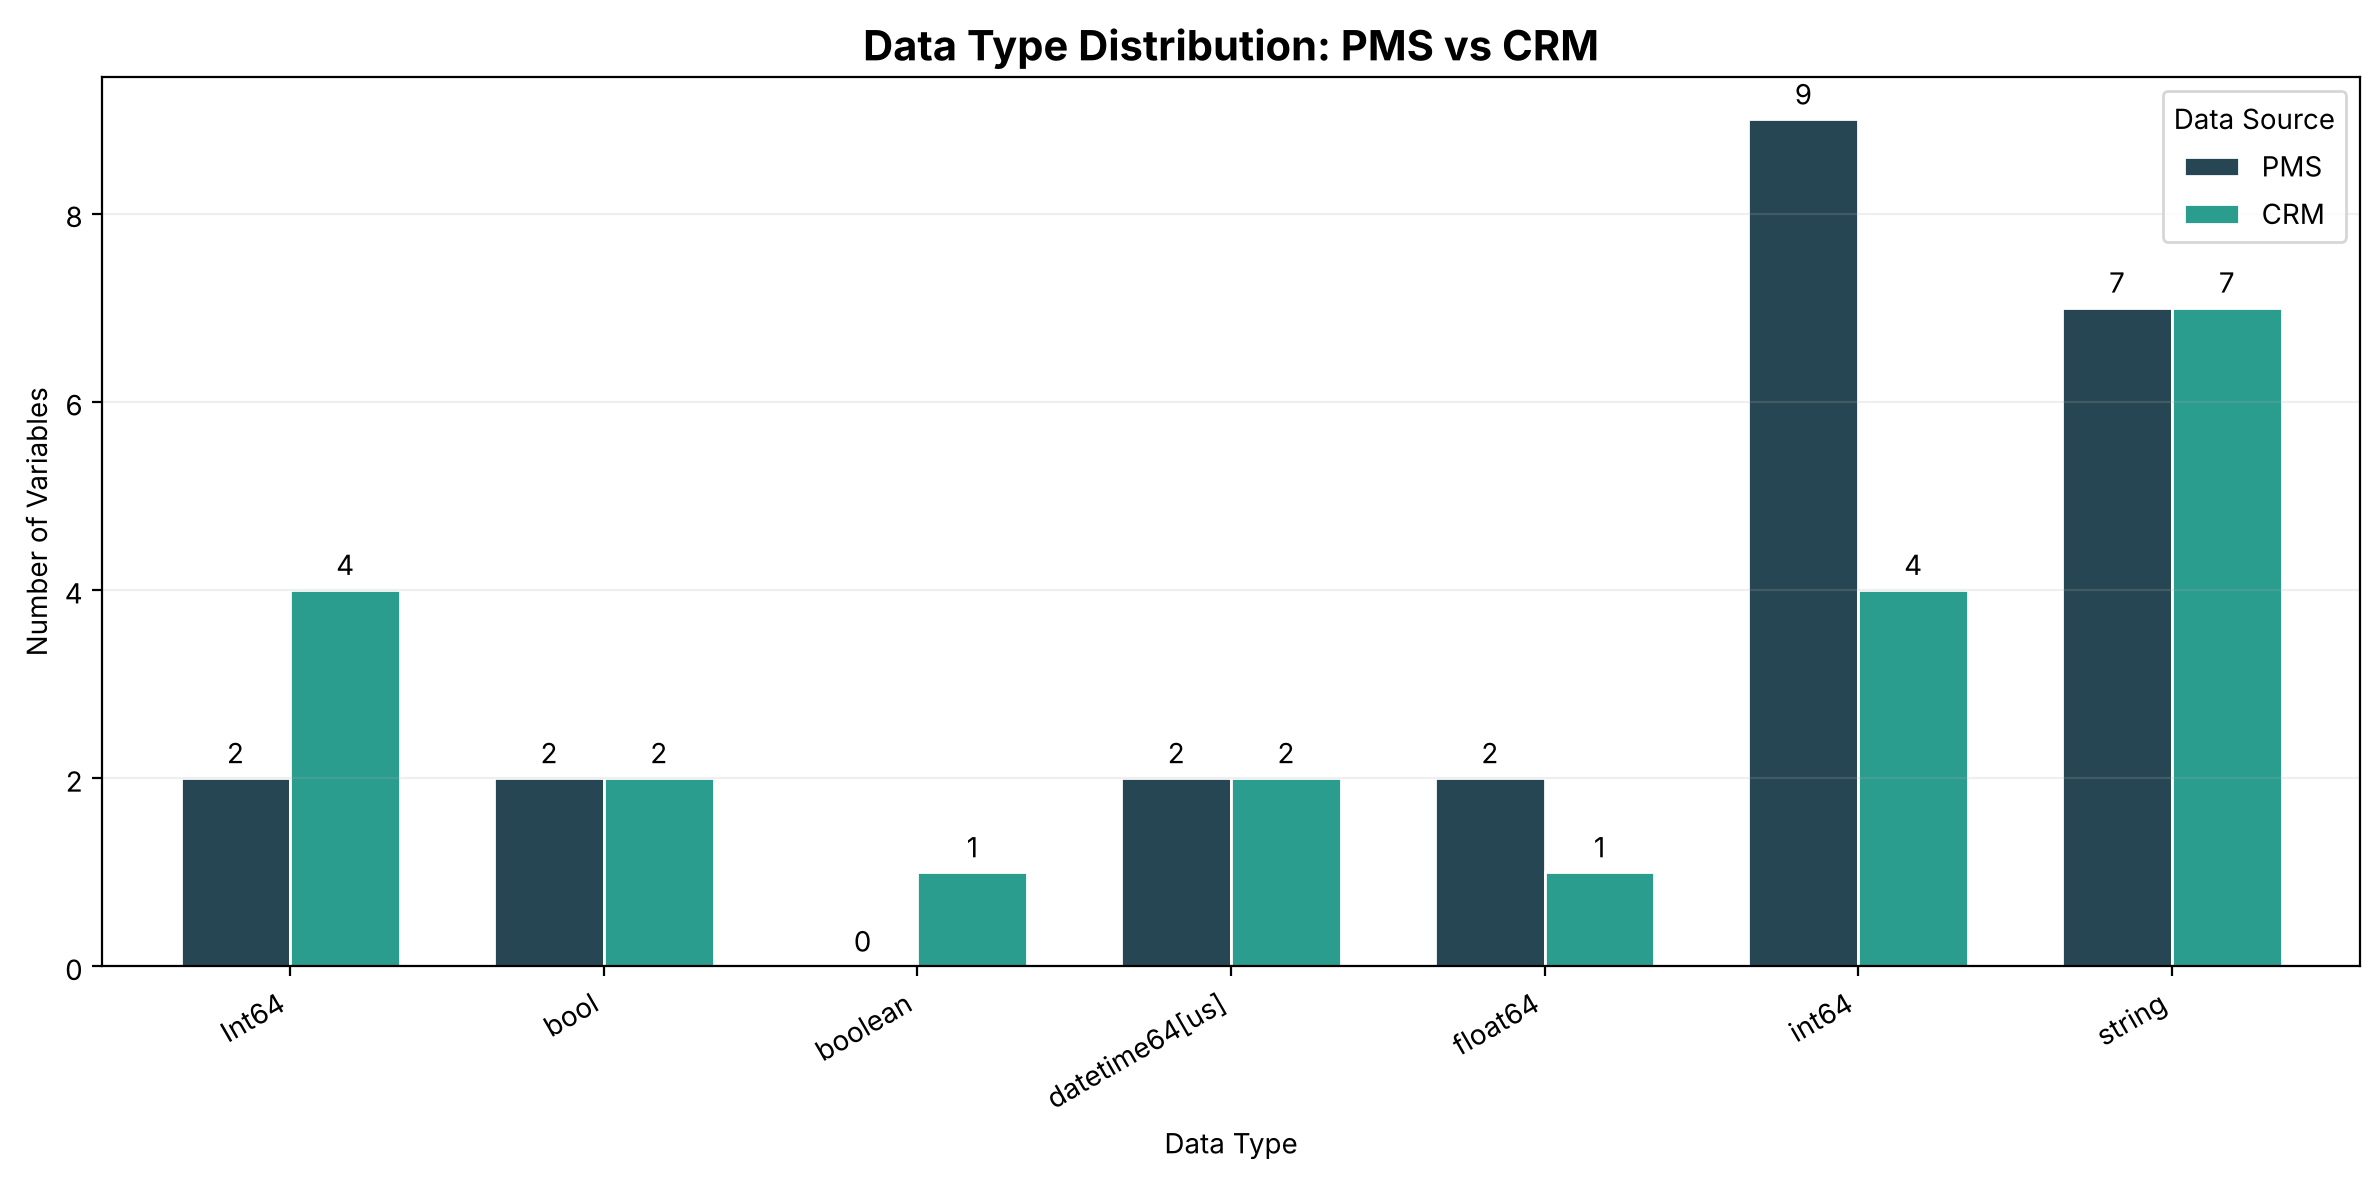

In [157]:
# Visualize data type distributions

ax = dtype_distribution.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#264653", "#2A9D8F"],
    width=0.7,
    edgecolor="white"
)

# Customize the visualization

plt.title(
    "Data Type Distribution: PMS vs CRM",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Data Type")
plt.ylabel("Number of Variables")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Data Source")
plt.grid(axis="y", alpha=0.2)

# Add numerical labels

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

In [158]:
# Calculate missing value percentages by variable

pms_missing_profile = (
    pms.isna().mean() * 100
).sort_values(ascending=False)

crm_missing_profile = (
    crm.isna().mean() * 100
).sort_values(ascending=False)

# Retain only variables containing missing values

pms_missing_profile = pms_missing_profile[
    pms_missing_profile > 0
]

crm_missing_profile = crm_missing_profile[
    crm_missing_profile > 0
]

# Display missing value percentages

print("PMS Missing Values (%):")
display(pms_missing_profile.round(2).to_frame("Missing (%)"))

print("\nCRM Missing Values (%):")
display(crm_missing_profile.round(2).to_frame("Missing (%)"))

PMS Missing Values (%):


,Missing (%)
children,3.34
meal,2.00
adr,0.66
adr_before_correction,0.49
stays_in_week_nights,0.14



CRM Missing Values (%):


,Missing (%)
company_id,94.38
agent_id,13.47
total_price,2.00
zero_adults_flag,1.00
n_adults,1.00
guest_country,0.47
lead_time_days,0.10


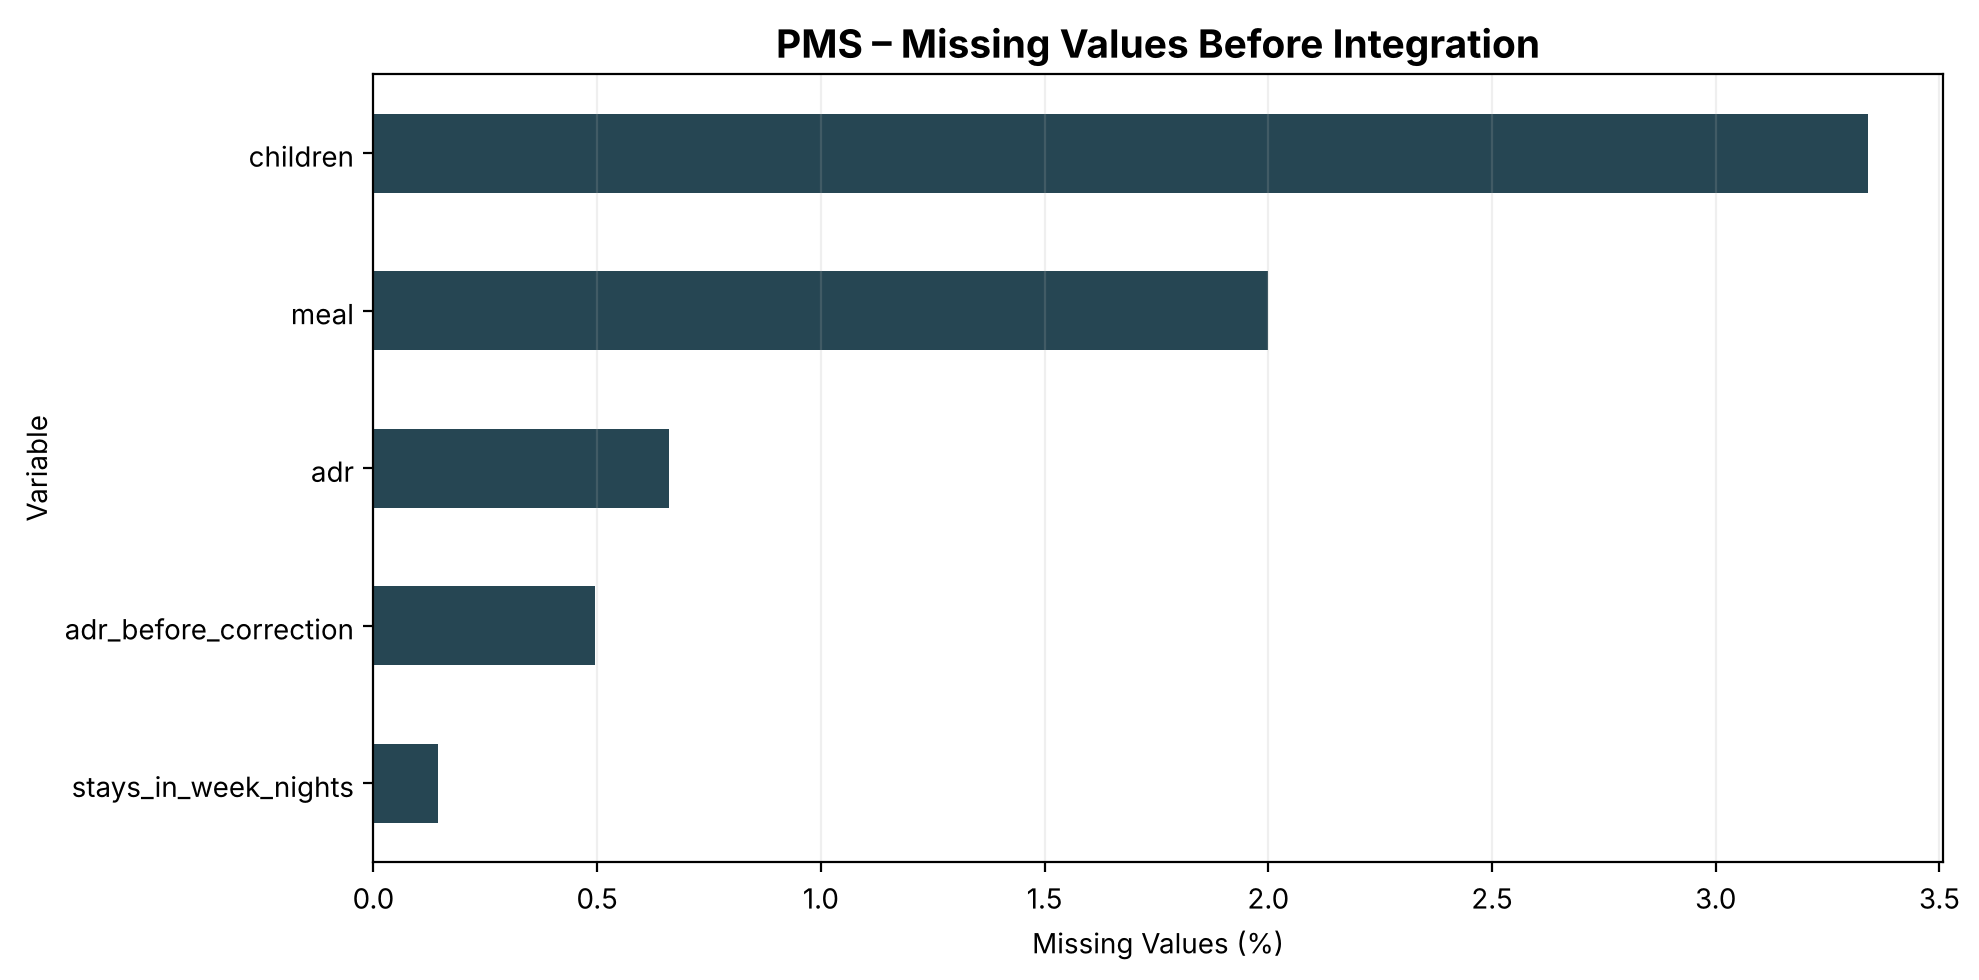

In [159]:
# Visualize PMS missing values

plt.figure(figsize=(10, 5))

pms_missing_profile.sort_values().plot(
    kind="barh",
    color="#264653"
)

plt.title(
    "PMS – Missing Values Before Integration",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Variable")
plt.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

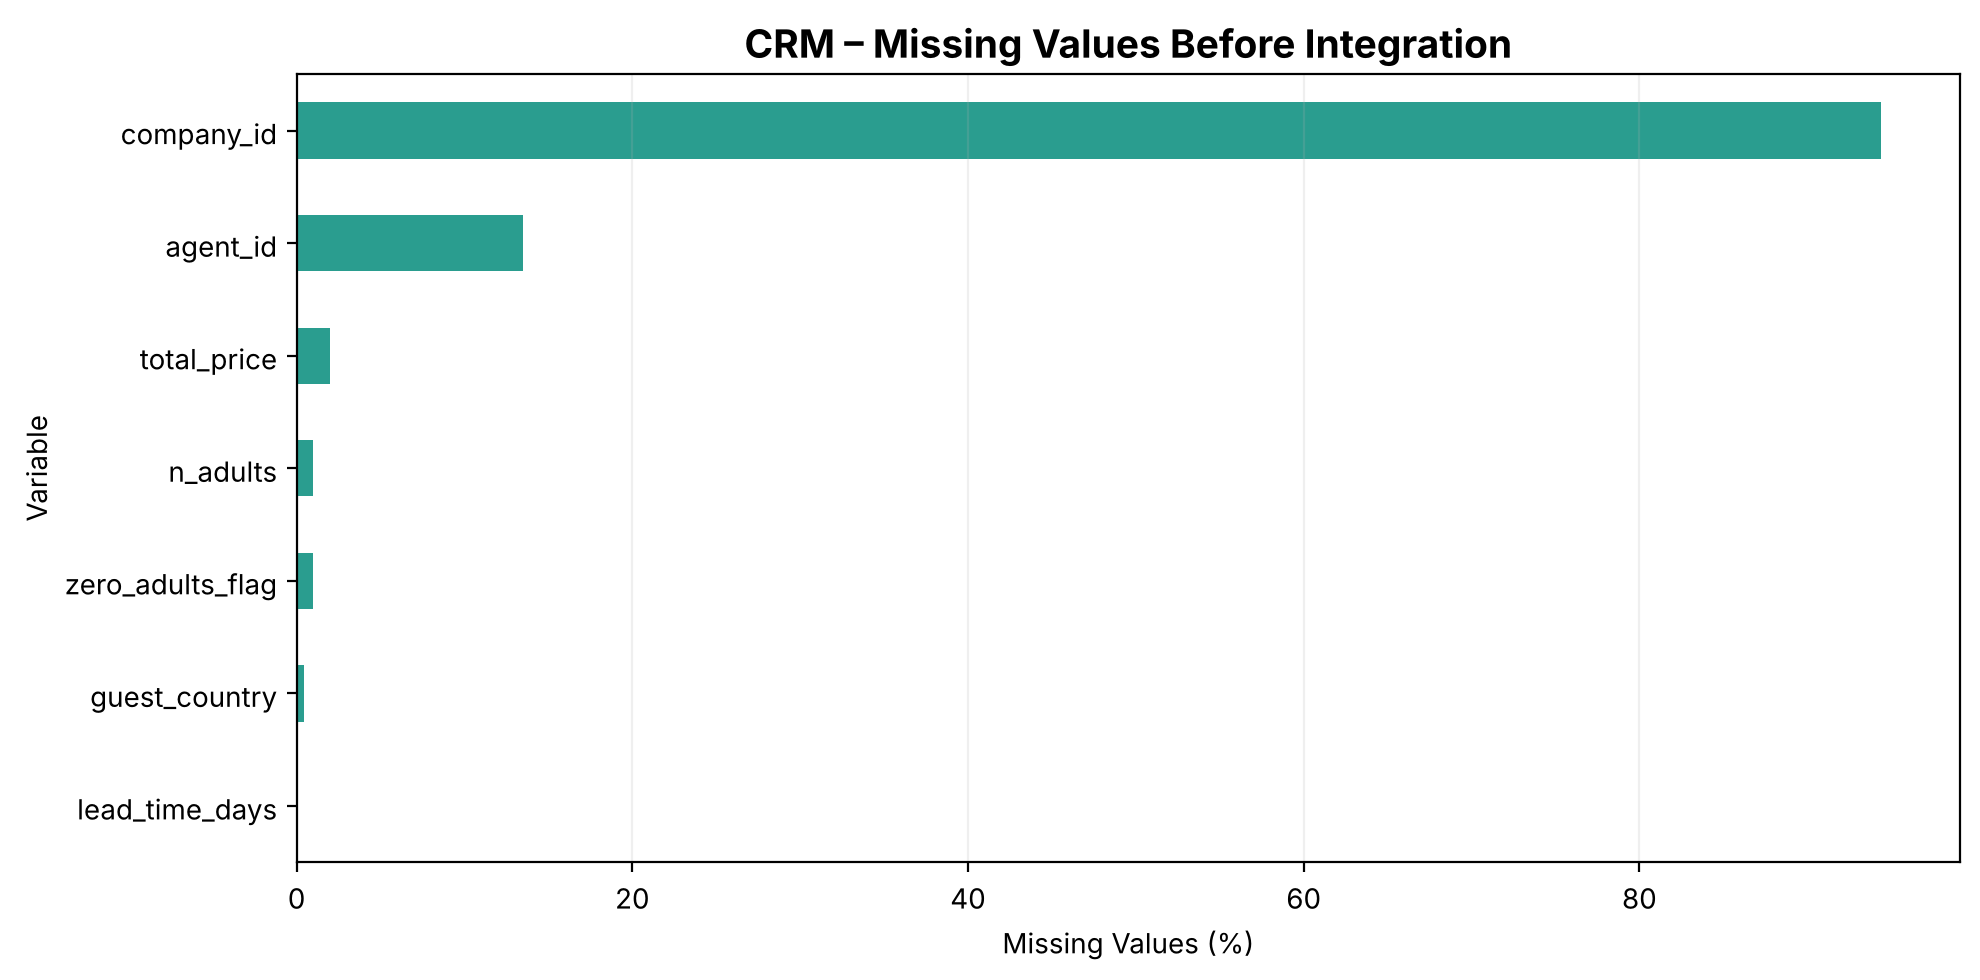

In [160]:
# Visualize CRM missing values

plt.figure(figsize=(10, 5))

crm_missing_profile.sort_values().plot(
    kind="barh",
    color="#2A9D8F"
)

plt.title(
    "CRM – Missing Values Before Integration",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Variable")
plt.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

Results & Interpretation

The preliminary comparison confirms that both cleaned datasets have preserved their expected structural characteristics and provide a suitable starting point for the integration process.

PMS Dataset

The PMS dataset contains 24,250 records, 24 variables and 582,000 data cells.

A total of 1,610 missing values were identified across five variables, corresponding to an overall missing value rate of 0.28% and a data completeness rate of 99.72%.

The main variables affected by missing information are:

* children: 3.34%
* meal: 2.00%
* adr: 0.66%
* adr_before_correction: 0.49%
* stays_in_week_nights: 0.14%

The adr_before_correction variable is an audit field retained for traceability purposes rather than a primary analytical variable.

No fully duplicated records were identified.

CRM Dataset

The CRM dataset contains 24,500 records, 21 variables and 514,500 data cells.

A total of 27,545 missing values were identified across seven variables, corresponding to an overall missing value rate of 5.35% and a data completeness rate of 94.65%.

The highest concentrations of missing values are observed in:

* company_id: 94.38%
* agent_id: 13.47%
* total_price: 2.00%
* n_adults: 1.00%
* zero_adults_flag: 1.00%
* guest_country: 0.47%
* lead_time_days: approximately 0.10%

The company_id and agent_id variables account for approximately 95.9% of all CRM missing values.

These missing values may reflect the absence of corporate or intermediary involvement rather than incorrect or incomplete data collection. Their interpretation therefore requires consideration of the underlying business context.

No fully duplicated records were identified.

Comparative Assessment

The PMS dataset exhibits a higher overall completeness rate than the CRM dataset, with a difference of 5.07 percentage points.

However, this difference should not be interpreted as direct evidence of superior PMS reliability, since the datasets contain different variables, serve different business purposes and include potentially non-applicable fields.

The data type distribution also confirms that both datasets contain appropriately represented textual, numerical, boolean and datetime variables, following the preceding standardization process.

Integration Implications

The preliminary assessment identifies several potential opportunities for cross-source missing value recovery, particularly where equivalent information is available in both systems.

However, recovery decisions will depend on successful booking-level matching, semantic equivalence and the reliability of the alternative information source.

Both datasets are structurally prepared for the pre-merge assessment, while remaining data quality limitations will be investigated during the subsequent integration stages.

# 3. Pre-Merge Analysis

Before integrating the PMS and CRM datasets, a comprehensive pre-merge assessment is conducted to evaluate the feasibility, reliability and expected coverage of the integration process.

The assessment focuses on booking identifier compatibility, completeness, uniqueness, formatting consistency, record overlap and the identification of shared and complementary variables.

This preliminary stage is essential to prevent artificial record duplication, incorrect booking associations and unintended information loss during the merge.

3.1 Identification of Merge Keys

A successful booking-level integration requires a common identifier capable of linking corresponding records across both information systems.

The following variables have been identified as candidate merge keys:

* PMS: booking_id
* CRM: BookingRef

Although these variables have different column names, they appear to represent the same underlying business entity: an individual hotel booking.

Their suitability as merge keys will be evaluated through data type validation, completeness assessment, uniqueness checks, format analysis and record-level matching.

The objective is to establish a reliable booking-level relationship between the two datasets before executing the integration process.

In [161]:
# Define the candidate merge keys

pms_key = "booking_id"
crm_key = "BookingRef"

# Verify that both merge keys exist

key_availability = pd.DataFrame({
    "Dataset": ["PMS", "CRM"],
    "Merge Key": [pms_key, crm_key],
    "Key Available": [
        pms_key in pms.columns,
        crm_key in crm.columns
    ]
})

# Display the merge key availability

display(key_availability)

,Dataset,Merge Key,Key Available
0,PMS,booking_id,True
1,CRM,BookingRef,True


In [162]:
# Display sample booking identifiers from both systems

print("PMS Booking Identifier Examples:")
display(pms[[pms_key]].head(10))

print("\nCRM Booking Identifier Examples:")
display(crm[[crm_key]].head(10))

PMS Booking Identifier Examples:


,booking_id
0,BK317616
1,BK314798
2,BK304643
3,BK305980
4,BK303821
5,BK314684
6,BK312590
7,BK324411
8,BK314494
9,BK301131



CRM Booking Identifier Examples:


,BookingRef
0,BK310511
1,BK300310
2,BK302934
3,BK320441
4,BK316173
5,BK312393
6,BK322748
7,BK309087
8,BK311332
9,BK319879


In [163]:
# Ensure that both merge keys are available

assert pms_key in pms.columns, "PMS merge key not found."

assert crm_key in crm.columns, "CRM merge key not found."

print("Both candidate merge keys are available.")

Both candidate merge keys are available.


3.2 Merge Key Data Type Validation

Following the identification of the candidate merge keys, their data types are evaluated to ensure technical compatibility between the PMS and CRM datasets.

Both booking identifiers are expected to use the Pandas string data type, as established during the preceding data type restoration process.

Representing booking identifiers as strings preserves their alphanumeric structure and prevents inappropriate numerical interpretation.

This validation aims to confirm that:

* Both merge keys have compatible data types.
* Booking identifiers are represented using the appropriate textual format.
* No further data type conversion is required before integration.

This step establishes technical compatibility between the merge keys. Completeness, uniqueness, formatting consistency and actual record overlap will be assessed separately.

In [164]:
# Validate the data types of both merge keys

key_dtype_validation = pd.DataFrame({
    "Dataset": ["PMS", "CRM"],
    "Merge Key": [pms_key, crm_key],
    "Actual Data Type": [
        str(pms[pms_key].dtype),
        str(crm[crm_key].dtype)
    ],
    "Expected Data Type": ["string", "string"]
})

# Compare actual and expected data types

key_dtype_validation["Status"] = np.where(
    key_dtype_validation["Actual Data Type"] ==
    key_dtype_validation["Expected Data Type"],
    "PASS",
    "FAIL"
)

# Display validation results

display(key_dtype_validation)

,Dataset,Merge Key,Actual Data Type,Expected Data Type,Status
0,PMS,booking_id,string,string,PASS
1,CRM,BookingRef,string,string,PASS


In [165]:
# Verify merge key data type compatibility

assert pms[pms_key].dtype == crm[crm_key].dtype, \
    "Merge key data types are incompatible."

assert key_dtype_validation["Status"].eq("PASS").all(), \
    "Unexpected merge key data type."

print("Merge key data type compatibility: PASS")
print("Both merge keys are ready for further validation.")

Merge key data type compatibility: PASS
Both merge keys are ready for further validation.


Results & Interpretation

Both candidate merge keys successfully passed the data type validation.

The PMS booking_id and CRM BookingRef variables are represented using the Pandas string data type, confirming their technical compatibility.

The data type restoration performed during the preliminary assessment has therefore successfully prepared both identifiers for integration.

No additional data type transformations are required.

However, data type compatibility alone does not guarantee that the identifiers are complete, unique, consistently formatted or associated with corresponding bookings.

These characteristics will be evaluated in the subsequent pre-merge validation steps.

3.3 Merge Key Completeness

Following the successful data type validation, the completeness of the candidate merge keys is assessed.

A complete booking identifier is essential for establishing reliable relationships between the PMS and CRM datasets.

This assessment investigates three potential completeness issues:

* Missing or null booking identifiers.
* Empty string values.
* Booking identifiers containing only whitespace characters.

The completeness rate is calculated as the proportion of records containing a non-missing and non-blank booking identifier relative to the total number of records in each dataset.

The expected completeness rate is 100% for both merge keys.

Records without valid, non-blank identifiers cannot be reliably matched across the two systems and may compromise the integrity of the integration process.

No data modifications are performed during this assessment.

In [166]:
# Assess PMS merge key completeness

pms_key_missing = pms[pms_key].isna().sum()

pms_key_empty = pms[pms_key].eq("").sum()

pms_key_whitespace = (
    pms[pms_key].str.fullmatch(r"\s+", na=False)
).sum()


# Assess CRM merge key completeness

crm_key_missing = crm[crm_key].isna().sum()

crm_key_empty = crm[crm_key].eq("").sum()

crm_key_whitespace = (
    crm[crm_key].str.fullmatch(r"\s+", na=False)
).sum()


# Calculate total incomplete identifiers

pms_key_incomplete = (
    pms_key_missing + pms_key_empty + pms_key_whitespace
)

crm_key_incomplete = (
    crm_key_missing + crm_key_empty + crm_key_whitespace
)

In [167]:
# Calculate merge key completeness rates

pms_key_completeness = (
    1 - pms_key_incomplete / len(pms)
) * 100

crm_key_completeness = (
    1 - crm_key_incomplete / len(crm)
) * 100


# Create a merge key completeness summary

key_completeness_summary = pd.DataFrame({
    "Metric": [
        "Total records",
        "Missing identifiers",
        "Empty identifiers",
        "Whitespace-only identifiers",
        "Total incomplete identifiers",
        "Complete identifiers",
        "Key completeness (%)"
    ],

    "PMS": [
        len(pms),
        pms_key_missing,
        pms_key_empty,
        pms_key_whitespace,
        pms_key_incomplete,
        len(pms) - pms_key_incomplete,
        round(pms_key_completeness, 2)
    ],

    "CRM": [
        len(crm),
        crm_key_missing,
        crm_key_empty,
        crm_key_whitespace,
        crm_key_incomplete,
        len(crm) - crm_key_incomplete,
        round(crm_key_completeness, 2)
    ]
})

# Display completeness assessment results

display(key_completeness_summary)

,Metric,PMS,CRM
0,Total records,24250.0,24500.0
1,Missing identifiers,0.0,0.0
2,Empty identifiers,0.0,0.0
3,Whitespace-only identifiers,0.0,0.0
4,Total incomplete identifiers,0.0,0.0
5,Complete identifiers,24250.0,24500.0
6,Key completeness (%),100.0,100.0


In [168]:
# Validate merge key completeness

assert pms_key_incomplete == 0, \
    "Incomplete PMS booking identifiers detected."

assert crm_key_incomplete == 0, \
    "Incomplete CRM booking identifiers detected."

print("PMS merge key completeness: PASS")
print("CRM merge key completeness: PASS")

print(f"\nPMS completeness rate: {pms_key_completeness:.2f}%")
print(f"CRM completeness rate: {crm_key_completeness:.2f}%")

PMS merge key completeness: PASS
CRM merge key completeness: PASS

PMS completeness rate: 100.00%
CRM completeness rate: 100.00%


Results & Interpretation

Both candidate merge keys successfully passed the completeness assessment.

The PMS dataset contains 24,250 complete booking identifiers, while the CRM dataset contains 24,500 complete booking identifiers.

Key findings:

* No missing booking identifiers were detected.
* No empty string identifiers were identified.
* No whitespace-only identifiers were detected.
* Both merge keys achieved a completeness rate of 100%.
* No records require exclusion due to missing or blank booking identifiers.

These results confirm that booking identifier completeness does not represent a barrier to the integration process.

From an integration perspective, every record contains a non-missing and non-blank identifier that can be evaluated for cross-system matching.

However, complete identifiers do not necessarily guarantee uniqueness, correct formatting or successful matching between the two datasets.

These additional requirements will be evaluated in the subsequent pre-merge assessment stages.

3.4 Merge Key Uniqueness

Following the successful completeness assessment, the uniqueness of the candidate merge keys is evaluated to determine the expected relationship between the PMS and CRM datasets.

Unique booking identifiers are essential for establishing a one-to-one relationship between corresponding records.

Duplicate booking identifiers could generate unintended row multiplication during the integration process, potentially distorting booking counts, financial metrics and subsequent business analyses.

This assessment focuses on:

* Total number of booking identifiers.
* Number of distinct booking identifiers.
* Number of duplicate identifier occurrences.
* Number of records affected by duplicated identifiers.
* Merge key uniqueness rates.
* Suitability for a one-to-one integration.

The expected outcome is a uniqueness rate of 100% in both datasets.

No records are removed or modified during this assessment. Any detected duplicate identifiers must be investigated before proceeding with the integration.

In [169]:
# Calculate the number of unique booking identifiers

pms_unique_keys = pms[pms_key].nunique()
crm_unique_keys = crm[crm_key].nunique()


# Identify duplicate identifier occurrences

pms_duplicate_keys = pms[pms_key].duplicated().sum()
crm_duplicate_keys = crm[crm_key].duplicated().sum()


# Identify all records affected by duplicated identifiers

pms_duplicate_records = (
    pms[pms_key].duplicated(keep=False).sum()
)

crm_duplicate_records = (
    crm[crm_key].duplicated(keep=False).sum()
)


# Calculate merge key uniqueness rates

pms_key_uniqueness = (
    pms_unique_keys / len(pms)
) * 100

crm_key_uniqueness = (
    crm_unique_keys / len(crm)
) * 100

In [170]:
# Create a merge key uniqueness summary

key_uniqueness_summary = pd.DataFrame({
    "Metric": [
        "Total records",
        "Unique booking identifiers",
        "Duplicate identifier occurrences",
        "Records affected by duplicate identifiers",
        "Key uniqueness (%)"
    ],

    "PMS": [
        len(pms),
        pms_unique_keys,
        pms_duplicate_keys,
        pms_duplicate_records,
        round(pms_key_uniqueness, 2)
    ],

    "CRM": [
        len(crm),
        crm_unique_keys,
        crm_duplicate_keys,
        crm_duplicate_records,
        round(crm_key_uniqueness, 2)
    ]
})

# Display the uniqueness assessment

display(key_uniqueness_summary)

,Metric,PMS,CRM
0,Total records,24250.0,24500.0
1,Unique booking identifiers,24250.0,24500.0
2,Duplicate identifier occurrences,0.0,0.0
3,Records affected by duplicate identifiers,0.0,0.0
4,Key uniqueness (%),100.0,100.0


In [171]:
# Validate merge key uniqueness

assert pms[pms_key].is_unique, \
    "Duplicate PMS booking identifiers detected."

assert crm[crm_key].is_unique, \
    "Duplicate CRM booking identifiers detected."


# Confirm merge key uniqueness

print("PMS merge key uniqueness: PASS")
print("CRM merge key uniqueness: PASS")

print(f"\nPMS uniqueness rate: {pms_key_uniqueness:.2f}%")
print(f"CRM uniqueness rate: {crm_key_uniqueness:.2f}%")

print("\nExpected merge relationship: One-to-One (1:1)")

PMS merge key uniqueness: PASS
CRM merge key uniqueness: PASS

PMS uniqueness rate: 100.00%
CRM uniqueness rate: 100.00%

Expected merge relationship: One-to-One (1:1)


Results & Interpretation

Both candidate merge keys successfully passed the uniqueness assessment.

The PMS dataset contains 24,250 distinct booking identifiers, while the CRM dataset contains 24,500 distinct booking identifiers.

Key findings:

* No duplicate booking identifier occurrences were detected in either dataset.
* No records are affected by duplicated booking identifiers.
* Both datasets achieved a merge key uniqueness rate of 100%.
* No duplicate-related record removal or additional cleaning is required.
* Both datasets satisfy the key uniqueness requirements for a one-to-one integration.

The absence of duplicate booking identifiers eliminates the risk of row multiplication caused by duplicated merge keys.

This is particularly important for preserving the accuracy of booking counts, financial calculations and subsequent business performance indicators.

Based on the completeness and uniqueness assessments, the integration is expected to follow a one-to-one relationship at the booking level.

However, uniqueness does not guarantee complete overlap between the two systems. Booking identifier formatting and actual cross-system matching coverage must still be evaluated before the integration is executed.

3.5 Booking ID Format Consistency

Following the completeness and uniqueness assessments, the formatting consistency of the candidate merge keys is evaluated.

Based on the preliminary inspection of booking identifiers, both systems appear to follow a common alphanumeric structure consisting of the prefix BK followed by six numerical digits.

The assessment investigates:

* Compliance with the observed booking identifier pattern.
* Consistency of identifier length.
* Presence of leading or trailing whitespace.
* Potential formatting differences that could prevent successful cross-system matching.

Regular expressions are used to assess formatting consistency across all booking identifiers in both datasets.

The observed format is treated as an inferred validation rule rather than an independently documented system specification.

No automatic corrections are applied during this assessment. Any formatting discrepancies must be investigated before modifying booking identifiers, as inappropriate corrections could generate incorrect booking associations or duplicate keys.

In [172]:
# Define the expected booking identifier pattern

booking_id_pattern = r"BK[0-9]{6}"


# Validate the PMS booking identifier format

pms_valid_format = pms[pms_key].str.fullmatch(
    booking_id_pattern,
    na=False
)


# Validate the CRM booking identifier format

crm_valid_format = crm[crm_key].str.fullmatch(
    booking_id_pattern,
    na=False
)


# Count identifiers with valid and invalid formats

pms_valid_ids = pms_valid_format.sum()
pms_invalid_ids = (~pms_valid_format).sum()

crm_valid_ids = crm_valid_format.sum()
crm_invalid_ids = (~crm_valid_format).sum()

In [173]:
# Identify booking identifiers with unexpected lengths

pms_invalid_length = (
    pms[pms_key].str.len() != 8
).sum()

crm_invalid_length = (
    crm[crm_key].str.len() != 8
).sum()


# Identify leading or trailing whitespace

pms_whitespace_issues = (
    pms[pms_key] != pms[pms_key].str.strip()
).sum()

crm_whitespace_issues = (
    crm[crm_key] != crm[crm_key].str.strip()
).sum()


# Calculate format validity rates

pms_format_validity = (
    pms_valid_ids / len(pms)
) * 100

crm_format_validity = (
    crm_valid_ids / len(crm)
) * 100

In [174]:
# Create a booking identifier format summary

key_format_summary = pd.DataFrame({
    "Metric": [
        "Total booking identifiers",
        "Valid identifier format",
        "Invalid identifier format",
        "Unexpected identifier length",
        "Leading or trailing whitespace",
        "Format validity (%)"
    ],

    "PMS": [
        len(pms),
        pms_valid_ids,
        pms_invalid_ids,
        pms_invalid_length,
        pms_whitespace_issues,
        round(pms_format_validity, 2)
    ],

    "CRM": [
        len(crm),
        crm_valid_ids,
        crm_invalid_ids,
        crm_invalid_length,
        crm_whitespace_issues,
        round(crm_format_validity, 2)
    ]
})

# Display the format assessment results

display(key_format_summary)

,Metric,PMS,CRM
0,Total booking identifiers,24250.0,24500.0
1,Valid identifier format,24250.0,24500.0
2,Invalid identifier format,0.0,0.0
3,Unexpected identifier length,0.0,0.0
4,Leading or trailing whitespace,0.0,0.0
5,Format validity (%),100.0,100.0


In [175]:
# Inspect PMS identifiers with formatting issues

if pms_invalid_ids > 0:
    print("PMS identifiers with formatting issues:")
    display(pms.loc[~pms_valid_format, [pms_key]].head(20))
else:
    print("No PMS identifier formatting issues detected.")


# Inspect CRM identifiers with formatting issues

if crm_invalid_ids > 0:
    print("\nCRM identifiers with formatting issues:")
    display(crm.loc[~crm_valid_format, [crm_key]].head(20))
else:
    print("No CRM identifier formatting issues detected.")

No PMS identifier formatting issues detected.
No CRM identifier formatting issues detected.


In [176]:
# Validate compliance with the expected identifier format

assert pms_invalid_ids == 0, \
    "Unexpected PMS identifier formats detected."

assert crm_invalid_ids == 0, \
    "Unexpected CRM identifier formats detected."


# Confirm successful format validation

print("PMS booking ID format consistency: PASS")
print("CRM booking ID format consistency: PASS")

print(f"\nPMS format validity: {pms_format_validity:.2f}%")
print(f"CRM format validity: {crm_format_validity:.2f}%")

print("\nBoth datasets follow the same observed booking ID format.")

PMS booking ID format consistency: PASS
CRM booking ID format consistency: PASS

PMS format validity: 100.00%
CRM format validity: 100.00%

Both datasets follow the same observed booking ID format.


Results & Interpretation

Both candidate merge keys successfully passed the booking identifier format consistency assessment.

All 24,250 PMS identifiers and 24,500 CRM identifiers comply with the observed alphanumeric pattern consisting of the prefix BK followed by six numerical digits.

Key findings:

* Both datasets achieved a format validity rate of 100%.
* No identifiers with unexpected lengths were detected.
* No leading or trailing whitespace issues were identified.
* Both systems follow the same observed booking identifier structure.
* No formatting corrections or additional identifier standardization are required.

The consistent identifier format reduces the risk of unsuccessful matching caused by technical formatting differences.

Combined with the preceding assessments, both merge keys satisfy the technical requirements of data type compatibility, completeness, uniqueness and observed formatting consistency.

However, these results do not guarantee that every booking exists in both systems or that matching identifiers contain consistent business information.

The next stage will evaluate actual booking identifier overlap to quantify matched and unmatched records before executing the integration.

3.6 Matching and Unmatched Records

Following the successful validation of booking identifier completeness, uniqueness and formatting consistency, the actual overlap between the two datasets is evaluated.

Booking identifiers are classified into three mutually exclusive groups:

* Matched bookings: identifiers present in both PMS and CRM.
* PMS-only bookings: identifiers present exclusively in the PMS.
* CRM-only bookings: identifiers present exclusively in the CRM.

Set operations are used to quantify these groups before executing the merge.

This assessment establishes the expected dimensions of the integrated dataset and provides evidence for selecting an appropriate merge strategy.

In [177]:
# Extract unique booking identifiers

pms_ids = set(pms[pms_key])
crm_ids = set(crm[crm_key])

# Identify matched and unmatched bookings

matched_ids = pms_ids & crm_ids
pms_only_ids = pms_ids - crm_ids
crm_only_ids = crm_ids - pms_ids

# Calculate the total number of distinct bookings

all_booking_ids = pms_ids | crm_ids

# Create a booking overlap summary

matching_summary = pd.DataFrame({
    "Booking Category": [
        "Matched bookings",
        "PMS-only bookings",
        "CRM-only bookings",
        "Total distinct bookings"
    ],
    "Number of Bookings": [
        len(matched_ids),
        len(pms_only_ids),
        len(crm_only_ids),
        len(all_booking_ids)
    ]
})

display(matching_summary)

,Booking Category,Number of Bookings
0,Matched bookings,23750
1,PMS-only bookings,500
2,CRM-only bookings,750
3,Total distinct bookings,25000


In [178]:
# Validate the booking overlap calculations

assert len(matched_ids) + len(pms_only_ids) == len(pms)

assert len(matched_ids) + len(crm_only_ids) == len(crm)

assert (
    len(matched_ids) +
    len(pms_only_ids) +
    len(crm_only_ids)
) == len(all_booking_ids)

print("Booking overlap validation: PASS")

print(f"Expected outer merge records: {len(all_booking_ids):,}")

Booking overlap validation: PASS
Expected outer merge records: 25,000


3.7 Matching Rate Analysis

To evaluate integration coverage, booking matching rates are calculated using three complementary perspectives:

* PMS matching rate: proportion of PMS bookings also present in the CRM.
* CRM matching rate: proportion of CRM bookings also present in the PMS.
* Overall matching rate: proportion of matched bookings relative to the total number of distinct bookings across both systems.

These indicators quantify the degree of overlap between the two information systems and provide insights into potential coverage differences.

A visual representation of matched and unmatched bookings is also provided to support the interpretation of integration coverage.

In [179]:
# Calculate matching rates

pms_matching_rate = len(matched_ids) / len(pms_ids) * 100

crm_matching_rate = len(matched_ids) / len(crm_ids) * 100

overall_matching_rate = (
    len(matched_ids) / len(all_booking_ids) * 100
)

# Create a matching rate summary

matching_rate_summary = pd.DataFrame({
    "Metric": [
        "PMS matching rate (%)",
        "CRM matching rate (%)",
        "Overall matching rate (%)"
    ],
    "Value": [
        round(pms_matching_rate, 2),
        round(crm_matching_rate, 2),
        round(overall_matching_rate, 2)
    ]
})

display(matching_rate_summary)

,Metric,Value
0,PMS matching rate (%),97.94
1,CRM matching rate (%),96.94
2,Overall matching rate (%),95.00


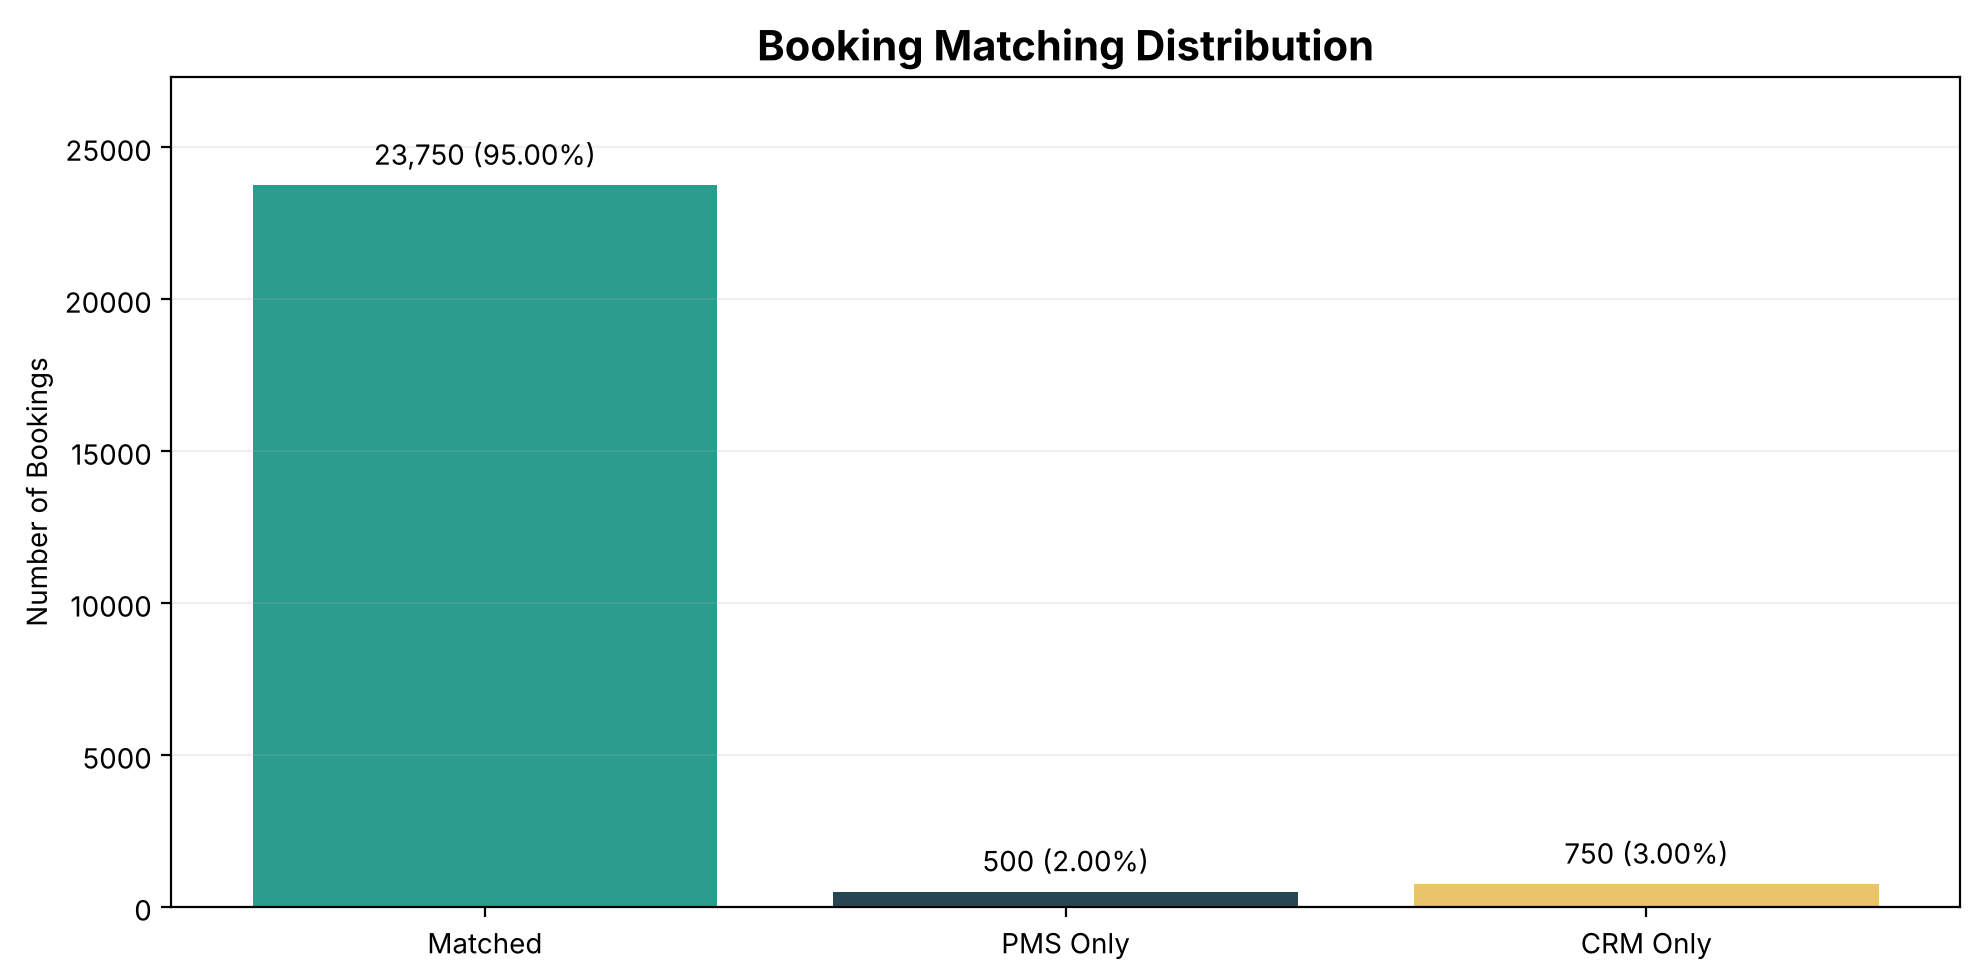

In [180]:
# Define booking categories and counts

categories = [
    "Matched",
    "PMS Only",
    "CRM Only"
]

counts = [
    len(matched_ids),
    len(pms_only_ids),
    len(crm_only_ids)
]

# Visualize booking overlap

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    categories,
    counts,
    color=["#2A9D8F", "#264653", "#E9C46A"]
)

# Add counts and percentages

labels = [
    f"{count:,} ({count / len(all_booking_ids):.2%})"
    for count in counts
]

ax.bar_label(bars, labels=labels, padding=5)

ax.set_title(
    "Booking Matching Distribution",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Number of Bookings")
ax.set_ylim(0, max(counts) * 1.15)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

Results & Interpretation

The booking overlap assessment identified a total of 25,000 distinct bookings across the PMS and CRM datasets.

Key findings:

* 23,750 bookings are present in both systems, representing 95% of all distinct bookings.
* 500 bookings are present exclusively in the PMS, representing 2% of all distinct bookings.
* 750 bookings are present exclusively in the CRM, representing 3% of all distinct bookings.
* The PMS matching rate is 97.94%.
* The CRM matching rate is 96.94%.

The results demonstrate a high degree of overlap between the two systems, supporting the suitability of booking identifiers as integration keys.

Nevertheless, 1,250 bookings are available in only one source. An inner join would exclude these records, resulting in a loss of 5% of the distinct bookings available across the two cleaned datasets.

A full outer join is therefore selected as the integration strategy to maximize booking coverage, preserve available information and maintain transparency regarding source availability.

The expected integrated dataset will contain 25,000 unique booking records.

Unmatched bookings will be retained and explicitly identified throughout the subsequent integration and data quality assessment.

3.8 Shared and Complementary Variables

Before merging the datasets, a semantic comparison of their variables is performed to identify overlapping and complementary information.

Variables are classified into three main categories:

* Shared variables: fields representing equivalent or closely related business concepts across both systems.
* PMS-specific variables: operational information primarily related to hotel stays, room allocation and booking management.
* CRM-specific variables: information primarily related to customer segmentation, distribution channels and reservation management.

Identifying shared variables is essential for subsequent cross-system consistency checks and data reconciliation.

Variables representing related but differently defined concepts are retained separately until their comparability has been assessed.

Complementary variables are preserved to maximize the analytical value of the integrated dataset.

In [181]:
# Identify shared or conceptually related variables

variable_mapping = pd.DataFrame({
    "Business Concept": [
        "Booking identifier",
        "Hotel property",
        "Arrival date",
        "Number of adults",
        "Reservation outcome"
    ],

    "PMS Variable": [
        "booking_id",
        "hotel",
        "arrival_date",
        "adults",
        "is_canceled"
    ],

    "CRM Variable": [
        "BookingRef",
        "property",
        "checkin_date",
        "n_adults",
        "reservation_status"
    ],

    "Relationship": [
        "Merge key",
        "Equivalent concept",
        "Equivalent concept",
        "Equivalent concept",
        "Related concept - requires harmonization"
    ]
})

# Validate that all mapped columns exist

assert variable_mapping["PMS Variable"].isin(pms.columns).all()

assert variable_mapping["CRM Variable"].isin(crm.columns).all()

display(variable_mapping)

,Business Concept,PMS Variable,CRM Variable,Relationship
0,Booking identifier,booking_id,BookingRef,Merge key
1,Hotel property,hotel,property,Equivalent concept
2,Arrival date,arrival_date,checkin_date,Equivalent concept
3,Number of adults,adults,n_adults,Equivalent concept
4,Reservation outcome,is_canceled,reservation_status,Related concept - requires harmonization


In [182]:
# Identify variables outside the initial semantic mapping

pms_specific_variables = [
    col for col in pms.columns
    if col not in variable_mapping["PMS Variable"].values
]

crm_specific_variables = [
    col for col in crm.columns
    if col not in variable_mapping["CRM Variable"].values
]

# Summarize variable classification

variable_classification = pd.DataFrame({
    "Category": [
        "Mapped variable pairs",
        "PMS remaining variables",
        "CRM remaining variables"
    ],
    "Number": [
        len(variable_mapping),
        len(pms_specific_variables),
        len(crm_specific_variables)
    ]
})

display(variable_classification)

# Display remaining variables

print("PMS remaining variables:")
print(pms_specific_variables)

print("\nCRM remaining variables:")
print(crm_specific_variables)

,Category,Number
0,Mapped variable pairs,5
1,PMS remaining variables,19
2,CRM remaining variables,16


PMS remaining variables:
['arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'children', 'babies', 'meal', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'record_updated_at', 'adr_before_correction', 'adr_scale_corrected', 'adr_negative_flag']

CRM remaining variables:
['lead_time_days', 'guest_country', 'market_segment', 'distribution_channel', 'customer_type', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'agent_id', 'company_id', 'days_in_waiting_list', 'reservation_status_date', 'total_price', 'zero_adults_flag', 'zero_price_flag', 'status_date_flag']


3.9 Pre-Merge Conclusions

The pre-merge assessment established the technical suitability of the PMS and CRM datasets for booking-level integration.

Data integration readiness

* Merge key availability: confirmed.
* Data type compatibility: confirmed.
* Merge key completeness: 100% in both datasets.
* Merge key uniqueness: 100% in both datasets.
* Observed booking identifier format consistency: 100%.
* Expected merge relationship: one-to-one.

Integration coverage

The assessment identified 23,750 matched bookings, 500 PMS-only bookings and 750 CRM-only bookings, resulting in a total population of 25,000 distinct booking identifiers.

The overall matching rate of 95% demonstrates substantial overlap between the two systems.

Integration strategy

A full outer join has been selected to preserve all available bookings across the two cleaned datasets and avoid excluding records available in only one system.

Source availability will be documented using a merge indicator, allowing matched and unmatched bookings to be identified throughout subsequent analyses.

Expected integration outcome

The integrated dataset is expected to contain 25,000 unique booking records, with one row per distinct booking identifier.

Shared and related variables will subsequently undergo cross-system consistency assessment and reconciliation, while complementary information will be preserved to support comprehensive business analysis.

The datasets are now ready for the integration stage.

# 4. Data Integration & Merge

4.1 Merge Strategy Selection

Based on the results of the pre-merge assessment, a full outer join is selected as the most appropriate integration strategy.

Alternative join strategies were evaluated in terms of booking coverage and potential information loss.

An inner join would retain only 23,750 matched bookings, excluding 1,250 records available exclusively in one system. A left join would exclude 750 CRM-only bookings, while a right join would exclude 500 PMS-only bookings.

The full outer join preserves all 25,000 distinct bookings available across the two cleaned datasets, ensuring maximum booking coverage.

The integration is performed using a one-to-one relationship, with an explicit merge indicator to maintain transparency regarding the original source availability of each booking.

At this stage, original business variables are preserved without reconciliation to enable subsequent cross-system consistency checks.

In [183]:
# Compare alternative integration strategies

merge_strategy_comparison = pd.DataFrame({
    "Merge Strategy": [
        "Inner Join",
        "Left Join (PMS)",
        "Right Join (CRM)",
        "Full Outer Join"
    ],
    "Expected Records": [
        len(matched_ids),
        len(pms_ids),
        len(crm_ids),
        len(all_booking_ids)
    ]
})

merge_strategy_comparison["Excluded Bookings"] = (
    len(all_booking_ids) -
    merge_strategy_comparison["Expected Records"]
)

merge_strategy_comparison["Coverage (%)"] = (
    merge_strategy_comparison["Expected Records"] /
    len(all_booking_ids) * 100
).round(2)

display(merge_strategy_comparison)

,Merge Strategy,Expected Records,Excluded Bookings,Coverage (%)
0,Inner Join,23750,1250,95.0
1,Left Join (PMS),24250,750,97.0
2,Right Join (CRM),24500,500,98.0
3,Full Outer Join,25000,0,100.0


### 4.2 Dataset Integration

The CRM booking identifier is renamed to match the PMS booking identifier, creating a standardized integration key without modifying either original cleaned dataset.

A full outer merge is then performed using the common booking identifier.

The one-to-one relationship is explicitly validated during execution to prevent unintended record multiplication.

A merge indicator is generated to preserve information about booking availability across the two source systems.

In [184]:
# Create copies for integration

pms_merge = pms.copy()

crm_merge = crm.rename(
    columns={"BookingRef": "booking_id"}
).copy()


# Perform the full outer merge

integrated = pd.merge(
    pms_merge,
    crm_merge,
    on="booking_id",
    how="outer",
    validate="one_to_one",
    indicator=True,
    suffixes=("_pms", "_crm")
)


# Inspect the integrated dataset

print("PMS shape:", pms.shape)
print("CRM shape:", crm.shape)
print("Integrated dataset shape:", integrated.shape)

display(integrated.head())

PMS shape: (24250, 24)
CRM shape: (24500, 21)
Integrated dataset shape: (25000, 45)


,booking_id,hotel,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,reserved_room_type,assigned_room_type,booking_changes,deposit_type,adr,required_car_parking_spaces,total_of_special_requests,is_canceled,record_updated_at,adr_before_correction,adr_scale_corrected,adr_negative_flag,arrival_date,property,checkin_date,n_adults,lead_time_days,guest_country,market_segment,distribution_channel,customer_type,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,agent_id,company_id,days_in_waiting_list,reservation_status,reservation_status_date,total_price,zero_adults_flag,zero_price_flag,status_date_flag,_merge
0,BK300001,Resort Hotel,2016.0,June,26.0,2.0,5,3.0,0,0.0,BB,E,E,0.0,No Deposit,153.24,0.0,2.0,0.0,2016-05-05,153.24,False,False,2016-06-26,Resort Hotel,2016-06-26,3,136,IRL,Direct,Direct,Transient,0.0,0.0,0.0,250,<NA>,0.0,Check-Out,2016-07-03,1072.68,False,False,False,both
1,BK300002,Resort Hotel,2016.0,July,23.0,2.0,5,2.0,1,0.0,BB,A,A,0.0,No Deposit,166.50,0.0,0.0,0.0,2016-07-28,166.50,False,False,2016-07-23,Resort Hotel,2016-07-23,2,135,PRT,Direct,Direct,Transient,0.0,0.0,0.0,250,<NA>,0.0,Check-Out,2016-07-30,1165.50,False,False,False,both
2,BK300003,City Hotel,2016.0,October,20.0,0.0,3,1.0,0,0.0,BB,A,A,1.0,No Deposit,95.50,0.0,1.0,0.0,2016-10-05,95.50,False,False,2016-10-20,City Hotel,2016-10-20,1,205,CHE,Online TA,TA/TO,Transient,0.0,0.0,0.0,9,<NA>,0.0,Check-Out,2016-10-23,286.50,False,False,False,both
3,BK300004,City Hotel,2016.0,July,6.0,0.0,4,2.0,0,0.0,BB,D,D,0.0,No Deposit,127.80,0.0,0.0,1.0,2016-05-18,127.80,False,False,2016-07-06,City Hotel,2016-07-06,2,95,GBR,Online TA,TA/TO,Transient,0.0,0.0,0.0,9,<NA>,0.0,Canceled,2016-06-19,511.20,False,False,False,both
4,BK300005,Resort Hotel,2016.0,August,16.0,1.0,5,2.0,0,0.0,BB,G,G,1.0,No Deposit,269.00,0.0,1.0,0.0,2016-07-29,269.00,False,False,2016-08-16,Resort Hotel,2016-08-16,2,58,ESP,Online TA,TA/TO,Transient,0.0,0.0,0.0,240,<NA>,0.0,Check-Out,2016-08-22,1614.00,False,False,False,both


### 4.3 Merge Indicator Analysis

The merge indicator is transformed into a more descriptive source availability variable.

Each booking is classified as matched, PMS-only or CRM-only.

This classification enables transparent identification of source coverage and supports the distinction between structural missing values caused by source unavailability and missing values already present within the original datasets.

In [185]:
# Rename the merge indicator

integrated = integrated.rename(
    columns={"_merge": "source_availability"}
)


# Standardize source availability labels

integrated["source_availability"] = (
    integrated["source_availability"]
    .cat.rename_categories({
        "both": "Both Systems",
        "left_only": "PMS Only",
        "right_only": "CRM Only"
    })
)


# Create a source availability summary

source_summary = (
    integrated["source_availability"]
    .value_counts()
    .rename_axis("Source Availability")
    .reset_index(name="Number of Bookings")
)

source_summary["Percentage (%)"] = (
    source_summary["Number of Bookings"] /
    len(integrated) * 100
).round(2)

display(source_summary)

,Source Availability,Number of Bookings,Percentage (%)
0,Both Systems,23750,95.0
1,CRM Only,750,3.0
2,PMS Only,500,2.0


### 4.4 Integrated Dataset Validation

Following the integration, a series of validation checks is performed to ensure that the resulting dataset complies with the expected structural and coverage requirements.

The assessment includes booking identifier uniqueness, completeness, expected dataset dimensions, preservation of source identifiers and consistency between observed and expected matching distributions.

These checks ensure that the integration has not introduced unintended record duplication or booking identifier loss.

In [186]:
# Calculate expected integrated dimensions

expected_rows = len(all_booking_ids)

expected_columns = (
    pms.shape[1] + crm.shape[1] - 1 + 1
)


# Perform integration validation checks

integration_checks = {
    "Expected row count":
        len(integrated) == expected_rows,

    "Expected column count":
        integrated.shape[1] == expected_columns,

    "Unique booking identifiers":
        integrated["booking_id"].is_unique,

    "No missing booking identifiers":
        integrated["booking_id"].notna().all(),

    "All booking identifiers preserved":
        set(integrated["booking_id"]) == all_booking_ids,

    "Correct matched booking count":
        (integrated["source_availability"] == "Both Systems").sum()
        == len(matched_ids),

    "Correct PMS-only booking count":
        (integrated["source_availability"] == "PMS Only").sum()
        == len(pms_only_ids),

    "Correct CRM-only booking count":
        (integrated["source_availability"] == "CRM Only").sum()
        == len(crm_only_ids),

    "No missing source availability":
        integrated["source_availability"].notna().all(),

    "No fully duplicated records":
        integrated.duplicated().sum() == 0
}


# Create validation summary

integration_validation = pd.DataFrame({
    "Validation Check": list(integration_checks.keys()),
    "Status": [
        "PASS" if result else "FAIL"
        for result in integration_checks.values()
    ]
})

display(integration_validation)


# Confirm successful integration

assert all(integration_checks.values()), \
    "One or more integration validation checks failed."

print(
    f"Validation completed: "
    f"{sum(integration_checks.values())}/"
    f"{len(integration_checks)} checks passed."
)

,Validation Check,Status
0,Expected row count,PASS
1,Expected column count,PASS
2,Unique booking identifiers,PASS
3,No missing booking identifiers,PASS
4,All booking identifiers preserved,PASS
5,Correct matched booking count,PASS
6,Correct PMS-only booking count,PASS
7,Correct CRM-only booking count,PASS
8,No missing source availability,PASS
9,No fully duplicated records,PASS


Validation completed: 10/10 checks passed.


4.5 Integration Results & Interpretation

The PMS and CRM datasets were successfully integrated through a full outer join, producing a unified dataset containing 25,000 booking records and 45 variables.

Key integration results

* Total integrated bookings: 25,000.
* Matched bookings: 23,750 (95%).
* PMS-only bookings: 500 (2%).
* CRM-only bookings: 750 (3%).
* Booking coverage across the cleaned sources: 100%.
* Booking identifier uniqueness: 100%.
* Missing booking identifiers: 0.
* Fully duplicated records: 0.
* Integration validation checks: 10 out of 10 passed.

The full outer join successfully preserved all distinct booking identifiers available across the two cleaned datasets, without introducing unintended record multiplication.

The source availability variable provides transparency regarding the origin and availability of booking information.

However, successful structural integration does not guarantee consistency between shared business variables.

Furthermore, unmatched bookings naturally introduce structural missing values because certain information is unavailable from the absent source system.

The next stage will therefore focus on cross-system consistency assessment, identifying discrepancies between corresponding business variables and establishing evidence-based reconciliation rules.

# 5. Cross-Dataset Consistency Assessment

5.1 Comparable Booking Population

Following the successful structural integration of the PMS and CRM datasets, a cross-system consistency assessment is performed to evaluate the reliability of shared and related business information.

The assessment focuses exclusively on bookings available in both systems, corresponding to 23,750 matched booking records.

Unmatched bookings are excluded from direct consistency comparisons because the absence of information from one source does not constitute a contradiction between systems.

For each variable pair, consistency is evaluated using records for which both corresponding values are available and comparable.

Missing information, confirmed discrepancies and non-comparable observations are distinguished throughout the assessment.

Original source values are preserved without modification to support transparent and evidence-based reconciliation.

In [187]:
# Select bookings available in both systems

matched_bookings = integrated.loc[
    integrated["source_availability"] == "Both Systems"
].copy()

# Validate the comparable booking population

assert len(matched_bookings) == len(matched_ids)

print(f"Total integrated bookings: {len(integrated):,}")

print(f"Matched bookings: {len(matched_bookings):,}")

print(
    f"Excluded unmatched bookings: "
    f"{len(integrated) - len(matched_bookings):,}"
)

Total integrated bookings: 25,000
Matched bookings: 23,750
Excluded unmatched bookings: 1,250


### 5.2 Hotel Property Consistency

Hotel property information is compared between the PMS
and CRM datasets using the corresponding variables
`hotel` and `property`.

A reusable consistency assessment function is developed
to standardize the evaluation of shared variables.

Agreement and discrepancy rates are calculated exclusively
among records containing comparable values in both systems.

In [188]:
# Define a reusable cross-system consistency function

def assess_consistency(left, right, concept):

    # Identify comparable records
    comparable = left.notna() & right.notna()

    # Identify agreements and discrepancies
    agreement = comparable & left.eq(right).fillna(False)

    discrepancy = comparable & left.ne(right).fillna(False)

    # Calculate counts
    n_comparable = comparable.sum()
    n_agreements = agreement.sum()
    n_discrepancies = discrepancy.sum()

    # Calculate rates
    agreement_rate = (
        n_agreements / n_comparable * 100
        if n_comparable > 0 else np.nan
    )

    discrepancy_rate = (
        n_discrepancies / n_comparable * 100
        if n_comparable > 0 else np.nan
    )

    # Return summary statistics
    return {
        "Business Concept": concept,
        "Matched Bookings": len(left),
        "Comparable Records": n_comparable,
        "Non-comparable Records": len(left) - n_comparable,
        "Agreements": n_agreements,
        "Discrepancies": n_discrepancies,
        "Agreement (%)": round(agreement_rate, 2),
        "Discrepancy (%)": round(discrepancy_rate, 2)
    }

In [189]:
# Assess hotel property consistency

hotel_consistency = assess_consistency(
    matched_bookings["hotel"],
    matched_bookings["property"],
    "Hotel Property"
)

display(pd.DataFrame([hotel_consistency]))

# Inspect conflicting hotel information

hotel_conflicts = matched_bookings.loc[
    matched_bookings["hotel"].notna() &
    matched_bookings["property"].notna() &
    matched_bookings["hotel"].ne(
        matched_bookings["property"]
    ).fillna(False),
    ["booking_id", "hotel", "property"]
]

display(hotel_conflicts.head(10))

,Business Concept,Matched Bookings,Comparable Records,Non-comparable Records,Agreements,Discrepancies,Agreement (%),Discrepancy (%)
0,Hotel Property,23750,23750,0,23750,0,100.0,0.0


,booking_id,hotel,property


### 5.3 Arrival Date Consistency

Arrival dates are compared across the two systems to
identify discrepancies in the recorded check-in date.

Both variables are evaluated at the calendar-date level.

Date differences are additionally quantified in days
to assess the magnitude of potential inconsistencies.

In [190]:
# Standardize comparisons at calendar-date level

pms_arrival = matched_bookings["arrival_date"].dt.normalize()

crm_arrival = matched_bookings["checkin_date"].dt.normalize()

# Assess arrival date consistency

arrival_consistency = assess_consistency(
    pms_arrival,
    crm_arrival,
    "Arrival Date"
)

display(pd.DataFrame([arrival_consistency]))

# Calculate date differences in days

arrival_difference_days = (
    pms_arrival - crm_arrival
).dt.days

# Inspect non-zero date differences

arrival_conflicts = matched_bookings.loc[
    arrival_difference_days.notna() &
    arrival_difference_days.ne(0),
    ["booking_id", "arrival_date", "checkin_date"]
].copy()

arrival_conflicts["Difference (Days)"] = arrival_difference_days

display(arrival_conflicts.head(10))

display(arrival_conflicts["Difference (Days)"].describe())

,Business Concept,Matched Bookings,Comparable Records,Non-comparable Records,Agreements,Discrepancies,Agreement (%),Discrepancy (%)
0,Arrival Date,23750,23750,0,23705,45,99.81,0.19


,booking_id,arrival_date,checkin_date,Difference (Days)
1022,BK301023,2016-02-27,2016-03-05,-7
1873,BK301874,2016-08-25,2016-08-26,-1
2335,BK302336,2017-04-29,2017-04-28,1
3064,BK303065,2016-10-16,2016-10-23,-7
4332,BK304333,2016-07-02,2016-07-09,-7
4897,BK304898,2016-12-20,2016-12-27,-7
5583,BK305584,2015-08-09,2015-08-08,1
5716,BK305717,2016-10-21,2016-10-20,1
6256,BK306257,2015-09-18,2015-09-17,1
7202,BK307203,2016-04-20,2016-04-19,1


count    45.000000
mean     -2.200000
std       3.368301
min      -7.000000
25%      -7.000000
50%      -1.000000
75%       1.000000
max       1.000000
Name: Difference (Days), dtype: float64

### 5.4 Adult Guest Consistency

The number of adult guests is compared between the
PMS and CRM systems.

Discrepancies may affect guest-based performance
indicators and customer analysis.

Only records containing non-missing adult guest
values in both systems are included in the comparison.

The magnitude of differences is also assessed,
without automatically assuming that either source
contains the correct value.

In [191]:
# Assess adult guest consistency

adults_consistency = assess_consistency(
    matched_bookings["adults"],
    matched_bookings["n_adults"],
    "Adult Guests"
)

display(pd.DataFrame([adults_consistency]))

# Calculate adult guest differences

adults_difference = (
    matched_bookings["adults"] -
    matched_bookings["n_adults"]
)

# Inspect conflicting adult guest counts

adults_conflicts = matched_bookings.loc[
    adults_difference.notna() &
    adults_difference.ne(0),
    ["booking_id", "adults", "n_adults"]
].copy()

adults_conflicts["Difference"] = adults_difference

display(adults_conflicts.head(10))

display(adults_conflicts["Difference"].describe())

,Business Concept,Matched Bookings,Comparable Records,Non-comparable Records,Agreements,Discrepancies,Agreement (%),Discrepancy (%)
0,Adult Guests,23750,23512,238,23437,75,99.68,0.32


,booking_id,adults,n_adults,Difference
531,BK300532,2.0,1,1.0
607,BK300608,55.0,2,53.0
711,BK300712,2.0,1,1.0
1769,BK301770,2.0,1,1.0
1891,BK301892,26.0,2,24.0
1920,BK301921,26.0,2,24.0
2120,BK302121,2.0,3,-1.0
3451,BK303452,55.0,1,54.0
3517,BK303518,2.0,1,1.0
3827,BK303828,2.0,1,1.0


count        75.0
mean     9.693333
std      17.80675
min          -1.0
25%           1.0
50%           1.0
75%           9.5
max          54.0
Name: Difference, dtype: Float64

### 5.5 Reservation Status Consistency

Reservation outcome information is represented
differently across the two source systems.

The PMS uses a binary cancellation indicator, while
the CRM provides a categorical reservation status.

The original domain values are inspected before
developing a harmonized comparison framework.

The harmonization is used exclusively for consistency
assessment and does not overwrite original source values.

In [192]:
# Inspect reservation outcome values

print("PMS cancellation indicator:")

display(
    matched_bookings["is_canceled"].value_counts(dropna=False)
)

print("\nCRM reservation status:")

display(
    matched_bookings["reservation_status"].value_counts(dropna=False)
)

# Examine the relationship between original status variables

status_cross_tab = pd.crosstab(
    matched_bookings["is_canceled"],
    matched_bookings["reservation_status"],
    margins=True
)

display(status_cross_tab)

PMS cancellation indicator:


is_canceled
0.0    14891
1.0     8859
Name: count, dtype: int64


CRM reservation status:


reservation_status
Check-Out    14841
Canceled      8660
No-Show        249
Name: count, dtype: Int64

reservation_status,Canceled,Check-Out,No-Show,All
is_canceled,,,,
0.0,50,14841,0,14891
1.0,8610,0,249,8859
All,8660,14841,249,23750


In [193]:
# Define a provisional reservation outcome mapping

status_mapping = {
    "check-out": 0,
    "canceled": 1,
    "no-show": 1
}

# Harmonize CRM reservation outcomes

crm_status_binary = (
    matched_bookings["reservation_status"]
    .str.strip()
    .str.lower()
    .map(status_mapping)
    .astype("Int64")
)

# Retain the original PMS cancellation indicator

pms_status_binary = matched_bookings["is_canceled"].astype("Int64")

# Check for unmapped reservation statuses

unmapped_statuses = matched_bookings.loc[
    matched_bookings["reservation_status"].notna() &
    crm_status_binary.isna(),
    "reservation_status"
].unique()

print("Unmapped CRM statuses:", unmapped_statuses)

assert len(unmapped_statuses) == 0, \
    "Review CRM reservation status mapping."

# Assess provisional reservation outcome consistency

status_consistency = assess_consistency(
    pms_status_binary,
    crm_status_binary,
    "Reservation Outcome"
)

display(pd.DataFrame([status_consistency]))

Unmapped CRM statuses: <StringArray>
[]
Length: 0, dtype: string


,Business Concept,Matched Bookings,Comparable Records,Non-comparable Records,Agreements,Discrepancies,Agreement (%),Discrepancy (%)
0,Reservation Outcome,23750,23750,0,23700,50,99.79,0.21


### 5.6 Financial Consistency Assessment

The financial variables provided by the PMS and CRM
represent related but potentially different concepts.

The PMS provides the Average Daily Rate (ADR), while
the CRM provides a total booking price.

An estimated booking value is calculated by multiplying
the PMS ADR by the total number of booked nights.

This estimated value is compared with the CRM total
price as an exploratory financial assessment.

The comparison does not assume that the two measures
are financially equivalent, as differences may reflect
pricing definitions, discounts, taxes or additional services.

Consequently, observed financial differences are not
automatically classified as data quality errors.

In [194]:
# Calculate total booked nights

financial_comparison = matched_bookings[
    [
        "booking_id",
        "adr",
        "total_price",
        "stays_in_weekend_nights",
        "stays_in_week_nights"
    ]
].copy()

financial_comparison["total_nights"] = (
    financial_comparison["stays_in_weekend_nights"] +
    financial_comparison["stays_in_week_nights"]
)

# Estimate booking value using PMS information

financial_comparison["estimated_booking_value"] = (
    financial_comparison["adr"] *
    financial_comparison["total_nights"]
)

# Restrict comparison to positive prices and stay durations

financial_eligible = (
    financial_comparison["adr"].gt(0) &
    financial_comparison["total_price"].gt(0) &
    financial_comparison["total_nights"].gt(0)
).fillna(False)

financial_valid = financial_comparison.loc[
    financial_eligible
].copy()

# Calculate absolute and relative differences

financial_valid["price_difference"] = (
    financial_valid["total_price"] -
    financial_valid["estimated_booking_value"]
)

financial_valid["absolute_relative_difference_pct"] = (
    financial_valid["price_difference"].abs() /
    financial_valid["total_price"] * 100
)

# Display financial assessment

print(f"Comparable financial records: {len(financial_valid):,}")

print(
    f"Excluded financial records: "
    f"{len(financial_comparison) - len(financial_valid):,}"
)

display(
    financial_valid[
        [
            "total_price",
            "estimated_booking_value",
            "price_difference",
            "absolute_relative_difference_pct"
        ]
    ].describe().round(2)
)

Comparable financial records: 22,734
Excluded financial records: 1,016


,total_price,estimated_booking_value,price_difference,absolute_relative_difference_pct
count,22734.00,22734.0,22734.0,22734.0
mean,365.14,363.24,1.89,0.32
std,337.09,332.89,42.07,3.05
min,2.00,2.0,-0.0,0.0
25%,152.00,151.2,0.0,0.0
50%,271.20,270.0,0.0,0.0
75%,453.92,450.9,0.0,0.0
max,5400.00,4141.2,5346.0,99.0


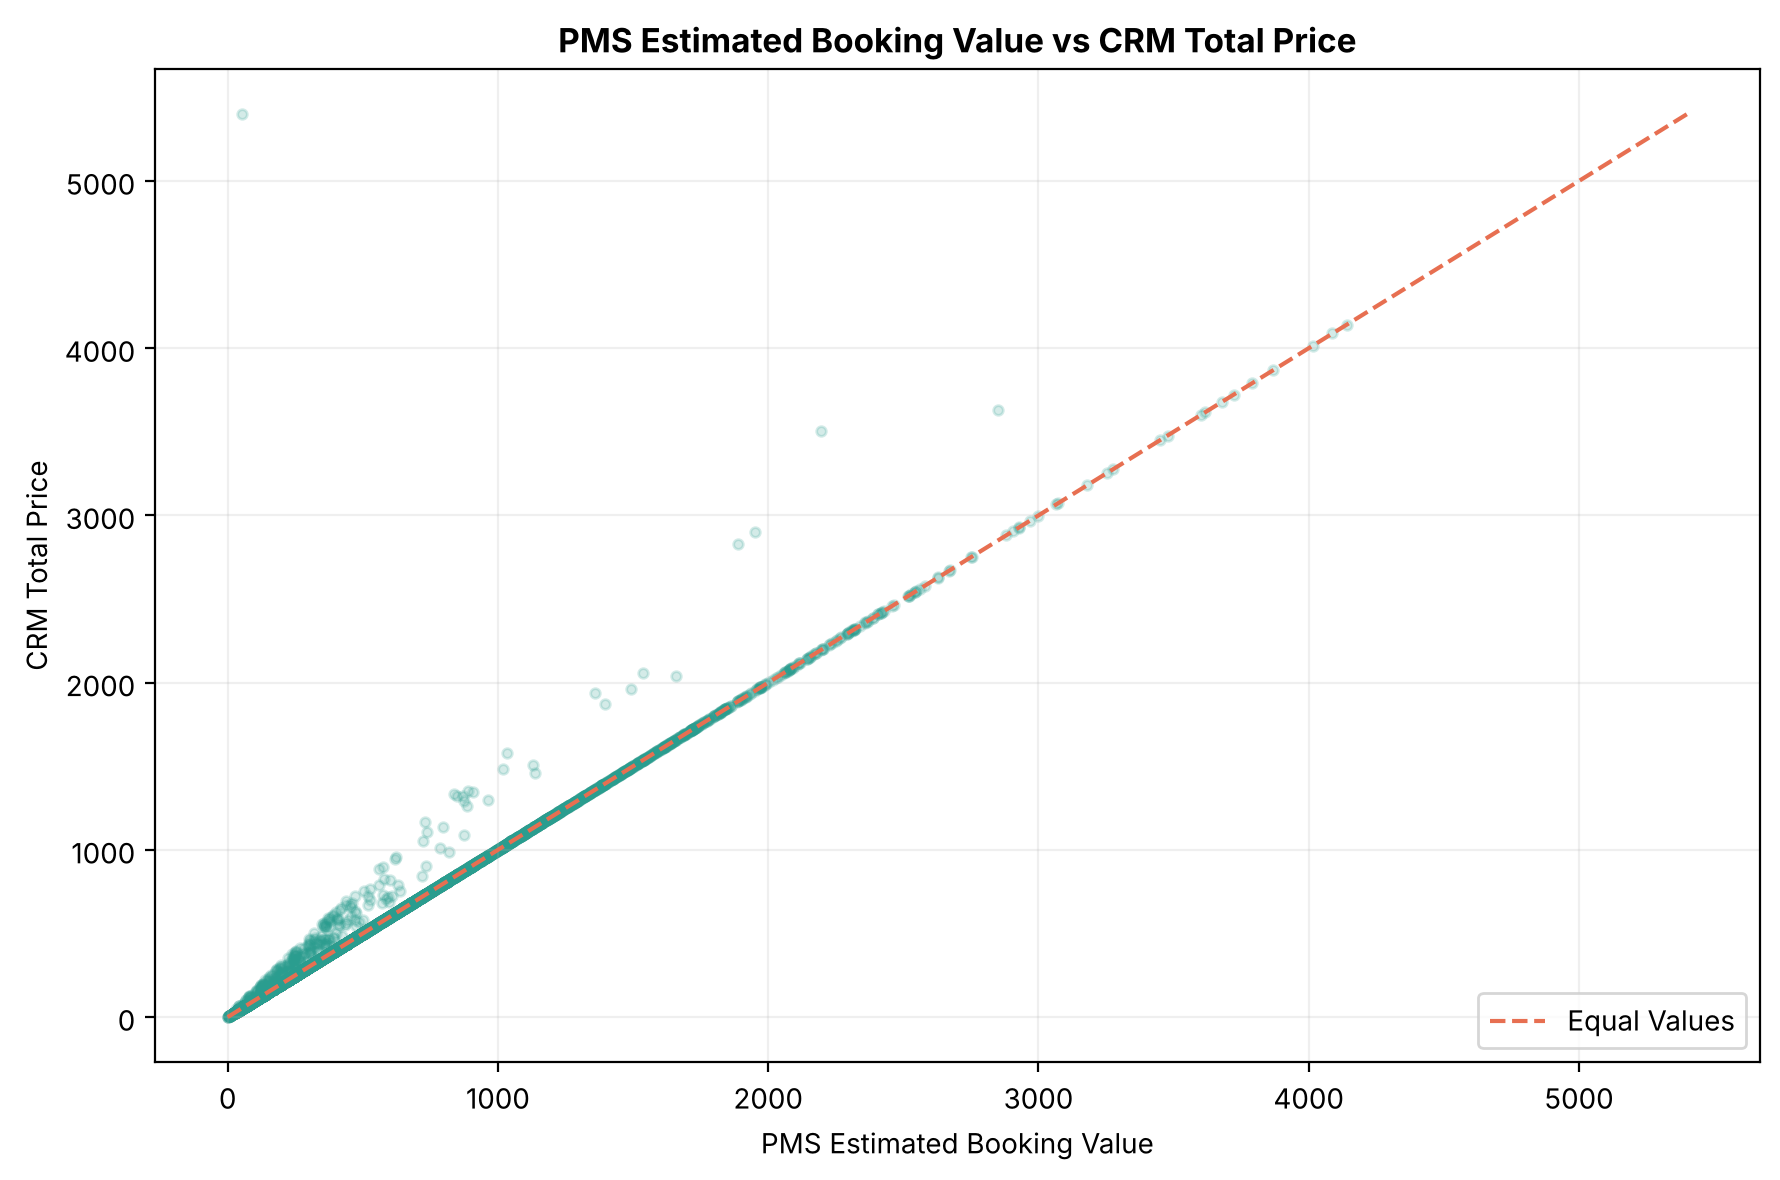

In [195]:
# Visualize the relationship between financial measures

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    financial_valid["estimated_booking_value"],
    financial_valid["total_price"],
    alpha=0.2,
    color="#2A9D8F",
    s=12
)

# Add an equality reference line

max_value = max(
    financial_valid["estimated_booking_value"].max(),
    financial_valid["total_price"].max()
)

ax.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    color="#E76F51",
    label="Equal Values"
)

ax.set_title(
    "PMS Estimated Booking Value vs CRM Total Price",
    fontweight="bold"
)

ax.set_xlabel("PMS Estimated Booking Value")
ax.set_ylabel("CRM Total Price")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Financial Results & Interpretation

The financial comparison identified 22,734 eligible booking records, representing 95.72% of the matched booking population. The remaining 1,016 records were excluded from the comparison due to missing or non-positive financial values or stay durations, but were retained in the integrated dataset.

Key findings:

* Average CRM total booking price: 365.14.
* Average PMS estimated booking value: 363.24.
* Mean price difference: 1.89.
* Mean absolute relative difference: 0.32%.
* Median price difference: 0.00.
* Maximum observed price difference: 5,346.00.
* Maximum absolute relative difference: 99%.

The results demonstrate strong financial alignment between the two systems for the eligible booking population.

The scatter plot further supports this finding, with most observations concentrated around the equality reference line.

However, a limited number of substantial financial discrepancies are also visible. These observations may reflect pricing definition differences, data entry errors or potential scale inconsistencies.

Despite the high overall financial consistency, individual discrepancies should not be overlooked, as they may distort booking-level financial analyses.

Since the precise equivalence of the two financial measures has not been independently established, no automatic price corrections are applied at this stage.

Original financial values are preserved, and significant discrepancies will be flagged for further investigation during the reconciliation process.

### 5.7 Overall Consistency Assessment

The individual consistency assessments are consolidated
into a unified comparison framework.

Agreement and discrepancy rates are compared across
hotel property, arrival date, adult guest counts and
harmonized reservation outcomes.

Financial differences are reported separately because
the corresponding source variables are not established
as directly equivalent financial measures.

This consolidated assessment supports the identification
of priority areas for subsequent data reconciliation.

In [196]:
# Consolidate cross-system consistency results

consistency_summary = pd.DataFrame([
    hotel_consistency,
    arrival_consistency,
    adults_consistency,
    status_consistency
])

# Validate consistency calculations

assert (
    consistency_summary["Agreements"] +
    consistency_summary["Discrepancies"] ==
    consistency_summary["Comparable Records"]
).all()

assert (
    consistency_summary["Comparable Records"] +
    consistency_summary["Non-comparable Records"] ==
    consistency_summary["Matched Bookings"]
).all()

display(consistency_summary)

print("Consistency calculation validation: PASS")

,Business Concept,Matched Bookings,Comparable Records,Non-comparable Records,Agreements,Discrepancies,Agreement (%),Discrepancy (%)
0,Hotel Property,23750,23750,0,23750,0,100.00,0.00
1,Arrival Date,23750,23750,0,23705,45,99.81,0.19
2,Adult Guests,23750,23512,238,23437,75,99.68,0.32
3,Reservation Outcome,23750,23750,0,23700,50,99.79,0.21


Consistency calculation validation: PASS


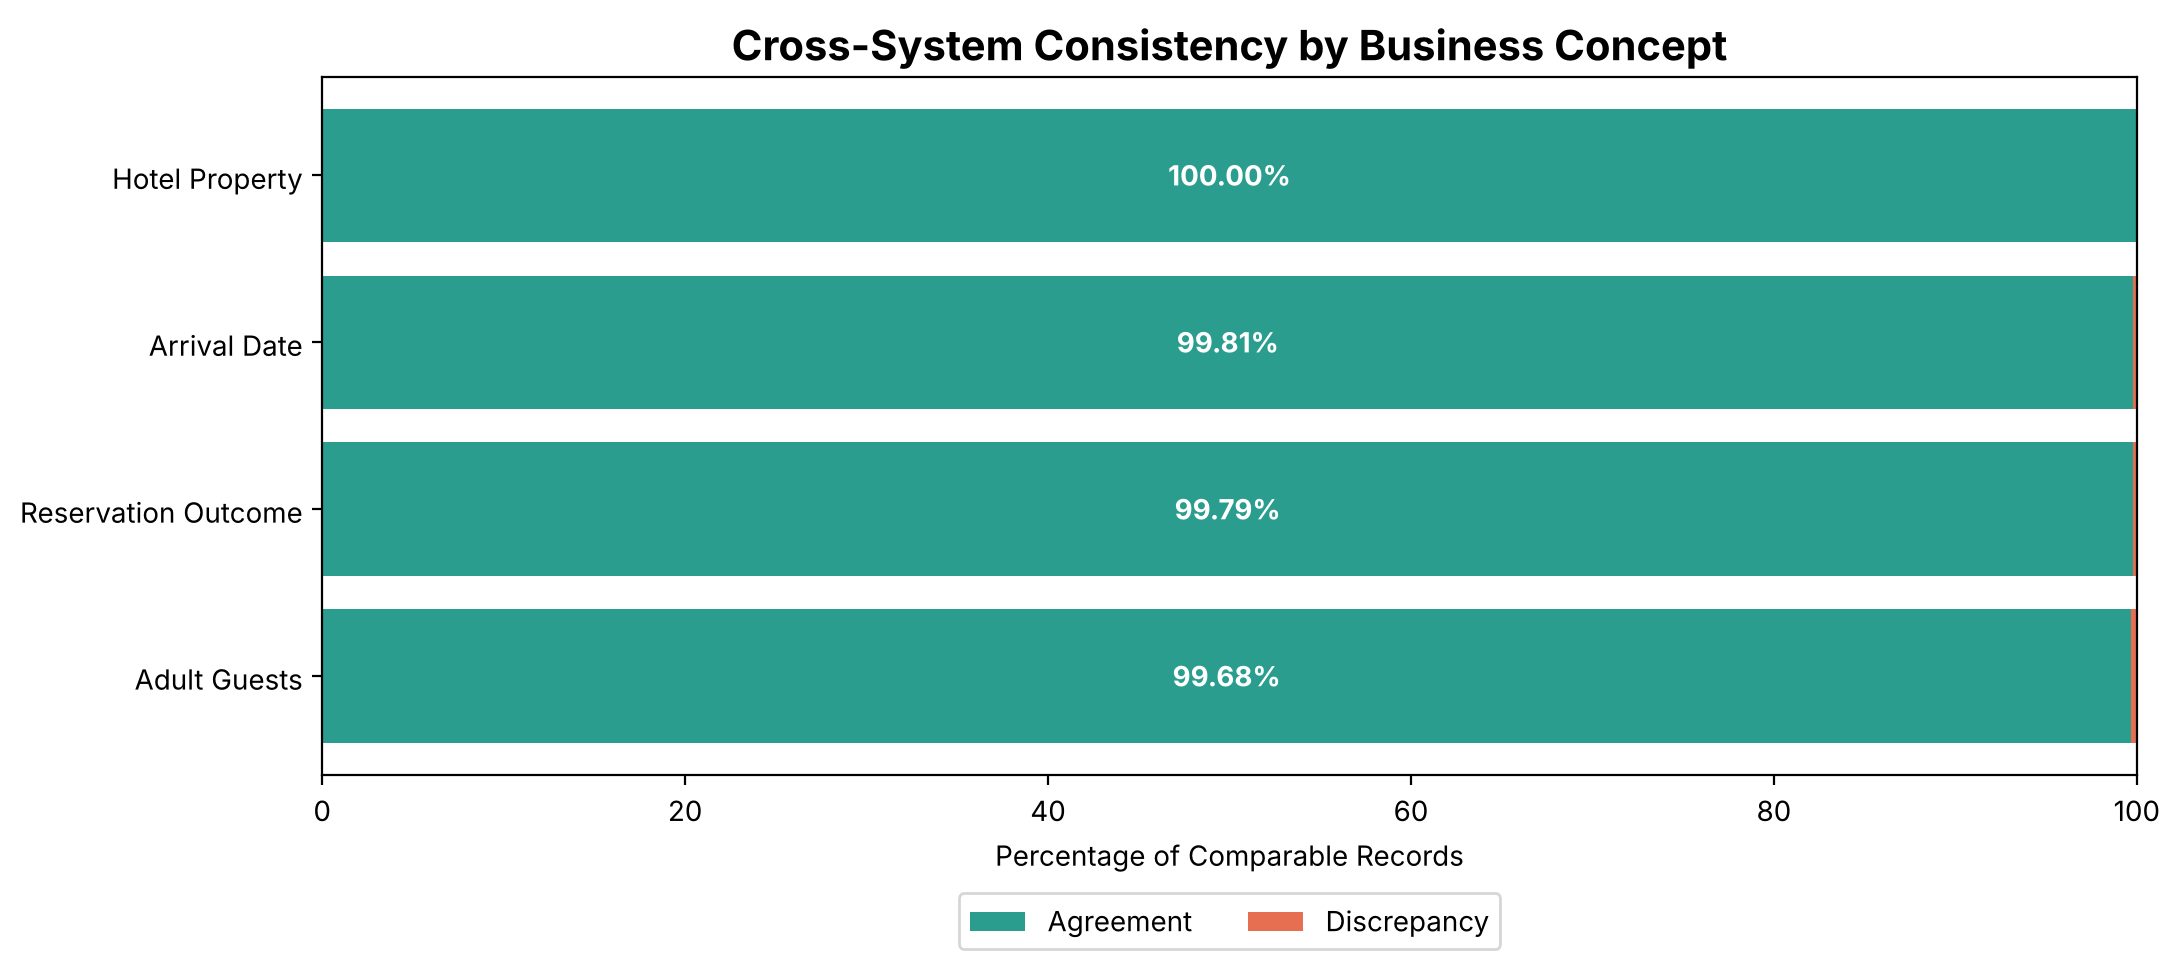

In [197]:
# Visualize agreement and discrepancy rates

plot_data = consistency_summary.sort_values(
    "Agreement (%)",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.barh(
    plot_data["Business Concept"],
    plot_data["Agreement (%)"],
    color="#2A9D8F",
    label="Agreement"
)

ax.barh(
    plot_data["Business Concept"],
    plot_data["Discrepancy (%)"],
    left=plot_data["Agreement (%)"],
    color="#E76F51",
    label="Discrepancy"
)

for i, value in enumerate(plot_data["Agreement (%)"]):

    if value >= 10:
        ax.text(
            value / 2,
            i,
            f"{value:.2f}%",
            ha="center",
            va="center",
            color="white",
            fontweight="bold"
        )

ax.set_title(
    "Cross-System Consistency by Business Concept",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Percentage of Comparable Records")
ax.set_xlim(0, 100)

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)

plt.tight_layout()
plt.show()

5.8 Results & Interpretation

The cross-system consistency assessment demonstrates a high level of agreement between the PMS and CRM datasets across the evaluated business concepts.

Key findings:

* Hotel Property: 100% agreement, indicating complete consistency among comparable records.
* Arrival Date: 99.81% agreement, indicating a limited number of conflicting arrival dates.
* Reservation Outcome: 99.79% agreement, with 50 bookings classified as canceled in the CRM but not canceled in the PMS.
* Adult Guests: 99.68% agreement, representing the highest discrepancy rate among the evaluated variables.

The reservation status analysis also confirms that all 249 No-Show bookings within the matched population are associated with a positive cancellation indicator in the PMS, providing empirical support for the harmonized reservation outcome mapping.

Overall, the results demonstrate strong cross-system consistency, with agreement rates exceeding 99% across all evaluated business concepts.

Nevertheless, the remaining discrepancies could affect business indicators related to booking cancellations, guest volumes and seasonal performance.

These discrepancies will therefore be addressed through transparent reconciliation rules, while preserving original source values and documenting unresolved conflicts.

Financial differences are assessed separately because the PMS estimated booking value and CRM total price are not established as directly equivalent financial measures.

# 6. Data Reconciliation

6.1 Reconciliation Strategy

The cross-system consistency assessment revealed high overall agreement between the PMS and CRM datasets, alongside a limited number of discrepancies requiring further management.

A transparent reconciliation framework is implemented to create unified analytical variables while preserving original source information.

The reconciliation strategy follows five principles:

* Preserve original source values to ensure traceability.
* Consolidate corresponding values when both systems agree.
* Recover available information when a value is missing from one source.
* Identify and flag conflicting information.
* Avoid unsupported corrections or arbitrary source prioritization.

When conflicting values cannot be resolved using the available evidence, the unified variable remains missing and the discrepancy is explicitly documented.

Financial variables are managed separately because their precise equivalence has not been independently established.

This approach balances analytical usability, data transparency and information reliability.

### 6.2 Reconciliation Framework

A reusable reconciliation function is implemented to
standardize the treatment of equivalent variables.

The function generates a unified value, a conflict flag
and a provenance indicator documenting how each unified
value was obtained.

Unresolved discrepancies are retained for further review
rather than automatically overwritten.

In [198]:
# Create a separate dataset for reconciliation

reconciled = integrated.copy()


# Define a reusable reconciliation function

def reconcile_variables(pms_values, crm_values):

    both_available = (
        pms_values.notna() & crm_values.notna()
    )

    agreement = (
        both_available &
        pms_values.eq(crm_values).fillna(False)
    )

    conflict = (
        both_available &
        pms_values.ne(crm_values).fillna(False)
    )

    pms_only = (
        pms_values.notna() & crm_values.isna()
    )

    crm_only = (
        pms_values.isna() & crm_values.notna()
    )

    # Combine available values and exclude unresolved conflicts

    unified = (
        pms_values.combine_first(crm_values)
        .mask(conflict)
    )

    # Document the reconciliation outcome

    provenance = pd.Series(
        "Both Missing",
        index=pms_values.index,
        dtype="string"
    )

    provenance.loc[agreement] = "Agreement"
    provenance.loc[pms_only] = "PMS Only"
    provenance.loc[crm_only] = "CRM Only"
    provenance.loc[conflict] = "Unresolved Conflict"

    return unified, conflict, provenance

### 6.3 Reconciliation of Shared Business Variables

Hotel property, arrival date and adult guest information
are consolidated using the standardized reconciliation
framework.

For each business concept, three new variables are
generated:

- A unified analytical variable.
- A conflict flag.
- A provenance indicator.

Original source variables remain available for auditing
and further investigation.

In [199]:
# Reconcile hotel property

(
    reconciled["hotel_final"],
    reconciled["hotel_conflict_flag"],
    reconciled["hotel_provenance"]
) = reconcile_variables(
    reconciled["hotel"],
    reconciled["property"]
)


# Reconcile arrival dates

(
    reconciled["arrival_date_final"],
    reconciled["arrival_date_conflict_flag"],
    reconciled["arrival_date_provenance"]
) = reconcile_variables(
    reconciled["arrival_date"].dt.normalize(),
    reconciled["checkin_date"].dt.normalize()
)


# Reconcile adult guest counts

(
    reconciled["adults_final"],
    reconciled["adults_conflict_flag"],
    reconciled["adults_provenance"]
) = reconcile_variables(
    reconciled["adults"].astype("Int64"),
    reconciled["n_adults"].astype("Int64")
)


# Inspect reconciled variables

display(
    reconciled[
        [
            "booking_id",
            "hotel_final",
            "arrival_date_final",
            "adults_final"
        ]
    ].head(10)
)

,booking_id,hotel_final,arrival_date_final,adults_final
0,BK300001,Resort Hotel,2016-06-26,3
1,BK300002,Resort Hotel,2016-07-23,2
2,BK300003,City Hotel,2016-10-20,1
3,BK300004,City Hotel,2016-07-06,2
4,BK300005,Resort Hotel,2016-08-16,2
5,BK300006,City Hotel,2016-08-11,2
6,BK300007,City Hotel,2017-08-02,2
7,BK300008,City Hotel,2017-05-30,2
8,BK300009,City Hotel,2015-07-21,2
9,BK300010,Resort Hotel,2017-05-23,1


### 6.4 Reservation Outcome Reconciliation

Reservation outcome information is harmonized using
the binary comparison framework established during
the consistency assessment.

The unified outcome distinguishes bookings recorded
as not canceled or completed from bookings classified
as canceled or no-show.

The original categorical CRM reservation status is
preserved to retain the distinction between cancellations
and no-shows.

Conflicting outcomes remain unresolved unless additional
evidence becomes available.

In [200]:
# Harmonize reservation outcomes across the full dataset

reconciled["crm_outcome_binary"] = (
    reconciled["reservation_status"]
    .str.strip()
    .str.lower()
    .map(status_mapping)
    .astype("Int64")
)


# Reconcile reservation outcomes

(
    reconciled["booking_not_realized_final"],
    reconciled["outcome_conflict_flag"],
    reconciled["outcome_provenance"]
) = reconcile_variables(
    reconciled["is_canceled"].astype("Int64"),
    reconciled["crm_outcome_binary"]
)


# Display the reservation outcome distribution

display(
    reconciled["booking_not_realized_final"]
    .value_counts(dropna=False)
)

print(
    "Unresolved reservation outcome conflicts:",
    reconciled["outcome_conflict_flag"].sum()
)

booking_not_realized_final
0       15646
1        9304
<NA>       50
Name: count, dtype: Int64

Unresolved reservation outcome conflicts: 50


### 6.5 Financial Discrepancy Management

Financial differences are managed through an
anomaly-flagging framework rather than direct price
reconciliation.

The original CRM total price and PMS estimated
booking value are preserved as separate financial
measures.

Relative differences are classified using exploratory
thresholds of 1%, 10% and 50% to support the
identification of potentially material discrepancies.

These thresholds represent analytical project rules
rather than validated financial reporting standards.

Financial discrepancies are not automatically
considered confirmed errors, and no original price
values are overwritten.

In [201]:
# Map the financial assessment results to all bookings

financial_difference_map = (
    financial_valid.set_index("booking_id")[
        "absolute_relative_difference_pct"
    ]
)

reconciled["financial_relative_difference_pct"] = (
    reconciled["booking_id"]
    .map(financial_difference_map)
)


# Classify financial differences

relative_difference = (
    reconciled["financial_relative_difference_pct"]
)

reconciled["financial_consistency_status"] = pd.Series(
    "Not Comparable",
    index=reconciled.index,
    dtype="string"
)

reconciled.loc[
    relative_difference.le(1),
    "financial_consistency_status"
] = "Close Alignment"

reconciled.loc[
    relative_difference.gt(1) &
    relative_difference.le(10),
    "financial_consistency_status"
] = "Moderate Difference"

reconciled.loc[
    relative_difference.gt(10),
    "financial_consistency_status"
] = "Significant Difference"


# Create financial discrepancy flags

reconciled["financial_discrepancy_flag"] = (
    relative_difference.astype("Float64").gt(10)
)

reconciled["financial_severe_flag"] = (
    relative_difference.astype("Float64").gt(50)
)


# Display financial consistency results

display(
    reconciled["financial_consistency_status"]
    .value_counts()
)

print(
    "Severe financial discrepancies:",
    reconciled["financial_severe_flag"].sum()
)

financial_consistency_status
Close Alignment           22461
Not Comparable             2266
Significant Difference      273
Name: count, dtype: Int64

Severe financial discrepancies: 1


In [202]:
# Inspect the ten largest relative financial differences

display(
    financial_valid.nlargest(
        10,
        "absolute_relative_difference_pct"
    )[
        [
            "booking_id",
            "adr",
            "total_nights",
            "total_price",
            "estimated_booking_value",
            "price_difference",
            "absolute_relative_difference_pct"
        ]
    ]
)

,booking_id,adr,total_nights,total_price,estimated_booking_value,price_difference,absolute_relative_difference_pct
23522,BK323523,54.00,1.0,5400.00,54.0,5346.0,99.0
7732,BK307733,168.92,13.0,3505.02,2195.96,1309.06,37.348146
7594,BK307595,175.00,2.0,558.41,350.0,208.41,37.322039
13728,BK313729,104.55,7.0,1164.80,731.85,432.95,37.169471
6058,BK306059,119.70,7.0,1332.54,837.9,494.64,37.120086
13723,BK313724,109.00,4.0,692.41,436.0,256.41,37.031528
10251,BK310252,53.10,7.0,589.93,371.7,218.23,36.992525
15995,BK315996,79.20,3.0,376.11,237.6,138.51,36.826992
24215,BK324216,75.00,3.0,355.55,225.0,130.55,36.717761
21000,BK321001,61.00,3.0,289.09,183.0,106.09,36.697914


### 6.6 Overall Reconciliation Summary

Reconciliation outcomes are consolidated to quantify
the number of agreed values, values recovered from
individual sources and unresolved discrepancies.

This assessment measures the effectiveness of the
reconciliation framework while maintaining transparency
regarding remaining data limitations.

In [203]:
# Define provenance variables

provenance_columns = {
    "Hotel Property": "hotel_provenance",
    "Arrival Date": "arrival_date_provenance",
    "Adult Guests": "adults_provenance",
    "Reservation Outcome": "outcome_provenance"
}


# Create the reconciliation summary

reconciliation_summary = pd.DataFrame({
    concept: reconciled[column].value_counts()
    for concept, column in provenance_columns.items()
}).T.fillna(0).astype(int)


# Standardize the column order

reconciliation_summary = (
    reconciliation_summary.reindex(
        columns=[
            "Agreement",
            "PMS Only",
            "CRM Only",
            "Both Missing",
            "Unresolved Conflict"
        ],
        fill_value=0
    )
)


# Calculate the number of available final values

reconciliation_summary["Available Final Values"] = (
    reconciliation_summary["Agreement"] +
    reconciliation_summary["PMS Only"] +
    reconciliation_summary["CRM Only"]
)

reconciliation_summary["Final Completeness (%)"] = (
    reconciliation_summary["Available Final Values"] /
    len(reconciled) * 100
).round(2)

display(reconciliation_summary)

,Agreement,PMS Only,CRM Only,Both Missing,Unresolved Conflict,Available Final Values,Final Completeness (%)
Hotel Property,23750,500,750,0,0,25000,100.00
Arrival Date,23705,500,750,0,45,24955,99.82
Adult Guests,23437,738,742,8,75,24917,99.67
Reservation Outcome,23700,500,750,0,50,24950,99.80


In [204]:
# Identify business variable conflict flags

conflict_columns = [
    "hotel_conflict_flag",
    "arrival_date_conflict_flag",
    "adults_conflict_flag",
    "outcome_conflict_flag"
]


# Calculate conflicts at booking level

reconciled["number_of_conflicts"] = (
    reconciled[conflict_columns].sum(axis=1)
)

reconciled["has_unresolved_conflict"] = (
    reconciled["number_of_conflicts"] > 0
)


# Summarize booking-level conflicts

print(
    "Bookings with unresolved conflicts:",
    reconciled["has_unresolved_conflict"].sum()
)

print(
    "Total individual business variable conflicts:",
    reconciled["number_of_conflicts"].sum()
)

display(
    reconciled["number_of_conflicts"]
    .value_counts()
    .sort_index()
)

Bookings with unresolved conflicts: 168
Total individual business variable conflicts: 170


number_of_conflicts
0    24832
1      166
2        2
Name: count, dtype: Int64

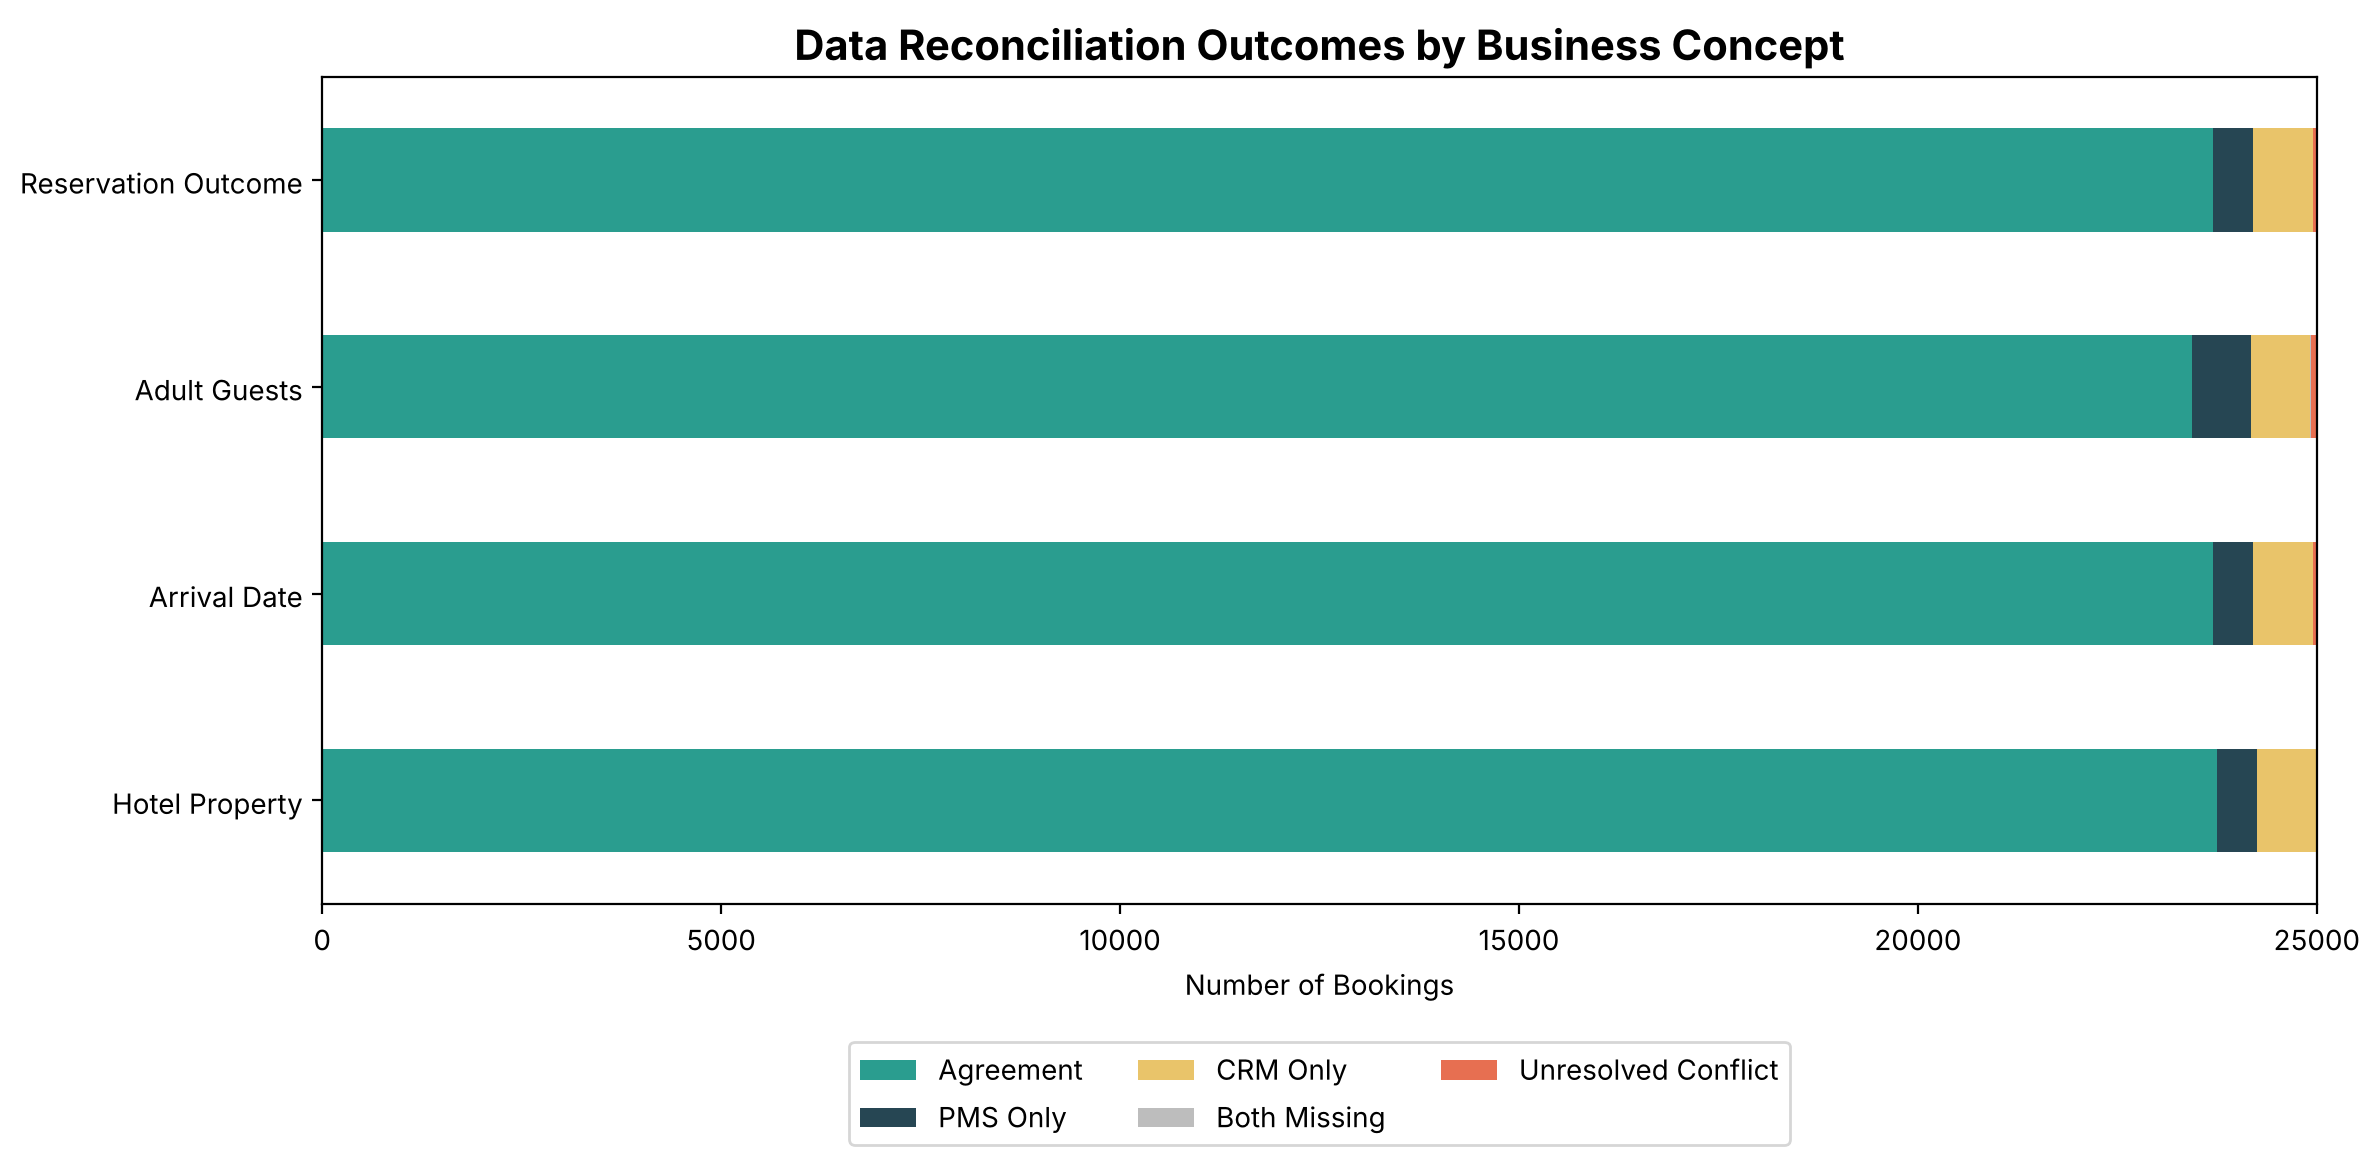

In [205]:
# Select reconciliation outcome categories

plot_columns = [
    "Agreement",
    "PMS Only",
    "CRM Only",
    "Both Missing",
    "Unresolved Conflict"
]


# Visualize reconciliation outcomes

ax = reconciliation_summary[plot_columns].plot(
    kind="barh",
    stacked=True,
    figsize=(12, 6),
    color=[
        "#2A9D8F",
        "#264653",
        "#E9C46A",
        "#BDBDBD",
        "#E76F51"
    ]
)

ax.set_title(
    "Data Reconciliation Outcomes by Business Concept",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Number of Bookings")
ax.set_ylabel("")
ax.set_xlim(0, len(reconciled))

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=3
)

plt.tight_layout()
plt.show()

In [206]:
# Validate the reconciliation process

final_variables = {
    "Hotel Property": "hotel_final",
    "Arrival Date": "arrival_date_final",
    "Adult Guests": "adults_final",
    "Reservation Outcome": "booking_not_realized_final"
}


reconciliation_checks = {

    "All bookings preserved":
        len(reconciled) == len(integrated),

    "Booking identifiers preserved":
        reconciled["booking_id"].equals(
            integrated["booking_id"]
        ),

    "Unique booking identifiers":
        reconciled["booking_id"].is_unique,

    "Original source values preserved":
        reconciled[integrated.columns].equals(integrated),

    "Reconciliation categories complete":
        reconciliation_summary[plot_columns]
        .sum(axis=1).eq(len(reconciled)).all(),

    "Final value counts consistent":
        all(
            reconciled[column].notna().sum() ==
            reconciliation_summary.loc[
                concept, "Available Final Values"
            ]
            for concept, column in final_variables.items()
        ),

    "Hotel conflicts remain unresolved":
        reconciled.loc[
            reconciled["hotel_conflict_flag"],
            "hotel_final"
        ].isna().all(),

    "Arrival conflicts remain unresolved":
        reconciled.loc[
            reconciled["arrival_date_conflict_flag"],
            "arrival_date_final"
        ].isna().all(),

    "Adult conflicts remain unresolved":
        reconciled.loc[
            reconciled["adults_conflict_flag"],
            "adults_final"
        ].isna().all(),

    "Outcome conflicts remain unresolved":
        reconciled.loc[
            reconciled["outcome_conflict_flag"],
            "booking_not_realized_final"
        ].isna().all()
}


# Display validation results

reconciliation_validation = pd.DataFrame({
    "Validation Check": list(reconciliation_checks.keys()),
    "Status": [
        "PASS" if result else "FAIL"
        for result in reconciliation_checks.values()
    ]
})

display(reconciliation_validation)

assert all(reconciliation_checks.values()), \
    "One or more reconciliation checks failed."

print(
    f"Validation completed: "
    f"{sum(reconciliation_checks.values())}/"
    f"{len(reconciliation_checks)} checks passed."
)

print("Reconciled dataset shape:", reconciled.shape)

,Validation Check,Status
0,All bookings preserved,PASS
1,Booking identifiers preserved,PASS
2,Unique booking identifiers,PASS
3,Original source values preserved,PASS
4,Reconciliation categories complete,PASS
5,Final value counts consistent,PASS
6,Hotel conflicts remain unresolved,PASS
7,Arrival conflicts remain unresolved,PASS
8,Adult conflicts remain unresolved,PASS
9,Outcome conflicts remain unresolved,PASS


Validation completed: 10/10 checks passed.
Reconciled dataset shape: (25000, 64)


6.9 Results & Interpretation

The reconciliation process successfully consolidated shared PMS and CRM business variables while preserving all 25,000 booking records and original source information.

The reconciled dataset contains 64 variables, including 19 additional analytical, provenance and data quality variables.

Reconciled variable completeness:

* Hotel Property: 100.00%, with no unresolved conflicts.
* Arrival Date: 99.82%, with 45 unresolved conflicts.
* Adult Guests: 99.67%, with 75 unresolved conflicts and 8 bookings without available adult guest information.
* Reservation Outcome: 99.80%, with 50 unresolved conflicts.

The reconciliation process also recovered 238 missing CRM adult guest values using available PMS information for matched bookings, demonstrating the complementary value of integrating the two systems.

Booking-level reconciliation results:

* 24,832 bookings (99.328%) contain no identified conflicts across the four reconciled business concepts.
* 166 bookings (0.664%) contain one unresolved conflict.
* 2 bookings (0.008%) contain two unresolved conflicts.
* A total of 170 individual conflicts affect 168 distinct bookings, representing approximately 0.67% of the integrated dataset.

Rather than applying unsupported corrections, unresolved discrepancies are explicitly documented through conflict flags and provenance indicators.

Financial measures remain separately preserved, with potential anomalies classified according to their relative magnitude.

All ten reconciliation validation checks were successfully completed, confirming booking preservation, identifier uniqueness, source data integrity and consistency of reconciliation outcomes.

The resulting dataset provides a transparent and reliable foundation for feature engineering and downstream business analysis, while retaining visibility into remaining data quality limitations.

# 7. Feature Engineering

7.1 Feature Engineering Strategy

Following data integration and reconciliation, additional analytical variables are developed to support subsequent business analysis.

The feature engineering process transforms existing information into meaningful indicators related to stay duration, guest volumes, seasonality, estimated booking value and reservation outcomes.

The main objectives are to:

* Improve the analytical usability of the integrated dataset.
* Support hotel performance and customer segmentation analysis.
* Enable temporal and seasonal comparisons.
* Facilitate financial and reservation outcome analysis.
* Preserve transparency regarding missing values and unresolved data quality issues.

All engineered variables are derived from existing source information or reconciled analytical variables.

Missing information is not automatically replaced with zero, and original source variables remain unchanged throughout the process.

### 7.2 Stay Duration and Guest Features

Total booked nights and total guests are calculated
using available operational and reconciled information.

Missing components are preserved to avoid
underestimating stay duration or guest volumes.

Potentially implausible adult guest counts are flagged
for further review without overwriting source values.

In [207]:
# Create a separate analytical dataset

final_df = reconciled.copy()


# Calculate total booked nights

final_df["total_nights"] = (
    final_df["stays_in_weekend_nights"] +
    final_df["stays_in_week_nights"]
).astype("Int64")


# Flag potentially implausible adult guest counts

final_df["adult_count_review_flag"] = (
    final_df["adults_final"].lt(0) |
    final_df["adults_final"].gt(20)
)


# Calculate total guests

final_df["total_guests"] = (
    final_df["adults_final"] +
    final_df["children"] +
    final_df["babies"]
).astype("Int64")


# Exclude potentially implausible adult counts from guest totals

final_df["total_guests"] = (
    final_df["total_guests"]
    .mask(final_df["adult_count_review_flag"].fillna(False))
)


# Inspect the engineered variables

display(
    final_df[
        [
            "total_nights",
            "adults_final",
            "children",
            "babies",
            "total_guests"
        ]
    ].describe().round(2)
)

print(
    "Adult counts requiring review:",
    final_df["adult_count_review_flag"].sum()
)

,total_nights,adults_final,children,babies,total_guests
count,24215.0,24917.0,23440.0,24250.00,23364.0
mean,3.41,1.86,0.1,0.01,1.97
std,2.46,0.63,0.39,0.09,0.67
min,0.0,0.0,0.0,0.00,0.0
25%,2.0,2.0,0.0,0.00,2.0
50%,3.0,2.0,0.0,0.00,2.0
75%,4.0,2.0,0.0,0.00,2.0
max,45.0,55.0,3.0,2.00,20.0


Adult counts requiring review: 2


### 7.3 Temporal and Seasonal Features

Temporal variables are extracted from the reconciled
arrival date to support monthly, quarterly, annual
and seasonal analysis.

Meteorological seasons are used as a standardized
classification framework.

Bookings with unresolved or missing arrival dates
retain missing temporal features.

Annual comparisons must account for incomplete
calendar-year coverage within the observation period.

In [208]:
# Extract temporal features

final_df["arrival_year"] = (
    final_df["arrival_date_final"].dt.year.astype("Int64")
)

final_df["arrival_month"] = (
    final_df["arrival_date_final"].dt.month.astype("Int64")
)

final_df["arrival_year_month"] = (
    final_df["arrival_date_final"]
    .dt.strftime("%Y-%m")
    .astype("string")
)

final_df["arrival_quarter"] = (
    final_df["arrival_date_final"].dt.quarter.astype("Int64")
)


# Define meteorological seasons

season_mapping = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
}


# Assign arrival season

final_df["season"] = (
    final_df["arrival_month"]
    .map(season_mapping)
    .astype("string")
)


# Inspect temporal features

display(
    final_df[
        [
            "arrival_date_final",
            "arrival_year",
            "arrival_month",
            "arrival_year_month",
            "arrival_quarter",
            "season"
        ]
    ].head(10)
)

print("First arrival:", final_df["arrival_date_final"].min())

print("Last arrival:", final_df["arrival_date_final"].max())

,arrival_date_final,arrival_year,arrival_month,arrival_year_month,arrival_quarter,season
0,2016-06-26,2016,6,2016-06,2,Summer
1,2016-07-23,2016,7,2016-07,3,Summer
2,2016-10-20,2016,10,2016-10,4,Autumn
3,2016-07-06,2016,7,2016-07,3,Summer
4,2016-08-16,2016,8,2016-08,3,Summer
5,2016-08-11,2016,8,2016-08,3,Summer
6,2017-08-02,2017,8,2017-08,3,Summer
7,2017-05-30,2017,5,2017-05,2,Spring
8,2015-07-21,2015,7,2015-07,3,Summer
9,2017-05-23,2017,5,2017-05,2,Spring


First arrival: 2015-07-01 00:00:00
Last arrival: 2017-08-31 00:00:00


### 7.4 Financial Feature Engineering

An estimated booking value is calculated by multiplying
the PMS Average Daily Rate by the total number of
booked nights.

The calculation requires non-negative ADR values and
positive stay durations.

The resulting indicator represents an estimated booking
value rather than confirmed realized revenue.

The original CRM total price remains available as a
separate financial measure. Existing financial
discrepancy flags are retained for downstream analysis.

In [209]:
# Identify eligible booking value calculations

valid_booking_value = (
    final_df["adr"].ge(0) &
    final_df["total_nights"].gt(0)
).fillna(False)


# Calculate estimated booking value

final_df["estimated_booking_value"] = (
    final_df["adr"] * final_df["total_nights"]
).where(valid_booking_value).round(2)


# Inspect financial features

display(
    final_df[
        [
            "adr",
            "total_nights",
            "estimated_booking_value",
            "total_price"
        ]
    ].describe().round(2)
)

,adr,total_nights,estimated_booking_value,total_price
count,24090.00,24215.0,23911.0,24010.00
mean,101.77,3.41,359.69,359.16
std,47.64,2.46,333.17,336.73
min,0.00,0.0,0.0,0.00
25%,69.06,2.0,150.0,148.98
50%,94.69,3.0,270.0,270.00
75%,126.00,4.0,448.98,450.00
max,387.00,45.0,4141.2,5400.00


### 7.5 Stay Duration and Booking Outcome Categories

Booking records are segmented into stay duration
categories to facilitate customer behavior analysis.

Reservation outcomes are also translated into
descriptive analytical categories.

Unresolved or unavailable information remains missing
rather than being assigned to unsupported categories.

The original CRM reservation status is preserved to
enable separate analysis of cancellations and no-shows.

In [210]:
# Create stay duration categories

final_df["stay_duration_category"] = pd.cut(
    final_df["total_nights"],
    bins=[-1, 0, 2, 7, 14, np.inf],
    labels=[
        "Zero Nights",
        "Short Stay",
        "Medium Stay",
        "Long Stay",
        "Extended Stay"
    ]
)


# Create descriptive booking outcome categories

outcome_mapping = {
    0: "Not Canceled / Completed",
    1: "Canceled / No-Show"
}

final_df["booking_outcome"] = (
    final_df["booking_not_realized_final"]
    .map(outcome_mapping)
    .astype("string")
)


# Inspect category distributions

print("Stay duration categories:")

display(
    final_df["stay_duration_category"]
    .value_counts(dropna=False)
)

print("\nBooking outcomes:")

display(
    final_df["booking_outcome"]
    .value_counts(dropna=False)
)

Stay duration categories:


stay_duration_category
Medium Stay      13213
Short Stay        9821
Long Stay          966
NaN                785
Zero Nights        147
Extended Stay       68
Name: count, dtype: int64


Booking outcomes:


booking_outcome
Not Canceled / Completed    15646
Canceled / No-Show           9304
<NA>                           50
Name: count, dtype: Int64

In [211]:
# Identify newly engineered features

engineered_features = [
    col for col in final_df.columns
    if col not in reconciled.columns
]


# Create a feature engineering summary

feature_summary = pd.DataFrame({
    "Feature": engineered_features,

    "Data Type": [
        str(final_df[col].dtype)
        for col in engineered_features
    ],

    "Available Values": [
        final_df[col].notna().sum()
        for col in engineered_features
    ],

    "Missing Values": [
        final_df[col].isna().sum()
        for col in engineered_features
    ],

    "Completeness (%)": [
        round(final_df[col].notna().mean() * 100, 2)
        for col in engineered_features
    ]
})

display(feature_summary)

print("New engineered features:", len(engineered_features))

print("Analytical dataset shape:", final_df.shape)

,Feature,Data Type,Available Values,Missing Values,Completeness (%)
0,total_nights,Int64,24215,785,96.86
1,adult_count_review_flag,boolean,24917,83,99.67
2,total_guests,Int64,23364,1636,93.46
3,arrival_year,Int64,24955,45,99.82
4,arrival_month,Int64,24955,45,99.82
5,arrival_year_month,string,24955,45,99.82
6,arrival_quarter,Int64,24955,45,99.82
7,season,string,24955,45,99.82
8,estimated_booking_value,Float64,23911,1089,95.64
9,stay_duration_category,category,24215,785,96.86


New engineered features: 11
Analytical dataset shape: (25000, 75)


In [212]:
# Validate engineered features

feature_checks = {

    "All bookings preserved":
        len(final_df) == len(reconciled),

    "Unique booking identifiers":
        final_df["booking_id"].is_unique,

    "Previous variables preserved":
        final_df[reconciled.columns].equals(reconciled),

    "Expected number of engineered features":
        len(engineered_features) == 11,

    "No negative total nights":
        final_df["total_nights"].dropna().ge(0).all(),

    "No negative total guests":
        final_df["total_guests"].dropna().ge(0).all(),

    "No negative estimated booking values":
        final_df["estimated_booking_value"]
        .dropna().ge(0).all(),

    "Valid arrival months":
        final_df["arrival_month"]
        .dropna().between(1, 12).all(),

    "Valid arrival quarters":
        final_df["arrival_quarter"]
        .dropna().between(1, 4).all(),

    "Missing arrival dates preserved":
        final_df.loc[
            final_df["arrival_date_final"].isna(),
            [
                "arrival_year",
                "arrival_month",
                "arrival_year_month",
                "arrival_quarter",
                "season"
            ]
        ].isna().all().all(),

    "Unresolved booking outcomes preserved":
        final_df.loc[
            final_df["outcome_conflict_flag"],
            "booking_outcome"
        ].isna().all(),

    "Incomplete guest components preserved":
        final_df.loc[
            final_df[
                ["adults_final", "children", "babies"]
            ].isna().any(axis=1),
            "total_guests"
        ].isna().all()
}


# Create validation summary

feature_validation = pd.DataFrame({
    "Validation Check": list(feature_checks.keys()),

    "Status": [
        "PASS" if result else "FAIL"
        for result in feature_checks.values()
    ]
})

display(feature_validation)

assert all(feature_checks.values()), \
    "One or more feature engineering checks failed."

print(
    f"Validation completed: "
    f"{sum(feature_checks.values())}/"
    f"{len(feature_checks)} checks passed."
)

print("Analytical dataset shape:", final_df.shape)

,Validation Check,Status
0,All bookings preserved,PASS
1,Unique booking identifiers,PASS
2,Previous variables preserved,PASS
3,Expected number of engineered features,PASS
4,No negative total nights,PASS
5,No negative total guests,PASS
6,No negative estimated booking values,PASS
7,Valid arrival months,PASS
8,Valid arrival quarters,PASS
9,Missing arrival dates preserved,PASS


Validation completed: 12/12 checks passed.
Analytical dataset shape: (25000, 75)


7.8 Results & Interpretation

The feature engineering process successfully generated 11 additional analytical variables, expanding the reconciled dataset from 64 to 75 variables while preserving all 25,000 booking records.

The engineered features support multiple business analysis dimensions, including stay duration, guest volumes, temporal trends, seasonality, financial performance and reservation outcomes.

Missing information and unresolved discrepancies remain explicitly represented within the analytical dataset.

Estimated booking values are distinguished from realized revenue, while potentially implausible adult guest counts are flagged to support responsible guest volume analysis.

All twelve feature engineering validation checks were successfully completed, confirming structural integrity, preservation of previous variables and consistency of the engineered features.

The resulting analytical dataset provides a comprehensive foundation for subsequent hotel performance analysis, customer segmentation and data-driven business recommendations.

A final post-integration data quality assessment will evaluate the completeness, validity and analytical limitations of the resulting dataset before export.

# 8. Post-Merge Data Quality Assessment

8.1 Quality Assessment Strategy

Following integration, reconciliation and feature engineering, a final data quality assessment is performed to evaluate the suitability of the analytical dataset for downstream business analysis.

The assessment focuses on the following dimensions:

* Completeness of key analytical variables.
* Structural missing values resulting from source availability.
* Improvements in information availability through reconciliation.
* Remaining logical inconsistencies and potential anomalies.
* Booking identifier uniqueness and dataset integrity.

Particular attention is given to distinguishing missing information caused by the integration strategy from unresolved data quality issues.

The objective is not to artificially achieve complete data availability, but to deliver a transparent, reliable and analytically usable dataset with clearly documented limitations.

### 8.2 Final Dataset Completeness

The completeness of the analytical dataset is evaluated
at both dataset and variable levels.

Core business variables are assessed separately because
their availability directly affects the reliability of
subsequent business performance indicators.

In [213]:
# Calculate overall dataset completeness

final_total_cells = final_df.size

final_missing_cells = final_df.isna().sum().sum()

final_completeness = (
    1 - final_missing_cells / final_total_cells
) * 100

print("Final dataset shape:", final_df.shape)

print(f"Total cells: {final_total_cells:,}")

print(f"Missing cells: {final_missing_cells:,}")

print(f"Overall completeness: {final_completeness:.2f}%")

Final dataset shape: (25000, 75)
Total cells: 1,875,000
Missing cells: 68,534
Overall completeness: 96.34%


In [214]:
# Select core analytical variables

core_variables = [
    "booking_id",
    "hotel_final",
    "arrival_date_final",
    "adults_final",
    "total_guests",
    "total_nights",
    "adr",
    "total_price",
    "estimated_booking_value",
    "booking_not_realized_final",
    "guest_country",
    "market_segment",
    "season"
]

# Create a completeness profile

core_completeness = pd.DataFrame({
    "Variable": core_variables,

    "Available Values": [
        final_df[col].notna().sum()
        for col in core_variables
    ],

    "Missing Values": [
        final_df[col].isna().sum()
        for col in core_variables
    ],

    "Completeness (%)": [
        round(final_df[col].notna().mean() * 100, 2)
        for col in core_variables
    ]
}).sort_values("Completeness (%)")

display(core_completeness)

,Variable,Available Values,Missing Values,Completeness (%)
4,total_guests,23364,1636,93.46
8,estimated_booking_value,23911,1089,95.64
7,total_price,24010,990,96.04
6,adr,24090,910,96.36
5,total_nights,24215,785,96.86
10,guest_country,24386,614,97.54
11,market_segment,24500,500,98.00
3,adults_final,24917,83,99.67
9,booking_not_realized_final,24950,50,99.80
12,season,24955,45,99.82


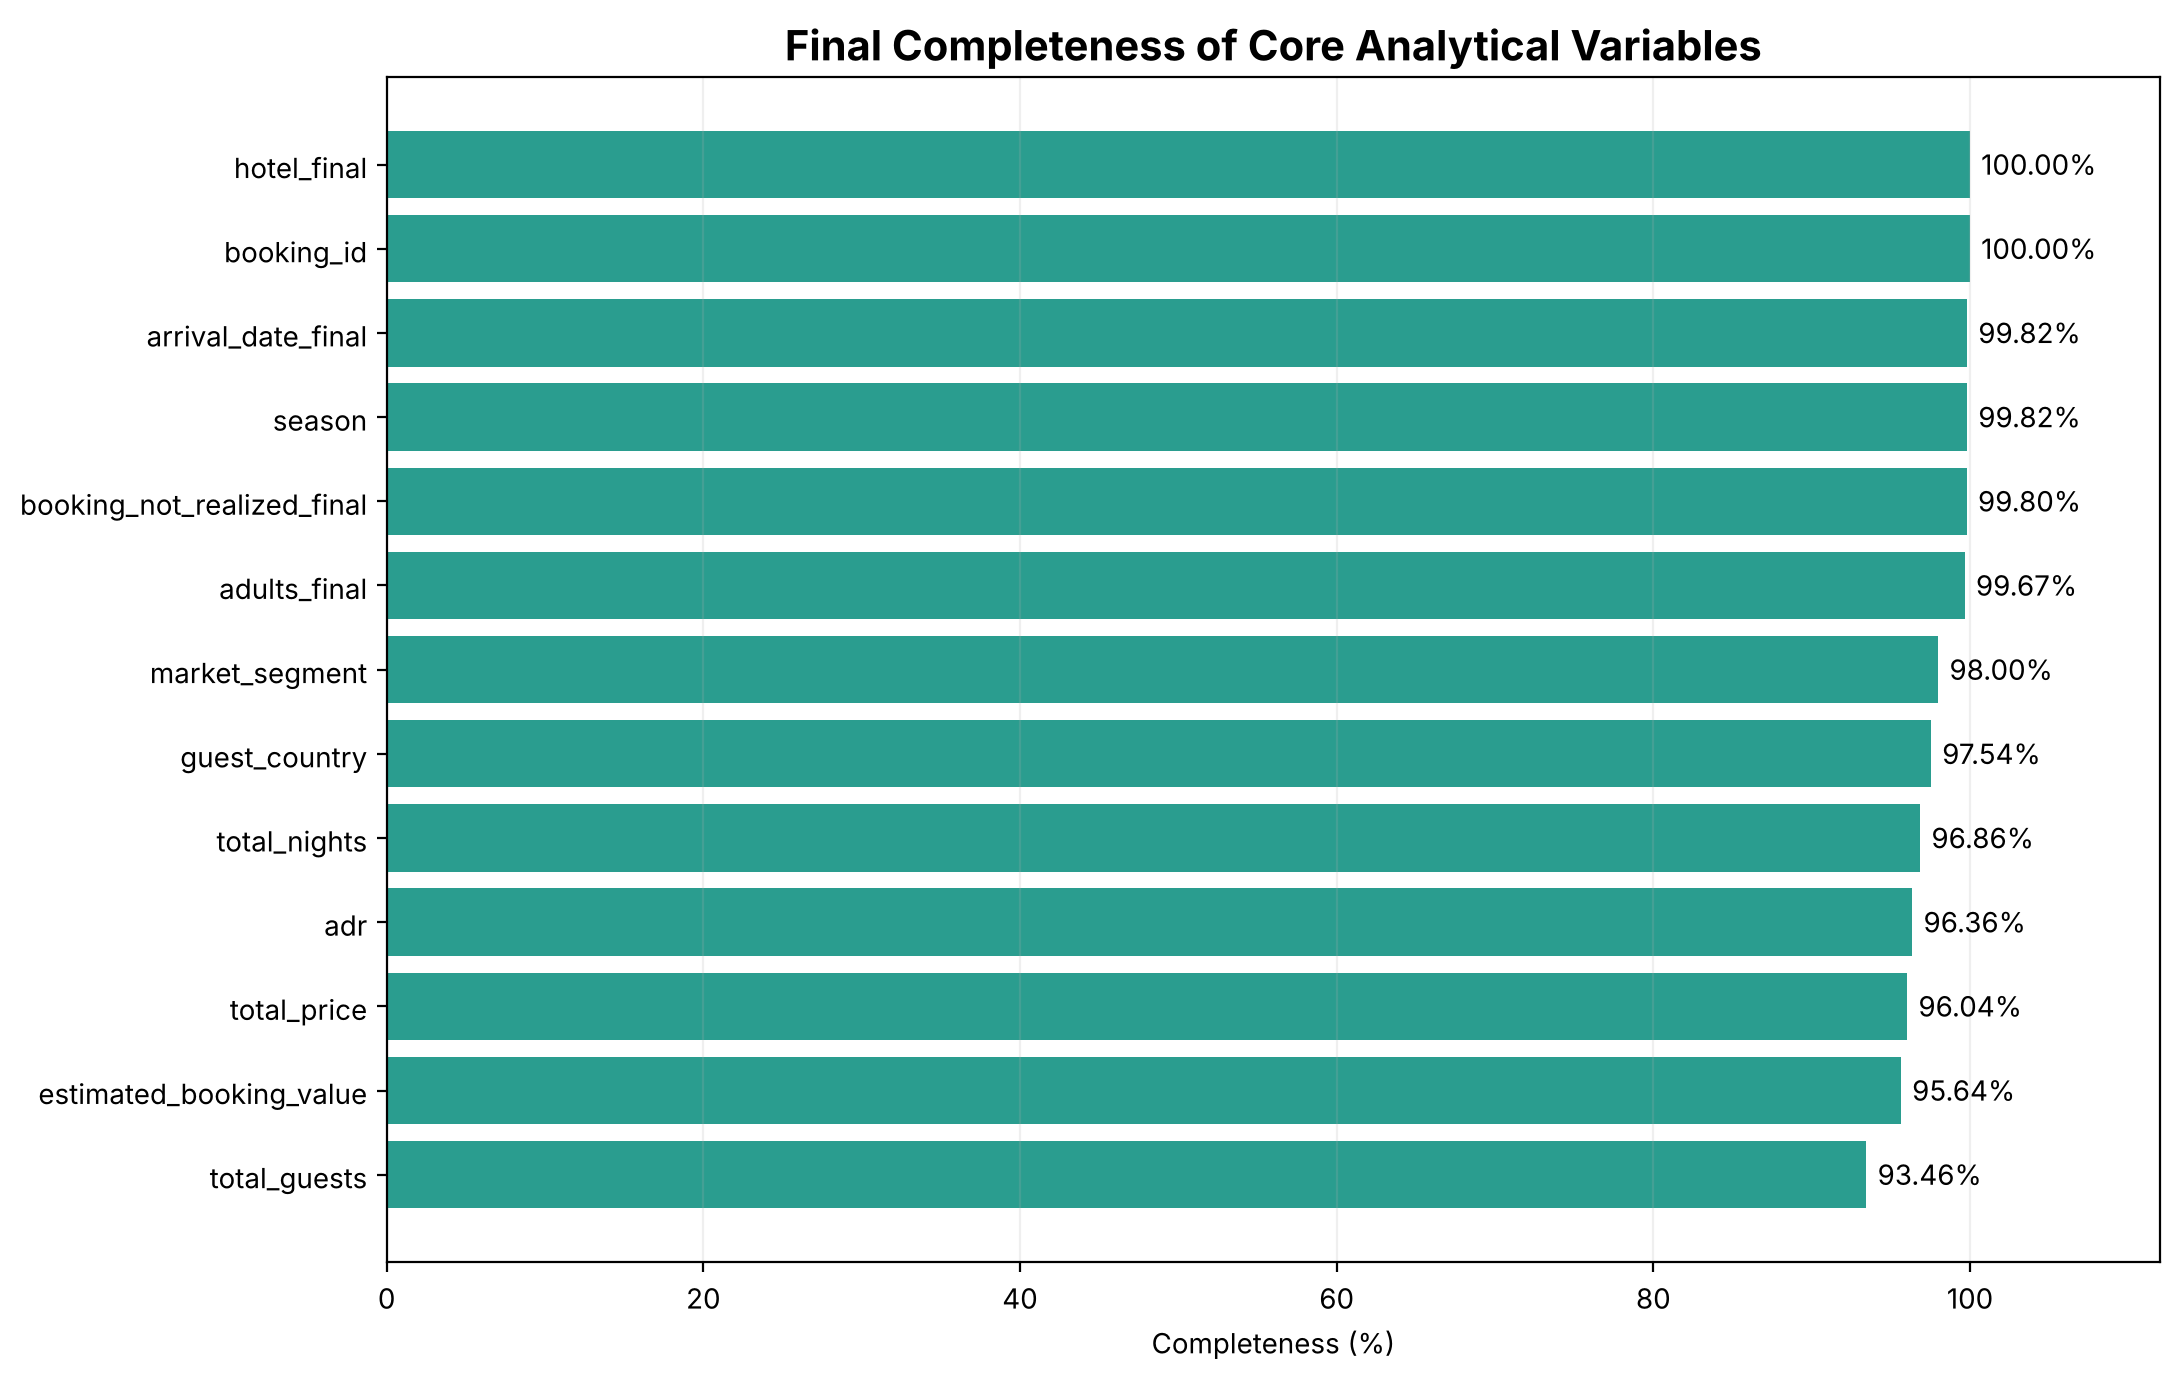

In [215]:
# Visualize core analytical variable completeness

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    core_completeness["Variable"],
    core_completeness["Completeness (%)"],
    color="#2A9D8F"
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4
)

ax.set_title(
    "Final Completeness of Core Analytical Variables",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Completeness (%)")
ax.set_xlim(0, 112)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

### 8.3 Structural and Source-Level Missing Values

The full outer integration strategy introduces
structural missing values for bookings available in
only one source system.

Structural missingness is distinguished from missing
information within available source records.

This distinction prevents the integration strategy
from being incorrectly interpreted as a deterioration
in original source data quality.

Unresolved reconciliation conflicts are documented
separately through the existing conflict indicators.

In [216]:
# Identify source availability

pms_available = final_df["source_availability"].isin([
    "Both Systems", "PMS Only"
])

crm_available = final_df["source_availability"].isin([
    "Both Systems", "CRM Only"
])


# Select source-specific variables

source_variables = {
    "adr": ("PMS", pms_available),
    "children": ("PMS", pms_available),
    "stays_in_week_nights": ("PMS", pms_available),
    "total_price": ("CRM", crm_available),
    "guest_country": ("CRM", crm_available),
    "agent_id": ("CRM", crm_available),
    "company_id": ("CRM", crm_available)
}


# Distinguish structural and source-level missingness

missing_analysis = []

for variable, (source, available) in source_variables.items():

    missing = final_df[variable].isna()

    missing_analysis.append({
        "Variable": variable,
        "Source": source,
        "Total Missing": missing.sum(),
        "Structural Missing": (missing & ~available).sum(),
        "Source-Level Missing": (missing & available).sum()
    })


missing_breakdown = pd.DataFrame(missing_analysis)

display(missing_breakdown)


# Validate the missing value breakdown

assert (
    missing_breakdown["Structural Missing"] +
    missing_breakdown["Source-Level Missing"] ==
    missing_breakdown["Total Missing"]
).all()

print("Missing value classification: PASS")

,Variable,Source,Total Missing,Structural Missing,Source-Level Missing
0,adr,PMS,910,750,160
1,children,PMS,1560,750,810
2,stays_in_week_nights,PMS,785,750,35
3,total_price,CRM,990,500,490
4,guest_country,CRM,614,500,114
5,agent_id,CRM,3800,500,3300
6,company_id,CRM,23624,500,23124


Missing value classification: PASS


### 8.4 Before and After Reconciliation

The effectiveness of data integration and reconciliation
is evaluated by comparing the availability of business
information across the individual source variables
and the reconciled analytical variables.

All completeness rates are calculated using the same
population of 25,000 integrated bookings to ensure
comparability.

This assessment measures improvements in information
availability rather than confirmed corrections of
inconsistent source values.

In [217]:
# Compare source-level and reconciled completeness

comparison_variables = {
    "Hotel Property": (
        "hotel", "property", "hotel_final"
    ),

    "Arrival Date": (
        "arrival_date", "checkin_date", "arrival_date_final"
    ),

    "Adult Guests": (
        "adults", "n_adults", "adults_final"
    ),

    "Reservation Outcome": (
        "is_canceled",
        "crm_outcome_binary",
        "booking_not_realized_final"
    )
}


completeness_comparison = []

for concept, columns in comparison_variables.items():

    pms_col, crm_col, final_col = columns

    completeness_comparison.append({
        "Business Concept": concept,

        "PMS (%)":
            final_df[pms_col].notna().mean() * 100,

        "CRM (%)":
            final_df[crm_col].notna().mean() * 100,

        "Reconciled (%)":
            final_df[final_col].notna().mean() * 100
    })


before_after_completeness = pd.DataFrame(
    completeness_comparison
).set_index("Business Concept")


display(before_after_completeness.round(2))

,PMS (%),CRM (%),Reconciled (%)
Business Concept,,,
Hotel Property,97.0,98.00,100.00
Arrival Date,97.0,98.00,99.82
Adult Guests,97.0,97.02,99.67
Reservation Outcome,97.0,98.00,99.80


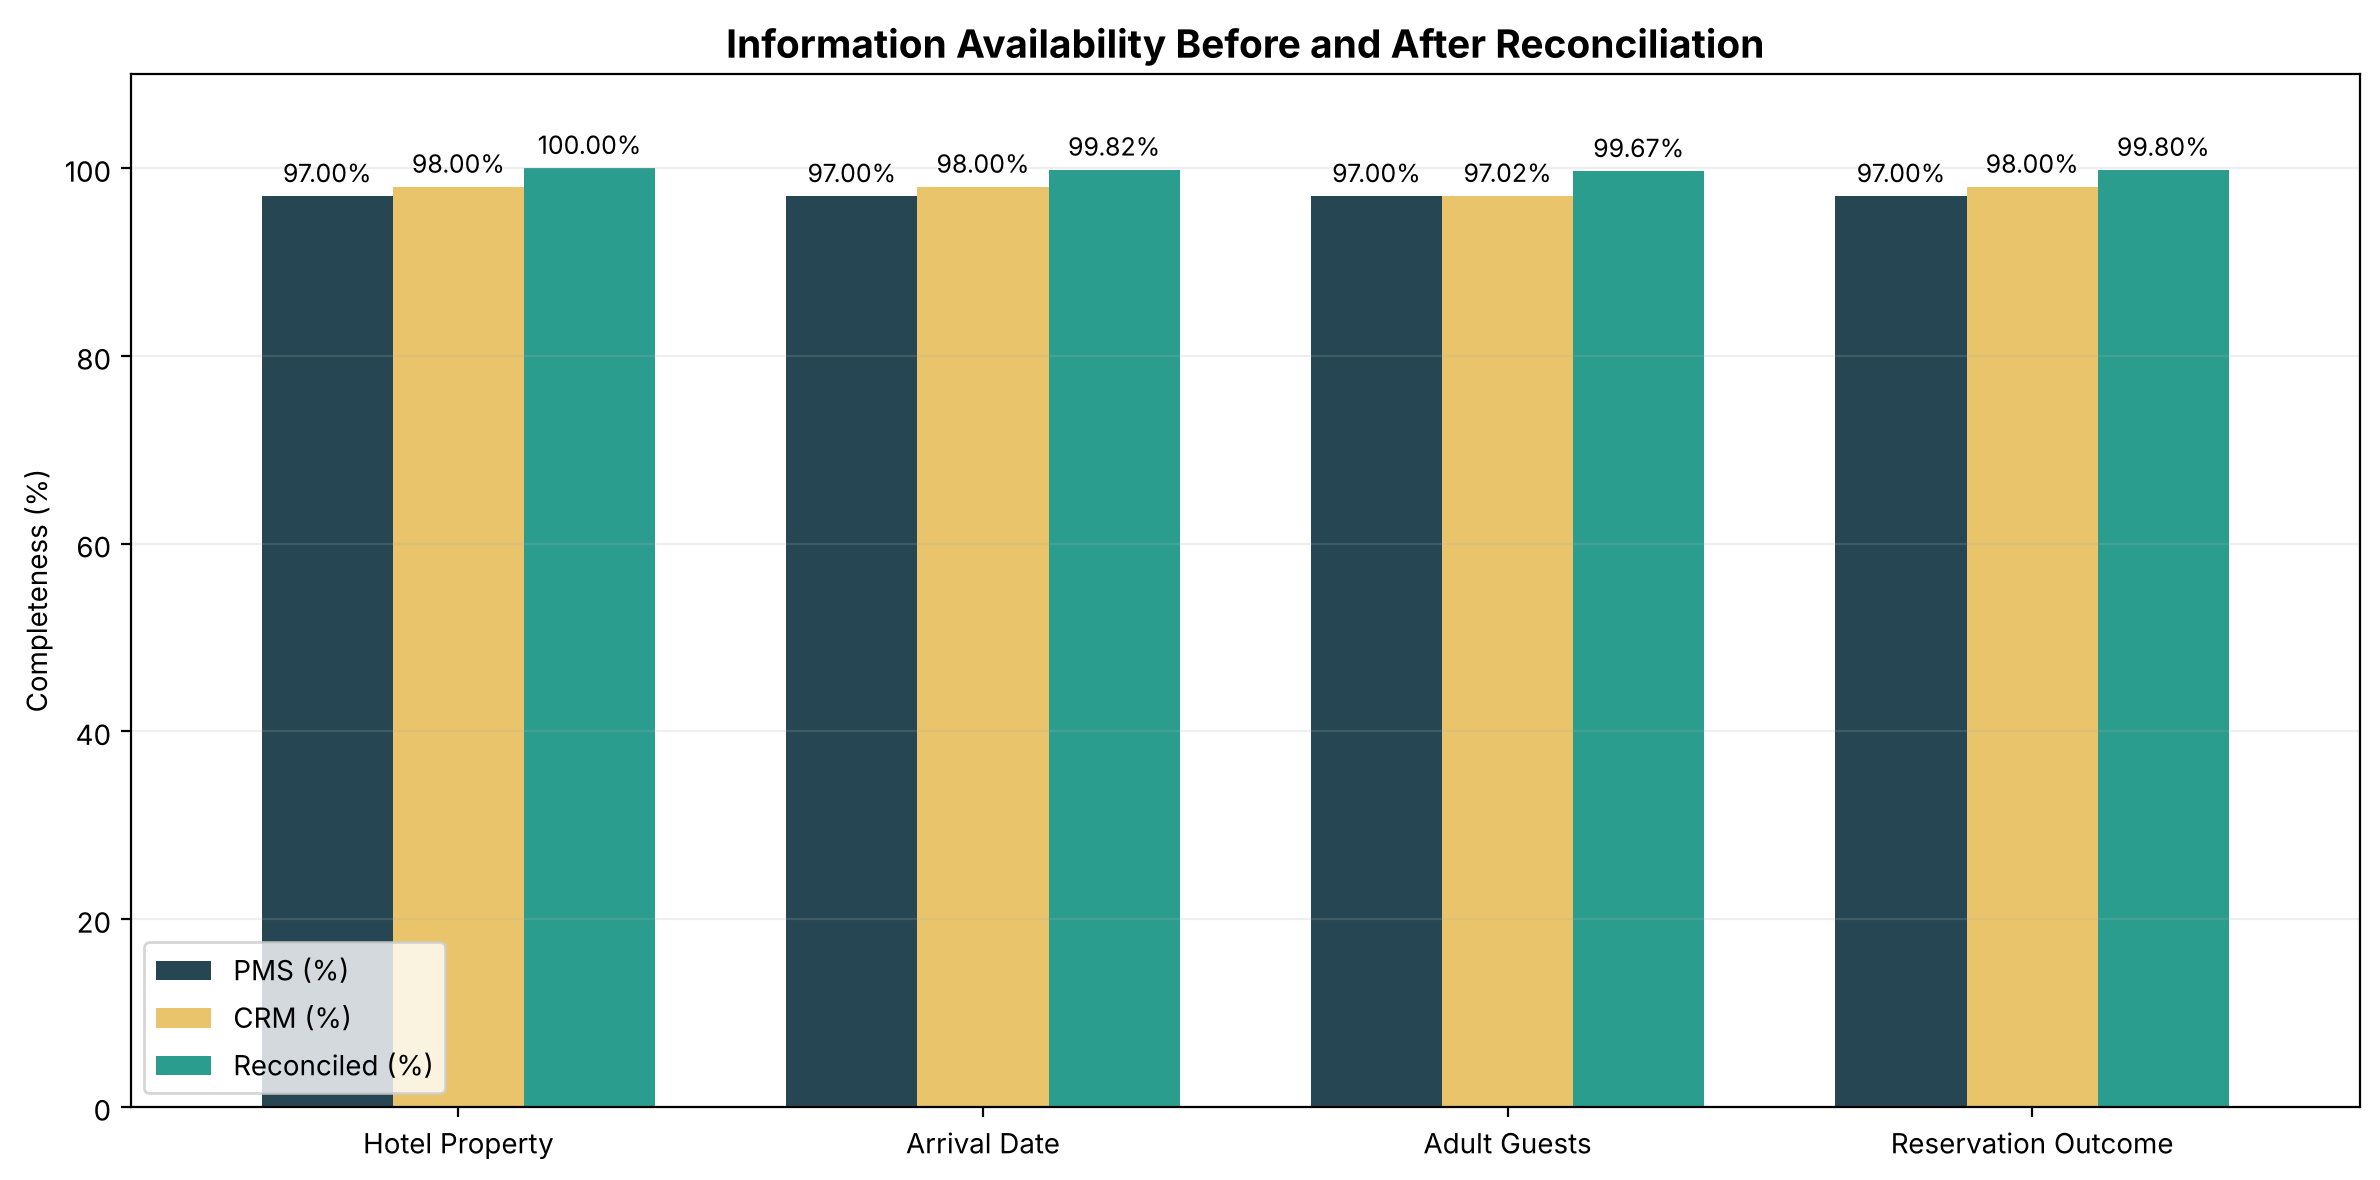

In [218]:
# Visualize completeness before and after reconciliation

ax = before_after_completeness.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#264653", "#E9C46A", "#2A9D8F"],
    width=0.75
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=9
    )

ax.set_title(
    "Information Availability Before and After Reconciliation",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Completeness (%)")
ax.set_xlabel("")
ax.set_ylim(0, 110)

plt.xticks(rotation=0)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

### 8.5 Remaining Data Quality Issues

Remaining logical exceptions and potential anomalies
are documented before the final dataset is exported.

The assessment includes unresolved cross-system
conflicts, zero-night bookings, zero-guest bookings,
potentially implausible adult guest counts and
financial discrepancies.

These observations are retained for transparency
and are not automatically classified as confirmed
errors without sufficient supporting evidence.

In [219]:
# Summarize remaining quality issues

quality_issues = {

    "Bookings with unresolved conflicts":
        final_df["has_unresolved_conflict"].sum(),

    "Unresolved arrival date conflicts":
        final_df["arrival_date_conflict_flag"].sum(),

    "Unresolved adult guest conflicts":
        final_df["adults_conflict_flag"].sum(),

    "Unresolved reservation outcome conflicts":
        final_df["outcome_conflict_flag"].sum(),

    "Zero-night bookings":
        final_df["total_nights"].eq(0).sum(),

    "Zero-guest bookings":
        final_df["total_guests"].eq(0).sum(),

    "Adult counts requiring review":
        final_df["adult_count_review_flag"].sum(),

    "Zero ADR values":
        final_df["adr"].eq(0).sum(),

    "Zero CRM total prices":
        final_df["total_price"].eq(0).sum(),

    "Significant financial discrepancies":
        final_df["financial_discrepancy_flag"].sum(),

    "Severe financial discrepancies":
        final_df["financial_severe_flag"].sum()
}


# Create data quality issue summary

quality_issue_summary = pd.DataFrame({
    "Quality Indicator": list(quality_issues.keys()),
    "Affected Bookings": list(quality_issues.values())
})

quality_issue_summary["Share of All Bookings (%)"] = (
    quality_issue_summary["Affected Bookings"] /
    len(final_df) * 100
).round(3)

display(quality_issue_summary)

,Quality Indicator,Affected Bookings,Share of All Bookings (%)
0,Bookings with unresolved conflicts,168,0.672
1,Unresolved arrival date conflicts,45,0.180
2,Unresolved adult guest conflicts,75,0.300
3,Unresolved reservation outcome conflicts,50,0.200
4,Zero-night bookings,147,0.588
5,Zero-guest bookings,31,0.124
6,Adult counts requiring review,2,0.008
7,Zero ADR values,377,1.508
8,Zero CRM total prices,381,1.524
9,Significant financial discrepancies,273,1.092


In [220]:
# Document financial assessment coverage

print(
    "Financially comparable bookings:",
    final_df["financial_discrepancy_flag"].notna().sum()
)

print(
    "Financially non-comparable bookings:",
    final_df["financial_discrepancy_flag"].isna().sum()
)

print(
    "Significant financial discrepancies:",
    final_df["financial_discrepancy_flag"].sum()
)

print(
    "Severe financial discrepancies:",
    final_df["financial_severe_flag"].sum()
)

Financially comparable bookings: 22734
Financially non-comparable bookings: 2266
Significant financial discrepancies: 273
Severe financial discrepancies: 1


In [221]:
# Create the final data quality scorecard

quality_scorecard = pd.DataFrame({
    "Quality Dimension": [
        "Booking coverage",
        "Identifier completeness",
        "Identifier uniqueness",
        "Source matching",
        "Hotel completeness",
        "Arrival date completeness",
        "Adult guest completeness",
        "Reservation outcome completeness",
        "Bookings without detected reconciliation conflicts",
        "Financial comparison coverage"
    ],

    "Result (%)": [
        len(final_df) / len(all_booking_ids) * 100,

        final_df["booking_id"].notna().mean() * 100,

        final_df["booking_id"].nunique() /
        len(final_df) * 100,

        final_df["source_availability"]
        .eq("Both Systems").mean() * 100,

        final_df["hotel_final"].notna().mean() * 100,

        final_df["arrival_date_final"].notna().mean() * 100,

        final_df["adults_final"].notna().mean() * 100,

        final_df["booking_not_realized_final"]
        .notna().mean() * 100,

        (~final_df["has_unresolved_conflict"])
        .mean() * 100,

        final_df["financial_discrepancy_flag"]
        .notna().mean() * 100
    ]
})

quality_scorecard["Result (%)"] = (
    quality_scorecard["Result (%)"].round(2)
)

display(quality_scorecard)

,Quality Dimension,Result (%)
0,Booking coverage,100.00
1,Identifier completeness,100.00
2,Identifier uniqueness,100.00
3,Source matching,95.00
4,Hotel completeness,100.00
5,Arrival date completeness,99.82
6,Adult guest completeness,99.67
7,Reservation outcome completeness,99.80
8,Bookings without detected reconciliation confl...,99.33
9,Financial comparison coverage,90.94


8.7 Results & Interpretation

The post-merge data quality assessment demonstrates that the analytical dataset provides high information availability across the core reconciled business variables.

All 25,000 distinct bookings available from the cleaned source datasets have been preserved, with complete and unique booking identifiers.

Hotel property information achieves 100% completeness, while reconciled arrival dates, adult guest counts and reservation outcomes achieve completeness rates exceeding 99.6%.

The integration and reconciliation processes improve the availability of business information by combining complementary values from the PMS and CRM systems.

Structural missing values are explicitly distinguished from missing information within available source records, preventing misleading interpretations of dataset completeness.

Remaining data quality limitations include unresolved cross-system conflicts, incomplete guest information, zero-night and zero-price observations, potentially implausible guest counts and financial discrepancies.

These observations are documented through dedicated quality indicators rather than automatically removed or corrected without supporting evidence.

The dataset is suitable for downstream business analysis, provided that variable-specific completeness, unresolved discrepancies, financial definitions and source availability are considered when calculating and interpreting business performance indicators.

# 9. Final Validation, Documentation & Export

9.1 Final Validation Strategy

Before exporting the analytical dataset, a comprehensive validation process is performed to confirm its structural integrity, consistency and suitability for downstream business analysis.

The final validation focuses on booking preservation, identifier uniqueness, source coverage, original information preservation, analytical feature validity and documentation of unresolved discrepancies.

A data dictionary is also generated to provide clear definitions, data types, completeness indicators and analytical considerations for the exported variables.

The final deliverables are designed to support reproducibility, transparency and effective collaboration throughout the subsequent business analysis phase.

In [222]:
# Calculate expected booking identifiers directly from both sources

expected_booking_ids = (
    set(pms["booking_id"].dropna()) |
    set(crm["BookingRef"].dropna())
)


# Perform final validation checks

final_checks = {

    "Expected booking count":
        len(final_df) == 25000,

    "Expected variable count":
        final_df.shape[1] == 75,

    "No missing booking identifiers":
        final_df["booking_id"].notna().all(),

    "Unique booking identifiers":
        final_df["booking_id"].is_unique,

    "All source booking identifiers preserved":
        set(final_df["booking_id"]) == expected_booking_ids,

    "No fully duplicated records":
        final_df.duplicated().sum() == 0,

    "Original integrated variables preserved":
        final_df[integrated.columns].equals(integrated),

    "Expected matched bookings":
        final_df["source_availability"]
        .eq("Both Systems").sum() == 23750,

    "Expected PMS-only bookings":
        final_df["source_availability"]
        .eq("PMS Only").sum() == 500,

    "Expected CRM-only bookings":
        final_df["source_availability"]
        .eq("CRM Only").sum() == 750,

    "Complete hotel information":
        final_df["hotel_final"].notna().all(),

    "Valid reservation outcome values":
        final_df["booking_not_realized_final"]
        .dropna().isin([0, 1]).all(),

    "Non-negative total nights":
        final_df["total_nights"].dropna().ge(0).all(),

    "Non-negative estimated booking values":
        final_df["estimated_booking_value"]
        .dropna().ge(0).all(),

    "Unresolved conflicts documented":
        final_df["has_unresolved_conflict"].sum() == 168,

    "Financial discrepancies documented":
        final_df["financial_discrepancy_flag"].sum() == 273,

    "All reconciliation checks passed":
        all(reconciliation_checks.values()),

    "All feature engineering checks passed":
        all(feature_checks.values())
}


# Create final validation report

final_validation = pd.DataFrame({
    "Validation Check": list(final_checks.keys()),

    "Status": [
        "PASS" if result else "FAIL"
        for result in final_checks.values()
    ]
})

display(final_validation)

assert all(final_checks.values()), \
    "One or more final validation checks failed."

print(
    f"Final validation completed: "
    f"{sum(final_checks.values())}/"
    f"{len(final_checks)} checks passed."
)

print("Final dataset shape:", final_df.shape)

,Validation Check,Status
0,Expected booking count,PASS
1,Expected variable count,PASS
2,No missing booking identifiers,PASS
3,Unique booking identifiers,PASS
4,All source booking identifiers preserved,PASS
5,No fully duplicated records,PASS
6,Original integrated variables preserved,PASS
7,Expected matched bookings,PASS
8,Expected PMS-only bookings,PASS
9,Expected CRM-only bookings,PASS


Final validation completed: 18/18 checks passed.
Final dataset shape: (25000, 75)


### 9.3 Data Dictionary

A data dictionary is generated to document the variables
included in the final analytical dataset.

The dictionary provides variable definitions, source
information, data types, missing value counts and
completeness rates.

Particular attention is given to reconciled variables,
engineered features and data quality indicators,
ensuring that downstream analyses use appropriate
business definitions.

In [223]:
# Define analytical variable descriptions

variable_descriptions = {

    "booking_id":
        "Unique booking identifier across both systems.",

    "BookingRef":
        "Original CRM booking identifier, if retained.",

    "hotel":
        "Original cleaned PMS hotel property.",

    "property":
        "Original cleaned CRM hotel property.",

    "arrival_date":
        "Arrival date derived from PMS information.",

    "checkin_date":
        "Check-in date recorded in the CRM.",

    "adults":
        "Number of adults recorded in the PMS.",

    "n_adults":
        "Number of adults recorded in the CRM.",

    "children":
        "Number of children recorded in the PMS.",

    "babies":
        "Number of babies recorded in the PMS.",

    "arrival_date_year":
        "Original PMS arrival year.",

    "arrival_date_month":
        "Original PMS arrival month.",

    "arrival_date_day_of_month":
        "Original PMS arrival day of the month.",

    "stays_in_weekend_nights":
        "Number of booked weekend nights.",

    "stays_in_week_nights":
        "Number of booked weekday nights.",

    "meal":
        "Meal plan associated with the booking.",

    "reserved_room_type":
        "Room type originally reserved.",

    "assigned_room_type":
        "Room type assigned to the booking.",

    "booking_changes":
        "Number of recorded booking modifications.",

    "deposit_type":
        "Deposit arrangement associated with the booking.",

    "adr":
        "Cleaned PMS average daily rate.",

    "adr_before_correction":
        "ADR value before scale and negative value treatment.",

    "adr_scale_corrected":
        "Indicator of an applied ADR scale correction.",

    "adr_negative_flag":
        "Indicator of an originally negative ADR value.",

    "required_car_parking_spaces":
        "Number of requested parking spaces.",

    "total_of_special_requests":
        "Number of recorded special requests.",

    "is_canceled":
        "Original PMS binary cancellation indicator.",

    "record_updated_at":
        "Recorded PMS update timestamp.",

    "lead_time_days":
        "Number of days between booking and scheduled arrival.",

    "guest_country":
        "Guest country recorded in the CRM.",

    "market_segment":
        "Market segment associated with the booking.",

    "distribution_channel":
        "Booking distribution channel.",

    "customer_type":
        "CRM customer classification.",

    "is_repeated_guest":
        "Indicator of a returning guest.",

    "agent_id":
        "Identifier of the associated booking agent.",

    "company_id":
        "Identifier of the associated company.",

    "reservation_status":
        "Original CRM reservation outcome category.",

    "reservation_status_date":
        "Date associated with the CRM reservation status.",

    "zero_adults_flag":
        "CRM indicator of a zero-adult booking.",

    "total_price":
        "Total booking price recorded in the CRM; not confirmed realized revenue.",

    "source_availability":
        "Indicates whether a booking is available in both systems or only one.",

    "hotel_final":
        "Reconciled hotel property.",

    "arrival_date_final":
        "Reconciled arrival date; unresolved conflicts remain missing.",

    "adults_final":
        "Reconciled adult guest count; unresolved conflicts remain missing.",

    "crm_outcome_binary":
        "CRM outcome mapped to 0 for Check-Out and 1 for Canceled or No-Show.",

    "booking_not_realized_final":
        "Reconciled binary booking outcome, including cancellations and no-shows.",

    "number_of_conflicts":
        "Number of unresolved conflicts across four shared business concepts.",

    "has_unresolved_conflict":
        "Indicates at least one unresolved business variable conflict.",

    "financial_relative_difference_pct":
        "Absolute relative financial difference for comparable bookings.",

    "financial_consistency_status":
        "Classification of financial alignment or discrepancy magnitude.",

    "financial_discrepancy_flag":
        "Indicates a relative financial difference greater than 10%.",

    "financial_severe_flag":
        "Indicates a relative financial difference greater than 50%.",

    "total_nights":
        "Sum of booked weekend and weekday nights.",

    "total_guests":
        "Sum of adults, children and babies when all components are available and the adult count passes the exploratory plausibility rule.",

    "adult_count_review_flag":
        "Flags reconciled adult counts below zero or above 20 for review.",

    "arrival_year":
        "Calendar year extracted from the reconciled arrival date.",

    "arrival_month":
        "Calendar month extracted from the reconciled arrival date.",

    "arrival_year_month":
        "Year-month identifier derived from the reconciled arrival date.",

    "arrival_quarter":
        "Calendar quarter extracted from the reconciled arrival date.",

    "season":
        "Meteorological season derived from the arrival month.",

    "estimated_booking_value":
        "Estimated booking value calculated as ADR multiplied by booked nights; not realized revenue.",

    "stay_duration_category":
        "Analytical classification based on booked stay duration.",

    "booking_outcome":
        "Descriptive category derived from the reconciled binary booking outcome."
}

In [224]:
# Complete the remaining variable definitions

variable_descriptions.update({

    "previous_cancellations":
        "Number of previous bookings canceled by the guest.",

    "previous_bookings_not_canceled":
        "Number of previous bookings not canceled by the guest.",

    "days_in_waiting_list":
        "Number of days the booking remained on the waiting list.",

    "zero_price_flag":
        "Flags bookings with a recorded CRM total price equal to zero.",

    "status_date_flag":
        "Flags potential temporal inconsistencies involving the reservation status date."

})

In [225]:
# Generate definitions for reconciliation indicators

for concept in ["hotel", "arrival_date", "adults", "outcome"]:

    variable_descriptions[f"{concept}_conflict_flag"] = (
        f"Indicates an unresolved cross-system conflict for {concept}."
    )

    variable_descriptions[f"{concept}_provenance"] = (
        f"Documents the source or reconciliation outcome for {concept}."
    )


# Identify variable origins

def identify_variable_source(column):

    if column == "booking_id":
        return "Integrated identifier"

    elif column in engineered_features:
        return "Feature Engineering"

    elif column not in integrated.columns:
        return "Reconciliation"

    elif column in pms.columns and column in crm.columns:
        return "Shared Source Variable"

    elif column in pms.columns:
        return "PMS"

    elif column in crm.columns:
        return "CRM"

    else:
        return "Integration"


# Generate data dictionary

data_dictionary = pd.DataFrame({
    "Variable": final_df.columns,

    "Description": [
        variable_descriptions.get(
            col,
            "Definition requires source documentation review."
        )
        for col in final_df.columns
    ],

    "Source": [
        identify_variable_source(col)
        for col in final_df.columns
    ],

    "Data Type": [
        str(final_df[col].dtype)
        for col in final_df.columns
    ],

    "Available Values": [
        final_df[col].notna().sum()
        for col in final_df.columns
    ],

    "Missing Values": [
        final_df[col].isna().sum()
        for col in final_df.columns
    ],

    "Completeness (%)": [
        round(final_df[col].notna().mean() * 100, 2)
        for col in final_df.columns
    ]
})

display(data_dictionary)

print("Documented variables:", len(data_dictionary))

,Variable,Description,Source,Data Type,Available Values,Missing Values,Completeness (%)
0,booking_id,Unique booking identifier across both systems.,Integrated identifier,string,25000,0,100.00
1,hotel,Original cleaned PMS hotel property.,PMS,string,24250,750,97.00
2,arrival_date_year,Original PMS arrival year.,PMS,float64,24250,750,97.00
3,arrival_date_month,Original PMS arrival month.,PMS,string,24250,750,97.00
4,arrival_date_day_of_month,Original PMS arrival day of the month.,PMS,float64,24250,750,97.00
5,stays_in_weekend_nights,Number of booked weekend nights.,PMS,float64,24250,750,97.00
6,stays_in_week_nights,Number of booked weekday nights.,PMS,Int64,24215,785,96.86
7,adults,Number of adults recorded in the PMS.,PMS,float64,24250,750,97.00
8,children,Number of children recorded in the PMS.,PMS,Int64,23440,1560,93.76
9,babies,Number of babies recorded in the PMS.,PMS,float64,24250,750,97.00


Documented variables: 75


In [226]:
# Identify variables requiring additional documentation

undocumented_variables = data_dictionary.loc[
    data_dictionary["Description"].eq(
        "Definition requires source documentation review."
    ),
    "Variable"
].tolist()

print("Variables requiring additional documentation:")
print(undocumented_variables)

Variables requiring additional documentation:
[]


9.4 Business Analysis Guidelines

The following analytical considerations should be applied during downstream business analysis:

Hotel performance: Use hotel_final as the primary hotel classification variable.

Temporal analysis: Use arrival_date_final and the engineered temporal features. Comparisons across years must account for differences in observation period coverage.

Reservation outcomes: Use booking_not_realized_final for combined cancellation and no-show analysis. Exclude unresolved outcomes from the corresponding rate denominator and report the excluded population. Use the original CRM reservation status when distinguishing cancellations from no-shows.

Financial analysis: Treat total_price and estimated_booking_value as separate booking-level financial measures. Neither variable independently confirms realized revenue. Financial discrepancy flags should be considered when performing sensitivity analyses.

Guest analysis: Use adults_final and total_guests, accounting for missing information, potentially implausible adult counts and zero-guest observations.

Customer segmentation: Use CRM country, market segment, distribution channel and customer type information. Booking counts should not be interpreted as counts of distinct customers without a unique customer identifier.

Source availability: Consider source_availability when evaluating differences in analytical coverage across variables.

Data quality: Retain visibility into unresolved conflicts, structural missing values and financial anomalies. Apply metric-specific eligibility criteria rather than systematically removing all flagged bookings.

Occupancy analysis: Booked nights can be analyzed, but hotel occupancy rates cannot be reliably calculated without information on available room capacity.

### 9.5 Export Final Deliverables

The validated analytical dataset and supporting
documentation are exported in CSV format.

The exported deliverables provide the foundation for
the subsequent business analysis notebook while
preserving transparency regarding data quality,
variable definitions and validation results.

In [227]:
# Complete the missing variable definitions

variable_descriptions.update({
    "previous_cancellations":
        "Number of previous bookings canceled by the guest.",

    "previous_bookings_not_canceled":
        "Number of previous bookings not canceled by the guest.",

    "days_in_waiting_list":
        "Number of days the booking remained on the waiting list.",

    "zero_price_flag":
        "Flags bookings with a recorded CRM total price equal to zero.",

    "status_date_flag":
        "Flags potential temporal inconsistencies involving the reservation status date."
})

# Update the data dictionary directly

data_dictionary["Description"] = data_dictionary["Variable"].map(
    variable_descriptions
).fillna("Definition requires source documentation review.")

# Recalculate undocumented variables

undocumented_variables = data_dictionary.loc[
    data_dictionary["Description"].eq(
        "Definition requires source documentation review."
    ),
    "Variable"
].tolist()

print("Remaining undocumented variables:", undocumented_variables)

assert not undocumented_variables

print("Data dictionary validation: PASS")

Remaining undocumented variables: []
Data dictionary validation: PASS


In [228]:
# Ensure final validation and documentation are complete

assert all(final_checks.values())

assert len(data_dictionary) == len(final_df.columns)

print(undocumented_variables)

assert not undocumented_variables, "Complete missing variable definitions before export."

[]


In [229]:
# Export final dataset and documentation

final_df.to_csv(
    "hotel_integrated_cleaned.csv",
    index=False
)

data_dictionary.to_csv(
    "data_dictionary.csv",
    index=False
)

quality_scorecard.to_csv(
    "data_quality_scorecard.csv",
    index=False
)

quality_issue_summary.to_csv(
    "remaining_quality_issues.csv",
    index=False
)

final_validation.to_csv(
    "final_validation_report.csv",
    index=False
)

print("All five project deliverables exported successfully.")

All five project deliverables exported successfully.


In [230]:
# Reload the exported dataset

exported_df = pd.read_csv(
    "hotel_integrated_cleaned.csv",
    dtype={"booking_id": "string"}
)


# Validate exported dataset integrity

assert exported_df.shape == final_df.shape

assert exported_df.columns.tolist() == final_df.columns.tolist()

assert exported_df["booking_id"].is_unique

assert set(exported_df["booking_id"]) == expected_booking_ids

assert exported_df.isna().sum().equals(
    final_df.isna().sum()
)

print("CSV export verification: PASS")

print("Exported rows:", len(exported_df))

print("Exported columns:", len(exported_df.columns))

CSV export verification: PASS
Exported rows: 25000
Exported columns: 75


# 10. Final Conclusions

The integration of the Property Management System (PMS) and Customer Relationship Management (CRM) datasets successfully produced a unified analytical dataset containing 25,000 unique bookings and 75 variables.

10.1 Key Integration Results

The integration process achieved the following results:

* 100% preservation of booking identifiers from both cleaned source datasets.
* 23,750 matched bookings, representing a 95% cross-system matching rate.
* 500 PMS-only bookings and 750 CRM-only bookings successfully retained.
* No missing or duplicated booking identifiers.
* Complete documentation of all 75 variables.
* Successful completion of all 18 final validation checks.

The adoption of a Full Outer Join maximized booking coverage and prevented the unnecessary loss of valuable information.

10.2 Data Quality and Reconciliation

The cross-system consistency assessment demonstrated a high level of agreement between the two systems.

Following reconciliation, the final business variables achieved:

* Hotel property completeness: 100%.
* Arrival date completeness: 99.82%.
* Adult guest completeness: 99.67%.
* Reservation outcome completeness: 99.80%.

A total of 168 bookings, representing 0.672% of the integrated dataset, contained unresolved reconciliation conflicts. These conflicts were explicitly documented rather than resolved through unsupported assumptions.

Original source values were preserved to ensure transparency, traceability and reproducibility.

10.3 Financial Consistency

The financial comparison covered 22,734 bookings, representing 90.94% of the integrated dataset.

The mean absolute relative difference between the PMS estimated booking value and the CRM total price was 0.32%, indicating substantial agreement among comparable records.

However, 273 significant financial discrepancies were identified, including one severe discrepancy requiring further investigation.

Financial differences were preserved and documented rather than automatically corrected, as the two measures may reflect different business definitions.

10.4 Remaining Limitations

Despite the high level of data quality achieved, certain limitations remain:

* Some bookings are available in only one source system.
* A limited number of business variables contain unresolved conflicts.
* Certain missing values cannot be reliably reconstructed.
* Financial measures should not automatically be interpreted as realized revenue.
* Structural missing values may affect the coverage of specific business analyses.

These limitations must be considered when calculating business KPIs and interpreting analytical results.

10.5 Business Readiness

The final integrated dataset provides a documented and validated foundation for subsequent business analysis, including:

* Revenue and booking value analysis.
* Hotel performance comparison.
* Customer segmentation.
* Cancellation behavior.
* Booking seasonality.
* Operational and commercial performance.

The integration process demonstrates that effective data preparation is not simply about eliminating missing values or discrepancies, but about creating a reliable, transparent and business-relevant analytical foundation.

The resulting dataset is ready for the next phase of the project, where integrated information will be transformed into actionable business insights.

---
# PART 4 – BUSINESS ANALYSIS & RECOMMENDATIONS

## Business Analysis & Business Intelligence
## 1. Introduction & Business Objectives

In the previous notebooks we cleaned the PMS and the CRM exports and then merged them into
one dataset with 25,000 bookings. Now that we have data we can trust, we want to use it to
understand how the two hotels are actually doing.

The two properties are quite different: a City Hotel and a Resort Hotel, both in Portugal,
with arrivals from July 2015 to August 2017. We look at them from the point of view of a
manager who has to decide where to put effort and money.

The questions we want to answer are:
- Which hotel performs better economically, and why?
- Which types of customers bring the most value?
- When in the year do the hotels get more bookings?
- Which customers cancel more?
- What could the hotels do to improve?

Each section follows the same logic: what we want to find out, the calculations, a chart,
what the numbers say, why it matters for the business, and what the limits of the analysis
are. At the end we put everything together in a scorecard and a list of recommendations.

In [231]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:,.2f}".format)

# same two colours for the two hotels in every chart
HOTEL_COLORS = {"City Hotel": "#2A9D8F", "Resort Hotel": "#E76F51"}
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## 2. Integrated Dataset Overview

We don't redo any cleaning here: this section is only about getting to know the dataset
we received from the integration notebook.

In [232]:
df = pd.read_csv("hotel_integrated_cleaned.csv", low_memory=False,
                 parse_dates=["arrival_date_final", "checkin_date", "reservation_status_date"])

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 25000
Columns: 75


,booking_id,hotel,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,reserved_room_type,assigned_room_type,booking_changes,deposit_type,adr,required_car_parking_spaces,total_of_special_requests,is_canceled,record_updated_at,adr_before_correction,adr_scale_corrected,adr_negative_flag,arrival_date,property,checkin_date,n_adults,lead_time_days,guest_country,market_segment,distribution_channel,customer_type,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,agent_id,company_id,days_in_waiting_list,reservation_status,reservation_status_date,total_price,zero_adults_flag,zero_price_flag,status_date_flag,source_availability,hotel_final,hotel_conflict_flag,hotel_provenance,arrival_date_final,arrival_date_conflict_flag,arrival_date_provenance,adults_final,adults_conflict_flag,adults_provenance,crm_outcome_binary,booking_not_realized_final,outcome_conflict_flag,outcome_provenance,financial_relative_difference_pct,financial_consistency_status,financial_discrepancy_flag,financial_severe_flag,number_of_conflicts,has_unresolved_conflict,total_nights,adult_count_review_flag,total_guests,arrival_year,arrival_month,arrival_year_month,arrival_quarter,season,estimated_booking_value,stay_duration_category,booking_outcome
0,BK300001,Resort Hotel,"2,016.00",June,26.00,2.00,5.00,3.00,0.00,0.00,BB,E,E,0.00,No Deposit,153.24,0.00,2.00,0.00,2016-05-05,153.24,False,False,2016-06-26,Resort Hotel,2016-06-26,3.00,136.00,IRL,Direct,Direct,Transient,0.00,0.00,0.00,250.00,NaN,0.00,Check-Out,2016-07-03,"1,072.68",False,False,False,Both Systems,Resort Hotel,False,Agreement,2016-06-26,False,Agreement,3.00,False,Agreement,0.00,0.00,False,Agreement,0.00,Close Alignment,False,False,0,False,7.00,False,3.00,"2,016.00",6.00,2016-06,2.00,Summer,"1,072.68",Medium Stay,Not Canceled / Completed
1,BK300002,Resort Hotel,"2,016.00",July,23.00,2.00,5.00,2.00,1.00,0.00,BB,A,A,0.00,No Deposit,166.50,0.00,0.00,0.00,2016-07-28,166.50,False,False,2016-07-23,Resort Hotel,2016-07-23,2.00,135.00,PRT,Direct,Direct,Transient,0.00,0.00,0.00,250.00,NaN,0.00,Check-Out,2016-07-30,"1,165.50",False,False,False,Both Systems,Resort Hotel,False,Agreement,2016-07-23,False,Agreement,2.00,False,Agreement,0.00,0.00,False,Agreement,0.00,Close Alignment,False,False,0,False,7.00,False,3.00,"2,016.00",7.00,2016-07,3.00,Summer,"1,165.50",Medium Stay,Not Canceled / Completed
2,BK300003,City Hotel,"2,016.00",October,20.00,0.00,3.00,1.00,0.00,0.00,BB,A,A,1.00,No Deposit,95.50,0.00,1.00,0.00,2016-10-05,95.50,False,False,2016-10-20,City Hotel,2016-10-20,1.00,205.00,CHE,Online TA,TA/TO,Transient,0.00,0.00,0.00,9.00,NaN,0.00,Check-Out,2016-10-23,286.50,False,False,False,Both Systems,City Hotel,False,Agreement,2016-10-20,False,Agreement,1.00,False,Agreement,0.00,0.00,False,Agreement,0.00,Close Alignment,False,False,0,False,3.00,False,1.00,"2,016.00",10.00,2016-10,4.00,Autumn,286.50,Medium Stay,Not Canceled / Completed
3,BK300004,City Hotel,"2,016.00",July,6.00,0.00,4.00,2.00,0.00,0.00,BB,D,D,0.00,No Deposit,127.80,0.00,0.00,1.00,2016-05-18,127.80,False,False,2016-07-06,City Hotel,2016-07-06,2.00,95.00,GBR,Online TA,TA/TO,Transient,0.00,0.00,0.00,9.00,NaN,0.00,Canceled,2016-06-19,511.20,False,False,False,Both Systems,City Hotel,False,Agreement,2016-07-06,False,Agreement,2.00,False,Agreement,1.00,1.00,False,Agreement,0.00,Close Alignment,False,False,0,False,4.00,False,2.00,"2,016.00",7.00,2016-07,3.00,Summer,511.20,Medium Stay,Canceled / No-Show
4,BK300005,Resort Hotel,"2,016.00",August,16.00,1.00,5.00,2.00,0.00,0.00,BB,G,G,1.00,No Deposit,269.00,0.00,1.00,0.00,2016-07-29,269.00,False,False,2016-08-16,Resort Hotel,2016-08-16,2.00,58.00,ESP,Online TA,TA/TO,Transient,0.00,0.00,0.00,240.00,NaN,0.00,Check-Out,2016-08-22,"1,614.00",False,False,False,Both Systems,Resort Hotel,False,Agreement,2016-08-16,False,Agreement,2.00,False,Agreement,0.00,0.00,False,Agreement,0.00,Close Alignment,False,False,0,False,6.00,False,

In [233]:
df.columns.tolist()

['booking_id',
 'hotel',
 'arrival_date_year',
 'arrival_date_month',
 'arrival_date_day_of_month',
 'stays_in_weekend_nights',
 'stays_in_week_nights',
 'adults',
 'children',
 'babies',
 'meal',
 'reserved_room_type',
 'assigned_room_type',
 'booking_changes',
 'deposit_type',
 'adr',
 'required_car_parking_spaces',
 'total_of_special_requests',
 'is_canceled',
 'record_updated_at',
 'adr_before_correction',
 'adr_scale_corrected',
 'adr_negative_flag',
 'arrival_date',
 'property',
 'checkin_date',
 'n_adults',
 'lead_time_days',
 'guest_country',
 'market_segment',
 'distribution_channel',
 'customer_type',
 'is_repeated_guest',
 'previous_cancellations',
 'previous_bookings_not_canceled',
 'agent_id',
 'company_id',
 'days_in_waiting_list',
 'reservation_status',
 'reservation_status_date',
 'total_price',
 'zero_adults_flag',
 'zero_price_flag',
 'status_date_flag',
 'source_availability',
 'hotel_final',
 'hotel_conflict_flag',
 'hotel_provenance',
 'arrival_date_final',
 'arriv

In [234]:
df.dtypes.value_counts()

float64           32
str               26
object             8
bool               5
datetime64[us]     3
int64              1
Name: count, dtype: int64

In [235]:
df[["adr", "estimated_booking_value", "total_price", "total_nights",
    "total_guests", "lead_time_days"]].describe().T

,count,mean,std,min,25%,50%,75%,max
adr,"24,090.00",101.77,47.64,0.00,69.06,94.69,126.00,387.00
estimated_booking_value,"23,911.00",359.69,333.17,0.00,150.00,270.00,448.98,"4,141.20"
total_price,"24,010.00",359.16,336.73,0.00,148.98,270.00,450.00,"5,400.00"
total_nights,"24,215.00",3.41,2.46,0.00,2.00,3.00,4.00,45.00
total_guests,"23,364.00",1.97,0.67,0.00,2.00,2.00,2.00,20.00
lead_time_days,"24,475.00",103.71,106.02,0.00,18.00,70.00,160.00,737.00


In [236]:
# the data dictionary explains what each column means and where it comes from
dictionary = pd.read_csv("data_dictionary.csv")
dictionary[["Variable", "Description", "Source", "Completeness (%)"]]

,Variable,Description,Source,Completeness (%)
0,booking_id,Unique booking identifier across both systems.,Integrated identifier,100.00
1,hotel,Original cleaned PMS hotel property.,PMS,97.00
2,arrival_date_year,Original PMS arrival year.,PMS,97.00
3,arrival_date_month,Original PMS arrival month.,PMS,97.00
4,arrival_date_day_of_month,Original PMS arrival day of the month.,PMS,97.00
5,stays_in_weekend_nights,Number of booked weekend nights.,PMS,97.00
6,stays_in_week_nights,Number of booked weekday nights.,PMS,96.86
7,adults,Number of adults recorded in the PMS.,PMS,97.00
8,children,Number of children recorded in the PMS.,PMS,93.76
9,babies,Number of babies recorded in the PMS.,PMS,97.00


In [237]:
# known issues that are still in the data
pd.read_csv("remaining_quality_issues.csv")

,Quality Indicator,Affected Bookings,Share of All Bookings (%)
0,Bookings with unresolved conflicts,168,0.67
1,Unresolved arrival date conflicts,45,0.18
2,Unresolved adult guest conflicts,75,0.30
3,Unresolved reservation outcome conflicts,50,0.20
4,Zero-night bookings,147,0.59
5,Zero-guest bookings,31,0.12
6,Adult counts requiring review,2,0.01
7,Zero ADR values,377,1.51
8,Zero CRM total prices,381,1.52
9,Significant financial discrepancies,273,1.09


In [238]:
df["source_availability"].value_counts()

source_availability
Both Systems    23750
CRM Only          750
PMS Only          500
Name: count, dtype: int64

The dataset has 25,000 bookings and 75 columns. Most of them (23,750) were found in both
systems, 500 only in the PMS and 750 only in the CRM. This matters for us because some
information exists only in one of the two files: for example the price per night comes from
the PMS, while country and market segment come from the CRM. So depending on the question,
the number of bookings we can use changes a bit, and we always say which group we are using.

From the data dictionary we decided which columns to use:
- `hotel_final` for the hotel,
- `arrival_date_final` and the columns built from it (`arrival_month`, `arrival_year`, `season`),
- `booking_not_realized_final` for the outcome: 1 means the booking was canceled or the guest
  never showed up, 0 means the stay actually happened,
- `adr` for the price per night and `estimated_booking_value` (ADR × nights) for the value
  of a booking,
- `market_segment`, `guest_country`, `distribution_channel` and `customer_type` from the CRM.

A few rules we keep in mind for the whole notebook. There is no real revenue in the data, so
whenever we talk about revenue it is an **estimate** (ADR × nights) and we only count bookings
that were not canceled. There is no customer ID, so we count **bookings, not customers**. And
the period covers only part of 2015 and 2017, so 2016 is the only full year.

In [239]:
# the three groups we use most often
valid = df[df["booking_not_realized_final"].notna()].copy()      # outcome known
realized = valid[valid["booking_not_realized_final"] == 0].copy()  # stay actually happened
canceled = valid[valid["booking_not_realized_final"] == 1].copy()  # canceled or no-show

print("Bookings with a known outcome:", len(valid))
print("Excluded (outcome conflict between PMS and CRM):", len(df) - len(valid))
print("Realized stays:", len(realized))
print("Canceled or no-show:", len(canceled))

Bookings with a known outcome: 24950
Excluded (outcome conflict between PMS and CRM): 50
Realized stays: 15646
Canceled or no-show: 9304


## 3. Revenue Analysis

**Objective.** Find out which hotel, months and market segments bring in the most money.

**Questions.** What is the total estimated revenue? Which hotel earns more? Which one has the
higher value per booking? Which months and segments generate the most revenue? How much is
an average booking worth?

As explained above, "revenue" here means the estimated value (ADR × nights) of the stays that
actually happened. Canceled bookings are kept apart and analysed in section 7.

In [240]:
total_revenue = realized["estimated_booking_value"].sum()
potential_value = valid["estimated_booking_value"].sum()

print(f"Estimated revenue from realized stays: €{total_revenue:,.0f}")
print(f"Value of all bookings incl. canceled:  €{potential_value:,.0f}")
print(f"Share of booked value actually realized: {total_revenue / potential_value:.1%}")

Estimated revenue from realized stays: €5,179,477
Value of all bookings incl. canceled:  €8,583,843
Share of booked value actually realized: 60.3%


In [241]:
revenue_by_hotel = realized.groupby("hotel_final").agg(
    realized_bookings=("booking_id", "count"),
    estimated_revenue=("estimated_booking_value", "sum"),
    avg_booking_value=("estimated_booking_value", "mean"),
    total_guests=("total_guests", "sum"),
)
revenue_by_hotel["revenue_share_%"] = revenue_by_hotel["estimated_revenue"] / total_revenue * 100
revenue_by_hotel["revenue_per_guest"] = (
    realized.dropna(subset=["total_guests", "estimated_booking_value"])
    .groupby("hotel_final")
    .apply(lambda g: g["estimated_booking_value"].sum() / g["total_guests"].sum(), include_groups=False)
)
revenue_by_hotel

,realized_bookings,estimated_revenue,avg_booking_value,total_guests,revenue_share_%,revenue_per_guest
hotel_final,,,,,,
City Hotel,9579,"2,858,855.37",311.80,"17,078.00",55.20,160.44
Resort Hotel,6067,"2,320,621.88",404.43,"11,392.00",44.80,207.45


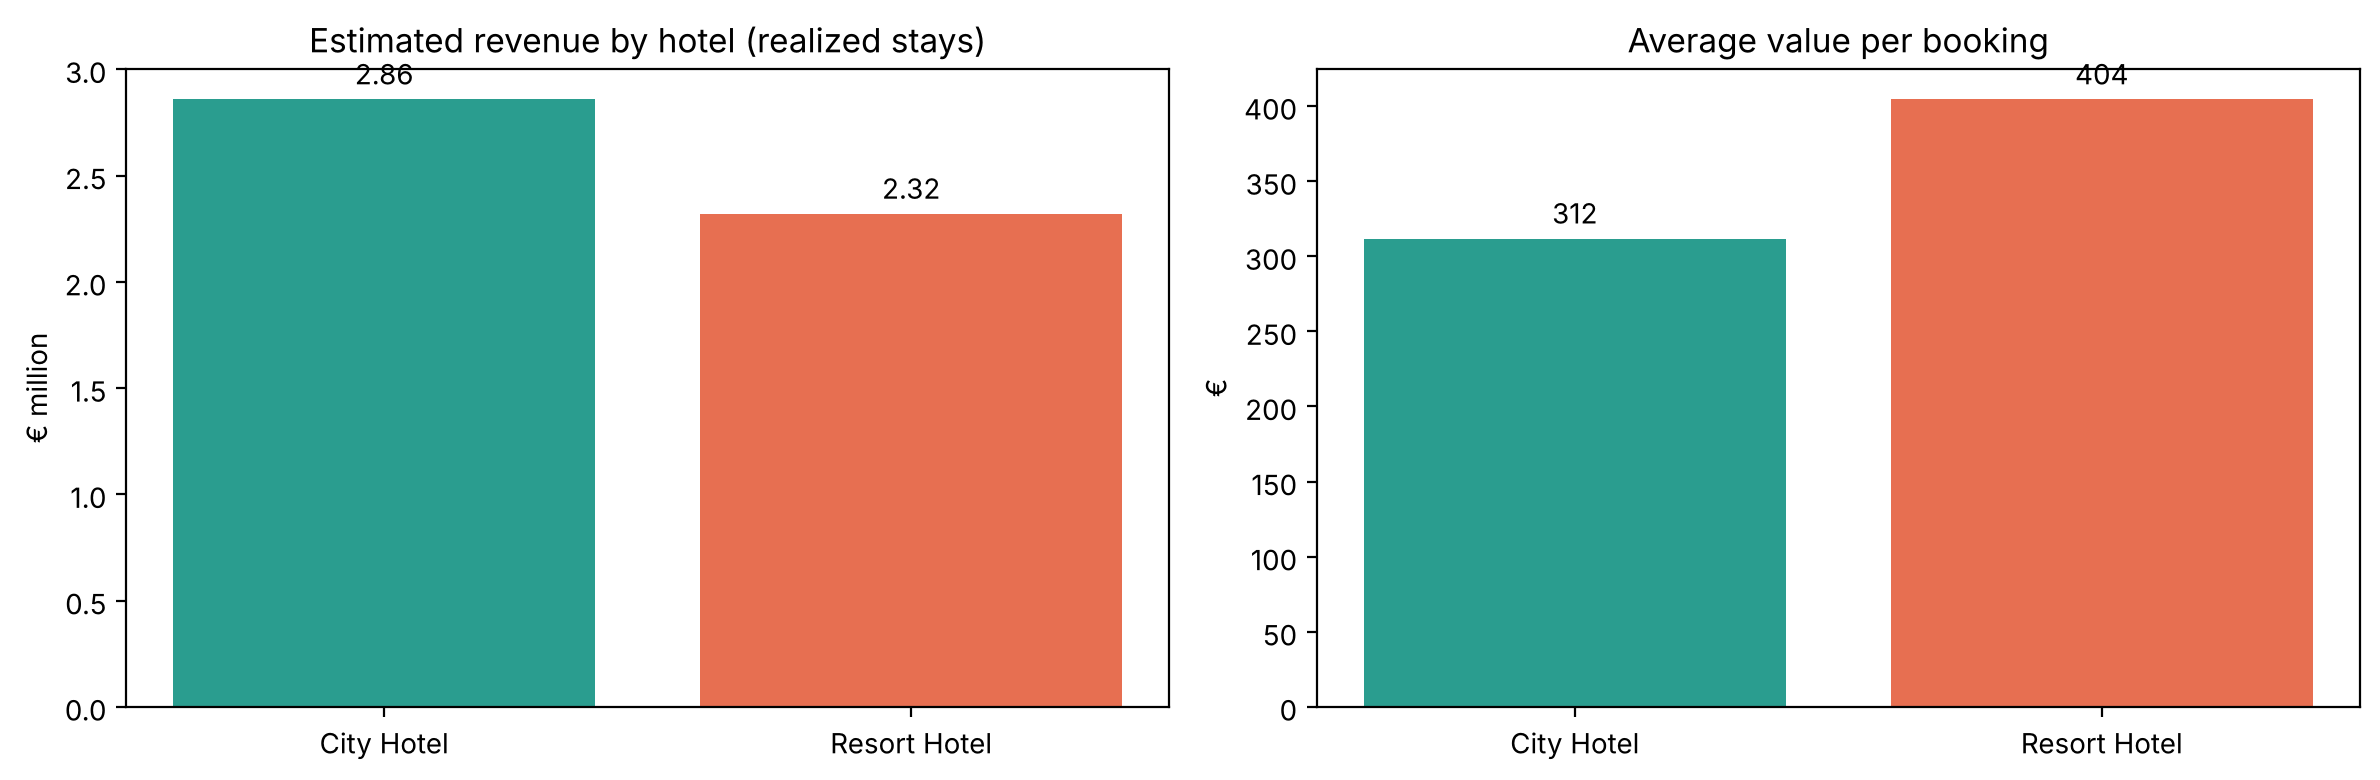

In [242]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
hotels = revenue_by_hotel.index
colors = [HOTEL_COLORS[h] for h in hotels]

ax[0].bar(hotels, revenue_by_hotel["estimated_revenue"] / 1e6, color=colors)
ax[0].set_title("Estimated revenue by hotel (realized stays)")
ax[0].set_ylabel("€ million")

ax[1].bar(hotels, revenue_by_hotel["avg_booking_value"], color=colors)
ax[1].set_title("Average value per booking")
ax[1].set_ylabel("€")

for a in ax:
    for c in a.containers:
        a.bar_label(c, fmt="%.2f" if a is ax[0] else "%.0f", padding=3)
plt.tight_layout()
plt.show()

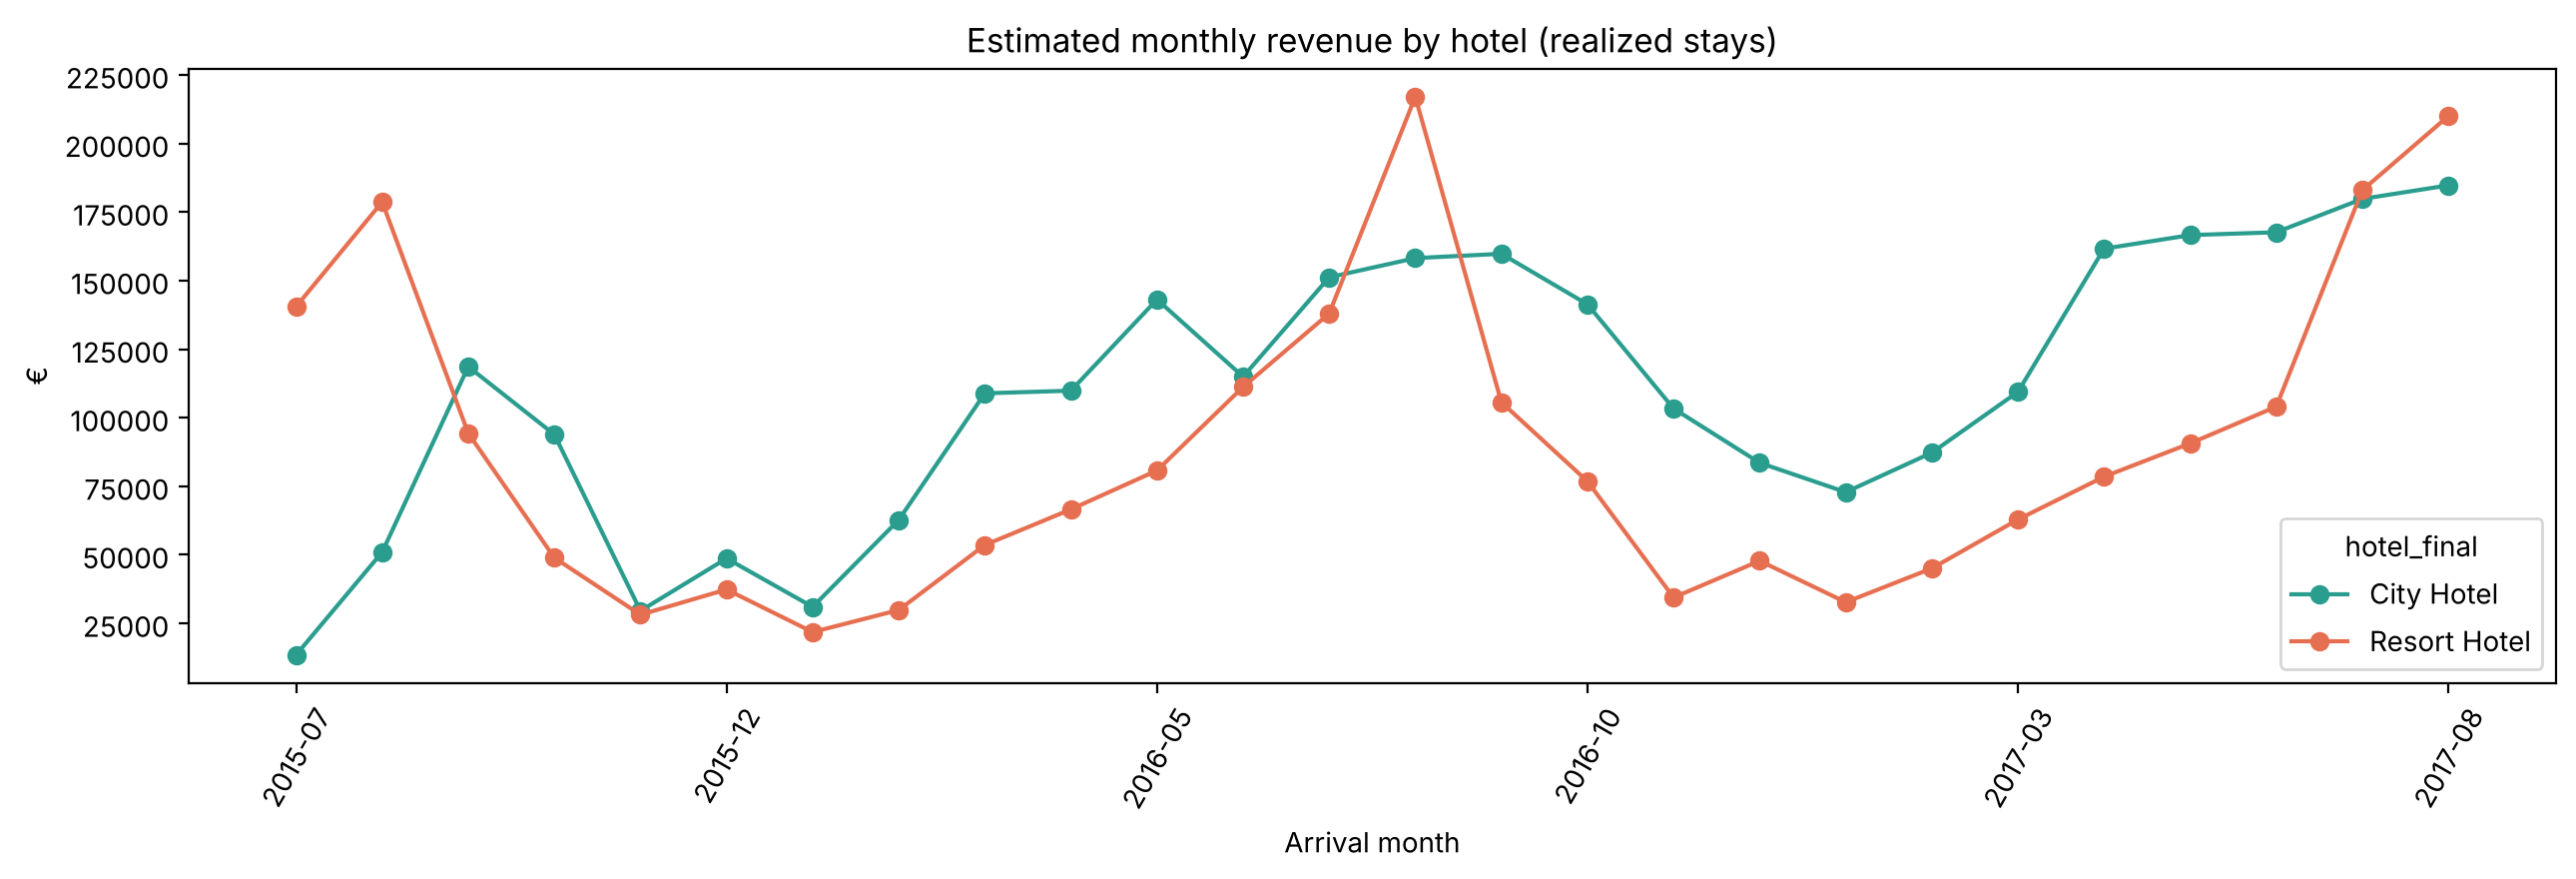

In [243]:
# monthly revenue over the whole period, by hotel
monthly_revenue = (realized.groupby(["arrival_year_month", "hotel_final"])["estimated_booking_value"]
                   .sum().unstack())

ax = monthly_revenue.plot(figsize=(13, 4.5), marker="o", color=HOTEL_COLORS)
ax.set_title("Estimated monthly revenue by hotel (realized stays)")
ax.set_xlabel("Arrival month")
ax.set_ylabel("€")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [244]:
# best months, using 2016 because it is the only complete year
revenue_2016 = (realized[realized["arrival_year"] == 2016]
                .groupby("arrival_month")["estimated_booking_value"].sum())
revenue_2016.index = MONTHS
revenue_2016.sort_values(ascending=False).head(3)

Aug   375,192.50
Jul   289,184.27
Sep   265,387.06
Name: estimated_booking_value, dtype: float64

In [245]:
revenue_by_segment = realized.groupby("market_segment").agg(
    realized_bookings=("booking_id", "count"),
    estimated_revenue=("estimated_booking_value", "sum"),
    avg_booking_value=("estimated_booking_value", "mean"),
).sort_values("estimated_revenue", ascending=False)
revenue_by_segment["revenue_share_%"] = (revenue_by_segment["estimated_revenue"]
                                         / revenue_by_segment["estimated_revenue"].sum() * 100)
revenue_by_segment

,realized_bookings,estimated_revenue,avg_booking_value,revenue_share_%
market_segment,,,,
Online TA,7351,"2,665,236.94",380.37,52.54
Offline TA/TO,3221,"1,106,920.74",359.39,21.82
Direct,2137,"805,791.36",401.89,15.89
Groups,1569,"360,814.79",238.95,7.11
Corporate,886,"117,394.14",139.92,2.31
Aviation,36,"14,198.00",417.59,0.28
Complementary,126,"2,119.55",17.52,0.04


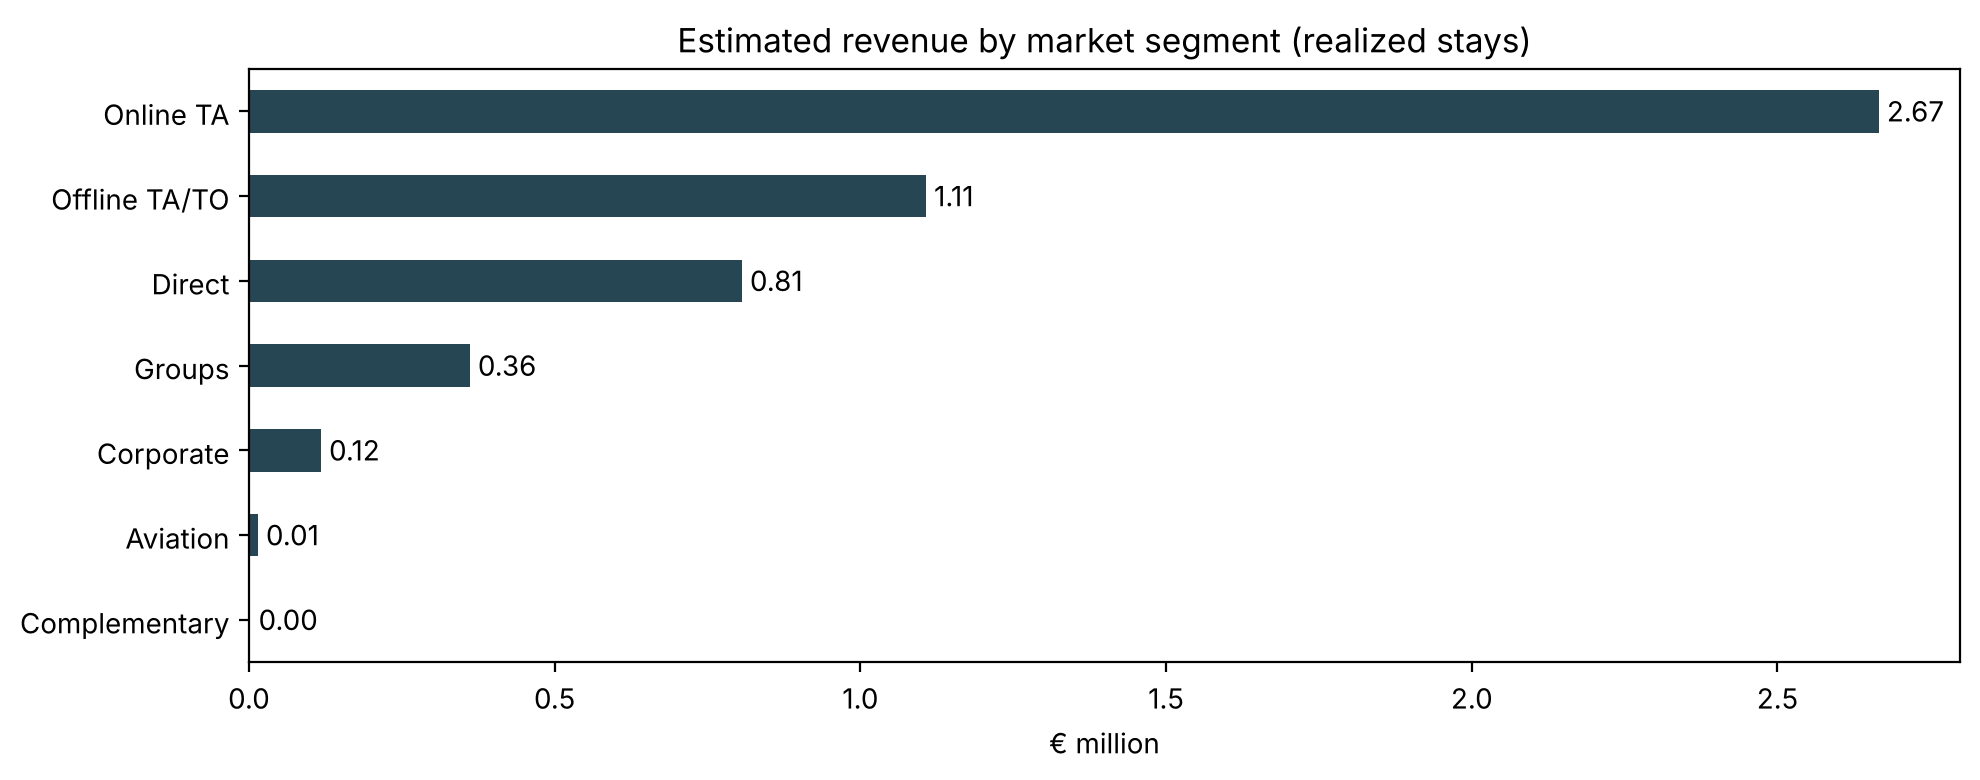

In [246]:
ax = (revenue_by_segment["estimated_revenue"] / 1e6).sort_values().plot(
    kind="barh", figsize=(10, 4), color="#264653")
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.set_title("Estimated revenue by market segment (realized stays)")
ax.set_xlabel("€ million")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**What the numbers say.** The stays that actually happened are worth about **€5.2 million**.
If every booking had turned into a stay, the value would have been around €8.6 million, so
only about 60% of what was booked turned into revenue. This alone tells us that cancellations
are a big topic (section 7).

The City Hotel earns more in total (about €2.9M against €2.3M), but only because it has more
bookings. If we look at a single booking, the Resort is worth more: around €400 against €310.
This is exactly the "volume vs value" difference: the City Hotel lives on many short stays,
the Resort on fewer but longer and more expensive ones.

Over time, the Resort revenue has very strong peaks every summer (July and August), while the
City Hotel curve is smoother and grows steadily from 2016 to 2017. By segment, Online travel
agencies are by far the main source of revenue (about half of the total), followed by Offline
agencies and Direct bookings. Direct bookings are interesting: fewer in number, but with one of
the highest values per booking.

**Why it matters.** The two hotels make money in different ways, so they shouldn't be managed
with the same targets. For the City Hotel volume and occupancy are key; for the Resort it's the
value of each stay and the summer season.

**Limitations.** This is an estimate based on ADR × nights, not the real accounting revenue
(no extras, taxes or discounts). Bookings without an ADR (for example those found only in the
CRM) are not included.

## 4. Pricing Analysis

**Objective.** Understand how the price per night (ADR) changes between hotels, months and
types of customer.

**Questions.** What is the average ADR? Which hotel is more expensive? In which months are
prices higher? Which segments pay more? Are the price distributions of the two hotels
different?

We calculate ADR on realized stays only and leave out bookings with ADR = 0, which are mostly
free stays (complementary) and would pull the average down without saying anything about prices.

In [247]:
priced = realized[realized["adr"] > 0]

print(f"Average ADR: €{priced['adr'].mean():.2f}")
print(f"Median ADR:  €{priced['adr'].median():.2f}")
print("Stays used:", len(priced), "| excluded with ADR = 0:", (realized["adr"] == 0).sum())

adr_by_hotel = priced.groupby("hotel_final")["adr"].agg(["mean", "median", "std", "min", "max"])
adr_by_hotel

Average ADR: €101.94
Median ADR:  €94.11
Stays used: 14722 | excluded with ADR = 0: 345


,mean,median,std,min,max
hotel_final,,,,,
City Hotel,108.16,100.30,37.25,1.00,345.00
Resort Hotel,92.08,72.80,56.96,1.56,387.00


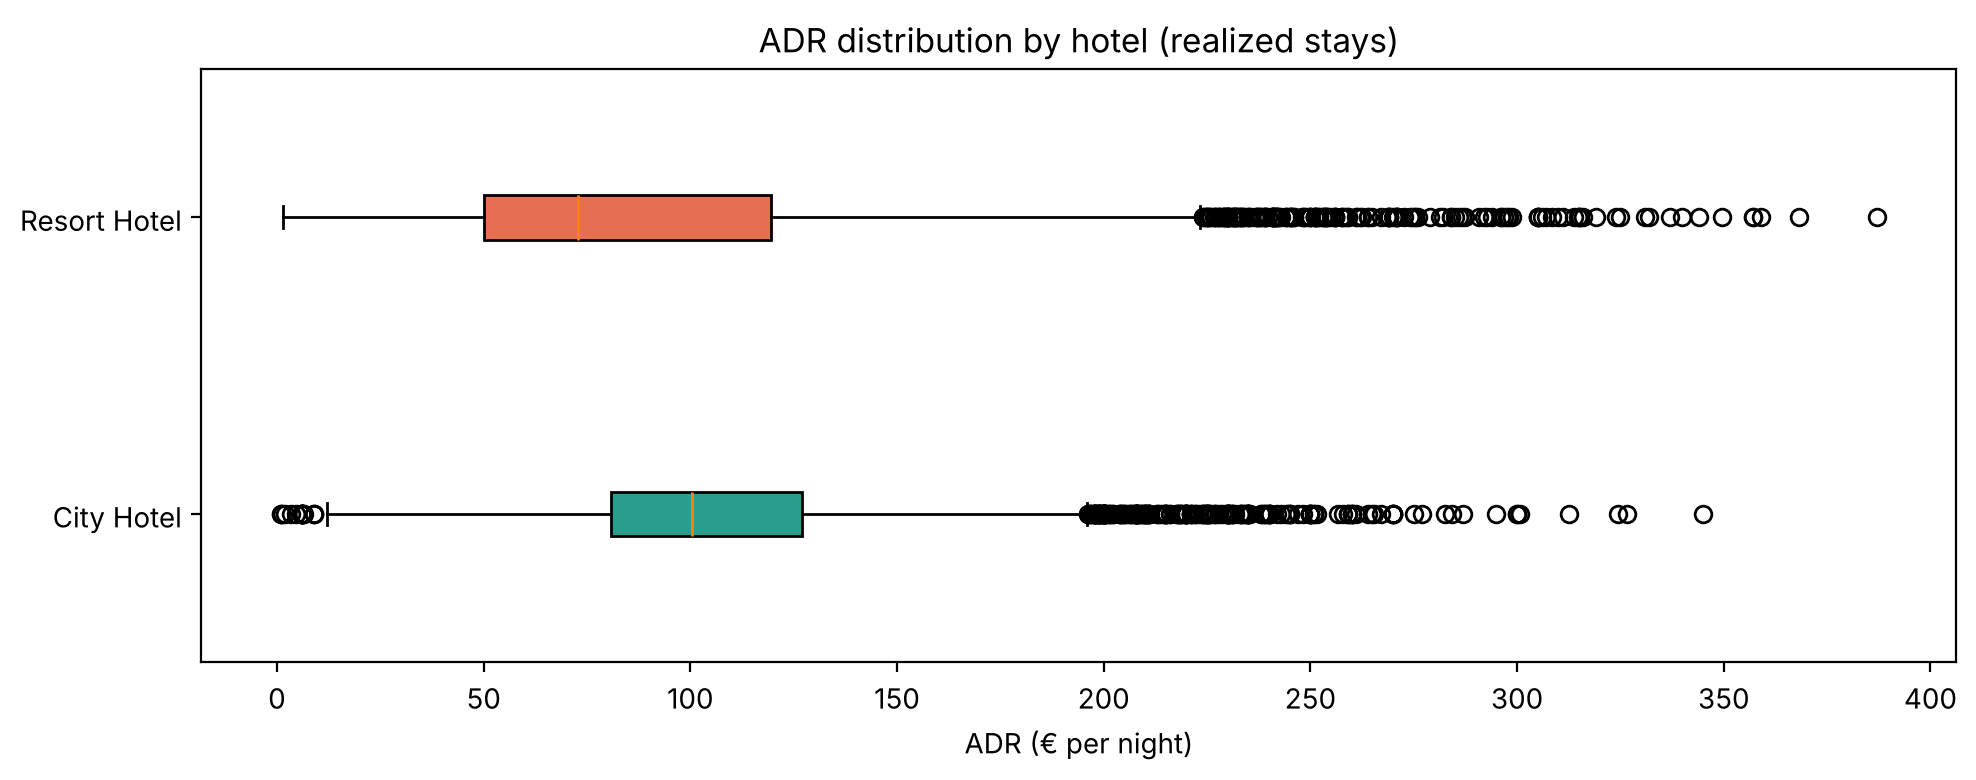

In [248]:
fig, ax = plt.subplots(figsize=(10, 4))
data = [priced.loc[priced["hotel_final"] == h, "adr"] for h in HOTEL_COLORS]
box = ax.boxplot(data, orientation="horizontal", tick_labels=list(HOTEL_COLORS), patch_artist=True)
for patch, color in zip(box["boxes"], HOTEL_COLORS.values()):
    patch.set_facecolor(color)
ax.set_title("ADR distribution by hotel (realized stays)")
ax.set_xlabel("ADR (€ per night)")
plt.tight_layout()
plt.show()

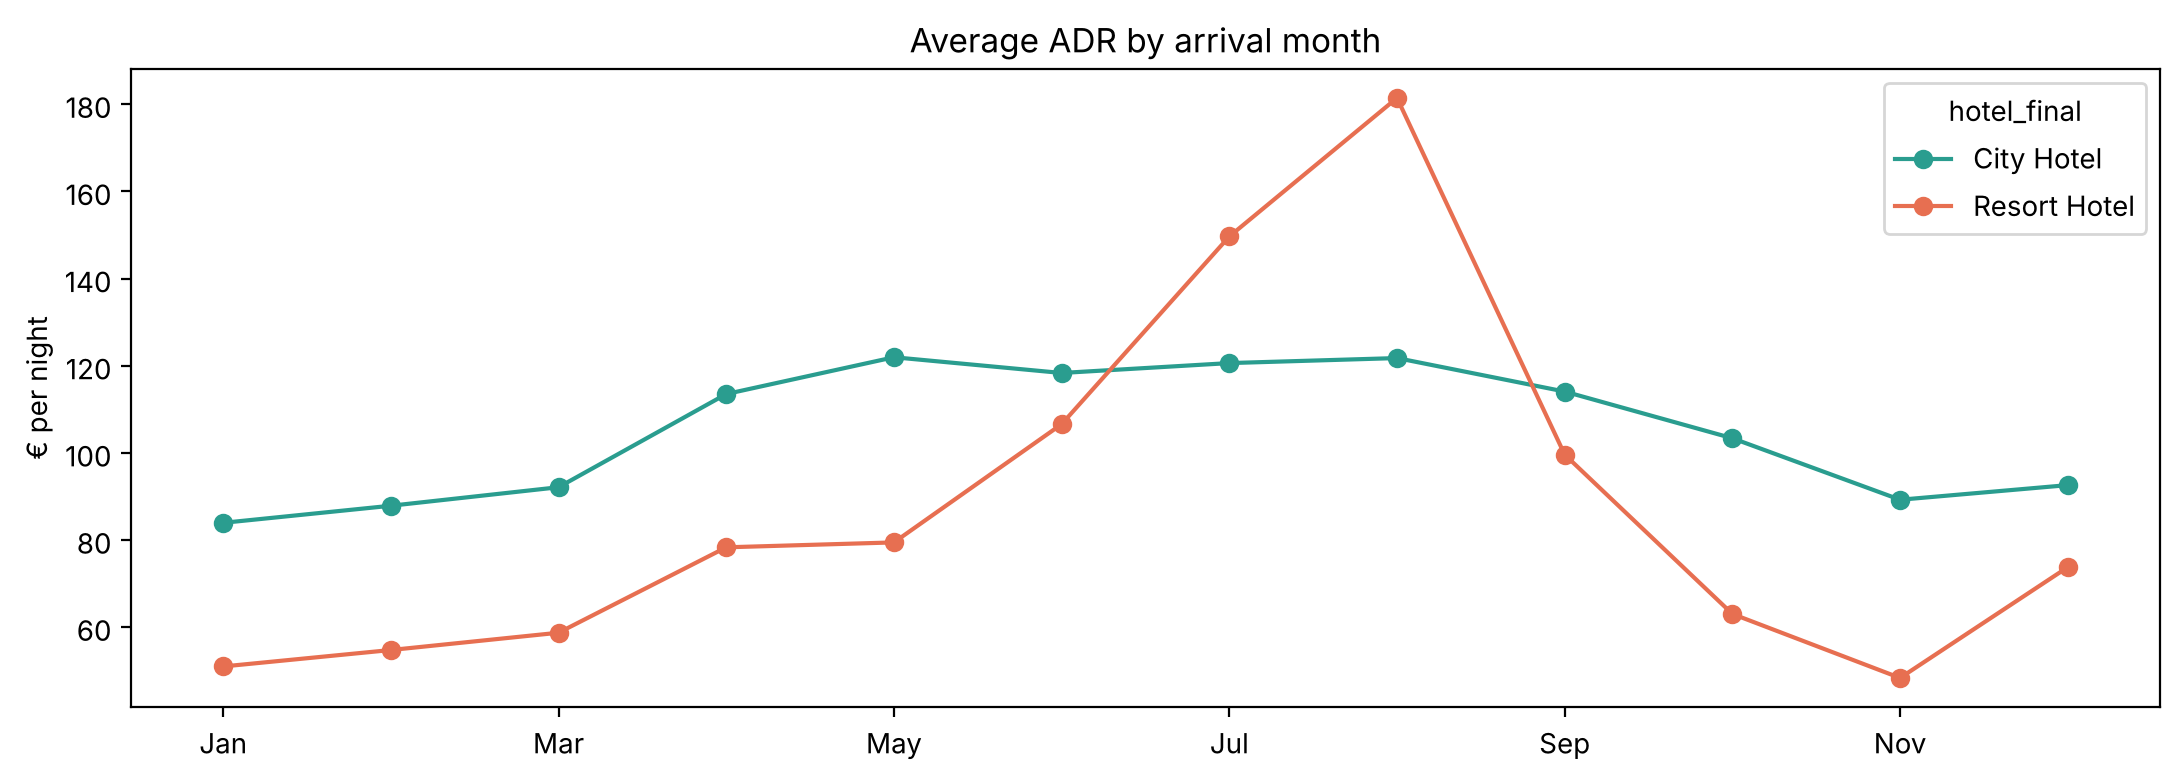

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
hotel_final,,,,,,,,,,,,
City Hotel,84.00,88.00,92.00,114.00,122.00,118.00,121.00,122.00,114.00,103.00,89.00,93.00
Resort Hotel,51.00,55.00,59.00,78.00,79.00,107.00,150.00,181.00,100.00,63.00,48.00,74.00


In [249]:
adr_by_month = priced.groupby(["arrival_month", "hotel_final"])["adr"].mean().unstack()
adr_by_month.index = MONTHS

ax = adr_by_month.plot(figsize=(11, 4), marker="o", color=HOTEL_COLORS)
ax.set_title("Average ADR by arrival month")
ax.set_ylabel("€ per night")
ax.set_xlabel("")
plt.tight_layout()
plt.show()
adr_by_month.round(0).T

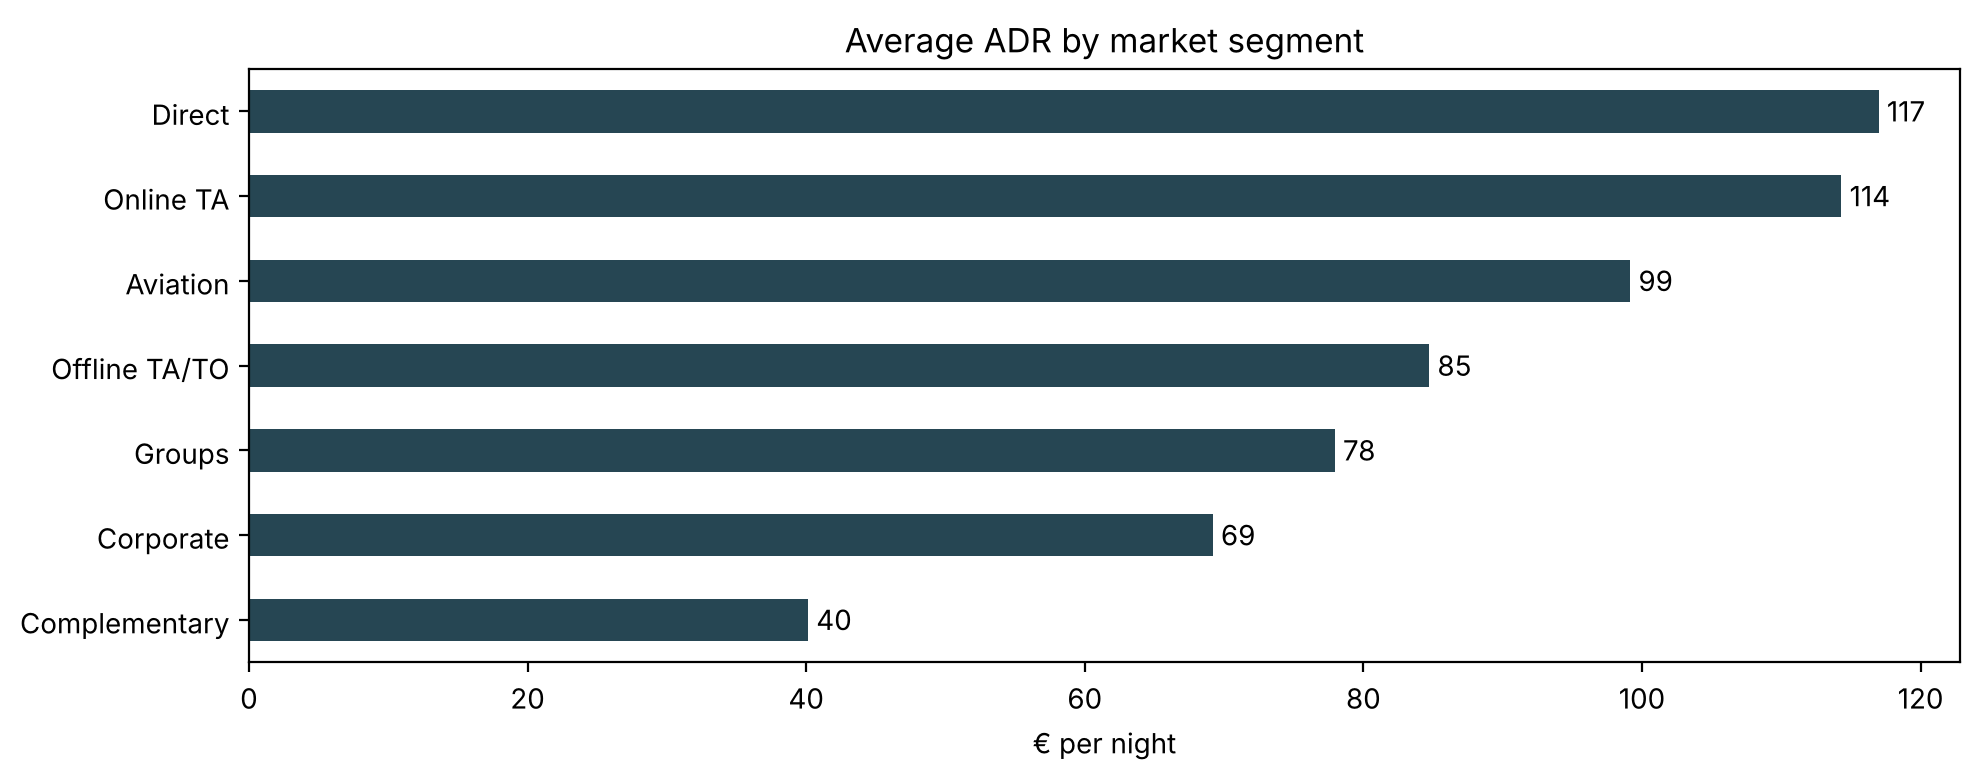

In [250]:
adr_by_segment = priced.groupby("market_segment")["adr"].agg(["mean", "median", "count"]).sort_values("mean")

ax = adr_by_segment["mean"].plot(kind="barh", figsize=(10, 4), color="#264653")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_title("Average ADR by market segment")
ax.set_xlabel("€ per night")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**What the numbers say.** On average a room night costs a bit more than €100. The City Hotel is
more expensive in a "normal" month, while the Resort has a much wider range of prices.

The monthly chart is probably the most interesting one of this section. The City Hotel price
is quite flat, roughly between €85 in winter and €120 in spring and summer. The Resort, instead,
goes from around €50 in January and November up to about €180 in August, more than three
times as much. The Resort is only more expensive than the City Hotel in July and August.

Direct and Online TA customers pay the highest prices per night (around €115), while groups,
corporate clients and offline agencies get lower rates, which makes sense since they usually
negotiate prices or book in bulk.

**Why it matters.** The Resort is already using seasonal pricing quite aggressively. The City
Hotel price barely changes during the year even though demand does (section 8), so there could
be room for more dynamic pricing in its busiest months.

**Limitations.** We don't know room categories well (codes are anonymised) and we don't know
competitors' prices, so we can't say whether a price is "too low" or "too high", only how it
changes.

## 5. Customer Analysis

**Objective.** Understand who the guests are and what they look like.

**Questions.** Where do guests come from? Which countries bring the most value? How many guests
are there per booking and how long do they stay? Are City Hotel guests different from Resort
guests? Which markets look most promising?

Without a customer ID we can't tell if the same person booked twice, so we always talk about
bookings and not about customers.

In [251]:
bookings_by_country = valid["guest_country"].value_counts()
top10 = bookings_by_country.head(10)

country_table = pd.DataFrame({
    "bookings": top10,
    "booking_share_%": top10 / bookings_by_country.sum() * 100,
    "realized_value": realized.groupby("guest_country")["estimated_booking_value"].sum().reindex(top10.index),
})
country_table["value_share_%"] = country_table["realized_value"] / total_revenue * 100
country_table["cancellation_rate_%"] = valid.groupby("guest_country")["booking_not_realized_final"].mean().reindex(top10.index) * 100
country_table

,bookings,booking_share_%,realized_value,value_share_%,cancellation_rate_%
guest_country,,,,,
PRT,9906,40.71,"1,075,787.51",20.77,56.47
GBR,2556,10.50,"812,001.31",15.68,21.71
FRA,2186,8.98,"610,000.34",11.78,18.85
ESP,1732,7.12,"430,386.90",8.31,25.92
DEU,1471,6.04,"398,866.58",7.70,18.22
ITA,741,3.04,"175,261.87",3.38,33.20
IRL,706,2.90,"254,101.66",4.91,23.51
BEL,462,1.90,"133,083.99",2.57,24.46
BRA,442,1.82,"94,408.20",1.82,35.29


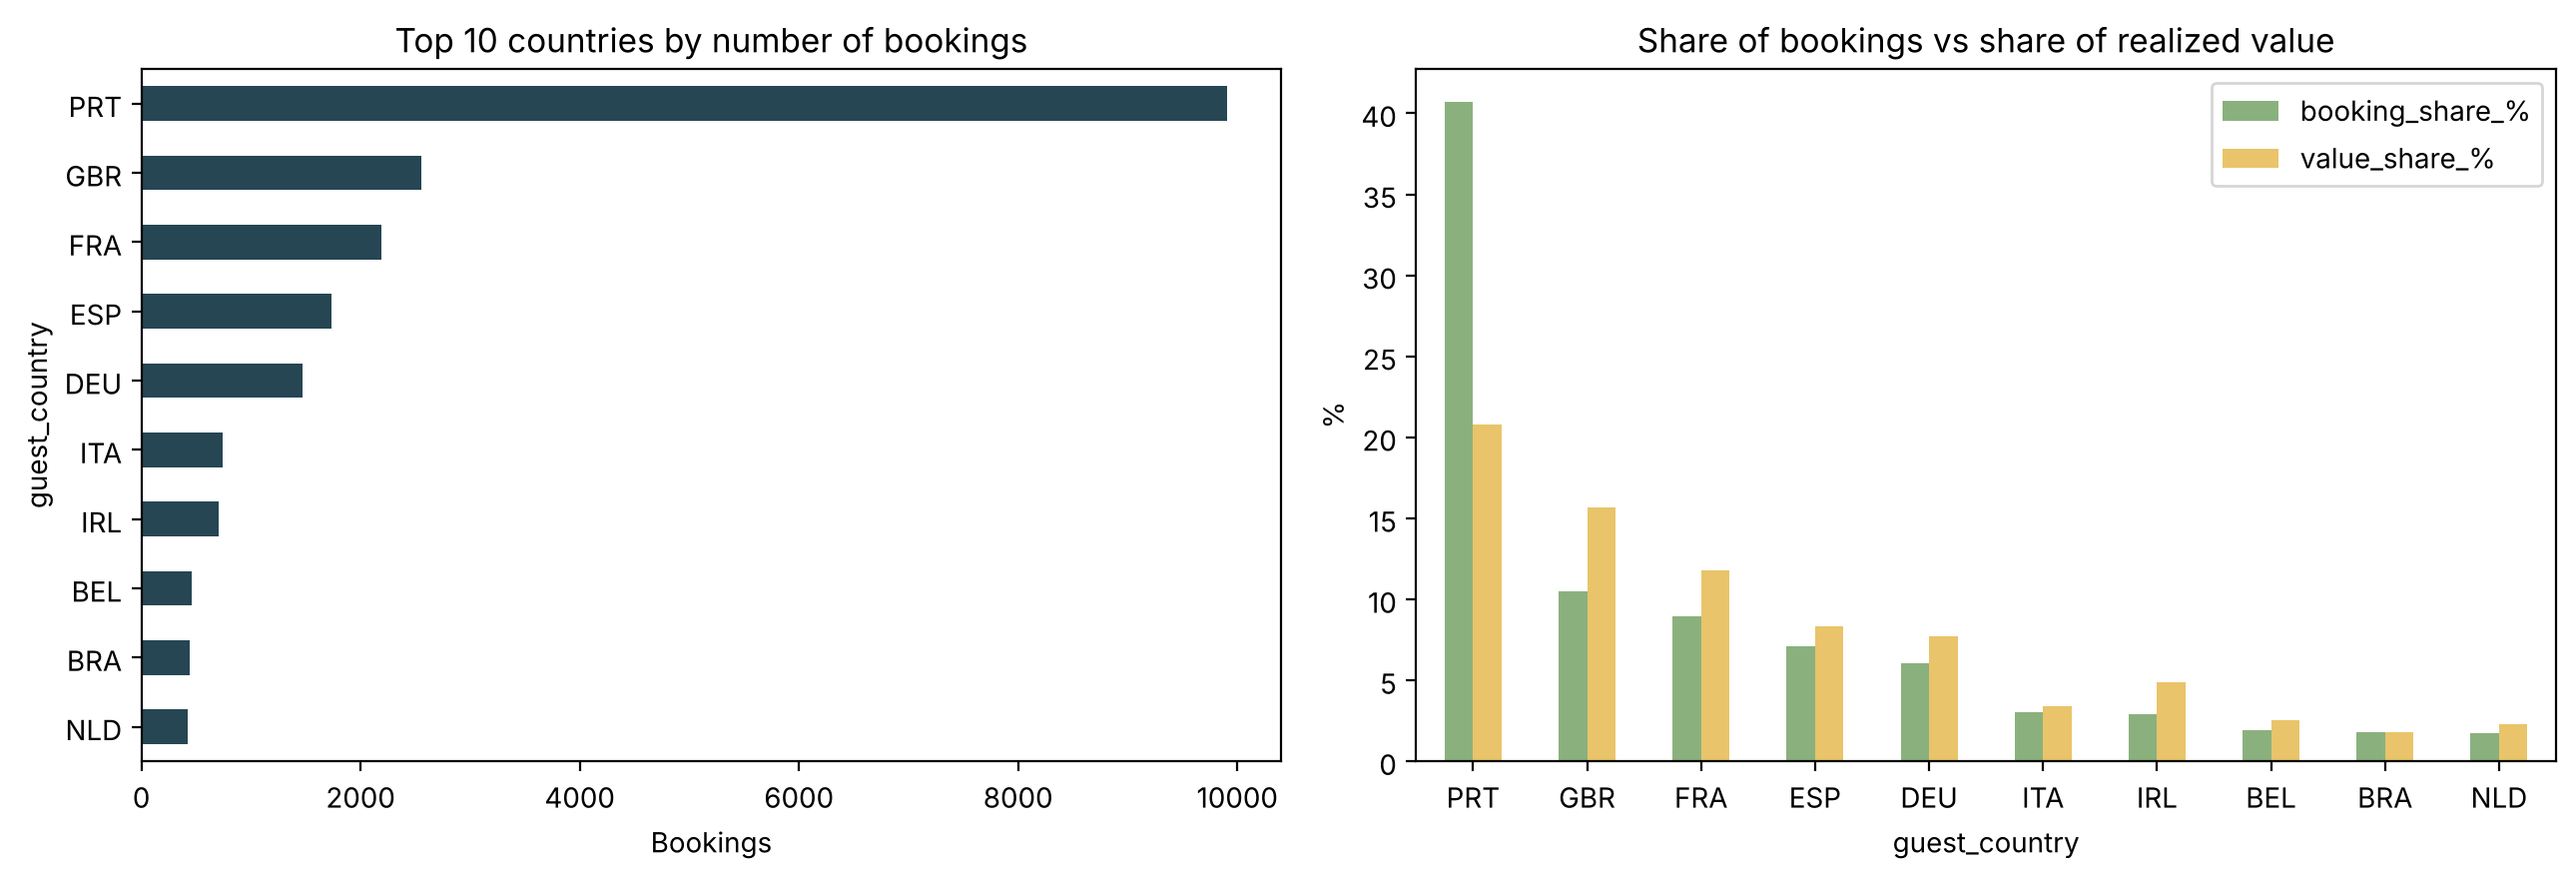

In [252]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
top10.sort_values().plot(kind="barh", ax=ax[0], color="#264653")
ax[0].set_title("Top 10 countries by number of bookings")
ax[0].set_xlabel("Bookings")

country_table[["booking_share_%", "value_share_%"]].plot(kind="bar", ax=ax[1],
                                                         color=["#8AB17D", "#E9C46A"], rot=0)
ax[1].set_title("Share of bookings vs share of realized value")
ax[1].set_ylabel("%")
plt.tight_layout()
plt.show()

In [253]:
customer_profile = realized.groupby("hotel_final").agg(
    avg_guests=("total_guests", "mean"),
    avg_adults=("adults_final", "mean"),
    avg_nights=("total_nights", "mean"),
    repeat_guest_share=("is_repeated_guest", "mean"),
)
customer_profile["portuguese_share"] = valid.assign(prt=valid["guest_country"] == "PRT").groupby("hotel_final")["prt"].mean()
customer_profile["with_children_share"] = realized.assign(kids=realized["children"].fillna(0) + realized["babies"].fillna(0) > 0).groupby("hotel_final")["kids"].mean()
customer_profile

,avg_guests,avg_adults,avg_nights,repeat_guest_share,portuguese_share,with_children_share
hotel_final,,,,,,
City Hotel,1.93,1.83,2.90,0.03,0.38,0.07
Resort Hotel,1.95,1.83,4.15,0.06,0.43,0.08


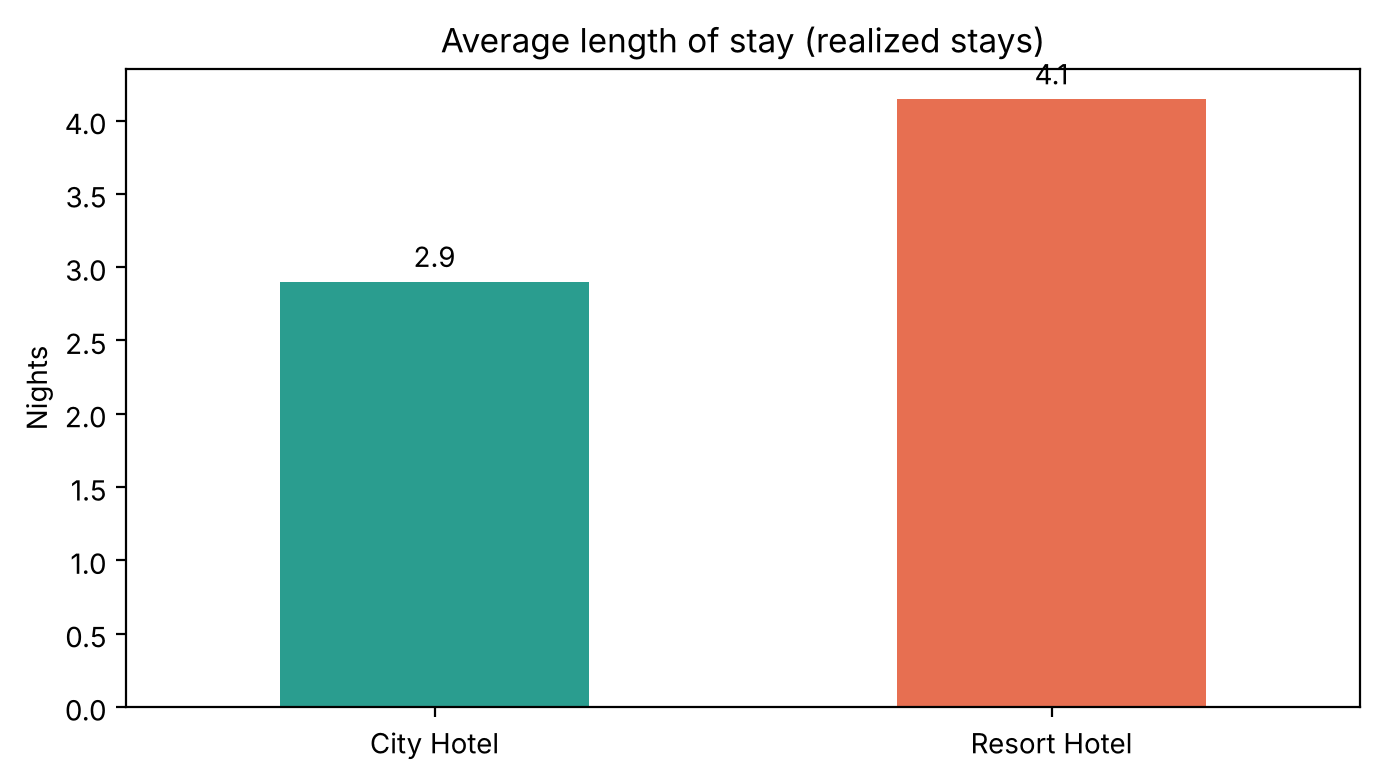

In [254]:
ax = customer_profile["avg_nights"].plot(kind="bar", figsize=(7, 4), rot=0,
                                         color=[HOTEL_COLORS[h] for h in customer_profile.index])
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.set_title("Average length of stay (realized stays)")
ax.set_ylabel("Nights")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

**What the numbers say.** Portugal is by far the first country, with about 40% of all bookings,
followed by the UK, France, Spain and Germany. But the chart on the right shows something
important: Portugal brings around 40% of the bookings and only about 21% of the realized value.
The reason is in the last column of the table: more than half of the Portuguese bookings are
canceled. Foreign markets like the UK, France and Germany are the opposite: their share of value
is higher than their share of bookings and they cancel much less (around 18-22%).

A typical booking is for about two people. The real difference between the two hotels is the
length of the stay: about 4.1 nights at the Resort against 2.9 at the City Hotel. Resort
bookings are also a bit more often families with children. Returning guests are a small
minority in both hotels.

**Why it matters.** The UK, France, Germany and Spain look like the most valuable foreign
markets: they book, they show up and they stay. Portugal is still the biggest market, but in
terms of volume more than value.

**Limitations.** Country is missing for some bookings and "CN" could not be confirmed as China.
We count bookings, not people, so a guest who booked many times counts many times.

## 6. Market Segmentation Analysis

**Objective.** Understand which commercial segments matter most for the hotels.

**Questions.** Which segment brings most bookings and most value? Which has the highest ADR,
the longest stays and the most cancellations? Do the two hotels depend on the same segments?

In [255]:
main_segments = ["Online TA", "Offline TA/TO", "Groups", "Direct", "Corporate"]

segment_table = pd.DataFrame({
    "bookings": valid["market_segment"].value_counts(),
    "estimated_revenue": realized.groupby("market_segment")["estimated_booking_value"].sum(),
    "avg_adr": priced.groupby("market_segment")["adr"].mean(),
    "avg_nights": realized.groupby("market_segment")["total_nights"].mean(),
    "cancellation_rate_%": valid.groupby("market_segment")["booking_not_realized_final"].mean() * 100,
})
segment_table["booking_share_%"] = segment_table["bookings"] / segment_table["bookings"].sum() * 100
segment_table = segment_table.sort_values("bookings", ascending=False)
segment_table

,bookings,estimated_revenue,avg_adr,avg_nights,cancellation_rate_%,booking_share_%
market_segment,,,,,,
Online TA,11709,"2,665,236.94",114.31,3.26,37.22,47.89
Offline TA/TO,4900,"1,106,920.74",84.72,4.29,34.27,20.04
Groups,4067,"360,814.79",77.93,3.21,61.42,16.63
Direct,2497,"805,791.36",116.98,3.17,14.42,10.21
Corporate,1086,"117,394.14",69.18,2.04,18.42,4.44
Complementary,142,"2,119.55",40.13,1.80,11.27,0.58
Aviation,47,"14,198.00",99.15,3.94,23.40,0.19
Undefined,2,NaN,NaN,NaN,100.00,0.01


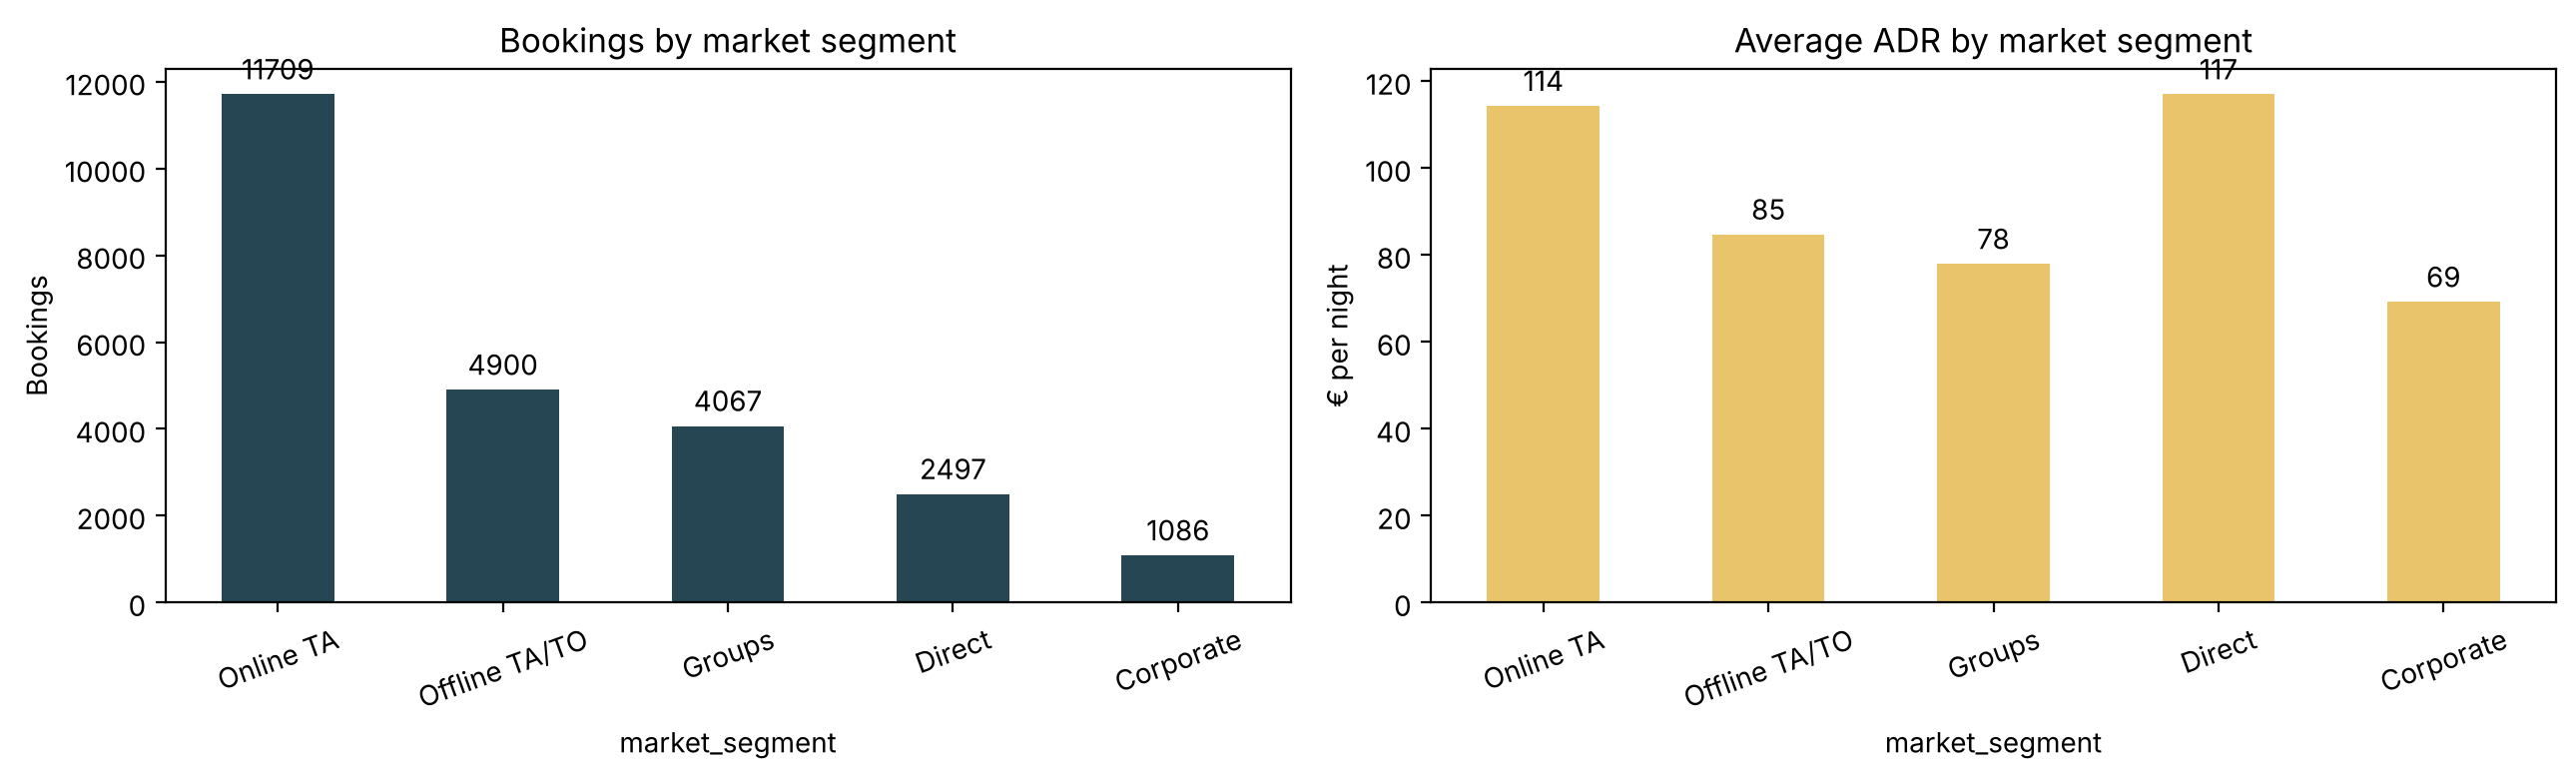

In [256]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
segment_table.loc[main_segments, "bookings"].plot(kind="bar", ax=ax[0], color="#264653", rot=20)
ax[0].set_title("Bookings by market segment")
ax[0].set_ylabel("Bookings")

segment_table.loc[main_segments, "avg_adr"].plot(kind="bar", ax=ax[1], color="#E9C46A", rot=20)
ax[1].set_title("Average ADR by market segment")
ax[1].set_ylabel("€ per night")
for a in ax:
    a.bar_label(a.containers[0], fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()

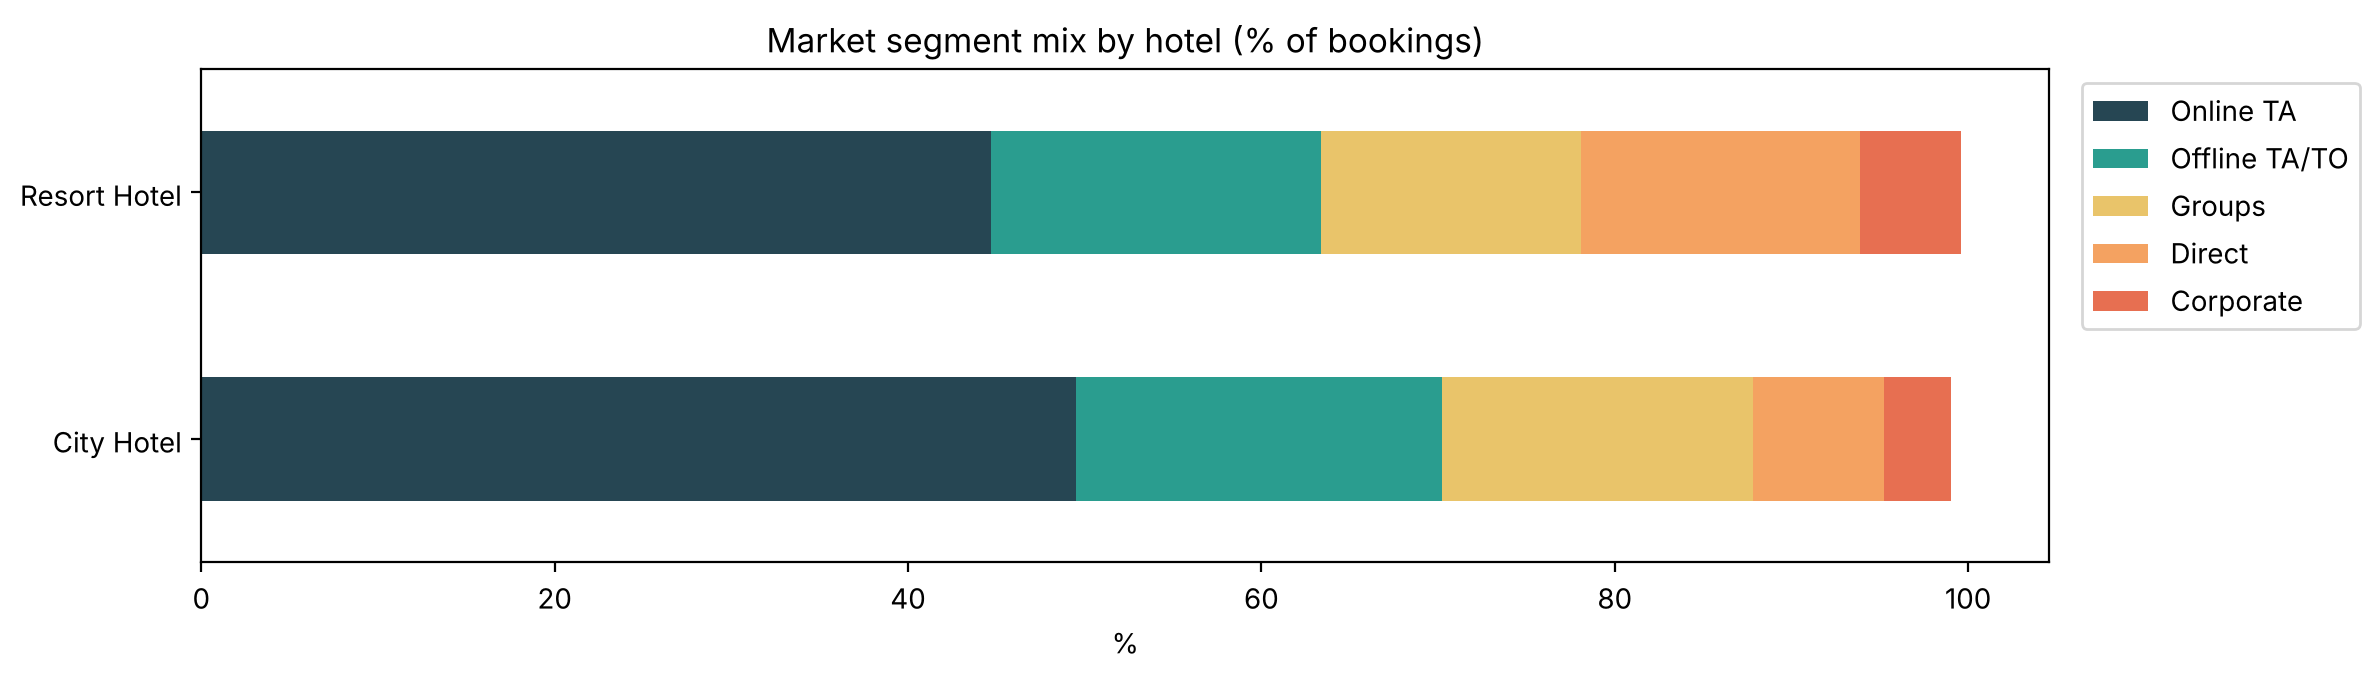

market_segment,Online TA,Offline TA/TO,Groups,Direct,Corporate
hotel_final,,,,,
City Hotel,49.50,20.70,17.60,7.40,3.80
Resort Hotel,44.70,18.70,14.70,15.80,5.70


In [257]:
segment_mix = pd.crosstab(valid["hotel_final"], valid["market_segment"], normalize="index")[main_segments] * 100

ax = segment_mix.plot(kind="barh", stacked=True, figsize=(12, 3.5),
                      color=["#264653", "#2A9D8F", "#E9C46A", "#F4A261", "#E76F51"])
ax.set_title("Market segment mix by hotel (% of bookings)")
ax.set_xlabel("%")
ax.set_ylabel("")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()
segment_mix.round(1)

**What the numbers say.** Online travel agencies (Booking.com, Expedia and similar) are almost
half of all bookings and about half of the revenue. Groups are the second segment by volume,
but they are the worst for the hotels in many ways: low ADR, low value per booking and above
all a cancellation rate above 60%.

Direct bookings are only about 10% of the volume, but they combine the highest ADR with the
lowest cancellation rate of the main segments (around 14%). Corporate clients cancel little too,
but they pay less and stay shorter.

Both hotels depend heavily on online agencies (about half of their bookings). The City Hotel
relies a bit more on groups, while the Resort gets twice as many direct bookings in proportion
(about 16% against 7%).

**Why it matters.** Moving even a small part of the online volume to direct bookings would mean
higher prices, fewer cancellations and no agency commission.

**Limitations.** We don't know the commissions paid to agencies or the cost of acquiring each
segment, so we can compare value but not real profitability.

## 7. Booking & Cancellation Analysis

**Objective.** Measure cancellations and understand where they come from. This is probably the
most important section, because every canceled booking is a room that may stay empty.

**Questions.** What is the overall cancellation rate? Which hotel, segments and countries cancel
most? Is lead time related to cancellations? In which months do they happen? How much value is
lost?

We count canceled bookings and no-shows together (`booking_not_realized_final` = 1). The 50
bookings where PMS and CRM disagree on the outcome are left out of the denominator.

In [258]:
cancellation_kpis = pd.Series({
    "Total bookings (known outcome)": len(valid),
    "Canceled or no-show": len(canceled),
    "  of which no-show": (canceled["reservation_status"] == "No-Show").sum(),
    "Cancellation rate (%)": valid["booking_not_realized_final"].mean() * 100,
    "Value of canceled bookings (€)": canceled["estimated_booking_value"].sum(),
    "Average lead time, all bookings (days)": valid["lead_time_days"].mean(),
})
cancellation_kpis

Total bookings (known outcome)              24,950.00
Canceled or no-show                          9,304.00
  of which no-show                             256.00
Cancellation rate (%)                           37.29
Value of canceled bookings (€)           3,404,366.21
Average lead time, all bookings (days)         103.77
dtype: float64

In [259]:
cancel_by_hotel = valid.groupby("hotel_final").agg(
    bookings=("booking_id", "count"),
    canceled=("booking_not_realized_final", "sum"),
    cancellation_rate=("booking_not_realized_final", "mean"),
    lost_value=("estimated_booking_value", lambda s: s[valid.loc[s.index, "booking_not_realized_final"] == 1].sum()),
)
cancel_by_hotel["cancellation_rate"] *= 100
cancel_by_hotel

,bookings,canceled,cancellation_rate,lost_value
hotel_final,,,,
City Hotel,16592,"7,013.00",42.27,"2,240,565.25"
Resort Hotel,8358,"2,291.00",27.41,"1,163,800.96"


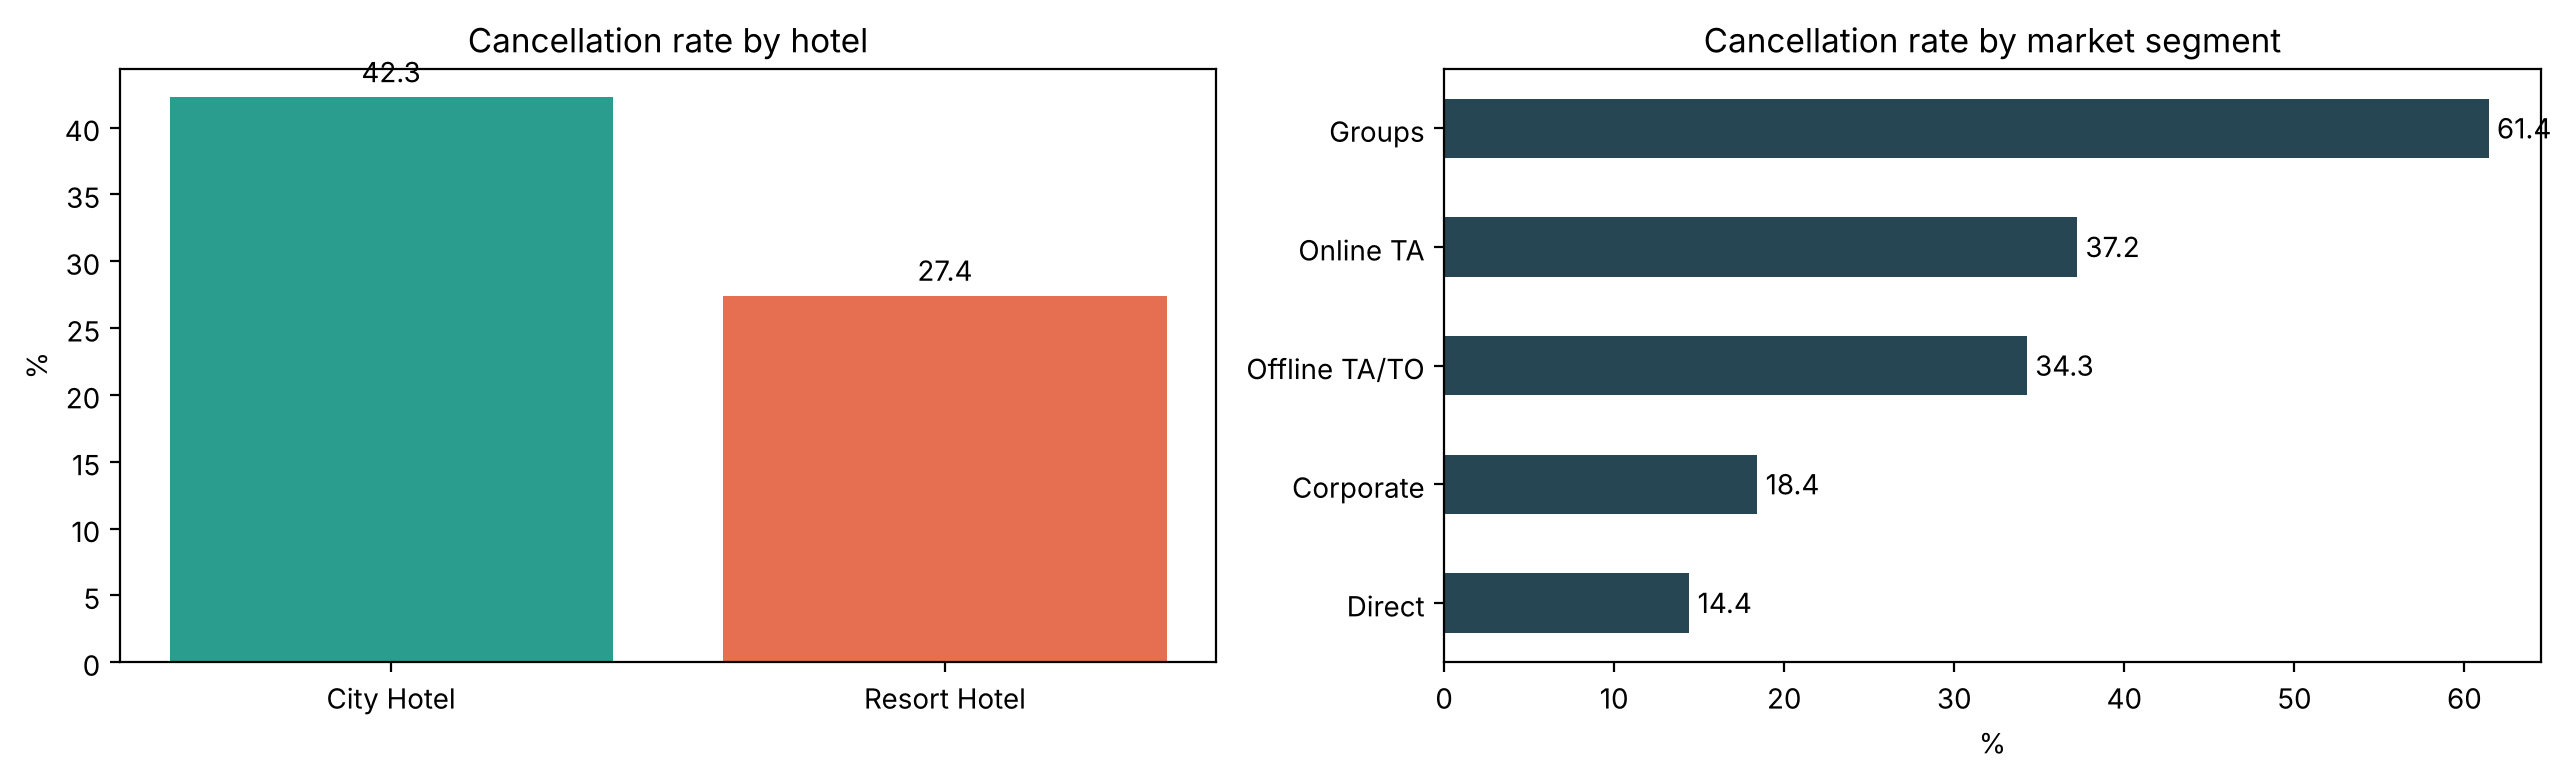

In [260]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(cancel_by_hotel.index, cancel_by_hotel["cancellation_rate"],
          color=[HOTEL_COLORS[h] for h in cancel_by_hotel.index])
ax[0].set_title("Cancellation rate by hotel")
ax[0].set_ylabel("%")

segment_table.loc[main_segments, "cancellation_rate_%"].sort_values().plot(
    kind="barh", ax=ax[1], color="#264653")
ax[1].set_title("Cancellation rate by market segment")
ax[1].set_xlabel("%")
ax[1].set_ylabel("")
for a in ax:
    a.bar_label(a.containers[0], fmt="%.1f", padding=3)
plt.tight_layout()
plt.show()

In [261]:
# countries with at least 300 bookings, so the rate is not based on a handful of cases
country_cancel = valid.groupby("guest_country")["booking_not_realized_final"].agg(["count", "mean"])
country_cancel = country_cancel[country_cancel["count"] >= 300].sort_values("mean", ascending=False)
country_cancel["mean"] *= 100
country_cancel.rename(columns={"count": "bookings", "mean": "cancellation_rate_%"})

,bookings,cancellation_rate_%
guest_country,,
PRT,9906,56.47
BRA,442,35.29
ITA,741,33.20
ESP,1732,25.92
CHE,373,25.20
BEL,462,24.46
IRL,706,23.51
USA,425,22.12
GBR,2556,21.71


In [262]:
# lead time: cancellation rate by how far in advance the booking was made
bins = [-1, 7, 30, 90, 180, 365, 800]
labels = ["0-7", "8-30", "31-90", "91-180", "181-365", "365+"]
valid["lead_time_group"] = pd.cut(valid["lead_time_days"], bins=bins, labels=labels)
lead_time_cancel = valid.groupby("lead_time_group", observed=True)["booking_not_realized_final"].agg(["count", "mean"])
lead_time_cancel["mean"] *= 100
lead_time_cancel

,count,mean
lead_time_group,,
0-7,3959,9.95
8-30,3862,27.50
31-90,6125,38.06
91-180,5491,45.35
181-365,4356,55.28
365+,632,67.72


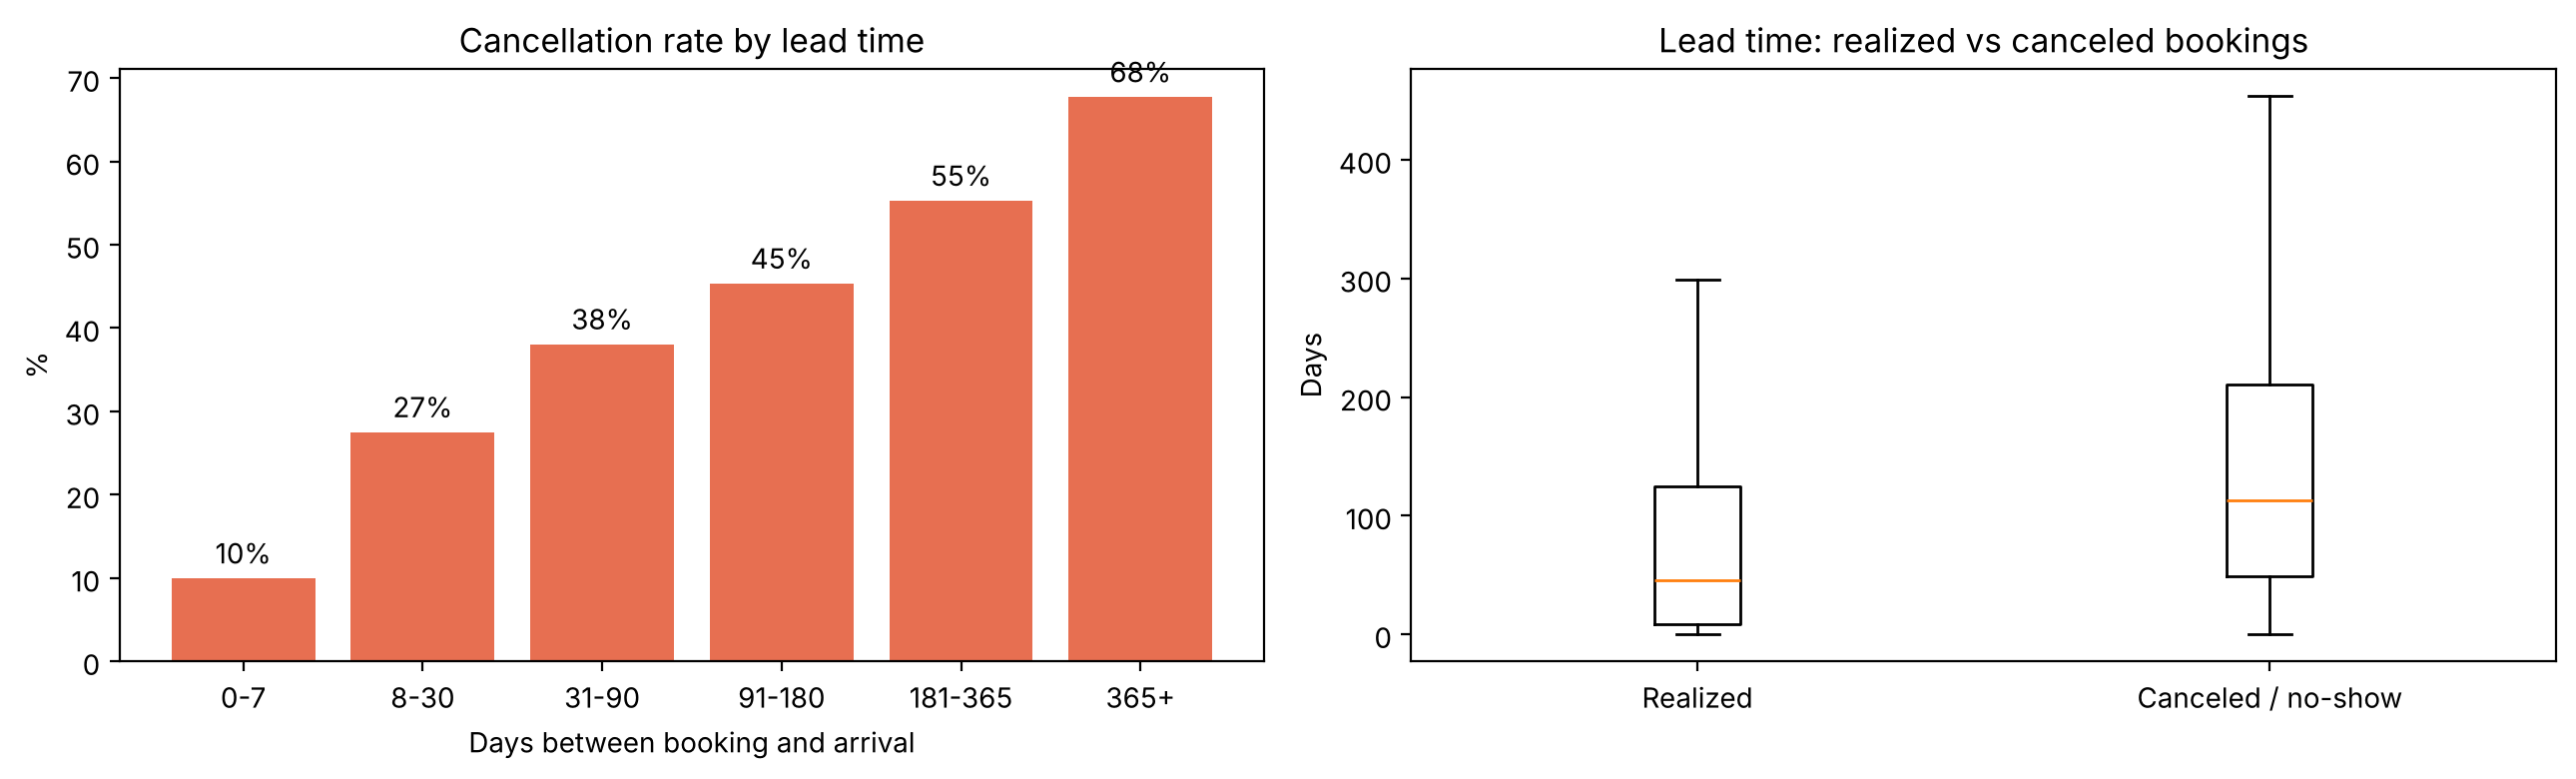

Median lead time, realized: 46.0 days
Median lead time, canceled: 113.0 days


In [263]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(lead_time_cancel.index.astype(str), lead_time_cancel["mean"], color="#E76F51")
ax[0].bar_label(ax[0].containers[0], fmt="%.0f%%", padding=3)
ax[0].set_title("Cancellation rate by lead time")
ax[0].set_xlabel("Days between booking and arrival")
ax[0].set_ylabel("%")

ax[1].boxplot([realized["lead_time_days"].dropna(), canceled["lead_time_days"].dropna()],
              tick_labels=["Realized", "Canceled / no-show"], showfliers=False)
ax[1].set_title("Lead time: realized vs canceled bookings")
ax[1].set_ylabel("Days")
plt.tight_layout()
plt.show()

print("Median lead time, realized:", realized["lead_time_days"].median(), "days")
print("Median lead time, canceled:", canceled["lead_time_days"].median(), "days")

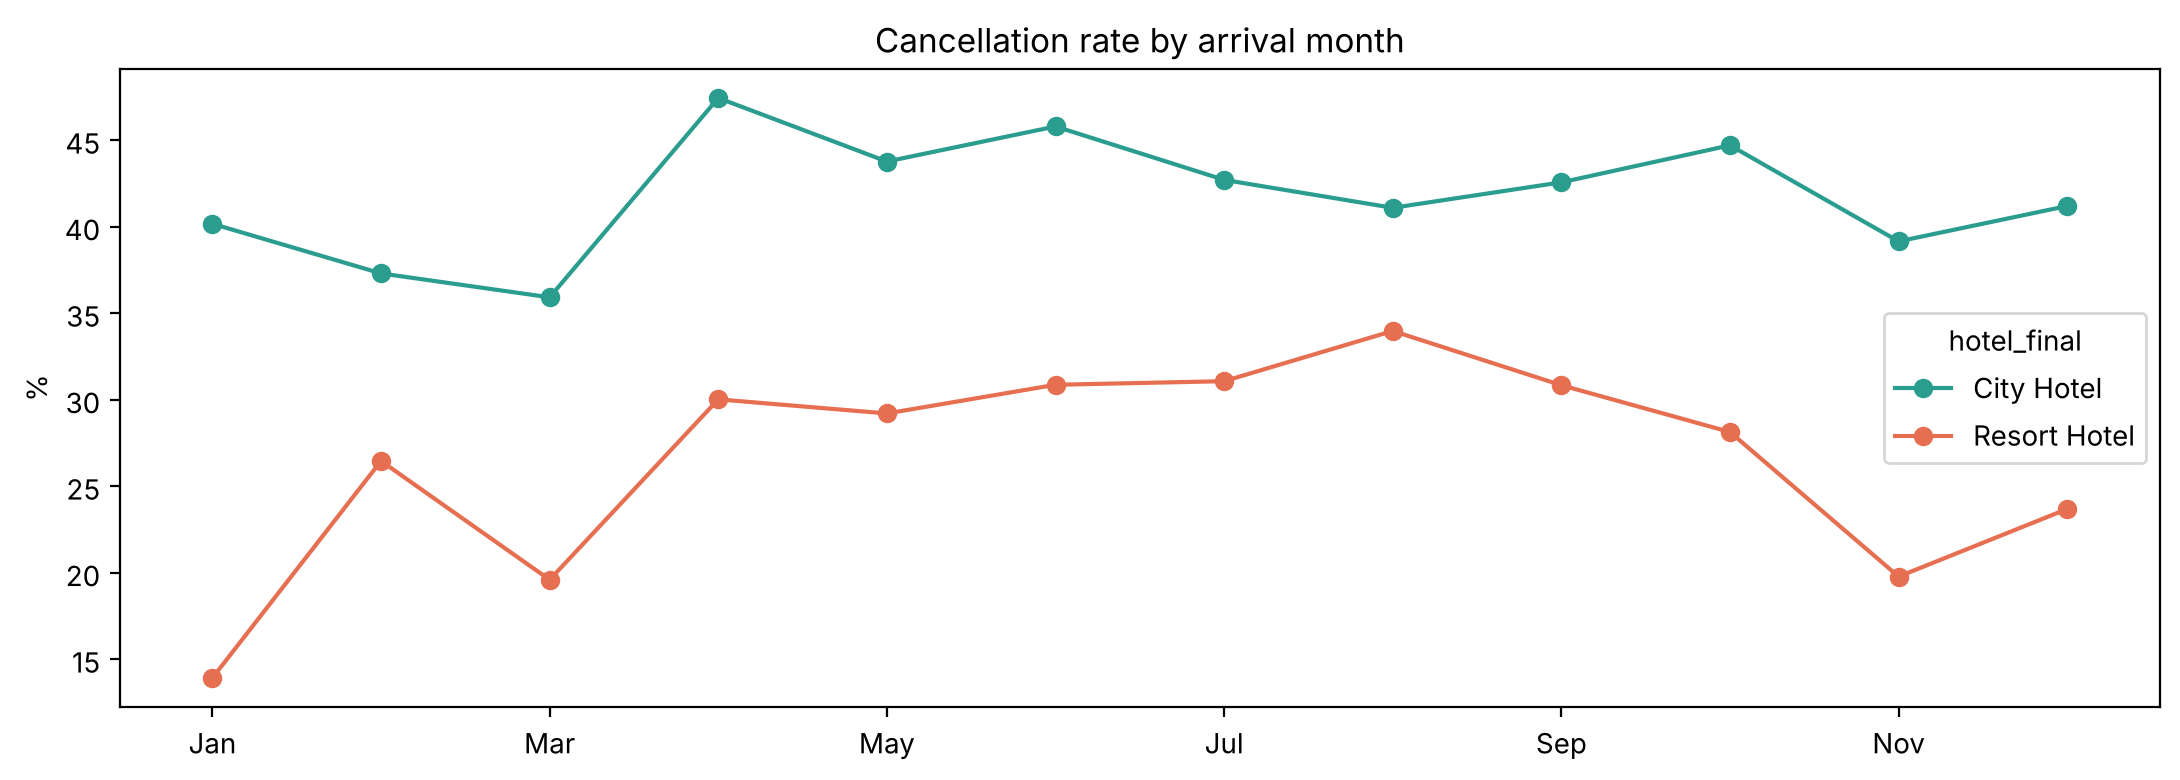

In [264]:
monthly_cancel = valid.groupby(["arrival_month", "hotel_final"])["booking_not_realized_final"].mean().unstack() * 100
monthly_cancel.index = MONTHS

ax = monthly_cancel.plot(figsize=(11, 4), marker="o", color=HOTEL_COLORS)
ax.set_title("Cancellation rate by arrival month")
ax.set_ylabel("%")
plt.tight_layout()
plt.show()

In [265]:
# two more things we noticed while exploring: deposit type and returning guests
deposit = valid.groupby("deposit_type")["booking_not_realized_final"].agg(["count", "mean"])
deposit["mean"] *= 100
display(deposit)

repeat = valid.groupby("is_repeated_guest")["booking_not_realized_final"].agg(["count", "mean"])
repeat["mean"] *= 100
repeat.index = ["New guest", "Returning guest"]
display(repeat)

,count,mean
deposit_type,,
No Deposit,21243,28.84
Non Refund,2924,99.49
Refundable,33,9.09


,count,mean
New guest,23688,38.04
Returning guest,762,14.96


**What the numbers say.** About **37% of all bookings** never turn into a stay. The City Hotel
is much worse than the Resort: around 42% against 27%. The value of the canceled bookings is
about €3.4 million, which is roughly two thirds of the revenue that was actually realized.

By segment, groups cancel the most (over 60%), followed by online and offline agencies; direct
and corporate bookings cancel the least. Among countries, Portugal stands out with more than
half of its bookings canceled, while most foreign markets stay around 20%.

Lead time shows the clearest pattern we found in the whole analysis. Bookings made a week
before arrival are canceled about 10% of the time; bookings made more than a year in advance
almost 70% of the time. The median canceled booking was made 113 days before arrival, against
46 days for a realized stay. Returning guests also cancel much less than new ones (15% vs 38%).

One result looked strange to us: "Non Refund" bookings are canceled in almost 100% of cases,
which is the opposite of what you would expect from a non-refundable rate. Most of them are
group and offline agency bookings, so it's possible that these are blocks of rooms reserved by
tour operators and then released, and that the label doesn't mean the same thing as for a
normal guest. We would ask the hotel before drawing conclusions on this.

**Why it matters.** With more than one booking in three canceled, the hotels plan staff, rooms
and prices on numbers that are not real. The City Hotel in particular loses a lot of value this
way.

**Limitations.** We see an association between lead time and cancellations, not a cause: people
who book early may simply have more time to change their plans. Also, a canceled room may still
have been sold to someone else, so the "lost value" is the maximum possible loss, not the real one.

## 8. Seasonality & Operational Analysis

**Objective.** See how demand changes during the year and what this means for running the hotels.

**Questions.** Which are the busiest and quietest months? Which hotel is more seasonal? How long
do stays last, and how are they split between weekdays and weekends? When is more staff needed,
and when would promotions help?

For the monthly comparison we only use **2016**, because it is the only complete year in the data
(2015 starts in July and 2017 ends in August). We count all scheduled arrivals, including those
that were later canceled, and also look at realized stays only. Without the number of rooms of
each hotel we cannot calculate a real occupancy rate.

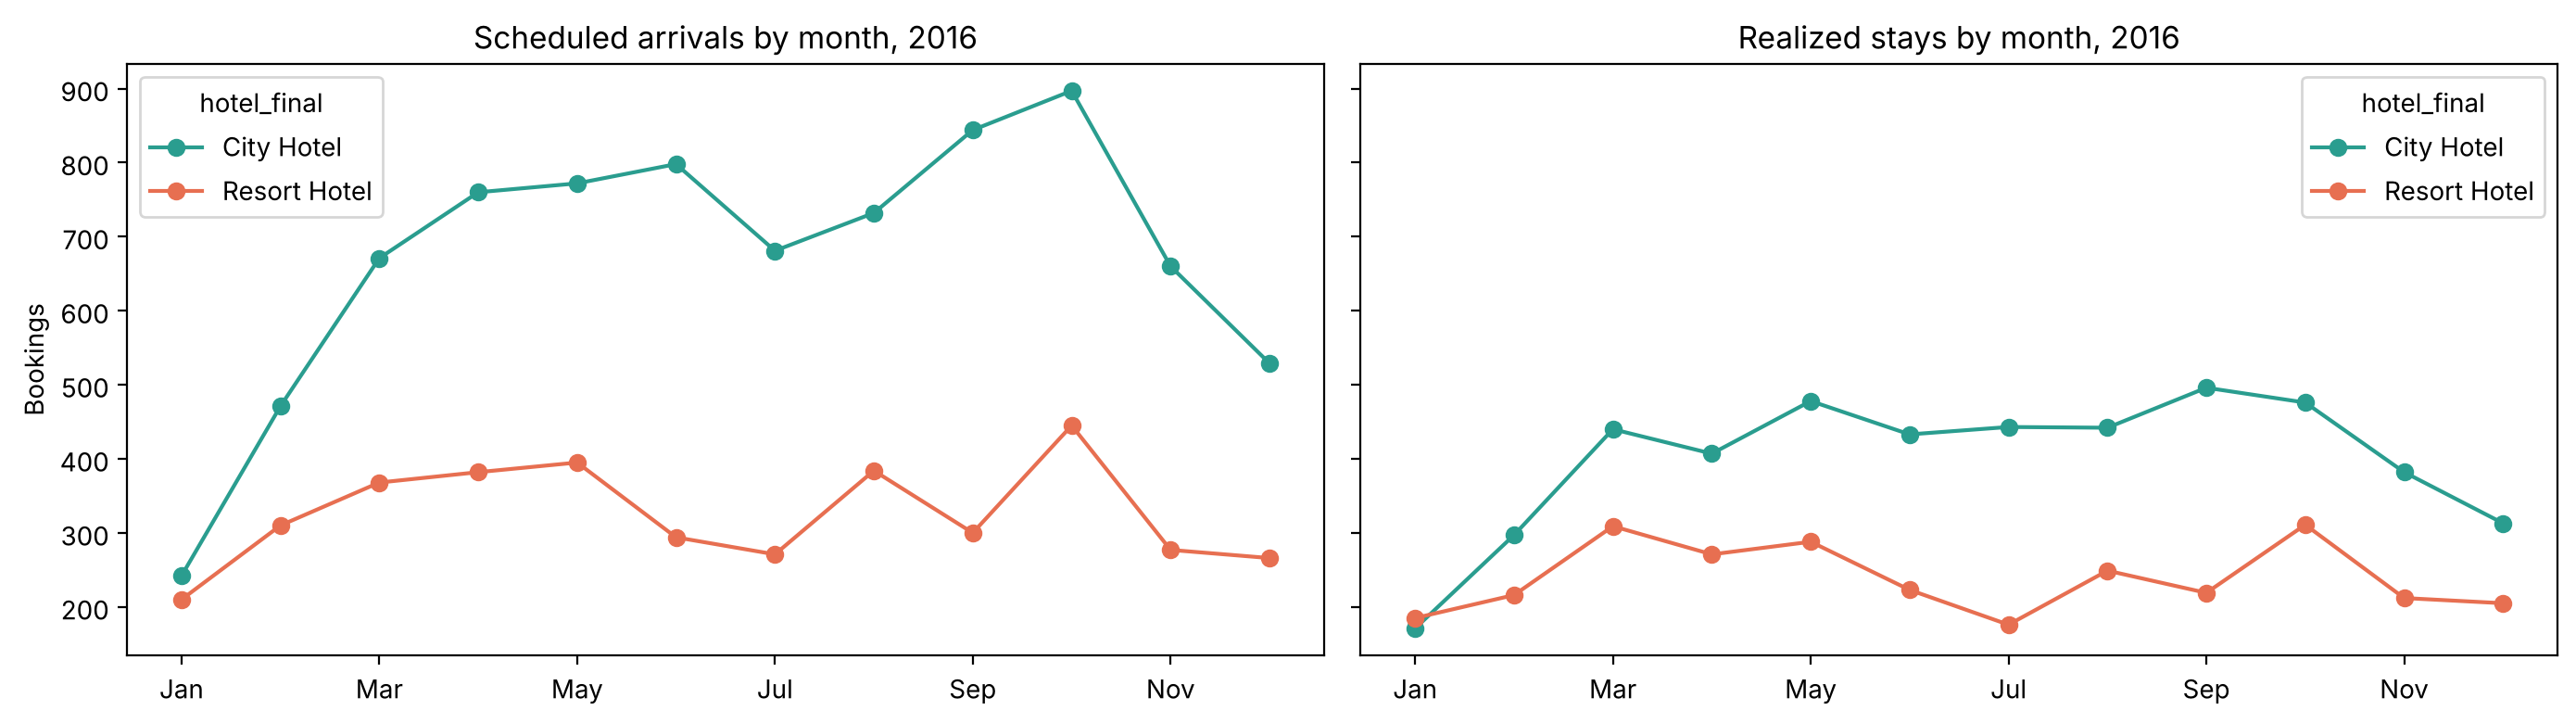

In [266]:
year_2016 = valid[valid["arrival_year"] == 2016]

arrivals_2016 = year_2016.groupby(["arrival_month", "hotel_final"]).size().unstack()
realized_2016 = year_2016[year_2016["booking_not_realized_final"] == 0].groupby(
    ["arrival_month", "hotel_final"]).size().unstack()
arrivals_2016.index = MONTHS
realized_2016.index = MONTHS

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
arrivals_2016.plot(ax=ax[0], marker="o", color=HOTEL_COLORS)
ax[0].set_title("Scheduled arrivals by month, 2016")
ax[0].set_ylabel("Bookings")
realized_2016.plot(ax=ax[1], marker="o", color=HOTEL_COLORS)
ax[1].set_title("Realized stays by month, 2016")
plt.tight_layout()
plt.show()

In [267]:
# how seasonal is each hotel? we compare the best and the worst month of 2016,
# first by number of realized stays and then by estimated revenue
revenue_month_2016 = (year_2016[year_2016["booking_not_realized_final"] == 0]
                      .groupby(["arrival_month", "hotel_final"])["estimated_booking_value"].sum().unstack())
revenue_month_2016.index = MONTHS

seasonality = pd.DataFrame({
    "peak_month_stays": realized_2016.idxmax(),
    "low_month_stays": realized_2016.idxmin(),
    "stays_peak_to_low": realized_2016.max() / realized_2016.min(),
    "peak_month_revenue": revenue_month_2016.idxmax(),
    "low_month_revenue": revenue_month_2016.idxmin(),
    "revenue_peak_to_low": revenue_month_2016.max() / revenue_month_2016.min(),
})
seasonality

,peak_month_stays,low_month_stays,stays_peak_to_low,peak_month_revenue,low_month_revenue,revenue_peak_to_low
hotel_final,,,,,,
City Hotel,Sep,Jan,2.90,Sep,Jan,5.15
Resort Hotel,Oct,Jul,1.77,Aug,Jan,9.95


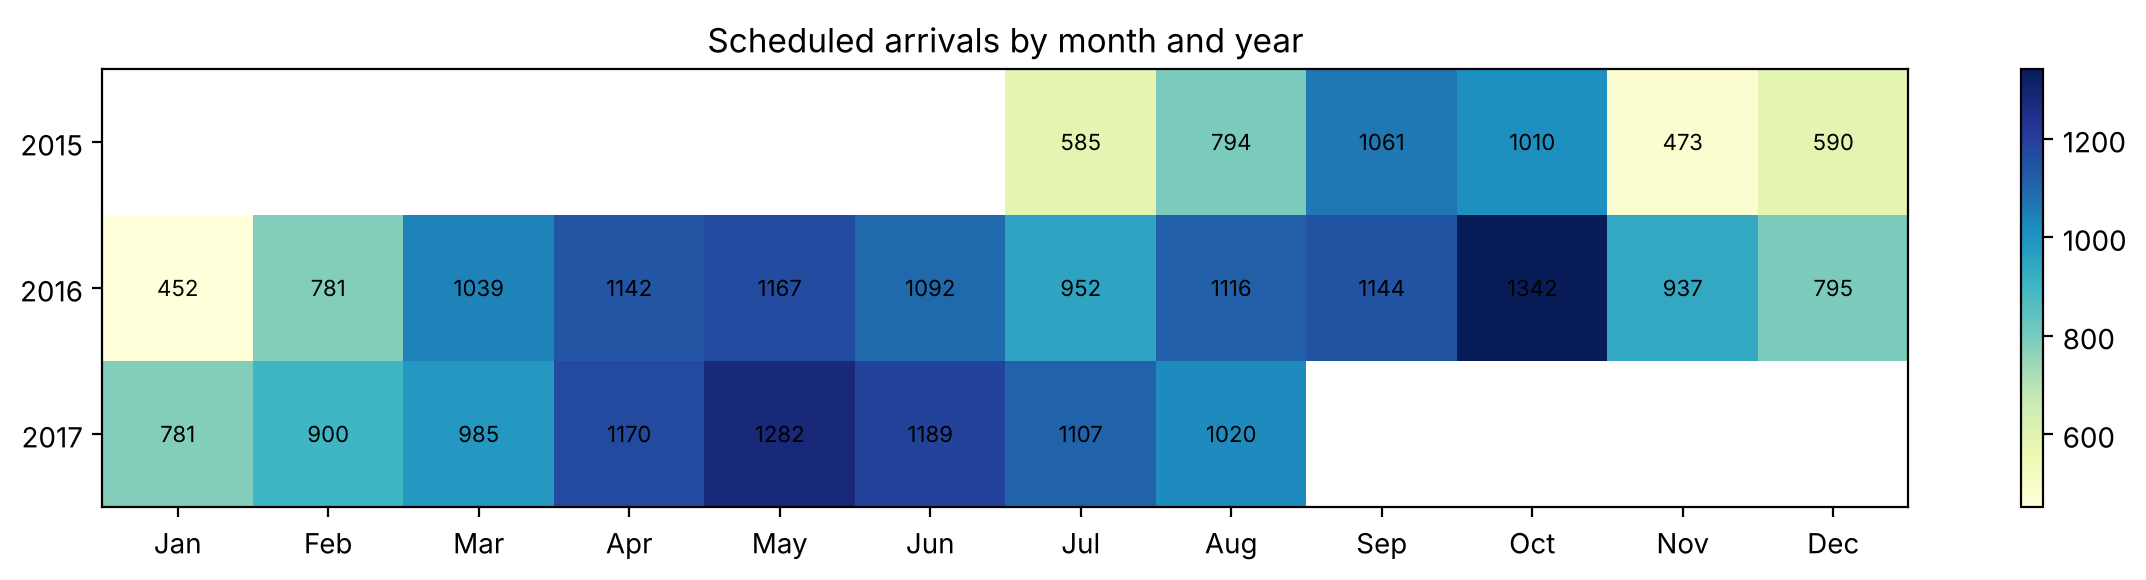

In [268]:
# heatmap: all scheduled arrivals by year and month (empty cells = months not covered by the data)
heat = valid.pivot_table(index="arrival_year", columns="arrival_month", values="booking_id", aggfunc="count")
heat.columns = MONTHS

fig, ax = plt.subplots(figsize=(12, 3))
im = ax.imshow(heat, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(12), MONTHS)
ax.set_yticks(range(len(heat.index)), heat.index.astype(int))
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        if not np.isnan(heat.iloc[i, j]):
            ax.text(j, i, int(heat.iloc[i, j]), ha="center", va="center", fontsize=8)
ax.set_title("Scheduled arrivals by month and year")
plt.colorbar(im)
plt.tight_layout()
plt.show()

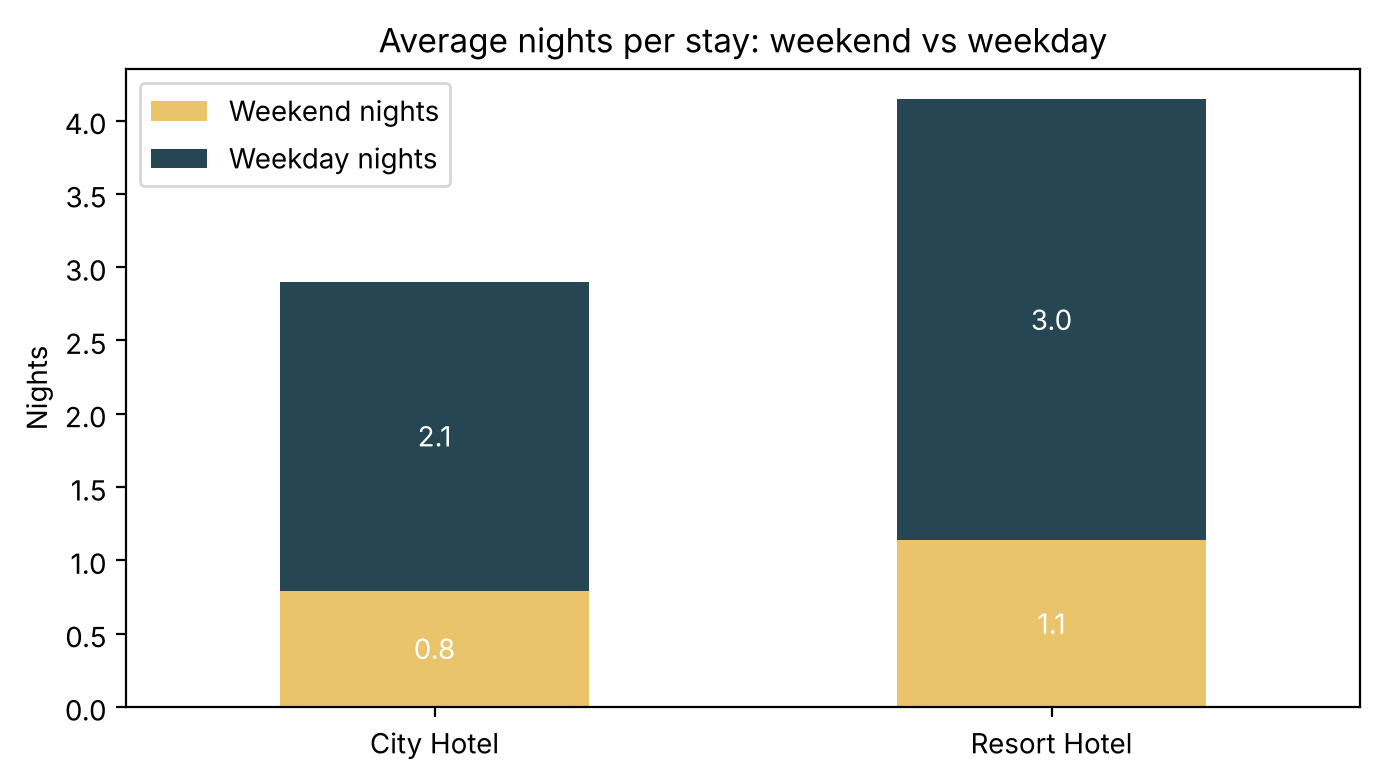

,Weekend nights,Weekday nights
hotel_final,,
City Hotel,0.79,2.11
Resort Hotel,1.14,3.01


In [269]:
stay_split = realized.groupby("hotel_final")[["stays_in_weekend_nights", "stays_in_week_nights"]].mean()
stay_split.columns = ["Weekend nights", "Weekday nights"]

ax = stay_split.plot(kind="bar", stacked=True, figsize=(7, 4), rot=0, color=["#E9C46A", "#264653"])
ax.set_title("Average nights per stay: weekend vs weekday")
ax.set_ylabel("Nights")
ax.set_xlabel("")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", label_type="center", color="white")
plt.tight_layout()
plt.show()
stay_split

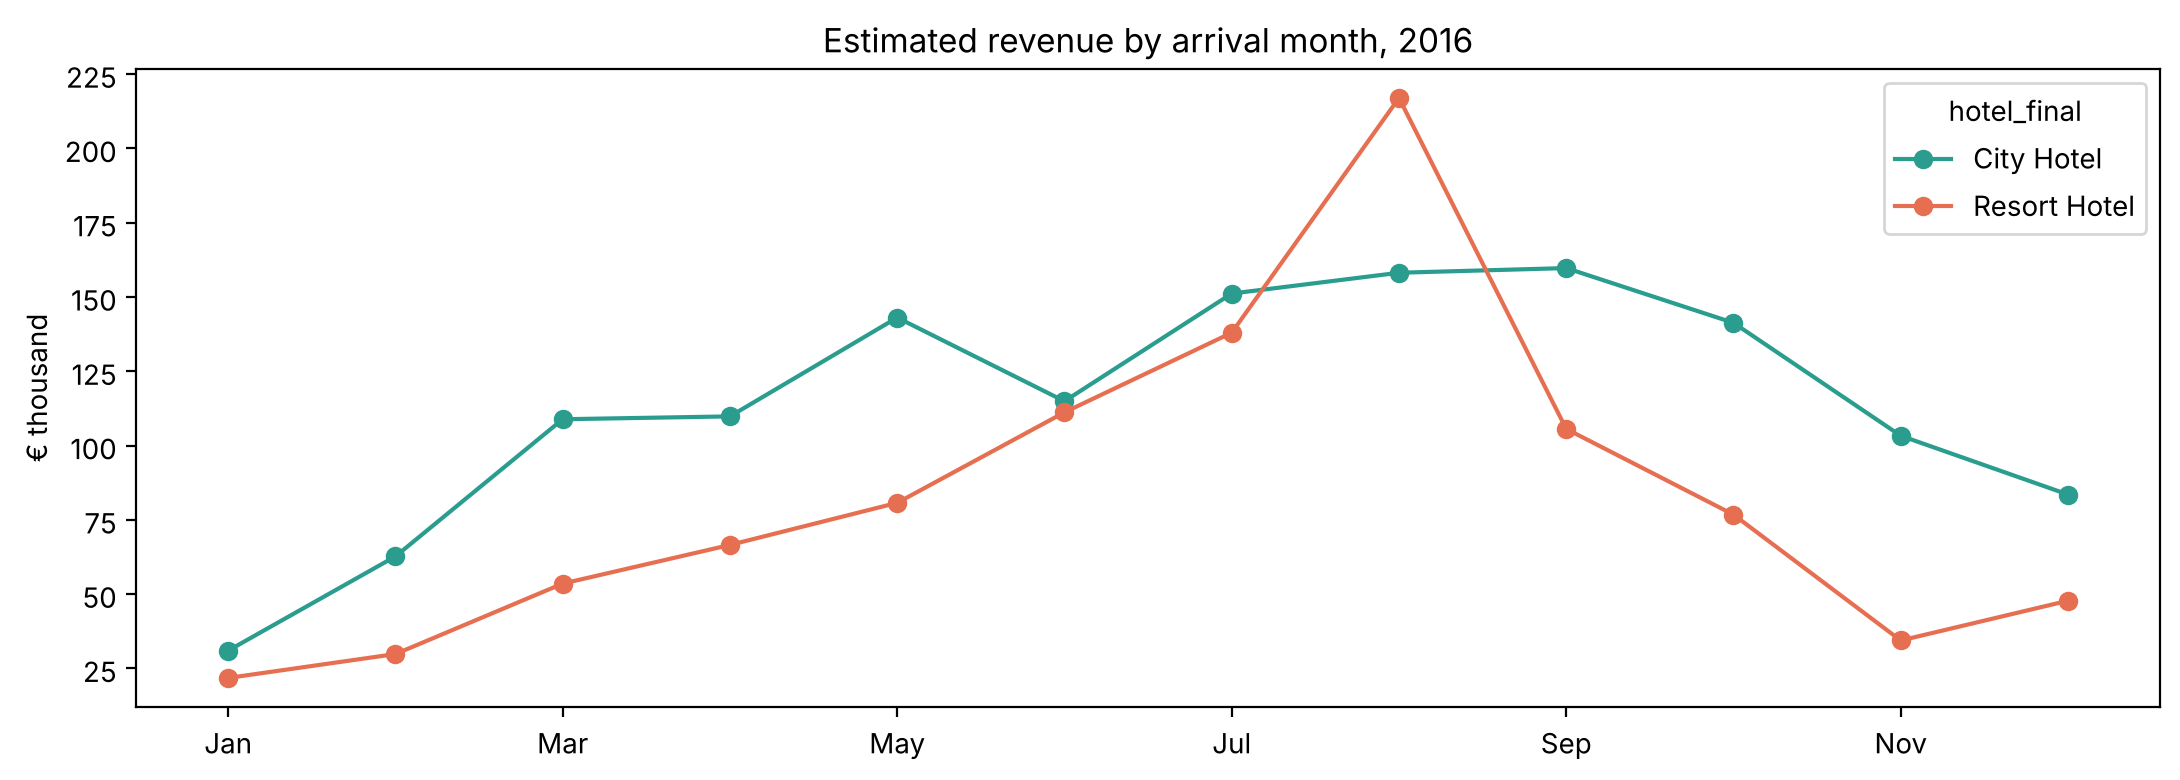

In [270]:
ax = (revenue_month_2016 / 1000).plot(figsize=(11, 4), marker="o", color=HOTEL_COLORS)
ax.set_title("Estimated revenue by arrival month, 2016")
ax.set_ylabel("€ thousand")
plt.tight_layout()
plt.show()

**What the numbers say.** This section gave us a result we didn't expect. Looking only at the
number of stays, the City Hotel is actually the more seasonal one: in 2016 it goes from about 170
realized stays in January to almost 500 in September, a ratio of about 3. The Resort has a much
flatter number of arrivals during the year (roughly 180 to 310 per month), with October and
March among its busiest months, not July.

The Resort's seasonality is in the money, not in the number of guests. Because summer prices are
more than three times the winter ones and summer stays are longer, its revenue goes from around
€22,000 in January to more than €200,000 in August, about ten times as much. For the City Hotel
the same ratio is around five. January is the weakest month for both hotels.

For the City Hotel the gap between scheduled arrivals and realized stays is large in every busy
month, because so many of its bookings are canceled.

Most of a stay falls on weekdays in both hotels. Resort guests stay longer and spend more
nights over the weekend (about 1.1 against 0.8), which fits the idea of a holiday destination,
while the City Hotel looks more like short trips and business stays.

**Why it matters.** For the City Hotel the busy period in terms of guests is spring to autumn,
so that is when it needs more staff. For the Resort the workload is more stable, but almost all
of the money is made in July and August, so pricing in those weeks is critical. November to
February is the weak period for both, and the natural moment for promotions and packages.

**Limitations.** We only have one complete year, so we can't say if the same pattern repeats
every year. And without the number of rooms we can compare demand but not occupancy.

## 9. Final Hotel Performance Comparison

Here we put the main results side by side, so that the two hotels can be compared at a glance.

In [271]:
def main_segment(h):
    return valid.loc[valid["hotel_final"] == h, "market_segment"].value_counts().idxmax()

scorecard = pd.DataFrame({
    h: {
        "Total bookings (known outcome)": (valid["hotel_final"] == h).sum(),
        "Realized stays": (realized["hotel_final"] == h).sum(),
        "Estimated revenue (€)": revenue_by_hotel.loc[h, "estimated_revenue"],
        "Average ADR (€)": adr_by_hotel.loc[h, "mean"],
        "Average booking value (€)": revenue_by_hotel.loc[h, "avg_booking_value"],
        "Cancellation rate (%)": cancel_by_hotel.loc[h, "cancellation_rate"],
        "Value of canceled bookings (€)": cancel_by_hotel.loc[h, "lost_value"],
        "Average length of stay (nights)": customer_profile.loc[h, "avg_nights"],
        "Average guests per booking": customer_profile.loc[h, "avg_guests"],
        "Average lead time (days)": valid.loc[valid["hotel_final"] == h, "lead_time_days"].mean(),
        "Main market segment": main_segment(h),
        "Peak month by stays (2016)": seasonality.loc[h, "peak_month_stays"],
        "Peak month by revenue (2016)": seasonality.loc[h, "peak_month_revenue"],
        "Low month by revenue (2016)": seasonality.loc[h, "low_month_revenue"],
    }
    for h in ["City Hotel", "Resort Hotel"]
})
scorecard

,City Hotel,Resort Hotel
Total bookings (known outcome),16592,8358
Realized stays,9579,6067
Estimated revenue (€),"2,858,855.37","2,320,621.88"
Average ADR (€),108.16,92.08
Average booking value (€),311.80,404.43
Cancellation rate (%),42.27,27.41
Value of canceled bookings (€),"2,240,565.25","1,163,800.96"
Average length of stay (nights),2.90,4.15
Average guests per booking,1.93,1.95
Average lead time (days),109.66,92.09


Neither hotel is simply "better". The **City Hotel** is the bigger business: more bookings, more
total revenue and higher prices in most months of the year. Its weak point is clearly cancellations:
more than four bookings out of ten are lost, and its prices change little across the year.

The **Resort Hotel** brings in less money overall, but each booking is worth more, guests stay
longer and cancel much less. Its weak point is the opposite one: a large part of its revenue is made in
July and August, and in winter its prices fall to around half of the City Hotel's.

In short, the City Hotel should work on keeping the bookings it already gets, the Resort on
filling the months outside summer.

## 10. Business Recommendations

Each recommendation comes from a result of the previous sections and follows the same path:
what we found, why it matters, what we suggest and what the hotel could gain.

**1. Reconfirm bookings made far in advance (Cancellation management)**
- *Finding:* cancellation rate grows from ~10% for last-week bookings to ~70% for bookings made
  more than a year ahead.
- *Implication:* early bookings make the hotel's plans look fuller than they are.
- *Recommendation:* send reminders and ask for a reconfirmation (or a small deposit) a few weeks
  before arrival for bookings with a long lead time.
- *Expected benefit:* cancellations known earlier, so rooms can be sold again in time.

**2. Tighten conditions for group bookings (Cancellation management)**
- *Finding:* groups cancel more than 60% of their bookings and pay one of the lowest ADRs.
- *Implication:* large blocks of rooms are held and then released, often at low prices.
- *Recommendation:* set release dates and minimum guarantees in group contracts, especially at
  the City Hotel where groups weigh more.
- *Expected benefit:* fewer empty rooms and more reliable forecasts.

**3. Push direct bookings (Distribution channels)**
- *Finding:* direct bookings have the highest ADR and one of the lowest cancellation rates, but
  are only ~10% of bookings.
- *Implication:* the hotels depend on online agencies, which charge commissions and cancel more.
- *Recommendation:* offer a "best price on our website" policy, small perks for booking direct,
  and a loyalty offer for returning guests (who cancel 15% vs 38%).
- *Expected benefit:* higher margin per booking and fewer cancellations.

**4. More dynamic pricing at the City Hotel (Pricing)**
- *Finding:* the City Hotel ADR moves between about €85 and €120, while its number of stays
  almost triples from January to September.
- *Implication:* in its busiest months it may be leaving money on the table.
- *Recommendation:* raise prices in high-demand months and when booking pace is strong, as the
  Resort already does in summer.
- *Expected benefit:* higher revenue without extra volume.

**5. Fill the Resort's low season (Seasonality)**
- *Finding:* Resort prices and revenue collapse between November and February (August revenue
  is about ten times January's), even though the number of guests drops much less.
- *Implication:* fixed costs stay the same while revenue drops.
- *Recommendation:* winter packages that raise the value of each stay (longer stays, wellness,
  golf, meals included) and campaigns in northern European markets that already book here.
- *Expected benefit:* more stays in winter and a more stable revenue across the year.

**6. Focus marketing on the most valuable foreign markets (Customer acquisition)**
- *Finding:* UK, France, Germany and Spain bring a larger share of value than of bookings and
  cancel around 20%, while Portugal cancels more than half its bookings.
- *Implication:* not every booking is worth the same.
- *Recommendation:* target campaigns at these markets, and for the domestic market use stricter
  conditions (deposit, reconfirmation).
- *Expected benefit:* better quality of bookings, not just more bookings.

**7. Plan staff on realized demand, not scheduled arrivals (Operations)**
- *Finding:* scheduled arrivals and realized stays differ a lot, especially at the City Hotel.
- *Implication:* planning on bookings alone overestimates the work needed.
- *Recommendation:* use expected stays (bookings × 1 − expected cancellation rate by segment and
  lead time) to plan staff and resources, and scale up for the peak months of each hotel.
- *Expected benefit:* lower costs in quiet periods and enough staff in busy ones.

**8. Improve data quality at the source (Data governance)**
- *Finding:* the two systems use different formats and labels, and the meaning of "Non Refund"
  looks inconsistent with the cancellation data.
- *Implication:* every analysis needs heavy cleaning first, and some results remain uncertain.
- *Recommendation:* use drop-down lists instead of free text, one shared booking ID, a single
  date format and a clear definition of deposit types in both systems.
- *Expected benefit:* faster and more reliable reporting for management.

### How much could these be worth?

To give management an idea of the size of each opportunity, we estimated the value of four of
the recommendations. These are **scenarios, not forecasts**: each one depends on an assumption
that we chose to be cautious, written as a variable at the top of the cell so it can be changed
easily. The values are also maximums, because some canceled rooms may have been sold again.

In [272]:
# assumptions (cautious, can be changed)
LONG_LEAD_REDUCTION = 0.10      # rec 1: 10% fewer cancellations on bookings made 180+ days ahead
GROUP_REDUCTION = 0.25          # rec 2: a quarter fewer group cancellations
SHIFT_TO_DIRECT = 0.05          # rec 3: 5% of online agency stays booked directly instead
OTA_COMMISSION = 0.15           # rec 3: commission paid to online agencies (not in the data, typical value)
CITY_PRICE_INCREASE = 0.05      # rec 4: +5% ADR at the City Hotel in its busy months (Apr-Oct)

# rec 1: value of canceled bookings made more than 180 days ahead
long_lead_lost = canceled.loc[canceled["lead_time_days"] > 180, "estimated_booking_value"].sum()

# rec 2: value of canceled group bookings
group_lost = canceled.loc[canceled["market_segment"] == "Groups", "estimated_booking_value"].sum()

# rec 3: commission saved on online agency stays moved to direct
online_value = realized.loc[realized["market_segment"] == "Online TA", "estimated_booking_value"].sum()

# rec 4: City Hotel revenue in its busy months of 2016 (the only full year)
city_busy = realized[(realized["hotel_final"] == "City Hotel") & (realized["arrival_year"] == 2016)
                     & (realized["arrival_month"].between(4, 10))]["estimated_booking_value"].sum()

impact = pd.DataFrame({
    "Recommendation": ["1. Reconfirm long-lead bookings", "2. Stricter group contracts",
                       "3. Push direct bookings", "4. Dynamic pricing, City Hotel"],
    "Based on": [f"€{long_lead_lost:,.0f} canceled (180+ days ahead)",
                 f"€{group_lost:,.0f} canceled by groups",
                 f"€{online_value:,.0f} of online agency stays",
                 f"€{city_busy:,.0f} City revenue Apr-Oct 2016"],
    "Assumption": [f"{LONG_LEAD_REDUCTION:.0%} fewer cancellations",
                   f"{GROUP_REDUCTION:.0%} fewer cancellations",
                   f"{SHIFT_TO_DIRECT:.0%} moved to direct, {OTA_COMMISSION:.0%} commission",
                   f"+{CITY_PRICE_INCREASE:.0%} ADR"],
    "Estimated value (€)": [long_lead_lost * LONG_LEAD_REDUCTION,
                            group_lost * GROUP_REDUCTION,
                            online_value * SHIFT_TO_DIRECT * OTA_COMMISSION,
                            city_busy * CITY_PRICE_INCREASE],
})
impact["Estimated value (€)"] = impact["Estimated value (€)"].round(-3)
impact

,Recommendation,Based on,Assumption,Estimated value (€)
0,1. Reconfirm long-lead bookings,"€928,345 canceled (180+ days ahead)",10% fewer cancellations,"93,000.00"
1,2. Stricter group contracts,"€563,567 canceled by groups",25% fewer cancellations,"141,000.00"
2,3. Push direct bookings,"€2,665,237 of online agency stays","5% moved to direct, 15% commission","20,000.00"
3,"4. Dynamic pricing, City Hotel","€978,348 City revenue Apr-Oct 2016",+5% ADR,"49,000.00"


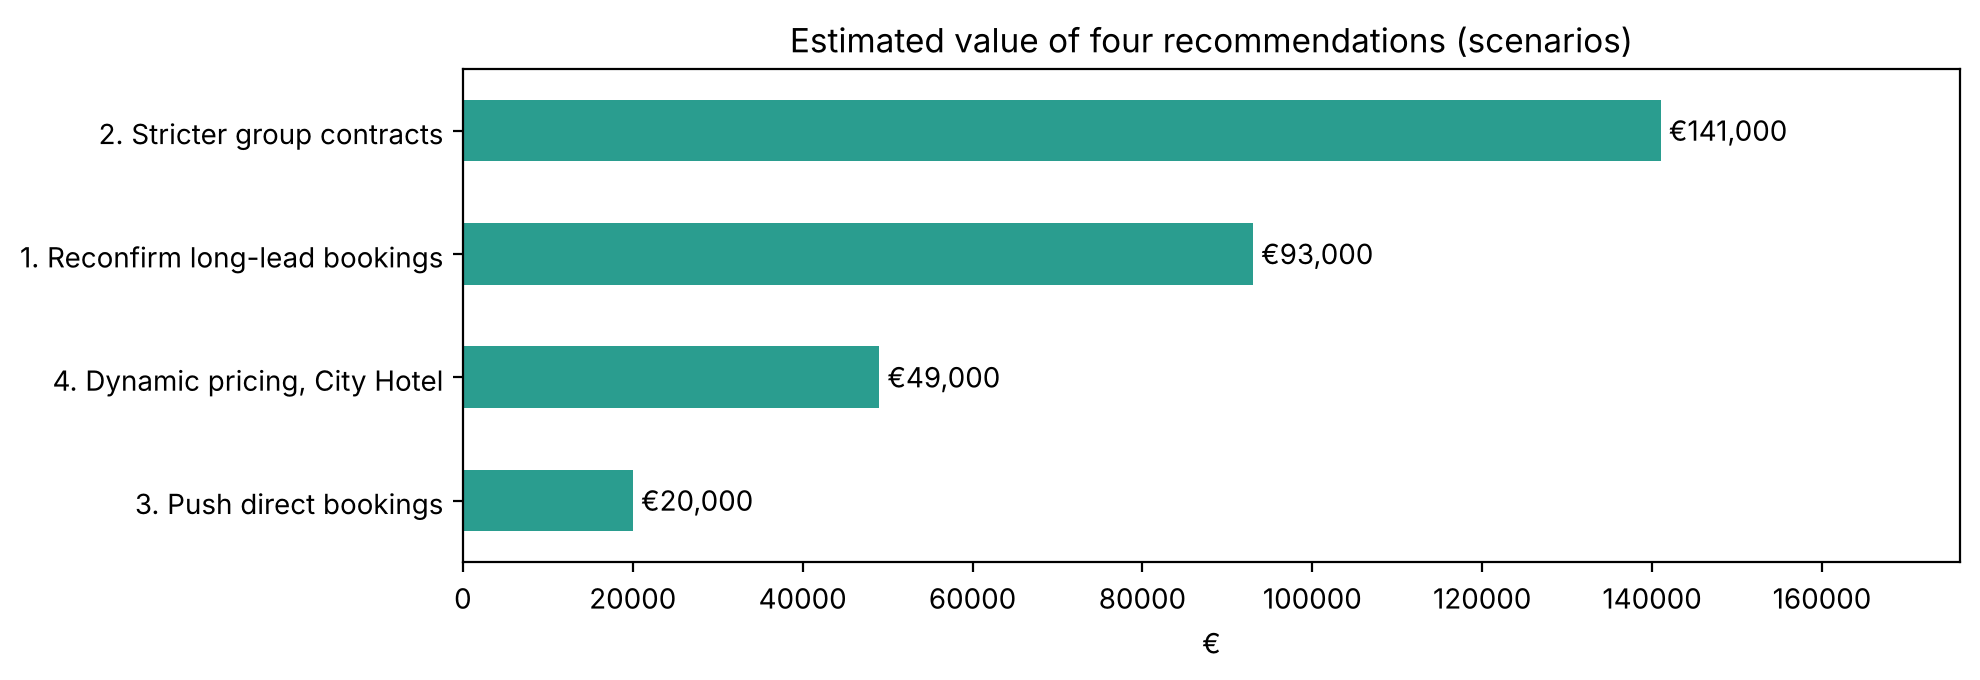

In [273]:
ax = impact.set_index("Recommendation")["Estimated value (€)"].sort_values().plot(
    kind="barh", figsize=(10, 3.5), color="#2A9D8F")
ax.bar_label(ax.containers[0], labels=[f"€{v:,.0f}" for v in ax.containers[0].datavalues], padding=3)
ax.set_title("Estimated value of four recommendations (scenarios)")
ax.set_xlabel("€")
ax.set_ylabel("")
ax.set_xlim(0, impact["Estimated value (€)"].max() * 1.25)
plt.tight_layout()
plt.show()

Even with cautious assumptions, the two cancellation measures are the biggest opportunities
(around €140,000 for groups and €90,000 for long-lead bookings), followed by City Hotel pricing
(about €50,000 a year). Pushing direct bookings is worth less in money, about €20,000 in saved
commissions, but it also brings guests who pay more and cancel less, which this number doesn't
capture. The order of the numbers is more useful than the exact amounts: it tells management
where to start.

## 11. Final Project Conclusion

We started from two exports of the same bookings that could not be used as they were. In the
PMS we found duplicate and multiple versions of the same booking, hotel names and months written
in dozens of ways, prices stored as text, negative prices and prices 100 times too high. The CRM
had empty rows, duplicates, three date formats, decimal commas, placeholder values like 9999 for
lead time and many spellings of the same segment or status.

After cleaning each file, we merged them with a full outer join to keep every booking: 23,750
were found in both systems, 500 only in the PMS and 750 only in the CRM, for a total of 25,000
unique bookings. Where the two systems overlapped they agreed in almost every case, and we used
one to fill the gaps of the other. The few conflicts we could not solve (168 bookings, less than
1%) were kept and flagged instead of being guessed.

Putting the two systems together is what made the business analysis possible: prices and stays
come from the PMS, while who the guest is and how they booked come from the CRM. Neither file on
its own could have answered questions like "which market segment cancels more" or "how much value
does each country bring".

The main business findings are three. First, the two hotels work differently: the City Hotel on
volume, the Resort on value per stay, with most of its revenue made in summer. Second, cancellations are the biggest
problem, with 37% of bookings never turning into a stay, and they are strongly linked to lead
time, groups and the domestic market. Third, direct bookings and returning guests are the most
valuable and reliable customers, but they are a small share of the business.

Our recommendations focus on reducing cancellations, growing direct bookings, using prices more
dynamically at the City Hotel and filling the Resort's winter months.

Some limitations remain. Revenue is an estimate (ADR × nights), not real accounting data; we
have no customer ID, no room capacity and no information on commissions or costs; only 2016 is a
complete year; and a few values (like "CN" as a country or the meaning of "Non Refund") would
need to be confirmed with the hotels before taking decisions on them.